In [105]:
# lancer dans environnement pyroot
import os
import sys
import ctypes
from datetime import datetime

ROOT_LIB = "/home/luc1010lucas/Thesis/opt/root/lib"
backend = f"{ROOT_LIB}/libcppyy_backend.so"

if os.path.exists(backend):
    os.environ["CPPYY_BACKEND_LIBRARY"] = backend

# Ensure Python can find the ROOT package directory.
if ROOT_LIB not in sys.path:
    sys.path.insert(0, ROOT_LIB)

# In a Jupyter kernel, LD_LIBRARY_PATH changes may not be fully honored.
# Preload key ROOT libraries with absolute paths so PyROOT can resolve deps.
for lib in ["libCore.so", "libThread.so", "libRIO.so", "libCling.so", "libTree.so"]:
    ctypes.CDLL(f"{ROOT_LIB}/{lib}", mode=ctypes.RTLD_GLOBAL)

import ROOT
print("ROOT version:", ROOT.gROOT.GetVersion())
import matplotlib.pyplot as plt
import numpy as np

from ROOT import TCanvas, TColor, TGaxis, TH1F, TPad
from ROOT import kBlack, kBlue, kRed
plt.rcdefaults()

from statistics import mean

# Matplotlib compatibility patch for this Ubuntu package build
import matplotlib
if not hasattr(matplotlib.RcParams, "_get"):
    matplotlib.RcParams._get = matplotlib.RcParams.get

# Save figures automatically when plt.show() is called.
_SAVE_FIG_DIR = os.path.join(os.getcwd(), "figs")
os.makedirs(_SAVE_FIG_DIR, exist_ok=True)
save_figure = True  # Set to True to enable saving figures
_saved_figures = set()
_show_call_index = 0

if not hasattr(plt, "_original_show_for_autosave"):
    plt._original_show_for_autosave = plt.show

_original_plt_show = plt._original_show_for_autosave

def _save_open_figures():
    global _show_call_index

    saved_paths = []
    _show_call_index += 1

    for figure_num in plt.get_fignums():
        figure = plt.figure(figure_num)
        filename = f"figure_{_show_call_index:04d}_fig{figure_num}.pdf"
        path = os.path.join(_SAVE_FIG_DIR, filename)
        figure.savefig(path, bbox_inches="tight")
        _saved_figures.add(path)
        saved_paths.append(path)
        print(f"Saved figure to {path}")

    return saved_paths


def show_and_save_figures(*args, **kwargs):
    if save_figure:
        _save_open_figures()
    return _original_plt_show(*args, **kwargs)


plt.show = show_and_save_figures

ROOT version: 6.36.12


In [106]:
# Default canvas layout used by the fit-summary canvases below.
cols = 3
rows = 2
# Modules names
# In the burn-in it is:
#OG0: 2S_6_18_KIT-10016
#OG1: 2S_6_18_KIT-10017
#OG2: 2S_6_18_KIT-10018
#OG3: 2S_6_18_KIT-10019
#OG4: 2S_6_18_KIT-10020


In [107]:
#STUDY OF CBC-LEVEL of hybrid L of of 2S modules(8CBCs x 254 channels)

In [108]:
# CBC-Level Common Mode Noise Analysis (40 CBCs across Board_0)

import numpy as np
import pandas as pd
from scipy import stats

# Define the 5 hybrids on Board_0, one per optical group NO SENSE TO COMPARE CBCs FROM 5 DIFFERENT MODULES ????
hybrids_config = [
    ("OpticalGroup_0", "Hybrid_1", 1),
    ("OpticalGroup_1", "Hybrid_3", 3),
    ("OpticalGroup_2", "Hybrid_5", 5),
    ("OpticalGroup_3", "Hybrid_7", 7),
    ("OpticalGroup_4", "Hybrid_9", 9),
]

root_file = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root", "READ")
cbc_data = {}
cbc_rows = []

print("\n" + "=" * 80)
print("EXTRACTING CBC-LEVEL COMMON MODE NOISE DATA")
print("=" * 80)

# Extract CBC histograms from each hybrid
for og_name, hybrid_name, hybrid_id in hybrids_config:
    base_path = f"Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/{og_name}/{hybrid_name}"
    hybrid_dir = root_file.Get(base_path)
    
    if not hybrid_dir:
        print(f"\n[SKIP] Could not find: {base_path}")
        continue
    
    print(f"\n{og_name} / {hybrid_name}:")
    
    # List CBC directories/objects
    keys = hybrid_dir.GetListOfKeys()
    cbc_count = 0
    
    for i in range(keys.GetSize()):
        key = keys.At(i)
        obj_name = key.GetName()
        obj_class = key.GetClassName()
        
        # Look for CBC directories (should be TDirectoryFile)
        if 'CBC' in obj_name:
            cbc_obj = hybrid_dir.Get(obj_name)
            cbc_idx = None
            
            # Extract CBC index from name (e.g., "CBC_0" → 0)
            try:
                cbc_idx = int(obj_name.split('_')[1])
            except:
                try:
                    cbc_idx = int(obj_name[-1])
                except:
                    pass
            
            if cbc_idx is not None:
                # If it's a directory, look inside for histograms
                if hasattr(cbc_obj, 'GetListOfKeys'):
                    cbc_keys = cbc_obj.GetListOfKeys()
                    for j in range(cbc_keys.GetSize()):
                        sub_key = cbc_keys.At(j)
                        sub_name = sub_key.GetName()
                        sub_class = sub_key.GetClassName()
                        
                        # Look for CommonNoise histogram
                        if 'CommonNoise' in sub_name and 'TH1' in sub_class:
                            hist = cbc_obj.Get(sub_name)
                            if isinstance(hist, ROOT.TH1F):
                                cbc_data[(og_name, hybrid_id, cbc_idx)] = {
                                    "mean": float(hist.GetMean()),
                                    "rms": float(hist.GetRMS()),
                                    "entries": int(hist.GetEntries()),
                                    "histogram": hist,
                                }
                                cbc_rows.append({
                                    "OpticalGroup": og_name,
                                    "Hybrid": hybrid_id,
                                    "CBC": cbc_idx,
                                    "Mean": float(hist.GetMean()),
                                    "RMS": float(hist.GetRMS()),
                                    "Entries": int(hist.GetEntries()),
                                })
                                cbc_count += 1
                                print(f"  ✓ CBC_{cbc_idx}: {sub_name}")
                                break
                else:
                    # Try to get it directly as a histogram
                    if isinstance(cbc_obj, ROOT.TH1F):
                        cbc_data[(og_name, hybrid_id, cbc_idx)] = {
                            "mean": float(cbc_obj.GetMean()),
                            "rms": float(cbc_obj.GetRMS()),
                            "entries": int(cbc_obj.GetEntries()),
                            "histogram": cbc_obj,
                        }
                        cbc_rows.append({
                            "OpticalGroup": og_name,
                            "Hybrid": hybrid_id,
                            "CBC": cbc_idx,
                            "Mean": float(cbc_obj.GetMean()),
                            "RMS": float(cbc_obj.GetRMS()),
                            "Entries": int(cbc_obj.GetEntries()),
                        })
                        cbc_count += 1
                        print(f"  ✓ CBC_{cbc_idx}")
    
    print(f"  → Found {cbc_count} CBC histograms")

print(f"\n" + "=" * 80)
print(f"SUMMARY: Extracted {len(cbc_data)} CBC histograms")
print("=" * 80)

if len(cbc_data) > 0:
    df_cbc = pd.DataFrame(cbc_rows)
    print(f"\nCBC Statistics by Optical Group:")
    cbc_summary = df_cbc.groupby("OpticalGroup")[["Mean", "RMS"]].agg(['count', 'mean', 'std', 'min', 'max'])
    print(cbc_summary.round(4))
    
    print(f"\n\nOverall CBC Statistics (all {len(df_cbc)} CBCs):")
    print(f"  Mean noise:     {df_cbc['Mean'].mean():.6f} ± {df_cbc['Mean'].std():.6f}")
    print(f"  RMS noise:      {df_cbc['RMS'].mean():.6f} ± {df_cbc['RMS'].std():.6f}")
    print(f"  Min/Max Mean:   {df_cbc['Mean'].min():.6f} / {df_cbc['Mean'].max():.6f}")
    print(f"  Min/Max RMS:    {df_cbc['RMS'].min():.6f} / {df_cbc['RMS'].max():.6f}")
    print(f"\n  Noisiest CBC:   {df_cbc.loc[df_cbc['Mean'].idxmax(), 'OpticalGroup']} Hybrid_{int(df_cbc.loc[df_cbc['Mean'].idxmax(), 'Hybrid'])} CBC_{int(df_cbc.loc[df_cbc['Mean'].idxmax(), 'CBC'])} (Mean={df_cbc['Mean'].max():.4f})")
    print(f"  Cleanest CBC:   {df_cbc.loc[df_cbc['Mean'].idxmin(), 'OpticalGroup']} Hybrid_{int(df_cbc.loc[df_cbc['Mean'].idxmin(), 'Hybrid'])} CBC_{int(df_cbc.loc[df_cbc['Mean'].idxmin(), 'CBC'])} (Mean={df_cbc['Mean'].min():.4f})")
    
    print("\nPer-hybrid CBC breakdown (mean and RMS for each CBC):")
    cbc_detail = (
        df_cbc.sort_values(["Hybrid", "CBC"])
        .loc[:, ["OpticalGroup", "Hybrid", "CBC", "Mean", "RMS", "Entries"]]
    )
    for hybrid_id in sorted(df_cbc["Hybrid"].unique()):
        hybrid_df = cbc_detail[cbc_detail["Hybrid"] == hybrid_id]
        print(f"\nHybrid_{hybrid_id}:")
        print(hybrid_df.to_string(index=False, formatters={
            "Mean": "{:.6f}".format,
            "RMS": "{:.6f}".format,
        }))
else:
    print("\n[WARNING] No CBC data extracted. Root file structure may differ.")
    df_cbc = None

print("=" * 80)



EXTRACTING CBC-LEVEL COMMON MODE NOISE DATA

OpticalGroup_0 / Hybrid_1:
  ✓ CBC_0: D_B(0)_O(0)_H(1)_CommonNoiseHits_OccupancyDriven_Chip(0)
  ✓ CBC_1: D_B(0)_O(0)_H(1)_CommonNoiseHits_OccupancyDriven_Chip(1)
  ✓ CBC_2: D_B(0)_O(0)_H(1)_CommonNoiseHits_OccupancyDriven_Chip(2)
  ✓ CBC_3: D_B(0)_O(0)_H(1)_CommonNoiseHits_OccupancyDriven_Chip(3)
  ✓ CBC_4: D_B(0)_O(0)_H(1)_CommonNoiseHits_OccupancyDriven_Chip(4)
  ✓ CBC_5: D_B(0)_O(0)_H(1)_CommonNoiseHits_OccupancyDriven_Chip(5)
  ✓ CBC_6: D_B(0)_O(0)_H(1)_CommonNoiseHits_OccupancyDriven_Chip(6)
  ✓ CBC_7: D_B(0)_O(0)_H(1)_CommonNoiseHits_OccupancyDriven_Chip(7)
  → Found 8 CBC histograms

OpticalGroup_1 / Hybrid_3:
  ✓ CBC_0: D_B(0)_O(1)_H(3)_CommonNoiseHits_OccupancyDriven_Chip(0)
  ✓ CBC_1: D_B(0)_O(1)_H(3)_CommonNoiseHits_OccupancyDriven_Chip(1)
  ✓ CBC_2: D_B(0)_O(1)_H(3)_CommonNoiseHits_OccupancyDriven_Chip(2)
  ✓ CBC_3: D_B(0)_O(1)_H(3)_CommonNoiseHits_OccupancyDriven_Chip(3)
  ✓ CBC_4: D_B(0)_O(1)_H(3)_CommonNoiseHits_OccupancyDri

In [109]:
# CBCs of hybrid L of module 0 and 3 are the nosiest 
# CBCs of hybrid L of all modules are getting more quiet from CBCs 0 to 7, which could indicate a common noise pattern across the CBCs, potentially related to the design or operation of the CBCs themselves. This trend suggests that certain CBCs (e.g., CBC_0) may be more susceptible to noise, while others (e.g., CBC_7) are more stable. Further investigation into the specific characteristics of each CBC and their associated electronics could help identify the root cause of this noise pattern and inform potential mitigation strategies. 


/tmp/ipykernel_3937/1906759897.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax2.boxplot(box_data_cbc, labels=cbc_labels_box, patch_artist=True)


Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0001_fig1.pdf


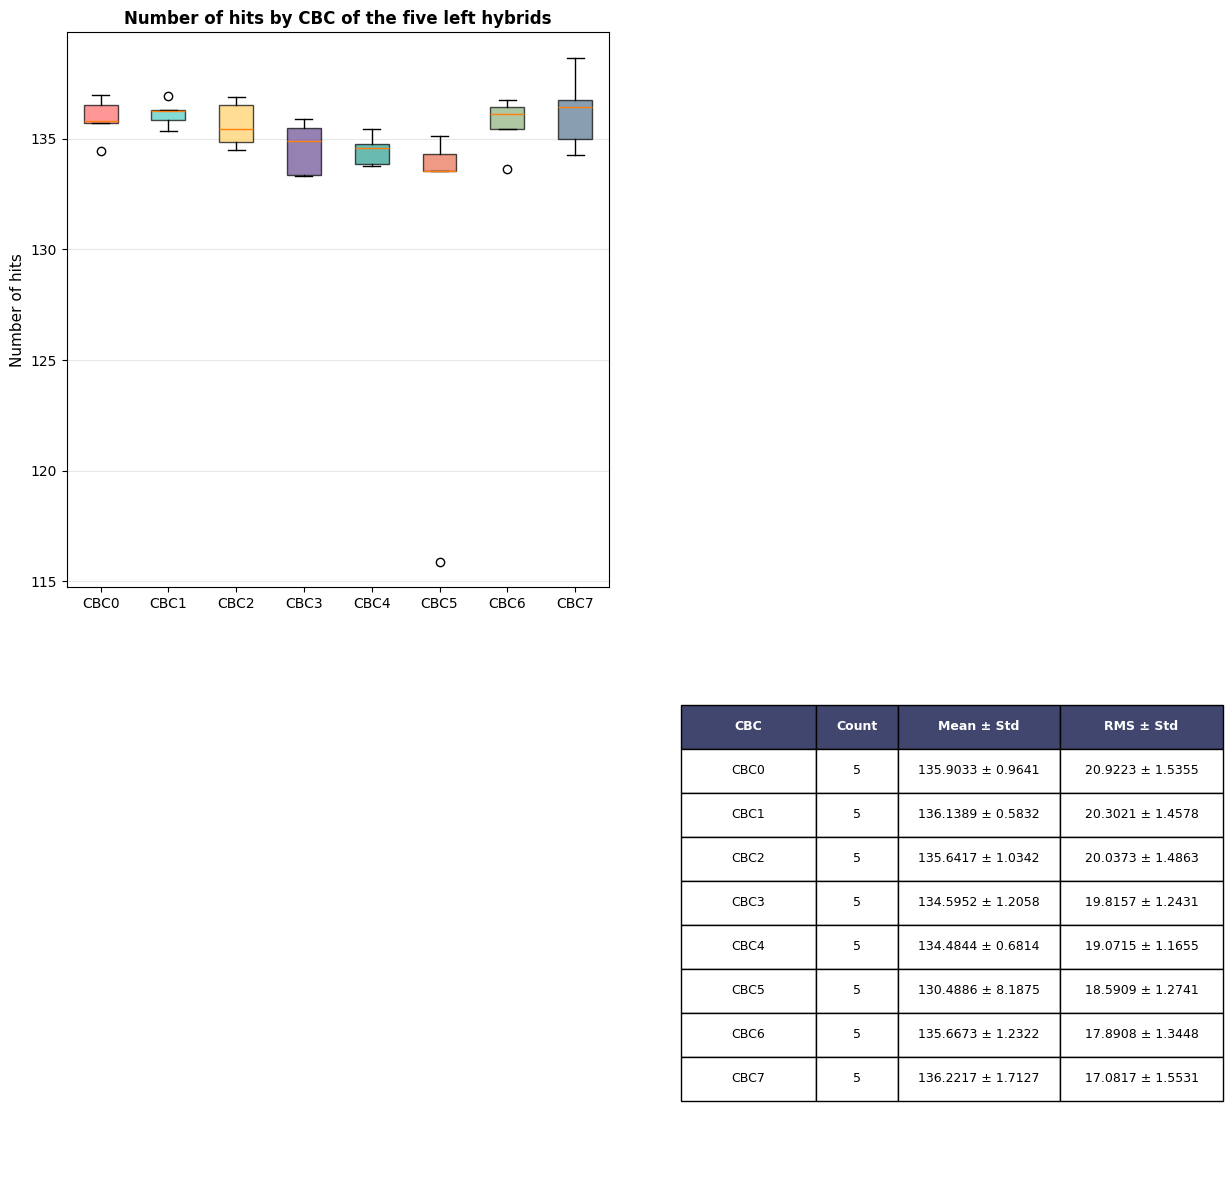

In [110]:
# CBC-Level Visualizations and Statistical Analysis

if df_cbc is not None and len(df_cbc) > 0:
    fig = plt.figure(figsize=(18, 12))
    
    # Plot 2: Number of hits per CBC (box plot)
    ax2 = plt.subplot(2, 3, 2)
    cbc_list = sorted(df_cbc['CBC'].unique())
    box_data_cbc = [df_cbc[df_cbc['CBC'] == cbc]['Mean'].values for cbc in cbc_list]
    cbc_labels_box = [f'CBC{cbc}' for cbc in cbc_list]
    
    bp = ax2.boxplot(box_data_cbc, labels=cbc_labels_box, patch_artist=True)
    colors_palette = ['#FF6B6B', '#4ECDC4', '#FFD166', '#6A4C93', '#2A9D8F', '#E76F51', '#8AB17D', '#577590']
    for patch, color in zip(bp['boxes'], colors_palette):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    ax2.set_ylabel('Number of hits', fontsize=11)
    ax2.set_title('Number of hits by CBC of the five left hybrids', fontsize=12, fontweight='bold')
    ax2.grid(axis='y', alpha=0.3)
    
    # Plot 6: Statistics Table
    ax6 = plt.subplot(2, 3, 6)
    ax6.axis('off')
    
    table_data = [['CBC', 'Count', 'Mean ± Std', 'RMS ± Std']]
    for cbc in cbc_list:
        cbc_data = df_cbc[df_cbc['CBC'] == cbc]
        table_data.append([
            f'CBC{cbc}',
            str(len(cbc_data)),
            f"{cbc_data['Mean'].mean():.4f} ± {cbc_data['Mean'].std():.4f}",
            f"{cbc_data['RMS'].mean():.4f} ± {cbc_data['RMS'].std():.4f}"
        ])
    
    table = ax6.table(cellText=table_data, cellLoc='center', loc='center', colWidths=[0.25, 0.15, 0.30, 0.30])
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1, 2)
    
    for i in range(len(table_data[0])):
        table[(0, i)].set_facecolor('#40466e')
        table[(0, i)].set_text_props(weight='bold', color='white')
    
    plt.tight_layout()
    plt.show()

In [111]:
# CBCs near the center of the hybrid have less hit than those towards the edges, which could suggest a common noise source affecting the peripherical CBCs more strongly. This pattern may indicate that the noise is related to the physical layout of the CBCs on the hybrid, such as shared power lines, grounding issues, or electromagnetic interference that is more pronounced in the central region. Further investigation into the specific design and electronics of the CBCs, as well as potential environmental factors, could help identify the root cause of this noise pattern and inform strategies for mitigation.

In [112]:
# outlier cbc 2 : o4_h9_cbc_2 
# outlier cbc 4 : o3_h7_cbc_4


# occupancy not CM noise

In [113]:
#Study of gamma of cbs of hybrid L of 2S modules (8CBCs x 254 channels)

In [114]:
# Recompute Gamma (Eq.19/20) and common-mode noise for hybrids 0,2,4,6,8
import math
import numpy as np
import pandas as pd
import ROOT

root_file = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root", "READ")

cbc_specs = [
    ("OpticalGroup_0", "Hybrid_1", "CBC_0", 1, 0),
    ("OpticalGroup_0", "Hybrid_1", "CBC_1", 1, 1),
    ("OpticalGroup_0", "Hybrid_1", "CBC_2", 1, 2),
    ("OpticalGroup_0", "Hybrid_1", "CBC_3", 1, 3),
    ("OpticalGroup_0", "Hybrid_1", "CBC_4", 1, 4),
    ("OpticalGroup_0", "Hybrid_1", "CBC_5", 1, 5),
    ("OpticalGroup_0", "Hybrid_1", "CBC_6", 1, 6),
    ("OpticalGroup_0", "Hybrid_1", "CBC_7", 1, 7),

    ("OpticalGroup_1", "Hybrid_3", "CBC_0", 3, 0),
    ("OpticalGroup_1", "Hybrid_3", "CBC_1", 3, 1),
    ("OpticalGroup_1", "Hybrid_3", "CBC_2", 3, 2),
    ("OpticalGroup_1", "Hybrid_3", "CBC_3", 3, 3),
    ("OpticalGroup_1", "Hybrid_3", "CBC_4", 3, 4),
    ("OpticalGroup_1", "Hybrid_3", "CBC_5", 3, 5),
    ("OpticalGroup_1", "Hybrid_3", "CBC_6", 3, 6),
    ("OpticalGroup_1", "Hybrid_3", "CBC_7", 3, 7),

    ("OpticalGroup_2", "Hybrid_5", "CBC_0", 5, 0),
    ("OpticalGroup_2", "Hybrid_5", "CBC_1", 5, 1),
    ("OpticalGroup_2", "Hybrid_5", "CBC_2", 5, 2),
    ("OpticalGroup_2", "Hybrid_5", "CBC_3", 5, 3),
    ("OpticalGroup_2", "Hybrid_5", "CBC_4", 5, 4),
    ("OpticalGroup_2", "Hybrid_5", "CBC_5", 5, 5),
    ("OpticalGroup_2", "Hybrid_5", "CBC_6", 5, 6),
    ("OpticalGroup_2", "Hybrid_5", "CBC_7", 5, 7),

    ("OpticalGroup_3", "Hybrid_7", "CBC_0", 7, 0),
    ("OpticalGroup_3", "Hybrid_7", "CBC_1", 7, 1),
    ("OpticalGroup_3", "Hybrid_7", "CBC_2", 7, 2),
    ("OpticalGroup_3", "Hybrid_7", "CBC_3", 7, 3),
    ("OpticalGroup_3", "Hybrid_7", "CBC_4", 7, 4),
    ("OpticalGroup_3", "Hybrid_7", "CBC_5", 7, 5),
    ("OpticalGroup_3", "Hybrid_7", "CBC_6", 7, 6),
    ("OpticalGroup_3", "Hybrid_7", "CBC_7", 7, 7),

    ("OpticalGroup_4", "Hybrid_9", "CBC_0", 9, 0),
    ("OpticalGroup_4", "Hybrid_9", "CBC_1", 9, 1),
    ("OpticalGroup_4", "Hybrid_9", "CBC_2", 9, 2),
    ("OpticalGroup_4", "Hybrid_9", "CBC_3", 9, 3),
    ("OpticalGroup_4", "Hybrid_9", "CBC_4", 9, 4),
    ("OpticalGroup_4", "Hybrid_9", "CBC_5", 9, 5),
    ("OpticalGroup_4", "Hybrid_9", "CBC_6", 9, 6),
    ("OpticalGroup_4", "Hybrid_9", "CBC_7", 9, 7),
]

def compute_gamma(hist):
    n_channels = int(hist.GetNbinsX() - 1)
    mean_hits = float(hist.GetMean())
    variance_hits = float(hist.GetRMS()) ** 2
    alpha_tilde = 2.0 * math.pi * (variance_hits - mean_hits * (1.0 - mean_hits / n_channels)) / (n_channels * (n_channels - 1))
    sin_alpha = math.sin(alpha_tilde)
    gamma_sq = sin_alpha / (1.0 - sin_alpha) if (1.0 - sin_alpha) != 0 else 0.0
    gamma = math.sqrt(max(gamma_sq, 0.0))
    return gamma

# This function performs sigma-clipping on a list of values to compute a robust mean and standard deviation.
def sigma_clipped_stats(values, sigma, maxiters):
    vals = np.asarray(values, dtype=float).copy()
    vals = vals[np.isfinite(vals)]
    if vals.size == 0:
        return (np.nan, np.nan, 0, 0, 0)
    n_initial = vals.size
    for _ in range(maxiters):
        if vals.size <= 1:
            break
        m = vals.mean()
        s = vals.std(ddof=1)
        if s == 0.0:
            break
        keep = np.abs(vals - m) <= sigma * s
        if keep.sum() == vals.size:
            break
        vals = vals[keep]
    n_rejected = n_initial - vals.size
    return (float(vals.mean()) if vals.size>0 else np.nan, float(vals.std(ddof=1)) if vals.size>1 else 0.0, int(vals.size), int(n_rejected), int(n_initial))

results = []
for og_name, hybrid_name, cbc_name, hybrid_id, cbc_id in cbc_specs:
    cm_path = f"Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/{og_name}/{hybrid_name}/{cbc_name}/D_B(0)_O({hybrid_id // 2})_H({hybrid_id})_CommonNoiseHits_OccupancyDriven_Chip({cbc_id})"
    strip_path = f"Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/{og_name}/{hybrid_name}/{cbc_name}/D_B(0)_O({hybrid_id // 2})_H({hybrid_id})_ChannelNoise_Chip({cbc_id})"
    cm_hist = root_file.Get(cm_path)
    strip_hist = root_file.Get(strip_path)
    if not cm_hist or not strip_hist:
        print(f"[SKIP] Missing hist for {hybrid_name}")
        continue
    gamma = compute_gamma(cm_hist)
    # extract per-channel noise values
    vals = []
    for i in range(1, strip_hist.GetNbinsX()+1):
        v = float(strip_hist.GetBinContent(i))
        if np.isfinite(v) and v>0:
            vals.append(v)
    mean_clipped, std_clipped, n_kept, n_rej, n_init = sigma_clipped_stats(vals, sigma=3.0, maxiters=5) #can change sigma and maxiters for more/less aggressive clipping
    cm_val = gamma * mean_clipped
    results.append({
        'Hybrid': f'Hybrid_{hybrid_id}',
        'CBC': f'CBC_{cbc_id}',
        'Gamma': gamma,
        'sigma_single_clipped_mean': mean_clipped,
        'sigma_single_clipped_std': std_clipped,
        'n_initial': n_init,
        'n_rejected': n_rej,
        'CM_VcTh': cm_val,
    })

df = pd.DataFrame(results)
print(df.to_string(index=False, formatters={
    'Gamma': '{:.6f}'.format,
    'sigma_single_clipped_mean': '{:.4f}'.format,
    'sigma_single_clipped_std': '{:.4f}'.format,
    'CM_VcTh': '{:.4f}'.format,
}))

  Hybrid   CBC    Gamma sigma_single_clipped_mean sigma_single_clipped_std  n_initial  n_rejected CM_VcTh
Hybrid_1 CBC_0 0.218348                    5.4617                   0.3057        254           0  1.1926
Hybrid_1 CBC_1 0.210933                    5.3084                   0.3245        254           0  1.1197
Hybrid_1 CBC_2 0.209856                    5.1222                   0.3378        254           0  1.0749
Hybrid_1 CBC_3 0.202241                    5.3717                   0.3236        254           0  1.0864
Hybrid_1 CBC_4 0.186829                    5.5760                   0.3523        254           0  1.0418
Hybrid_1 CBC_5 0.180441                    5.6229                   0.3778        254           0  1.0146
Hybrid_1 CBC_6 0.174655                    5.2246                   0.3471        254           0  0.9125
Hybrid_1 CBC_7 0.162069                    5.7913                   0.3457        254           0  0.9386
Hybrid_3 CBC_0 0.188274                    5.1

Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0002_fig1.pdf


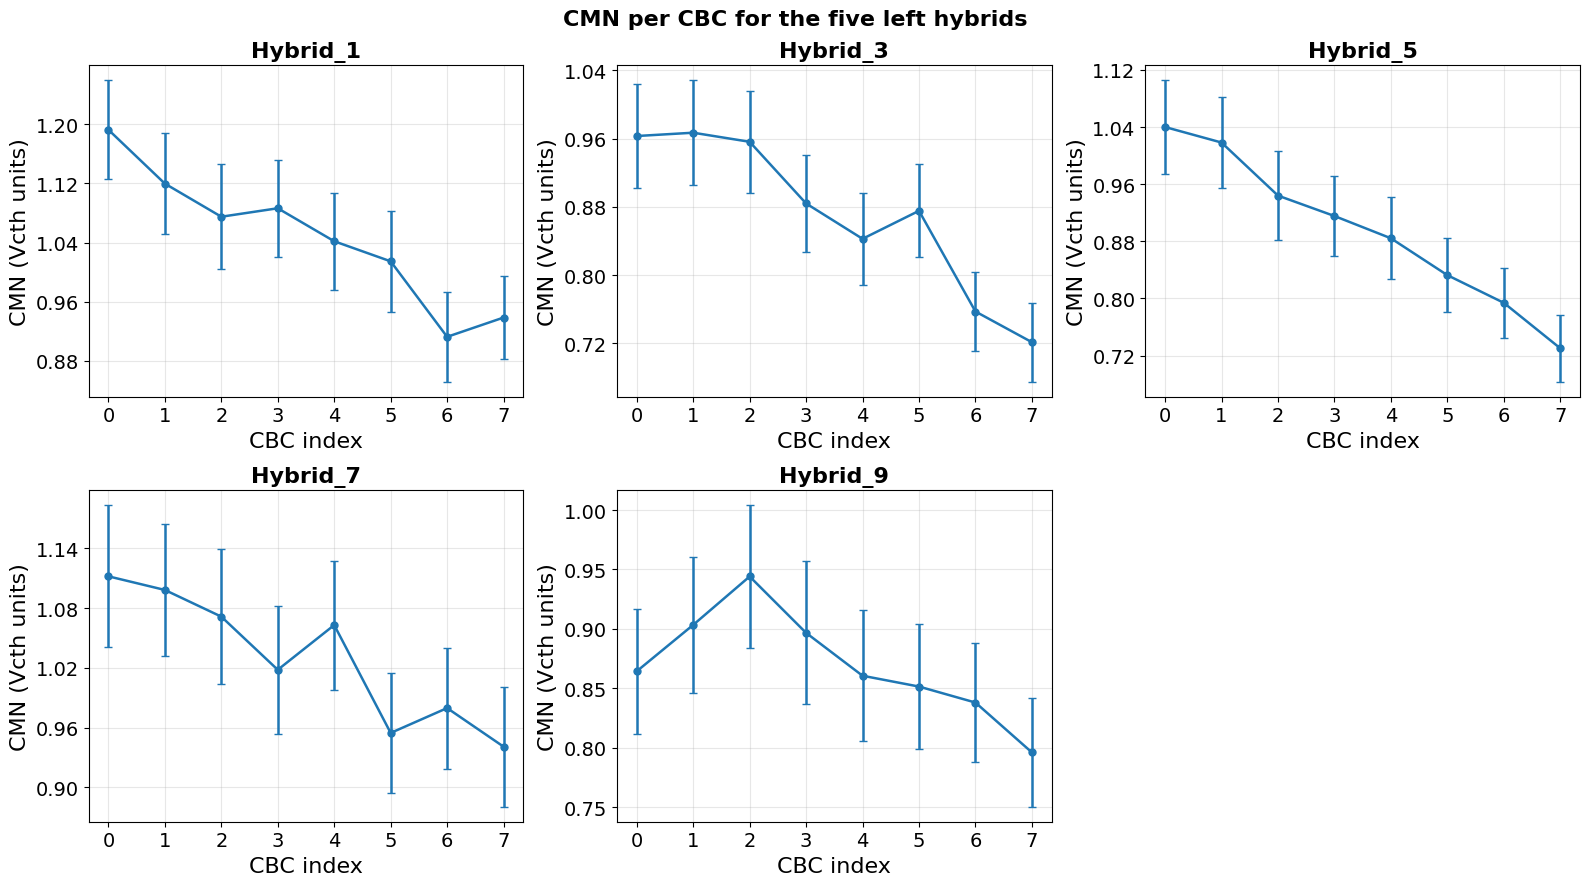

In [115]:
# Plot CM_VcTh for each CBC in the five hybrids (one subplot per hybrid)
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import MaxNLocator

if 'df' not in globals() or not isinstance(df, pd.DataFrame) or df.empty:
    raise RuntimeError("Run the previous CBC CM computation cell first to create 'df'.")

required_cols = {'Hybrid', 'CBC', 'CM_VcTh'}
missing = required_cols.difference(df.columns)
if missing:
    raise ValueError(f"Missing required columns in df: {sorted(missing)}")

plot_df = df.copy()
plot_df['cbc_idx'] = plot_df['CBC'].astype(str).str.extract(r'(\d+)$').astype(int)
plot_df = plot_df.sort_values(['Hybrid', 'cbc_idx'])

# Error bars from sigma_single_clipped_std; propagate to CM with CM = Gamma * sigma_single.
if {'sigma_single_clipped_std', 'Gamma'}.issubset(plot_df.columns):
    plot_df['CM_err'] = np.abs(plot_df['Gamma'] * plot_df['sigma_single_clipped_std'])
elif 'sigma_single_clipped_std' in plot_df.columns:
    plot_df['CM_err'] = np.abs(plot_df['sigma_single_clipped_std'])
else:
    plot_df['CM_err'] = np.nan

hybrids = sorted(plot_df['Hybrid'].unique(), key=lambda x: int(str(x).split('_')[-1]))
n = len(hybrids)
ncols = 3
nrows = int(np.ceil(n / ncols))

# sharey=False ensures each panel keeps visible y-axis graduations.
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.5 * nrows), sharey=False)
axes = np.atleast_1d(axes).ravel()

for idx, hybrid in enumerate(hybrids):
    ax = axes[idx]
    hdf = plot_df[plot_df['Hybrid'] == hybrid]
    yerr = hdf['CM_err'].to_numpy(dtype=float)
    if np.isfinite(yerr).any():
        ax.errorbar(
            hdf['cbc_idx'],
            hdf['CM_VcTh'],
            yerr=yerr,
            fmt='o-',
            capsize=3,
            linewidth=1.8,
            markersize=5,
        )
    else:
        ax.plot(hdf['cbc_idx'], hdf['CM_VcTh'], marker='o', linewidth=1.8)

    ax.set_title(f"{hybrid}", fontweight='bold', fontsize=16)
    ax.set_xlabel('CBC index', fontsize=16)
    ax.set_ylabel('CMN (Vcth units)', fontsize=16)
    ax.set_xticks(hdf['cbc_idx'])
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.tick_params(axis='both', labelsize=14)  
    ax.grid(alpha=0.3)

for j in range(n, len(axes)):
    axes[j].axis('off')

plt.suptitle('CMN per CBC for the five left hybrids', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [116]:
# CM noise decreases from CBC_0 to CBC_7 for all hybrids, which could indicate a common noise source affecting the CBCs in a similar way across the hybrids. This pattern suggests that the noise may be related to the physical layout of the CBCs on the hybrid, such as shared power lines, grounding issues, or electromagnetic interference that is more pronounced in certain regions. Further investigation into the specific design and electronics of the CBCs, as well as potential environmental factors, could help identify the root cause of this noise pattern and inform strategies for mitigation.

In [117]:
#STUDY OF CBC-LEVEL of hybrid R of of 2S modules(8CBCs x 254 channels)

In [118]:
# CBC-Level Common Mode Noise Analysis (40 CBCs across Board_0)

import numpy as np
import pandas as pd
from scipy import stats

# Define the 5 hybrids on Board_0, one per optical group NO SENSE TO COMPARE CBCs FROM 5 DIFFERENT MODULES ????
hybrids_config = [
    ("OpticalGroup_0", "Hybrid_0", 0),
    ("OpticalGroup_1", "Hybrid_2", 2),
    ("OpticalGroup_2", "Hybrid_4", 4),
    ("OpticalGroup_3", "Hybrid_6", 6),
    ("OpticalGroup_4", "Hybrid_8", 8),
]

root_file = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root", "READ")
cbc_data = {}
cbc_rows = []

print("\n" + "=" * 80)
print("EXTRACTING CBC-LEVEL COMMON MODE NOISE DATA")
print("=" * 80)

# Extract CBC histograms from each hybrid
for og_name, hybrid_name, hybrid_id in hybrids_config:
    base_path = f"Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/{og_name}/{hybrid_name}"
    hybrid_dir = root_file.Get(base_path)
    
    if not hybrid_dir:
        print(f"\n[SKIP] Could not find: {base_path}")
        continue
    
    print(f"\n{og_name} / {hybrid_name}:")
    
    # List CBC directories/objects
    keys = hybrid_dir.GetListOfKeys()
    cbc_count = 0
    
    for i in range(keys.GetSize()):
        key = keys.At(i)
        obj_name = key.GetName()
        obj_class = key.GetClassName()
        
        # Look for CBC directories (should be TDirectoryFile)
        if 'CBC' in obj_name:
            cbc_obj = hybrid_dir.Get(obj_name)
            cbc_idx = None
            
            # Extract CBC index from name (e.g., "CBC_0" → 0)
            try:
                cbc_idx = int(obj_name.split('_')[1])
            except:
                try:
                    cbc_idx = int(obj_name[-1])
                except:
                    pass
            
            if cbc_idx is not None:
                # If it's a directory, look inside for histograms
                if hasattr(cbc_obj, 'GetListOfKeys'):
                    cbc_keys = cbc_obj.GetListOfKeys()
                    for j in range(cbc_keys.GetSize()):
                        sub_key = cbc_keys.At(j)
                        sub_name = sub_key.GetName()
                        sub_class = sub_key.GetClassName()
                        
                        # Look for CommonNoise histogram
                        if 'CommonNoise' in sub_name and 'TH1' in sub_class:
                            hist = cbc_obj.Get(sub_name)
                            if isinstance(hist, ROOT.TH1F):
                                cbc_data[(og_name, hybrid_id, cbc_idx)] = {
                                    "mean": float(hist.GetMean()),
                                    "rms": float(hist.GetRMS()),
                                    "entries": int(hist.GetEntries()),
                                    "histogram": hist,
                                }
                                cbc_rows.append({
                                    "OpticalGroup": og_name,
                                    "Hybrid": hybrid_id,
                                    "CBC": cbc_idx,
                                    "Mean": float(hist.GetMean()),
                                    "RMS": float(hist.GetRMS()),
                                    "Entries": int(hist.GetEntries()),
                                })
                                cbc_count += 1
                                print(f"  ✓ CBC_{cbc_idx}: {sub_name}")
                                break
                else:
                    # Try to get it directly as a histogram
                    if isinstance(cbc_obj, ROOT.TH1F):
                        cbc_data[(og_name, hybrid_id, cbc_idx)] = {
                            "mean": float(cbc_obj.GetMean()),
                            "rms": float(cbc_obj.GetRMS()),
                            "entries": int(cbc_obj.GetEntries()),
                            "histogram": cbc_obj,
                        }
                        cbc_rows.append({
                            "OpticalGroup": og_name,
                            "Hybrid": hybrid_id,
                            "CBC": cbc_idx,
                            "Mean": float(cbc_obj.GetMean()),
                            "RMS": float(cbc_obj.GetRMS()),
                            "Entries": int(cbc_obj.GetEntries()),
                        })
                        cbc_count += 1
                        print(f"  ✓ CBC_{cbc_idx}")
    
    print(f"  → Found {cbc_count} CBC histograms")

print(f"\n" + "=" * 80)
print(f"SUMMARY: Extracted {len(cbc_data)} CBC histograms")
print("=" * 80)

if len(cbc_data) > 0:
    df_cbc = pd.DataFrame(cbc_rows)
    print(f"\nCBC Statistics by Optical Group:")
    cbc_summary = df_cbc.groupby("OpticalGroup")[["Mean", "RMS"]].agg(['count', 'mean', 'std', 'min', 'max'])
    print(cbc_summary.round(4))
    
    print(f"\n\nOverall CBC Statistics (all {len(df_cbc)} CBCs):")
    print(f"  Mean noise:     {df_cbc['Mean'].mean():.6f} ± {df_cbc['Mean'].std():.6f}")
    print(f"  RMS noise:      {df_cbc['RMS'].mean():.6f} ± {df_cbc['RMS'].std():.6f}")
    print(f"  Min/Max Mean:   {df_cbc['Mean'].min():.6f} / {df_cbc['Mean'].max():.6f}")
    print(f"  Min/Max RMS:    {df_cbc['RMS'].min():.6f} / {df_cbc['RMS'].max():.6f}")
    print(f"\n  Noisiest CBC:   {df_cbc.loc[df_cbc['Mean'].idxmax(), 'OpticalGroup']} Hybrid_{int(df_cbc.loc[df_cbc['Mean'].idxmax(), 'Hybrid'])} CBC_{int(df_cbc.loc[df_cbc['Mean'].idxmax(), 'CBC'])} (Mean={df_cbc['Mean'].max():.4f})")
    print(f"  Cleanest CBC:   {df_cbc.loc[df_cbc['Mean'].idxmin(), 'OpticalGroup']} Hybrid_{int(df_cbc.loc[df_cbc['Mean'].idxmin(), 'Hybrid'])} CBC_{int(df_cbc.loc[df_cbc['Mean'].idxmin(), 'CBC'])} (Mean={df_cbc['Mean'].min():.4f})")

    print("\nPer-hybrid CBC breakdown (mean and RMS for each CBC):")
    cbc_detail = (
        df_cbc.sort_values(["Hybrid", "CBC"])
        .loc[:, ["OpticalGroup", "Hybrid", "CBC", "Mean", "RMS", "Entries"]]
    )
    for hybrid_id in sorted(df_cbc["Hybrid"].unique()):
        hybrid_df = cbc_detail[cbc_detail["Hybrid"] == hybrid_id]
        print(f"\nHybrid_{hybrid_id}:")
        print(hybrid_df.to_string(index=False, formatters={
            "Mean": "{:.6f}".format,
            "RMS": "{:.6f}".format,
        }))

else:
    print("\n[WARNING] No CBC data extracted. Root file structure may differ.")
    df_cbc = None

print("=" * 80)



EXTRACTING CBC-LEVEL COMMON MODE NOISE DATA

OpticalGroup_0 / Hybrid_0:
  ✓ CBC_0: D_B(0)_O(0)_H(0)_CommonNoiseHits_OccupancyDriven_Chip(0)
  ✓ CBC_1: D_B(0)_O(0)_H(0)_CommonNoiseHits_OccupancyDriven_Chip(1)
  ✓ CBC_2: D_B(0)_O(0)_H(0)_CommonNoiseHits_OccupancyDriven_Chip(2)
  ✓ CBC_3: D_B(0)_O(0)_H(0)_CommonNoiseHits_OccupancyDriven_Chip(3)
  ✓ CBC_4: D_B(0)_O(0)_H(0)_CommonNoiseHits_OccupancyDriven_Chip(4)
  ✓ CBC_5: D_B(0)_O(0)_H(0)_CommonNoiseHits_OccupancyDriven_Chip(5)
  ✓ CBC_6: D_B(0)_O(0)_H(0)_CommonNoiseHits_OccupancyDriven_Chip(6)
  ✓ CBC_7: D_B(0)_O(0)_H(0)_CommonNoiseHits_OccupancyDriven_Chip(7)
  → Found 8 CBC histograms

OpticalGroup_1 / Hybrid_2:
  ✓ CBC_0: D_B(0)_O(1)_H(2)_CommonNoiseHits_OccupancyDriven_Chip(0)
  ✓ CBC_1: D_B(0)_O(1)_H(2)_CommonNoiseHits_OccupancyDriven_Chip(1)
  ✓ CBC_2: D_B(0)_O(1)_H(2)_CommonNoiseHits_OccupancyDriven_Chip(2)
  ✓ CBC_3: D_B(0)_O(1)_H(2)_CommonNoiseHits_OccupancyDriven_Chip(3)
  ✓ CBC_4: D_B(0)_O(1)_H(2)_CommonNoiseHits_OccupancyDri

In [119]:
# CBCs of hybrid R of module 1 and 3 are the nosiest
# CBCs of hybrid R of all modules are getting more noisy from CBCs 0 to 7(except CBC 6 which is systematically a bit lower than CBC 5), which could indicate a common noise pattern across the CBCs, potentially related to the design or operation of the CBCs themselves. This trend suggests that certain CBCs (e.g., CBC_0) may be more susceptible to noise, while others (e.g., CBC_7) are more stable. Further investigation into the specific characteristics of each CBC and their associated electronics could help identify the root cause of this noise pattern and inform potential mitigation strategies. 


/tmp/ipykernel_3937/4017602404.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax2.boxplot(box_data_cbc, labels=cbc_labels_box, patch_artist=True)


Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0003_fig1.pdf


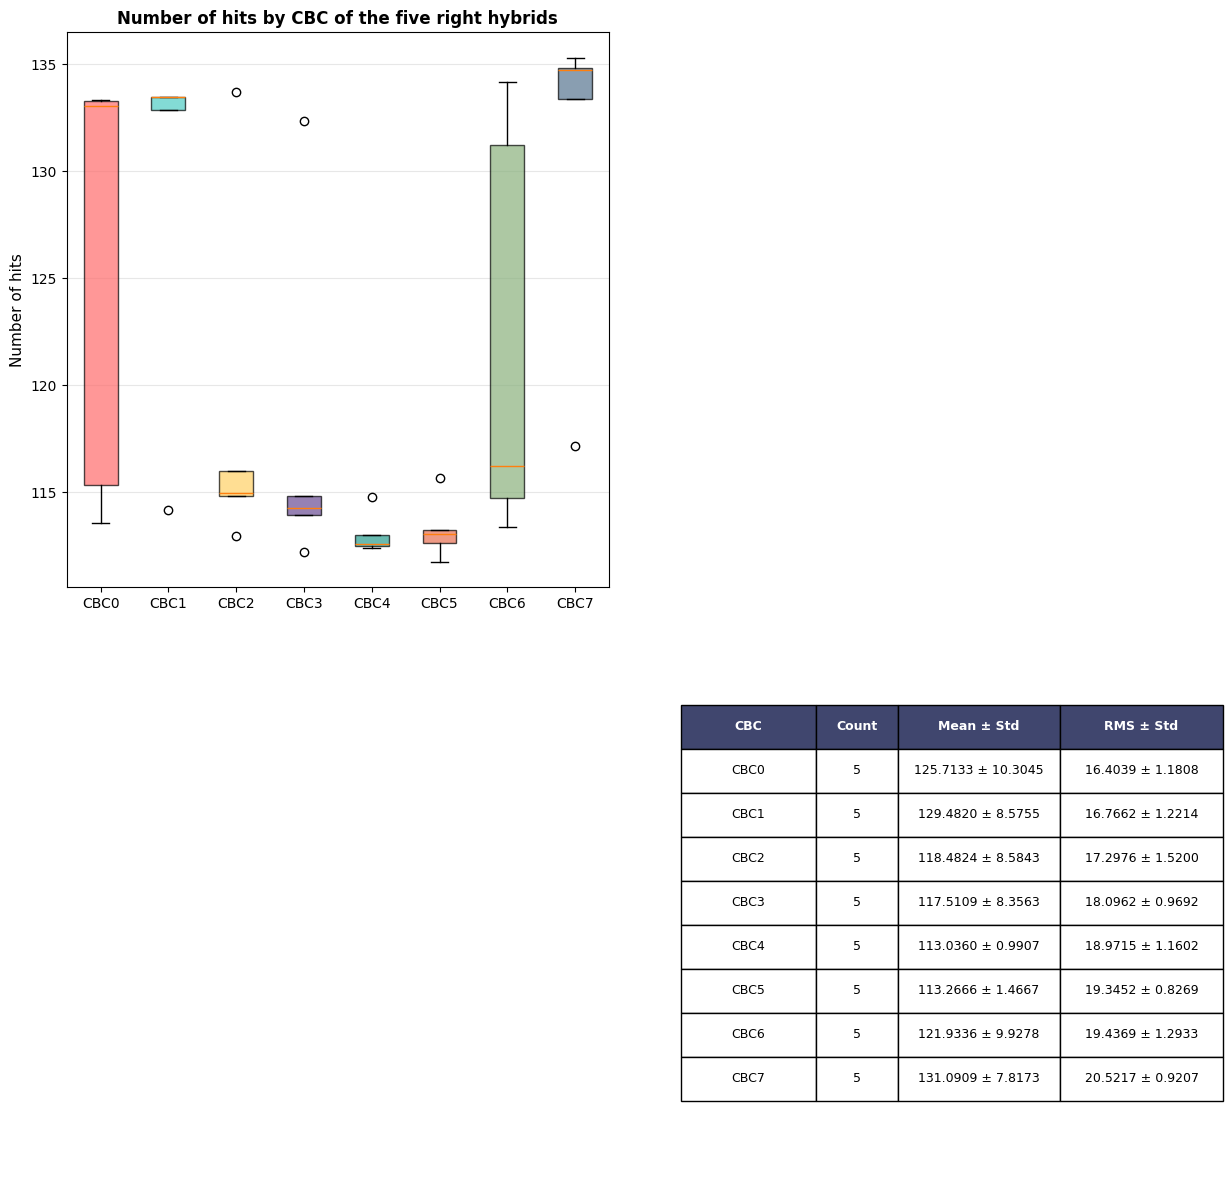

In [120]:
# CBC-Level Visualizations and Statistical Analysis

if df_cbc is not None and len(df_cbc) > 0:
    fig = plt.figure(figsize=(18, 12))
    
    # Plot 2: Number of hits per CBC (box plot)
    ax2 = plt.subplot(2, 3, 2)
    cbc_list = sorted(df_cbc['CBC'].unique())
    box_data_cbc = [df_cbc[df_cbc['CBC'] == cbc]['Mean'].values for cbc in cbc_list]
    cbc_labels_box = [f'CBC{cbc}' for cbc in cbc_list]
    
    bp = ax2.boxplot(box_data_cbc, labels=cbc_labels_box, patch_artist=True)
    colors_palette = ['#FF6B6B', '#4ECDC4', '#FFD166', '#6A4C93', '#2A9D8F', '#E76F51', '#8AB17D', '#577590']
    for patch, color in zip(bp['boxes'], colors_palette):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    ax2.set_ylabel('Number of hits', fontsize=11)
    ax2.set_title('Number of hits by CBC of the five right hybrids', fontsize=12, fontweight='bold')
    ax2.grid(axis='y', alpha=0.3)
    
    # Plot 6: Statistics Table
    ax6 = plt.subplot(2, 3, 6)
    ax6.axis('off')
    
    table_data = [['CBC', 'Count', 'Mean ± Std', 'RMS ± Std']]
    for cbc in cbc_list:
        cbc_data = df_cbc[df_cbc['CBC'] == cbc]
        table_data.append([
            f'CBC{cbc}',
            str(len(cbc_data)),
            f"{cbc_data['Mean'].mean():.4f} ± {cbc_data['Mean'].std():.4f}",
            f"{cbc_data['RMS'].mean():.4f} ± {cbc_data['RMS'].std():.4f}"
        ])
    
    table = ax6.table(cellText=table_data, cellLoc='center', loc='center', colWidths=[0.25, 0.15, 0.30, 0.30])
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1, 2)
    
    for i in range(len(table_data[0])):
        table[(0, i)].set_facecolor('#40466e')
        table[(0, i)].set_text_props(weight='bold', color='white')
    
    plt.tight_layout()
    plt.show()

In [121]:
# outlier cbc 0 : o2_h4_cbc_0 
# for cbc 1 : o2_h4_cbc_1 and o3_h6_cbc_1 are less hit
# outlier cbc 2 : o4_h8_cbc_2
# for cbc 5 : o1_h2_cbc_5 and o3_h6_cbc_5 are more hit 
# outlier cbc 6 : o1_h2_cbc_6
# outlier cbc 7 : o4_h8_cbc_7

# COULD BE INTERESTING TO DO COMPARISON BETWEEN CBCs OF HYBRID L AND HYBRID R

In [122]:
# Study of gamma of cbcs of hybrid R of 2S modules 

In [123]:
# Recompute Gamma (Eq.19/20) and common-mode noise for hybrids 0,2,4,6,8
import math
import numpy as np
import pandas as pd
import ROOT

root_file = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root", "READ")

cbc_specs = [
    ("OpticalGroup_0", "Hybrid_0", "CBC_0", 0, 0),
    ("OpticalGroup_0", "Hybrid_0", "CBC_1", 0, 1),
    ("OpticalGroup_0", "Hybrid_0", "CBC_2", 0, 2),
    ("OpticalGroup_0", "Hybrid_0", "CBC_3", 0, 3),
    ("OpticalGroup_0", "Hybrid_0", "CBC_4", 0, 4),
    ("OpticalGroup_0", "Hybrid_0", "CBC_5", 0, 5),
    ("OpticalGroup_0", "Hybrid_0", "CBC_6", 0, 6),
    ("OpticalGroup_0", "Hybrid_0", "CBC_7", 0, 7),

    ("OpticalGroup_1", "Hybrid_2", "CBC_0", 2, 0),
    ("OpticalGroup_1", "Hybrid_2", "CBC_1", 2, 1),
    ("OpticalGroup_1", "Hybrid_2", "CBC_2", 2, 2),
    ("OpticalGroup_1", "Hybrid_2", "CBC_3", 2, 3),
    ("OpticalGroup_1", "Hybrid_2", "CBC_4", 2, 4),
    ("OpticalGroup_1", "Hybrid_2", "CBC_5", 2, 5),
    ("OpticalGroup_1", "Hybrid_2", "CBC_6", 2, 6),
    ("OpticalGroup_1", "Hybrid_2", "CBC_7", 2, 7),

    ("OpticalGroup_2", "Hybrid_4", "CBC_0", 4, 0),
    ("OpticalGroup_2", "Hybrid_4", "CBC_1", 4, 1),
    ("OpticalGroup_2", "Hybrid_4", "CBC_2", 4, 2),
    ("OpticalGroup_2", "Hybrid_4", "CBC_3", 4, 3),
    ("OpticalGroup_2", "Hybrid_4", "CBC_4", 4, 4),
    ("OpticalGroup_2", "Hybrid_4", "CBC_5", 4, 5),
    ("OpticalGroup_2", "Hybrid_4", "CBC_6", 4, 6),
    ("OpticalGroup_2", "Hybrid_4", "CBC_7", 4, 7),

    ("OpticalGroup_3", "Hybrid_6", "CBC_0", 6, 0),
    ("OpticalGroup_3", "Hybrid_6", "CBC_1", 6, 1),
    ("OpticalGroup_3", "Hybrid_6", "CBC_2", 6, 2),
    ("OpticalGroup_3", "Hybrid_6", "CBC_3", 6, 3),
    ("OpticalGroup_3", "Hybrid_6", "CBC_4", 6, 4),
    ("OpticalGroup_3", "Hybrid_6", "CBC_5", 6, 5),
    ("OpticalGroup_3", "Hybrid_6", "CBC_6", 6, 6),
    ("OpticalGroup_3", "Hybrid_6", "CBC_7", 6, 7),

    ("OpticalGroup_4", "Hybrid_8", "CBC_0", 8, 0),
    ("OpticalGroup_4", "Hybrid_8", "CBC_1", 8, 1),
    ("OpticalGroup_4", "Hybrid_8", "CBC_2", 8, 2),
    ("OpticalGroup_4", "Hybrid_8", "CBC_3", 8, 3),
    ("OpticalGroup_4", "Hybrid_8", "CBC_4", 8, 4),
    ("OpticalGroup_4", "Hybrid_8", "CBC_5", 8, 5),
    ("OpticalGroup_4", "Hybrid_8", "CBC_6", 8, 6),
    ("OpticalGroup_4", "Hybrid_8", "CBC_7", 8, 7),
]

def compute_gamma(hist):
    n_channels = int(hist.GetNbinsX() - 1)
    mean_hits = float(hist.GetMean())
    variance_hits = float(hist.GetRMS()) ** 2
    alpha_tilde = 2.0 * math.pi * (variance_hits - mean_hits * (1.0 - mean_hits / n_channels)) / (n_channels * (n_channels - 1))
    sin_alpha = math.sin(alpha_tilde)
    gamma_sq = sin_alpha / (1.0 - sin_alpha) if (1.0 - sin_alpha) != 0 else 0.0
    gamma = math.sqrt(max(gamma_sq, 0.0))
    return gamma

# This function performs sigma-clipping on a list of values to compute a robust mean and standard deviation.
def sigma_clipped_stats(values, sigma, maxiters):
    vals = np.asarray(values, dtype=float).copy()
    vals = vals[np.isfinite(vals)]
    if vals.size == 0:
        return (np.nan, np.nan, 0, 0, 0)
    n_initial = vals.size
    for _ in range(maxiters):
        if vals.size <= 1:
            break
        m = vals.mean()
        s = vals.std(ddof=1)
        if s == 0.0:
            break
        keep = np.abs(vals - m) <= sigma * s
        if keep.sum() == vals.size:
            break
        vals = vals[keep]
    n_rejected = n_initial - vals.size
    return (float(vals.mean()) if vals.size>0 else np.nan, float(vals.std(ddof=1)) if vals.size>1 else 0.0, int(vals.size), int(n_rejected), int(n_initial))

results = []
for og_name, hybrid_name, cbc_name, hybrid_id, cbc_id in cbc_specs:
    cm_path = f"Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/{og_name}/{hybrid_name}/{cbc_name}/D_B(0)_O({hybrid_id // 2})_H({hybrid_id})_CommonNoiseHits_OccupancyDriven_Chip({cbc_id})"
    strip_path = f"Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/{og_name}/{hybrid_name}/{cbc_name}/D_B(0)_O({hybrid_id // 2})_H({hybrid_id})_ChannelNoise_Chip({cbc_id})"
    cm_hist = root_file.Get(cm_path)
    strip_hist = root_file.Get(strip_path)
    if not cm_hist or not strip_hist:
        print(f"[SKIP] Missing hist for {hybrid_name}")
        continue
    gamma = compute_gamma(cm_hist)
    # extract per-channel noise values
    vals = []
    for i in range(1, strip_hist.GetNbinsX()+1):
        v = float(strip_hist.GetBinContent(i))
        if np.isfinite(v) and v>0:
            vals.append(v)
    mean_clipped, std_clipped, n_kept, n_rej, n_init = sigma_clipped_stats(vals, sigma=3.0, maxiters=5)
    cm_val = gamma * mean_clipped
    results.append({
        'Hybrid': f'Hybrid_{hybrid_id}',
        'CBC': f'CBC_{cbc_id}',
        'Gamma': gamma,
        'sigma_single_clipped_mean': mean_clipped,
        'sigma_single_clipped_std': std_clipped,
        'n_initial': n_init,
        'n_rejected': n_rej,
        'CM_VcTh': cm_val,
    })

df = pd.DataFrame(results)
print(df.to_string(index=False, formatters={
    'Gamma': '{:.6f}'.format,
    'sigma_single_clipped_mean': '{:.4f}'.format,
    'sigma_single_clipped_std': '{:.4f}'.format,
    'CM_VcTh': '{:.4f}'.format,
}))

  Hybrid   CBC    Gamma sigma_single_clipped_mean sigma_single_clipped_std  n_initial  n_rejected CM_VcTh
Hybrid_0 CBC_0 0.118823                    5.1465                   0.3296        254           0  0.6115
Hybrid_0 CBC_1 0.127786                    5.1859                   0.3139        254           0  0.6627
Hybrid_0 CBC_2 0.124467                    5.4999                   0.3513        254           3  0.6846
Hybrid_0 CBC_3 0.145630                    5.2305                   0.3313        254           0  0.7617
Hybrid_0 CBC_4 0.150161                    5.0425                   0.3431        254           1  0.7572
Hybrid_0 CBC_5 0.160867                    5.0014                   0.3206        254           0  0.8046
Hybrid_0 CBC_6 0.155710                    5.4272                   0.3419        254           0  0.8451
Hybrid_0 CBC_7 0.174789                    5.2623                   0.3519        254           0  0.9198
Hybrid_2 CBC_0 0.146971                    5.3

Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0004_fig1.pdf


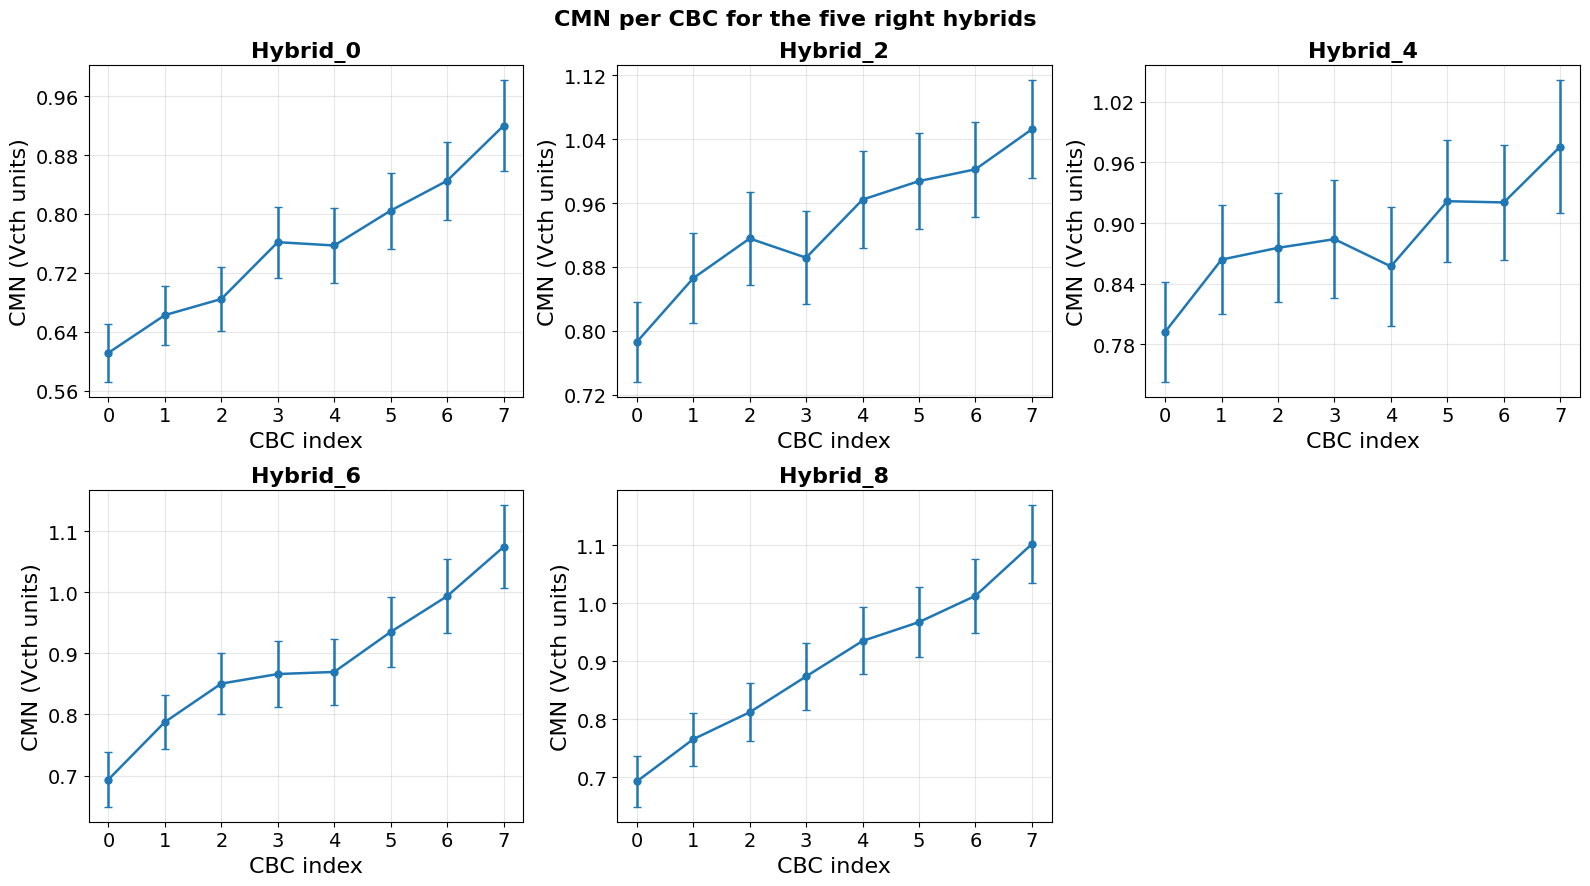

In [124]:
# Plot CM_VcTh for each CBC in the five hybrids (one subplot per hybrid)
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import MaxNLocator

if 'df' not in globals() or not isinstance(df, pd.DataFrame) or df.empty:
    raise RuntimeError("Run the previous CBC CM computation cell first to create 'df'.")

required_cols = {'Hybrid', 'CBC', 'CM_VcTh'}
missing = required_cols.difference(df.columns)
if missing:
    raise ValueError(f"Missing required columns in df: {sorted(missing)}")

plot_df = df.copy()
plot_df['cbc_idx'] = plot_df['CBC'].astype(str).str.extract(r'(\d+)$').astype(int)
plot_df = plot_df.sort_values(['Hybrid', 'cbc_idx'])

# Error bars from sigma_single_clipped_std; propagate to CM with CM = Gamma * sigma_single.
if {'sigma_single_clipped_std', 'Gamma'}.issubset(plot_df.columns):
    plot_df['CM_err'] = np.abs(plot_df['Gamma'] * plot_df['sigma_single_clipped_std'])
elif 'sigma_single_clipped_std' in plot_df.columns:
    plot_df['CM_err'] = np.abs(plot_df['sigma_single_clipped_std'])
else:
    plot_df['CM_err'] = np.nan

hybrids = sorted(plot_df['Hybrid'].unique(), key=lambda x: int(str(x).split('_')[-1]))
n = len(hybrids)
ncols = 3
nrows = int(np.ceil(n / ncols))

# sharey=False ensures each panel keeps visible y-axis graduations.
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.5 * nrows), sharey=False)
axes = np.atleast_1d(axes).ravel()

for idx, hybrid in enumerate(hybrids):
    ax = axes[idx]
    hdf = plot_df[plot_df['Hybrid'] == hybrid]
    yerr = hdf['CM_err'].to_numpy(dtype=float)
    if np.isfinite(yerr).any():
        ax.errorbar(
            hdf['cbc_idx'],
            hdf['CM_VcTh'],
            yerr=yerr,
            fmt='o-',
            capsize=3,
            linewidth=1.8,
            markersize=5,
        )
    else:
        ax.plot(hdf['cbc_idx'], hdf['CM_VcTh'], marker='o', linewidth=1.8)

    ax.set_title(f"{hybrid}", fontweight='bold', fontsize=16)
    ax.set_xlabel('CBC index', fontsize=16)
    ax.set_ylabel('CMN (Vcth units)', fontsize=16)
    ax.set_xticks(hdf['cbc_idx'])
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.tick_params(axis='both', labelsize=14)  
    ax.grid(alpha=0.3)

for j in range(n, len(axes)):
    axes[j].axis('off')

plt.suptitle('CMN per CBC for the five right hybrids', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [125]:
# CM noise increases from CBC_0 to CBC_7 for all hybrids, which could indicate a common noise source affecting the CBCs in a similar way across the hybrids. This pattern suggests that the noise may be related to the physical layout of the CBCs on the hybrid, such as shared power lines, grounding issues, or electromagnetic interference that is more pronounced in certain regions. Further investigation into the specific design and electronics of the CBCs, as well as potential environmental factors, could help identify the root cause of this noise pattern and inform strategies for mitigation.

In [126]:
#STUDY OF HYBRID L of 2S modules(5 hybrids)

In [127]:
import ROOT
import numpy as np
import matplotlib.pyplot as plt

# Ouvrir seulement les fichiers nécessaires
inFile2bot1 = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise2bot1 = inFile2bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_0/Hybrid_1/D_B(0)_O(0)_CommonNoiseHits_OccupancyDriven_Hybrid(1)")

inFile3bot1 = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise3bot1 = inFile3bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_1/Hybrid_3/D_B(0)_O(1)_CommonNoiseHits_OccupancyDriven_Hybrid(3)")

inFile4bot1 = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ")
Noise4bot1 = inFile4bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_2/Hybrid_5/D_B(0)_O(2)_CommonNoiseHits_OccupancyDriven_Hybrid(5)")

inFile5bot1 = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise5bot1 = inFile5bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_3/Hybrid_7/D_B(0)_O(3)_CommonNoiseHits_OccupancyDriven_Hybrid(7)")

inFile6bot1 = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise6bot1 = inFile6bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_4/Hybrid_9/D_B(0)_O(4)_CommonNoiseHits_OccupancyDriven_Hybrid(9)")


In [128]:
# Extract bin-by-bin data from the five 2S hybrid histograms
hybrid_histograms = [
    ("Hybrid 1", Noise2bot1),
    ("Hybrid 3", Noise3bot1),
    ("Hybrid 5", Noise4bot1),
    ("Hybrid 7", Noise5bot1),
    ("Hybrid 9", Noise6bot1),
]

histogram_data = {}

print("\n" + "=" * 80)
print("HISTOGRAM BIN-BY-BIN DATA EXTRACTION")
print("=" * 80)

for hybrid_name, hist in hybrid_histograms:
    if hist is None:
        print(f"\n[SKIP] {hybrid_name}: histogram not found")
        continue
    
    # Extract basic statistics
    entries = int(hist.GetEntries())
    mean = float(hist.GetMean())
    std_dev = float(hist.GetStdDev())
    rms = float(hist.GetRMS())
    
    print(f"\n{hybrid_name}:")
    print(f"  Entries: {entries}")
    print(f"  Mean: {mean:.4f}")
    print(f"  Std Dev: {std_dev:.4f}")
    print(f"  RMS: {rms:.4f}")
    
    # Extract bin-by-bin data
    # ROOT histograms are 1-indexed (bin 0 is underflow, bin N+1 is overflow)
    bin_centers = []
    bin_contents = []
    
    for i in range(1, hist.GetNbinsX() + 1):
        bin_centers.append(hist.GetXaxis().GetBinCenter(i))
        bin_contents.append(hist.GetBinContent(i))
    
    histogram_data[hybrid_name] = {
        "entries": entries,
        "mean": mean,
        "std_dev": std_dev,
        "rms": rms,
        "bin_centers": np.array(bin_centers),
        "bin_contents": np.array(bin_contents),
        "histogram": hist,
        "n_channels": int(hist.GetNbinsX()) - 1,  # fixed physical channel count; must NOT be read off a rebinned histogram
    }


HISTOGRAM BIN-BY-BIN DATA EXTRACTION

Hybrid 1:
  Entries: 2033
  Mean: 1085.9185
  Std Dev: 156.5517
  RMS: 156.5517

Hybrid 3:
  Entries: 2033
  Mean: 1085.8943
  Std Dev: 133.7480
  RMS: 133.7480

Hybrid 5:
  Entries: 2033
  Mean: 1061.9370
  Std Dev: 138.0728
  RMS: 138.0728

Hybrid 7:
  Entries: 2033
  Mean: 1079.7052
  Std Dev: 152.4874
  RMS: 152.4874

Hybrid 9:
  Entries: 2033
  Mean: 1082.2510
  Std Dev: 134.5606
  RMS: 134.5606


In [129]:
# Rebin helper: merge adjacent bins to increase bin width (coarser bins)
# Set `REBIN_FACTOR` > 1 to merge every N bins, or set `TARGET_NBINS` to an integer <= original bins.
# After changing these, rerun this cell and then rerun the fitting cell.
REBIN_FACTOR = 1 # integer; 1 = no rebinning
TARGET_NBINS = None  # or set to desired nbins (int)

def rebin_hist_data(hist, rebin_factor=None, target_bins=None):
    nbins = int(hist.GetNbinsX())
    bin_centers = np.array([hist.GetXaxis().GetBinCenter(i) for i in range(1, nbins+1)])
    bin_contents = np.array([hist.GetBinContent(i) for i in range(1, nbins+1)])
    # determine grouping factor (how many original bins per new bin)
    if target_bins is not None:
        if target_bins <= 0:
            factor = 1
        else:
            factor = max(1, nbins // int(target_bins))
    else:
        factor = int(rebin_factor) if (rebin_factor is not None and int(rebin_factor) > 0) else 1
    if factor == 1:
        return bin_centers, bin_contents, hist
    # build groups of consecutive bins; remainder goes to last group
    groups = []
    start = 0
    while start < nbins:
        end = min(start + factor, nbins)
        groups.append((start, end))
        start = end
    new_centers = []
    new_contents = []
    for a, b in groups:
        c = bin_centers[a:b]
        cont = bin_contents[a:b]
        total = float(cont.sum())
        if total > 0:
            center = float((c * cont).sum() / total)
        else:
            center = float(c.mean())
        new_centers.append(center)
        new_contents.append(total)
    new_centers = np.array(new_centers)
    new_contents = np.array(new_contents)
    # create a ROOT histogram with uniform bins spanning the new centers
    if len(new_centers) == 1:
        xmin = new_centers[0] - 0.5
        xmax = new_centers[0] + 0.5
    else:
        dx = np.diff(new_centers)
        first_edge = new_centers[0] - dx[0] / 2.0
        last_edge = new_centers[-1] + dx[-1] / 2.0
        xmin = float(first_edge)
        xmax = float(last_edge)
    new_hist = ROOT.TH1F(f"rebin_{hist.GetName()}_{factor}", hist.GetTitle(), len(new_centers), xmin, xmax)
    for i, val in enumerate(new_contents, start=1):
        new_hist.SetBinContent(i, float(val))
    return new_centers, new_contents, new_hist

# Apply rebinning to the in-memory histogram_data (if present) so subsequent fit cell uses the rebinned version
try:
    histogram_data  # check variable exists
except NameError:
    histogram_data = None

if histogram_data is not None and (REBIN_FACTOR != 1 or TARGET_NBINS is not None):
    for key in list(histogram_data.keys()):
        entry = histogram_data[key]
        centers, contents, new_hist = rebin_hist_data(entry['histogram'], rebin_factor=REBIN_FACTOR, target_bins=TARGET_NBINS)
        entry['bin_centers'] = centers
        entry['bin_contents'] = contents
        entry['histogram'] = new_hist
    print(f"Applied rebinning: factor={REBIN_FACTOR}, target_bins={TARGET_NBINS}")
else:
    print("No rebinning applied (REBIN_FACTOR=1 and TARGET_NBINS=None)")

No rebinning applied (REBIN_FACTOR=1 and TARGET_NBINS=None)


In [130]:
#The fit is done on the rebinned histogram counts with ROOT’s likelihood fit, which tends to look better when bins are coarser because random fluctuations are smoothed out.
# But the residuals were computed point-by-point against a Gaussian evaluated at the bin center, not against the expected count integrated over each bin. 
# As the bins get wider, that center-value approximation gets worse, so the residuals can deteriorate even while the optimizer finds a “better” fit.
# So the fit can legitimately improve with coarser binning, while the current residual diagnostic gets worse because it is more sensitive to bin-width mismatch.
# sol : the residual diagnostics now compare observed counts to the fitted model integrated over each bin edge instead of using bin-center values.
# Why it matters: If your bins are wide or your function is changing rapidly (like a sharp peak or a steep edge), the value of the function at the center of the bin might not represent the average value of the bin. The "I" option makes the fit more accurate by integrating the model across the bin width.
#-> statistically more rigorous than just "sampling" the function at the middle of the bin.

In [131]:
import math
import pandas as pd
from scipy.signal import find_peaks


def bin_edges_from_hist(hist):
    xaxis = hist.GetXaxis()
    low_edges = np.array([xaxis.GetBinLowEdge(i) for i in range(1, hist.GetNbinsX() + 1)], dtype=float)
    high_edges = np.array([xaxis.GetBinUpEdge(i) for i in range(1, hist.GetNbinsX() + 1)], dtype=float)
    return low_edges, high_edges


def expected_counts_from_fit(fit_func, hist):
    low_edges, high_edges = bin_edges_from_hist(hist)
    expected = np.array([fit_func.Integral(low, high) for low, high in zip(low_edges, high_edges)], dtype=float)
    return low_edges, high_edges, expected


def sigma_from_cm_fraction(mean_hits, n_channels, cm_fraction):
    cm_fraction = max(float(cm_fraction), 0.0)
    if n_channels <= 1:
        return np.nan
    variance_single = mean_hits * (1.0 - mean_hits / n_channels)
    gamma_sq = cm_fraction ** 2
    sin_alpha = gamma_sq / (1.0 + gamma_sq) if gamma_sq > 0.0 else 0.0
    variance_cm = (n_channels * (n_channels - 1) / (2.0 * math.pi)) * math.asin(min(max(sin_alpha, 0.0), 1.0))
    return math.sqrt(max(variance_single + variance_cm, 0.0))


def gaussian_bin_integrated_counts(hist, mean, sigma, total_area):
    low_edges, high_edges = bin_edges_from_hist(hist)
    if not np.isfinite(sigma) or sigma <= 0.0 or total_area <= 0.0:
        return low_edges, high_edges, np.zeros_like(low_edges)

    sqrt2 = math.sqrt(2.0)
    expected = np.array(
        [
            total_area
            * 0.5
            * (
                math.erf((high - mean) / (sqrt2 * sigma))
                - math.erf((low - mean) / (sqrt2 * sigma))
            )
            for low, high in zip(low_edges, high_edges)
        ],
        dtype=float,
    )
    return low_edges, high_edges, expected

def compute_gamma(hist, mean_fit, std_fit):
    n_channels = int(hist.GetNbinsX() - 1)
    mean_hits = float(mean_fit)
    variance_hits = float(std_fit) ** 2
    alpha_tilde = 2.0 * math.pi * (variance_hits - mean_hits * (1.0 - mean_hits / n_channels)) / (n_channels * (n_channels - 1))
    sin_alpha = math.sin(alpha_tilde)
    gamma_sq = sin_alpha / (1.0 - sin_alpha) if (1.0 - sin_alpha) != 0 else 0.0
    gamma = math.sqrt(max(gamma_sq, 0.0))
    return gamma

def compute_chi2_toy_distribution(observed_counts, expected_counts, seed=12345, n_toy=1000, min_expected=0.0):
    """Goodness-of-fit via a parametric bootstrap instead of the asymptotic chi-square table
    (which assumes large bin counts -- not valid here, see the comment further down about low
    counts). For each bin, expected_counts is the fitted model's prediction. We:
      1) compute chi2_real = sum((observed - expected)^2 / expected) over bins with
         expected > min_expected;
      2) draw n_toy fake datasets from Poisson(expected) -- i.e. "toy models" that are, by
         construction, perfect realizations of the fitted model plus only statistical noise -- and
         compute chi2 for each of them the same way, giving the actual sampling distribution of
         chi2 under the null hypothesis "the fit is correct";
      3) the p-value is the fraction of toy chi2 values at least as extreme as chi2_real: how
         probable a chi2 this bad (or worse) is if the model were true.

    min_expected restricts the domain to bins the model is actually meant to describe. With the
    default 0.0, every bin with a nonzero prediction counts, including far-tail bins a Gaussian
    core model was never trying to fit (see Module 5: one bin with expected=4.5e-7 caused 97.5% of
    the total chi2 by itself). Passing min_expected=5.0 -- the classic rule of thumb for chi2
    validity -- restricts to the "core" region the model can plausibly describe. That's a narrower
    claim than the full-range chi2: "does the model fit its own core region", not "does the model
    fit the data" -- see chi2_toy_bins/chi2_toy_used_fraction (and the excluded-event count computed
    in run_root_likelihood_fit) for what's left out and by how much.
    """
    observed_counts = np.asarray(observed_counts, dtype=float)
    expected_counts = np.asarray(expected_counts, dtype=float)
    valid_mask = np.isfinite(observed_counts) & np.isfinite(expected_counts) & (expected_counts > min_expected)

    if not np.any(valid_mask):
        return valid_mask, np.array([]), np.nan, np.nan

    observed_valid = observed_counts[valid_mask]
    expected_valid = expected_counts[valid_mask]

    chi2_real = float(np.sum((observed_valid - expected_valid) ** 2 / expected_valid))

    rng = np.random.default_rng(seed)
    toy_counts = rng.poisson(lam=expected_valid, size=(int(n_toy), expected_valid.size))
    chi2_toy_dist = np.sum((toy_counts - expected_valid[None, :]) ** 2 / expected_valid[None, :], axis=1)

    chi2_p_value = float(np.mean(chi2_toy_dist >= chi2_real))
    return valid_mask, chi2_toy_dist, chi2_real, chi2_p_value


def run_root_likelihood_fit(histogram_data, dataset_label):
    print("\n" + "=" * 80)
    print("HISTOGRAM FITTING AND PEAK ANALYSIS")
    print(f"DATASET: {dataset_label}")
    print("=" * 80)
    print("Using ROOT binned likelihood fit with Poisson bin statistics.")

    fit_results = {}
    colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]
    cm_levels = [0.0, 0.10, 0.20, 0.30]
    cm_colors = ["#5F5252", "#1100FFB5", "#00000041", "#C300FF3B"]
    cm_styles = ["-", "--", ":", "-."]

    for idx, (hybrid_name, data) in enumerate(histogram_data.items()):
        print(f"\n{hybrid_name}:")

        bin_centers = data["bin_centers"]
        bin_contents = data["bin_contents"]
        hist = data["histogram"]

        peaks, properties = find_peaks(bin_contents, height=1, distance=5)

        if len(peaks) > 0:
            peak_idx = peaks[np.argmax(bin_contents[peaks])]
            peak_x = bin_centers[peak_idx]
            peak_y = bin_contents[peak_idx]
            print(f"  Peak found at x={peak_x:.1f}, height={peak_y:.1f}")
            print(f"  Total peaks detected: {len(peaks)}")
        else:
            print("  No distinct peaks found")
            peak_idx = np.argmax(bin_contents)
            peak_x = bin_centers[peak_idx]
            peak_y = bin_contents[peak_idx]
            print(f"  Maximum bin at x={peak_x:.1f}, height={peak_y:.1f}")

        x_min = float(hist.GetXaxis().GetXmin())
        x_max = float(hist.GetXaxis().GetXmax())
        amplitude_guess = max(float(peak_y), 1.0)
        mean_guess = float(peak_x)
        std_guess = max(float(data["std_dev"]), 1e-3)

        safe_name = "".join(ch if ch.isalnum() else "_" for ch in f"{dataset_label}_{hybrid_name}")
        fit_func = ROOT.TF1(f"fit_{safe_name}", "gaus", x_min, x_max)
        fit_func.SetParameters(amplitude_guess, mean_guess, std_guess)
        fit_func.SetParLimits(0, 0.0, max(amplitude_guess * 10.0, 1.0))
        fit_func.SetParLimits(1, x_min, x_max)
        fit_func.SetParLimits(2, 1e-6, max(x_max - x_min, std_guess * 10.0))

        try:
            fit_result = hist.Fit(fit_func, "LQRSI")
            fit_status = int(fit_result)

            amplitude_fit = float(fit_func.GetParameter(0))
            mean_fit = float(fit_func.GetParameter(1))
            std_fit = abs(float(fit_func.GetParameter(2)))
            # Use the physical channel count captured before any rebinning -- rebinning the
            # display histogram must not change this, or the CM-fraction sigma formula below
            # gets corrupted (n_channels would shrink with the bin count instead of staying fixed).
            n_channels = max(int(data.get("n_channels", hist.GetNbinsX() - 1)), 1)
            mean_hits = float(data.get("mean", np.nan))
            if np.isfinite(mean_hits):
                sigma_expected = sigma_from_cm_fraction(mean_hits, n_channels, 0.0)
            else:
                sigma_expected = np.nan
            sigma_delta = std_fit - sigma_expected if np.isfinite(sigma_expected) else np.nan
            perr = [
                float(fit_func.GetParError(0)),
                float(fit_func.GetParError(1)),
                float(fit_func.GetParError(2)),
            ]

            low_edges, high_edges, expected_counts = expected_counts_from_fit(fit_func, hist)
            observed_counts = np.asarray(bin_contents, dtype=float)
            expected_counts = np.asarray(expected_counts, dtype=float)
            # Goodness-of-fit via a toy (parametric-bootstrap) chi2 distribution instead of DHARMa:
            # generate many Poisson toy datasets from the fitted model, build up the chi2
            # distribution that the model itself predicts, and see where the real data's chi2 falls
            # in that distribution -- more robust than the asymptotic chi2 table when bins have low
            # counts (see the note below about traditional chi2 approximations breaking down).
            chi2_mask, chi2_toy_dist, chi2_toy_real, chi2_toy_p_value = compute_chi2_toy_distribution(
                observed_counts,
                expected_counts,
                seed=abs(hash((dataset_label, hybrid_name))) % (2**32),
                n_toy=1000,
            )
            chi2_toy_bins = int(np.count_nonzero(chi2_mask))
            chi2_toy_used_fraction = chi2_toy_bins / len(observed_counts) if len(observed_counts) > 0 else np.nan
            chi2_toy_mean = float(np.mean(chi2_toy_dist)) if chi2_toy_dist.size > 0 else np.nan
            chi2_toy_std = float(np.std(chi2_toy_dist, ddof=1)) if chi2_toy_dist.size > 1 else np.nan

            # If the model's declared region of validity is the core (expected >= 5), its PARAMETERS
            # should be estimated from the core too -- not from a fit to the full range (dragged by
            # tail bins the model isn't meant to describe) that then just gets evaluated on a subset
            # of its own bins. Use the full-range fit only to LOCATE the core window, then refit the
            # Gaussian restricted to that window before computing the core chi2.
            core_min_expected = 5.0
            core_window_mask = expected_counts >= core_min_expected
            if np.any(core_window_mask):
                core_low = float(low_edges[core_window_mask].min())
                core_high = float(high_edges[core_window_mask].max())
            else:
                core_low, core_high = x_min, x_max

            fit_func_core = ROOT.TF1(f"fit_{safe_name}_core", "gaus", core_low, core_high)
            fit_func_core.SetParameters(amplitude_fit, mean_fit, std_fit)
            fit_func_core.SetParLimits(0, 0.0, max(amplitude_fit * 10.0, 1.0))
            fit_func_core.SetParLimits(1, core_low, core_high)
            fit_func_core.SetParLimits(2, 1e-6, max(core_high - core_low, std_fit * 10.0))
            hist.Fit(fit_func_core, "LQRSI")

            amplitude_fit_core = float(fit_func_core.GetParameter(0))
            mean_fit_core = float(fit_func_core.GetParameter(1))
            std_fit_core = abs(float(fit_func_core.GetParameter(2)))

            _, _, expected_counts_core_refit = expected_counts_from_fit(fit_func_core, hist)
            expected_counts_core_refit = np.asarray(expected_counts_core_refit, dtype=float)

            # Core-restricted chi2, now scoring the CORE REFIT (not the full-range fit) against
            # only the bins where that refit predicts expected >= 5 -- a self-consistent test of
            # "does a model fit specifically to the core describe the core".
            core_mask, core_chi2_toy_dist, core_chi2_toy_real, core_chi2_toy_p_value = compute_chi2_toy_distribution(
                observed_counts,
                expected_counts_core_refit,
                seed=abs(hash((dataset_label, hybrid_name, "core"))) % (2**32),
                n_toy=1000,
                min_expected=core_min_expected,
            )
            core_chi2_bins = int(np.count_nonzero(core_mask))
            core_chi2_used_fraction = core_chi2_bins / len(observed_counts) if len(observed_counts) > 0 else np.nan
            core_events_excluded = float(observed_counts[~core_mask].sum())
            core_events_excluded_fraction = core_events_excluded / observed_counts.sum() if observed_counts.sum() > 0 else np.nan

            print("  ROOT likelihood fit:")
            print(f"    Status:     {fit_status}")
            print(f"    Amplitude:  {amplitude_fit:.4f} ± {perr[0]:.4f}")
            print(f"    Mean:       {mean_fit:.4f} ± {perr[1]:.4f}")
            print(f"    Std Dev:    {std_fit:.4f} ± {perr[2]:.4f}")
            if np.isfinite(sigma_expected):
                print(f"    Expected σ: {sigma_expected:.4f} (from μ={mean_hits:.4f}, n={n_channels})")
                print(f"    Δσ(fit-exp): {sigma_delta:+.4f}")
            print("  Toy chi2 goodness-of-fit diagnostics (full range):")
            print(f"    Bins used:   {chi2_toy_bins} / {len(observed_counts)}")
            print(f"    Used frac:   {chi2_toy_used_fraction:.3f}")
            print(f"    Chi2 (real): {chi2_toy_real:.4f}")
            if np.isfinite(chi2_toy_mean):
                print(f"    Chi2 (toy):  {chi2_toy_mean:.4f} ± {chi2_toy_std:.4f}  (mean ± std over {chi2_toy_dist.size} toys)")
            if np.isfinite(chi2_toy_p_value):
                print(f"    p-value:     {chi2_toy_p_value:.4g}")
            else:
                print("    p-value:     n/a")
            print(f"  Core refit (Gaussian refit within [{core_low:.1f}, {core_high:.1f}], expected >= {core_min_expected:.0f}):")
            print(f"    Amplitude:  {amplitude_fit_core:.4f}  (full-range fit: {amplitude_fit:.4f})")
            print(f"    Mean:       {mean_fit_core:.4f}  (full-range fit: {mean_fit:.4f})")
            print(f"    Std Dev:    {std_fit_core:.4f}  (full-range fit: {std_fit:.4f})")
            print(f"  Toy chi2 goodness-of-fit diagnostics (core region, expected >= {core_min_expected:.0f}):")
            print(f"    Bins used:   {core_chi2_bins} / {len(observed_counts)}  ({core_chi2_used_fraction:.3f})")
            print(f"    Events excluded: {core_events_excluded:.0f} ({core_events_excluded_fraction:.4%} of all events)")
            print(f"    Chi2 (real): {core_chi2_toy_real:.4f}")
            if np.isfinite(core_chi2_toy_p_value):
                print(f"    p-value:     {core_chi2_toy_p_value:.4g}")
            else:
                print("    p-value:     n/a")

            fit_results[hybrid_name] = {
                "amplitude": amplitude_fit,
                "amplitude_err": perr[0],
                "mean_fit": mean_fit,
                "mean_err": perr[1],
                "std_fit": std_fit,
                "std_err": perr[2],
                "sigma_expected": sigma_expected,
                "sigma_delta": sigma_delta,
                "entries": int(data.get("entries", 0)),
                "chi2": float(fit_func.GetChisquare()),
                "fit_status": fit_status,
                "peak_x": peak_x,
                "peak_y": peak_y,
                "bin_low_edges": low_edges,
                "bin_high_edges": high_edges,
                "expected_counts": expected_counts,
                "chi2_toy_bins": chi2_toy_bins,
                "chi2_toy_used_fraction": chi2_toy_used_fraction,
                "chi2_toy_dist": chi2_toy_dist,
                "chi2_toy_real": chi2_toy_real,
                "chi2_toy_mean": chi2_toy_mean,
                "chi2_toy_std": chi2_toy_std,
                "chi2_toy_p_value": chi2_toy_p_value,
                "core_chi2_bins": core_chi2_bins,
                "core_chi2_used_fraction": core_chi2_used_fraction,
                "core_events_excluded": core_events_excluded,
                "core_events_excluded_fraction": core_events_excluded_fraction,
                "core_chi2_toy_dist": core_chi2_toy_dist,
                "core_chi2_toy_real": core_chi2_toy_real,
                "core_chi2_toy_p_value": core_chi2_toy_p_value,
                "core_low": core_low,
                "core_high": core_high,
                "amplitude_fit_core": amplitude_fit_core,
                "mean_fit_core": mean_fit_core,
                "std_fit_core": std_fit_core,
                "expected_counts_core_refit": expected_counts_core_refit,
                "fit_func_core": fit_func_core,
                "popt": np.array([amplitude_fit, mean_fit, std_fit]),
                "fit_func": fit_func,
            }
        except Exception as e:
            print(f"  ROOT likelihood fit failed: {e}")
            fit_results[hybrid_name] = {
                "amplitude": np.nan,
                "peak_x": peak_x,
                "peak_y": peak_y,
                "popt": None,
                "chi2": np.nan,
                "fit_status": -1,
                "fit_func": None,
            }

    print("\n" + "=" * 80)
    print(f"VISUALIZATION: Histograms with ROOT Likelihood Fits ({dataset_label})")
    print("=" * 80 + "\n")

    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    axes = axes.ravel()

    for idx, (hybrid_name, data) in enumerate(histogram_data.items()):
        ax = axes[idx]

        bin_centers = data["bin_centers"]
        bin_contents = data["bin_contents"]
        hist = data["histogram"]

        ax.step(bin_centers, bin_contents, where="mid", label="Data",
                color=colors[idx], linewidth=2, alpha=0.7)
        ax.fill_between(bin_centers, bin_contents, step="mid", alpha=0.3, color=colors[idx])

        fit_entry = fit_results.get(hybrid_name, {})
        fit_mean = fit_entry.get("mean_fit", np.nan)
        if not np.isfinite(fit_mean):
            fit_mean = float(data["mean"])
        fit_sigma = fit_entry.get("std_fit", np.nan)
        if not np.isfinite(fit_sigma) or fit_sigma <= 0.0:
            fit_sigma = max(float(data["std_dev"]), 1e-6)

        total_area = max(float(hist.Integral()), 1.0)
        for cm_fraction, cm_color, cm_style in zip(cm_levels, cm_colors, cm_styles):
            sigma_cm = sigma_from_cm_fraction(fit_mean, max(int(data.get("n_channels", hist.GetNbinsX() - 1)), 1), cm_fraction)
            _, _, cm_expected_counts = gaussian_bin_integrated_counts(hist, fit_mean, sigma_cm, total_area)
            ax.step(
                bin_centers,
                cm_expected_counts,
                where="mid",
                color=cm_color,
                linestyle=cm_style,
                linewidth=1.6,
                alpha=0.9,
                label=f"CMN={int(cm_fraction * 100)}%",
            )

        if hybrid_name in fit_results and fit_results[hybrid_name]["popt"] is not None:
            expected_counts = fit_results[hybrid_name].get("expected_counts")
            if expected_counts is None:
                fit_func = fit_results[hybrid_name]["fit_func"]
                _, _, expected_counts = expected_counts_from_fit(fit_func, data["histogram"])
            ax.step(bin_centers, expected_counts, where="mid", color="r", linestyle="--",
                    linewidth=2, label="Gaussian Fit", alpha=0.8)

            expected_counts_core_refit = fit_results[hybrid_name].get("expected_counts_core_refit")
            

            mean_fit = fit_results[hybrid_name].get("mean_fit", np.nan)
            sigma_fit = fit_results[hybrid_name].get("std_fit", np.nan)
            gamma = compute_gamma(hist, mean_fit, sigma_fit) if np.isfinite(mean_fit) and np.isfinite(sigma_fit) else np.nan
            chi2_toy_p_value = fit_results[hybrid_name].get("chi2_toy_p_value", np.nan)
            core_chi2_toy_p_value = fit_results[hybrid_name].get("core_chi2_toy_p_value", np.nan)
            core_events_excluded_fraction = fit_results[hybrid_name].get("core_events_excluded_fraction", np.nan)
            if np.isfinite(gamma):
                fit_box_text = rf"$\Gamma$ = {gamma*100:.3f}%"
            else:
                fit_box_text = r"$\Gamma$ = n/a"
            if np.isfinite(chi2_toy_p_value):
                fit_box_text += "\n" + rf"χ² toy p (full) = {chi2_toy_p_value:.3g}"
            else:
                fit_box_text += "\n" + r"χ² toy p (full) = n/a"
            if np.isfinite(core_chi2_toy_p_value):
                fit_box_text += "\n" + rf"χ² toy p (core) = {core_chi2_toy_p_value:.3g}"
                if np.isfinite(core_events_excluded_fraction):
                    fit_box_text += "\n" + rf" ({core_events_excluded_fraction:.1%} excl.)"
            else:
                fit_box_text += "\n" + r"χ² toy p (core) = n/a"
            ax.text(0.98, 0.97, fit_box_text, transform=ax.transAxes,
                    ha="right", va="top", fontsize=14,
                    bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5))

        peak_x = fit_results[hybrid_name]["peak_x"]
        peak_y = fit_results[hybrid_name]["peak_y"]
        #ax.scatter([peak_x], [peak_y], color="red", s=100, marker="*", zorder=5, label="Peak")

        ax.set_title(f"{hybrid_name}", fontsize=16, fontweight="bold")
        ax.set_xlabel("Number of hits", fontsize=16)
        ax.set_ylabel("Number of events", fontsize=16)
        ax.legend(fontsize=14, loc="upper left")
        ax.tick_params(axis='both', labelsize=14) 
        ax.grid(alpha=0.3)

    axes[-1].axis("off")
    plt.tight_layout()
    plt.show()

    print("\n" + "=" * 80)
    print(f"TOY CHI2 GOODNESS-OF-FIT DISTRIBUTIONS ({dataset_label})")
    print("=" * 80 + "\n")

    fig2, axes2 = plt.subplots(2, 3, figsize=(16, 10))
    axes2 = axes2.ravel()

    for idx, (hybrid_name, data) in enumerate(histogram_data.items()):
        ax = axes2[idx]
        fit_entry = fit_results.get(hybrid_name, {})
        chi2_toy_dist = fit_entry.get("chi2_toy_dist")
        chi2_toy_real = fit_entry.get("chi2_toy_real", np.nan)
        chi2_toy_p_value = fit_entry.get("chi2_toy_p_value", np.nan)

        if chi2_toy_dist is None or chi2_toy_dist.size == 0:
            ax.text(0.03, 0.7, "No toy chi2 distribution", ha="left", va="center", transform=ax.transAxes)
            ax.set_title(f"{hybrid_name}", fontsize=16, fontweight="bold")
            continue

        # This chi2 sums over ~2000 bins whose expected counts span many orders of magnitude
        # (a handful of bins far in the Gaussian's tail have expected << 1), so a rare Poisson
        # "hit" there occasionally produces a huge single-bin contribution -- the toy chi2
        # distribution is heavy right-skewed, with a long thin tail of outlier toys far beyond
        # where the bulk of the distribution (and the real chi2) actually sit. Clip the x-axis to
        # keep the bulk readable and note how many toys were clipped out of view.
        x_clip = max(np.percentile(chi2_toy_dist, 95.0), chi2_toy_real if np.isfinite(chi2_toy_real) else 0.0) * 1.15
        n_clipped = int(np.sum(chi2_toy_dist > x_clip))
        bin_edges = np.linspace(0, x_clip, 41)
        ax.hist(np.clip(chi2_toy_dist, 0, x_clip), bins=bin_edges, color=colors[idx], alpha=0.7,
                label=f"Toy χ² ({chi2_toy_dist.size} toys)")
        if np.isfinite(chi2_toy_real):
            ax.axvline(chi2_toy_real, color="black", linestyle="--", linewidth=2,
                       label=f"Real data χ² = {chi2_toy_real:.1f}")
        ax.set_xlim(0, x_clip)

        p_text = f"p-value = {chi2_toy_p_value:.3g}" if np.isfinite(chi2_toy_p_value) else "p-value = n/a"
        if n_clipped > 0:
            p_text += f"\n({n_clipped} toys off-scale)"
        ax.text(0.04, 0.72, p_text, transform=ax.transAxes, ha="left", va="center", fontsize=14,
                bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5))

        ax.set_title(f"{hybrid_name}", fontsize=16, fontweight="bold")
        ax.set_xlabel("χ² (toy pseudo-experiments)", fontsize=16)
        ax.set_ylabel("Number of toys", fontsize=16)
        ax.set_ylim(0, 600)
        ax.legend(fontsize=14, loc="upper left")
        ax.tick_params(axis='both', labelsize=14) 
        ax.grid(alpha=0.3)

    axes2[-1].axis("off")
    plt.tight_layout()
    plt.show()

    print("\n" + "=" * 80)
    print(f"CORE-REGION TOY CHI2 GOODNESS-OF-FIT DISTRIBUTIONS ({dataset_label})")
    print("=" * 80 + "\n")

    fig3, axes3 = plt.subplots(2, 3, figsize=(16, 10))
    axes3 = axes3.ravel()

    for idx, (hybrid_name, data) in enumerate(histogram_data.items()):
        ax = axes3[idx]
        fit_entry = fit_results.get(hybrid_name, {})
        core_chi2_toy_dist = fit_entry.get("core_chi2_toy_dist")
        core_chi2_toy_real = fit_entry.get("core_chi2_toy_real", np.nan)
        core_chi2_toy_p_value = fit_entry.get("core_chi2_toy_p_value", np.nan)
        core_events_excluded_fraction = fit_entry.get("core_events_excluded_fraction", np.nan)

        if core_chi2_toy_dist is None or core_chi2_toy_dist.size == 0:
            ax.text(0.03, 0.7, "No core toy chi2 distribution", ha="left", va="center", transform=ax.transAxes)
            ax.set_title(f"{hybrid_name}", fontsize=16, fontweight="bold")
            continue

        # Same idea as the full-range plot above, but this distribution is built ONLY from bins
        # with expected >= 5 (the core-refit model, not the full-range one) -- so it behaves like a
        # standard, tight chi-square (mean ~ n_bins, std ~ sqrt(2*n_bins)) instead of the heavy
        # right-skewed shape seen in the full-range plot. Still clip/report off-scale toys for
        # consistency, though with this few outliers it should rarely trigger.
        x_clip = max(np.percentile(core_chi2_toy_dist, 99.0), core_chi2_toy_real if np.isfinite(core_chi2_toy_real) else 0.0) * 1.15
        n_clipped = int(np.sum(core_chi2_toy_dist > x_clip))
        bin_edges = np.linspace(0, x_clip, 41)
        ax.hist(np.clip(core_chi2_toy_dist, 0, x_clip), bins=bin_edges, color=colors[idx], alpha=0.7,
                label=f"Core toy χ² ({core_chi2_toy_dist.size} toys)")
        if np.isfinite(core_chi2_toy_real):
            ax.axvline(core_chi2_toy_real, color="black", linestyle="--", linewidth=2,
                       label=f"Real data χ² = {core_chi2_toy_real:.1f}")
        ax.set_xlim(0, x_clip)

        p_text = f"p-value = {core_chi2_toy_p_value:.3g}" if np.isfinite(core_chi2_toy_p_value) else "p-value = n/a"
        if np.isfinite(core_events_excluded_fraction):
            p_text += f"\n({core_events_excluded_fraction:.1%} events excluded)"
        if n_clipped > 0:
            p_text += f"\n({n_clipped} toys off-scale, not shown)"
        ax.text(0.04, 0.72, p_text, transform=ax.transAxes, ha="left", va="center", fontsize=14,
                bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5))

        ax.set_title(f"{hybrid_name}", fontsize=16, fontweight="bold")
        ax.set_xlabel("χ² (core-refit toy pseudo-experiments)", fontsize=16)
        ax.set_ylabel("Number of toys", fontsize=16)
        ax.legend(fontsize=14, loc="upper left")
        ax.tick_params(axis='both', labelsize=14) 
        ax.grid(alpha=0.3)

    axes3[-1].axis("off")
    plt.tight_layout()
    plt.show()

    print("\n" + "=" * 80)
    print("COMPARISON SUMMARY")
    print("=" * 80)

    comparison_data = []
    for hybrid_name, data in histogram_data.items():
        comparison_data.append({
            "Hybrid": hybrid_name,
            "Mean": data["mean"],
            "Std Dev": data["std_dev"],
            "Entries": data["entries"],
            "Expected Std (mu,n)": fit_results[hybrid_name].get("sigma_expected", np.nan),
            "Fit Std": fit_results[hybrid_name].get("std_fit", np.nan),
            "Delta Std (fit-exp)": fit_results[hybrid_name].get("sigma_delta", np.nan),
            "Chi2 (real)": fit_results[hybrid_name].get("chi2_toy_real", np.nan),
            "Chi2 (toy mean)": fit_results[hybrid_name].get("chi2_toy_mean", np.nan),
            "Chi2 toy p-value": fit_results[hybrid_name].get("chi2_toy_p_value", np.nan),
            "Core Chi2 (real)": fit_results[hybrid_name].get("core_chi2_toy_real", np.nan),
            "Core Chi2 p-value": fit_results[hybrid_name].get("core_chi2_toy_p_value", np.nan),
            "Core events excl. (%)": 100 * fit_results[hybrid_name].get("core_events_excluded_fraction", np.nan),
            "Peak": fit_results[hybrid_name]["peak_x"],
            "Peak Height": fit_results[hybrid_name]["peak_y"],
        })

    df_comparison = pd.DataFrame(comparison_data)
    print(df_comparison.to_string(index=False))

    print("\n" + "=" * 80)
    print("KEY OBSERVATIONS:")
    print("=" * 80)

    mean_min = df_comparison["Mean"].min()
    mean_max = df_comparison["Mean"].max()
    mean_range = mean_max - mean_min
    mean_minmax_hybrid = df_comparison.loc[df_comparison["Mean"].idxmin(), "Hybrid"]
    mean_maxmax_hybrid = df_comparison.loc[df_comparison["Mean"].idxmax(), "Hybrid"]

    std_min = df_comparison["Std Dev"].min()
    std_max = df_comparison["Std Dev"].max()
    std_range = std_max - std_min
    std_minmax_hybrid = df_comparison.loc[df_comparison["Std Dev"].idxmin(), "Hybrid"]
    std_maxmax_hybrid = df_comparison.loc[df_comparison["Std Dev"].idxmax(), "Hybrid"]

    peak_min = df_comparison["Peak Height"].min()
    peak_max = df_comparison["Peak Height"].max()
    peak_minmax_hybrid = df_comparison.loc[df_comparison["Peak Height"].idxmin(), "Hybrid"]
    peak_maxmax_hybrid = df_comparison.loc[df_comparison["Peak Height"].idxmax(), "Hybrid"]

    print(f"Mean noise range: {mean_min:.2f} to {mean_max:.2f} (Δ = {mean_range:.2f})")
    print(f"  Quietest: {mean_minmax_hybrid} (mean = {mean_min:.2f})")
    print(f"  Noisiest: {mean_maxmax_hybrid} (mean = {mean_max:.2f})")
    print(f"  Relative variation: {100 * mean_range / mean_min:.2f}%")

    print(f"\nStandard deviation range: {std_min:.2f} to {std_max:.2f} (Δ = {std_range:.2f})")
    print(f"  Narrowest: {std_minmax_hybrid} (σ = {std_min:.2f})")
    print(f"  Broadest:  {std_maxmax_hybrid} (σ = {std_max:.2f})")
    print(f"  Relative variation: {100 * std_range / std_min:.2f}%")

    print(f"\nPeak height range: {peak_min:.0f} to {peak_max:.0f} counts")
    print(f"  Sharpest peak: {peak_minmax_hybrid} ({peak_min:.0f} counts)")
    print(f"  Flattest peak: {peak_maxmax_hybrid} ({peak_max:.0f} counts)")

    gof_p_values = [fit_results[name].get("chi2_toy_p_value", np.nan) for name in histogram_data.keys()]
    finite_gof = [p for p in gof_p_values if np.isfinite(p)]
    if finite_gof:
        print(f"\nχ² toy p-value range (full domain): {min(finite_gof):.4g} to {max(finite_gof):.4g}")

    core_gof_p_values = [fit_results[name].get("core_chi2_toy_p_value", np.nan) for name in histogram_data.keys()]
    finite_core_gof = [p for p in core_gof_p_values if np.isfinite(p)]
    if finite_core_gof:
        print(f"χ² toy p-value range (core, expected>=5): {min(finite_core_gof):.4g} to {max(finite_core_gof):.4g}")
        excl_fracs = [100 * fit_results[name].get("core_events_excluded_fraction", np.nan) for name in histogram_data.keys()]
        finite_excl = [e for e in excl_fracs if np.isfinite(e)]
        if finite_excl:
            print(f"Events excluded by core restriction: {min(finite_excl):.3f}% to {max(finite_excl):.3f}%")

    print("\nShape consistency: all distributions retain a peaked structure")
    print("(Likelihood fit is used because the bins are Poisson counts.)")
    print("=" * 80)
    return fit_results


HISTOGRAM FITTING AND PEAK ANALYSIS
DATASET: Hybrid L
Using ROOT binned likelihood fit with Poisson bin statistics.

Hybrid 1:
  Peak found at x=1082.0, height=44.0
  Total peaks detected: 151
  ROOT likelihood fit:
    Status:     0
    Amplitude:  25.4833 ± 0.3121
    Mean:       1085.9160 ± 1.5655
    Std Dev:    156.5502 ± 1.1070
    Expected σ: 22.4918 (from μ=1085.9185, n=2033)
    Δσ(fit-exp): +134.0585
  Toy chi2 goodness-of-fit diagnostics (full range):
    Bins used:   2034 / 2034
    Used frac:   1.000
    Chi2 (real): 4202.1640
    Chi2 (toy):  1600.0444 ± 1169.7490  (mean ± std over 1000 toys)
    p-value:     0.02
  Core refit (Gaussian refit within [803.5, 1368.5], expected >= 5):
    Amplitude:  31.6029  (full-range fit: 25.4833)
    Mean:       1066.8679  (full-range fit: 1085.9160)
    Std Dev:    116.8104  (full-range fit: 156.5502)
  Toy chi2 goodness-of-fit diagnostics (core region, expected >= 5):
    Bins used:   449 / 2034  (0.221)
    Events excluded: 1282 (12

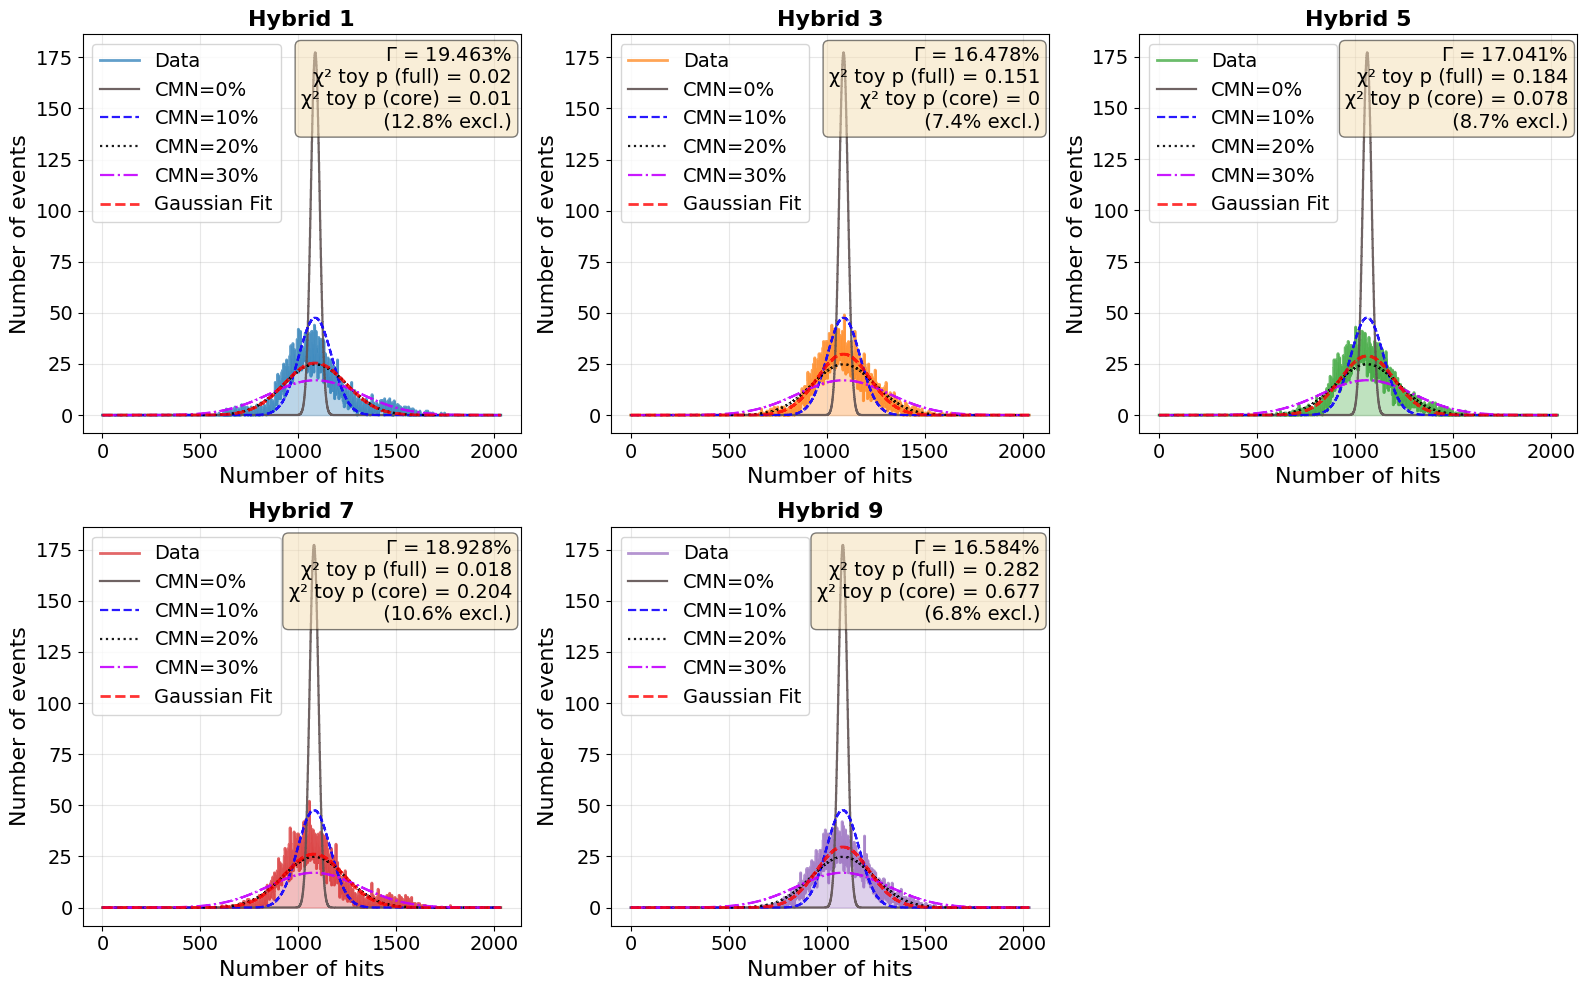


TOY CHI2 GOODNESS-OF-FIT DISTRIBUTIONS (Hybrid L)

Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0006_fig1.pdf


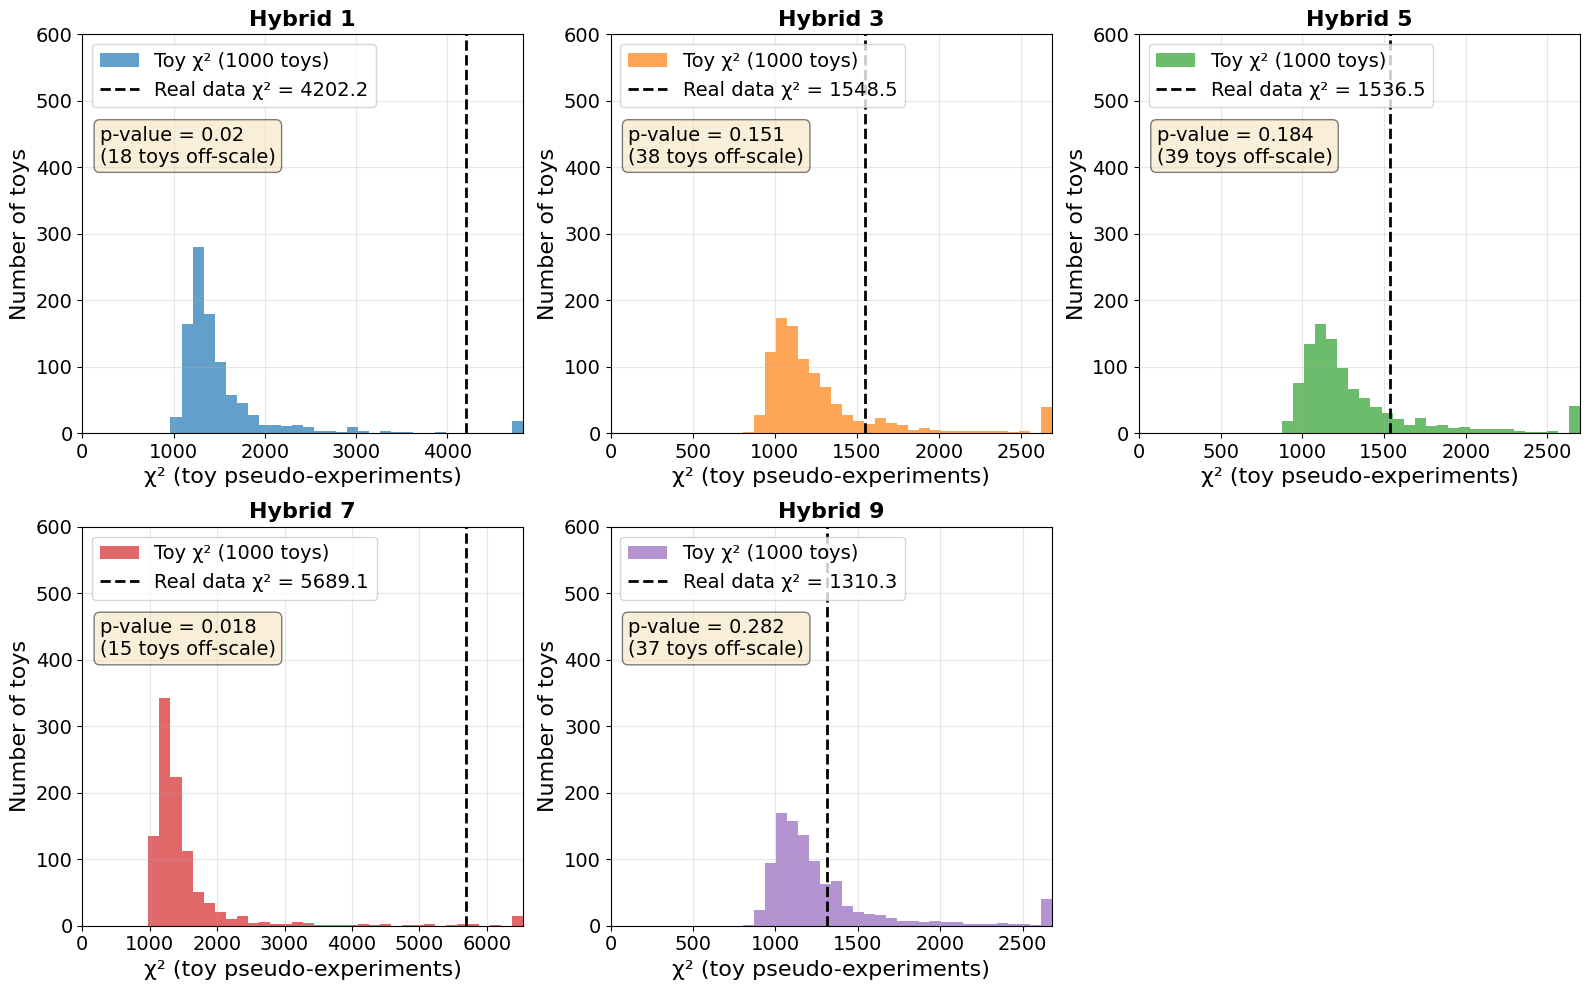


CORE-REGION TOY CHI2 GOODNESS-OF-FIT DISTRIBUTIONS (Hybrid L)

Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0007_fig1.pdf


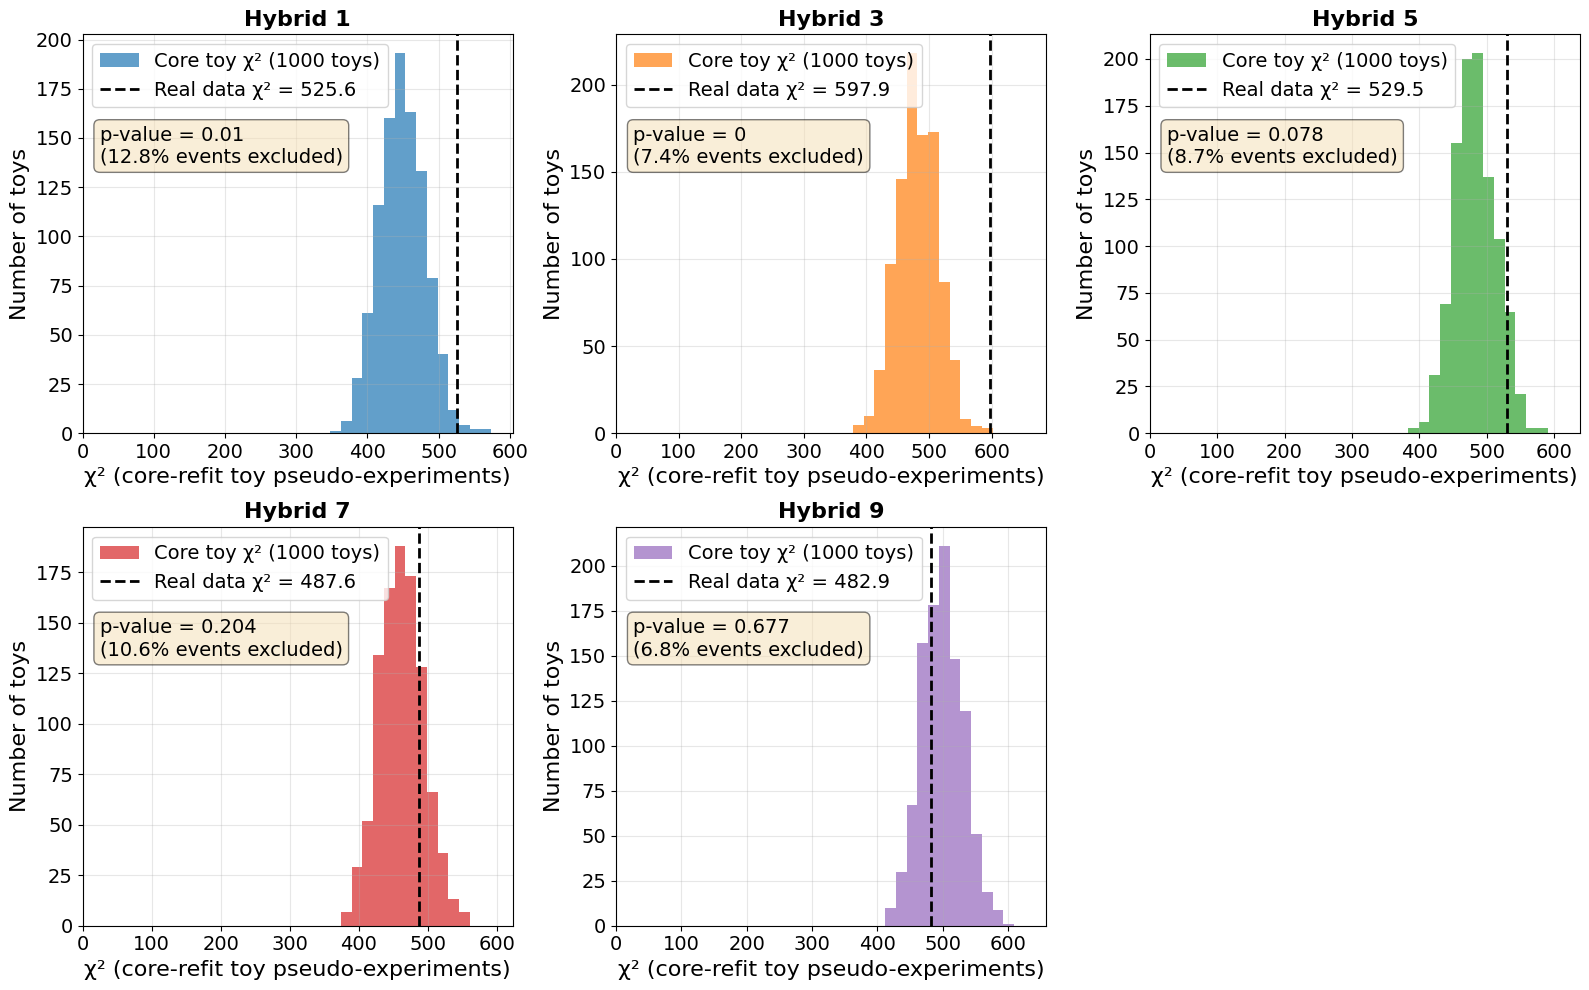


COMPARISON SUMMARY
  Hybrid      Mean    Std Dev  Entries  Expected Std (mu,n)    Fit Std  Delta Std (fit-exp)  Chi2 (real)  Chi2 (toy mean)  Chi2 toy p-value  Core Chi2 (real)  Core Chi2 p-value  Core events excl. (%)   Peak  Peak Height
Hybrid 1 1085.9185 156.551743     2033            22.491768 156.550222           134.058453  4202.163998      1600.044351             0.020        525.639219              0.010                  12.82 1082.0         44.0
Hybrid 3 1085.8943 133.748014     2033            22.491805 133.746938           111.255133  1548.495211      1606.886855             0.151        597.863129              0.000                   7.45 1090.0         49.0
Hybrid 5 1061.9370 138.072815     2033            22.521867 138.072035           115.550168  1536.531537      1619.137865             0.184        529.492692              0.078                   8.72 1003.0         43.0
Hybrid 7 1079.7052 152.487377     2033            22.500777 152.487092           129.986315  5689.09

In [132]:
# Histogram fitting and peak finding analysis using ROOT likelihood fit
fit_results = run_root_likelihood_fit(histogram_data, "Hybrid L")

In [133]:
#faire likelihood fit avec ROOT ou on suppose une distr de poisson a chaque bin ou rebinner pour pouvoir utiliser chi2.
#penser a cbc + ANALYSER QUEUE DE DISTRIBUTION
# data contains lots of low counts where traditional $\chi^2$ approximations break down
#hybrid 1 and 7 have higher sigma indicating more CM noise


FIT DIAGNOSTICS: POISSON-LIKELIHOOD RESIDUAL ANALYSIS
Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0008_fig1.pdf


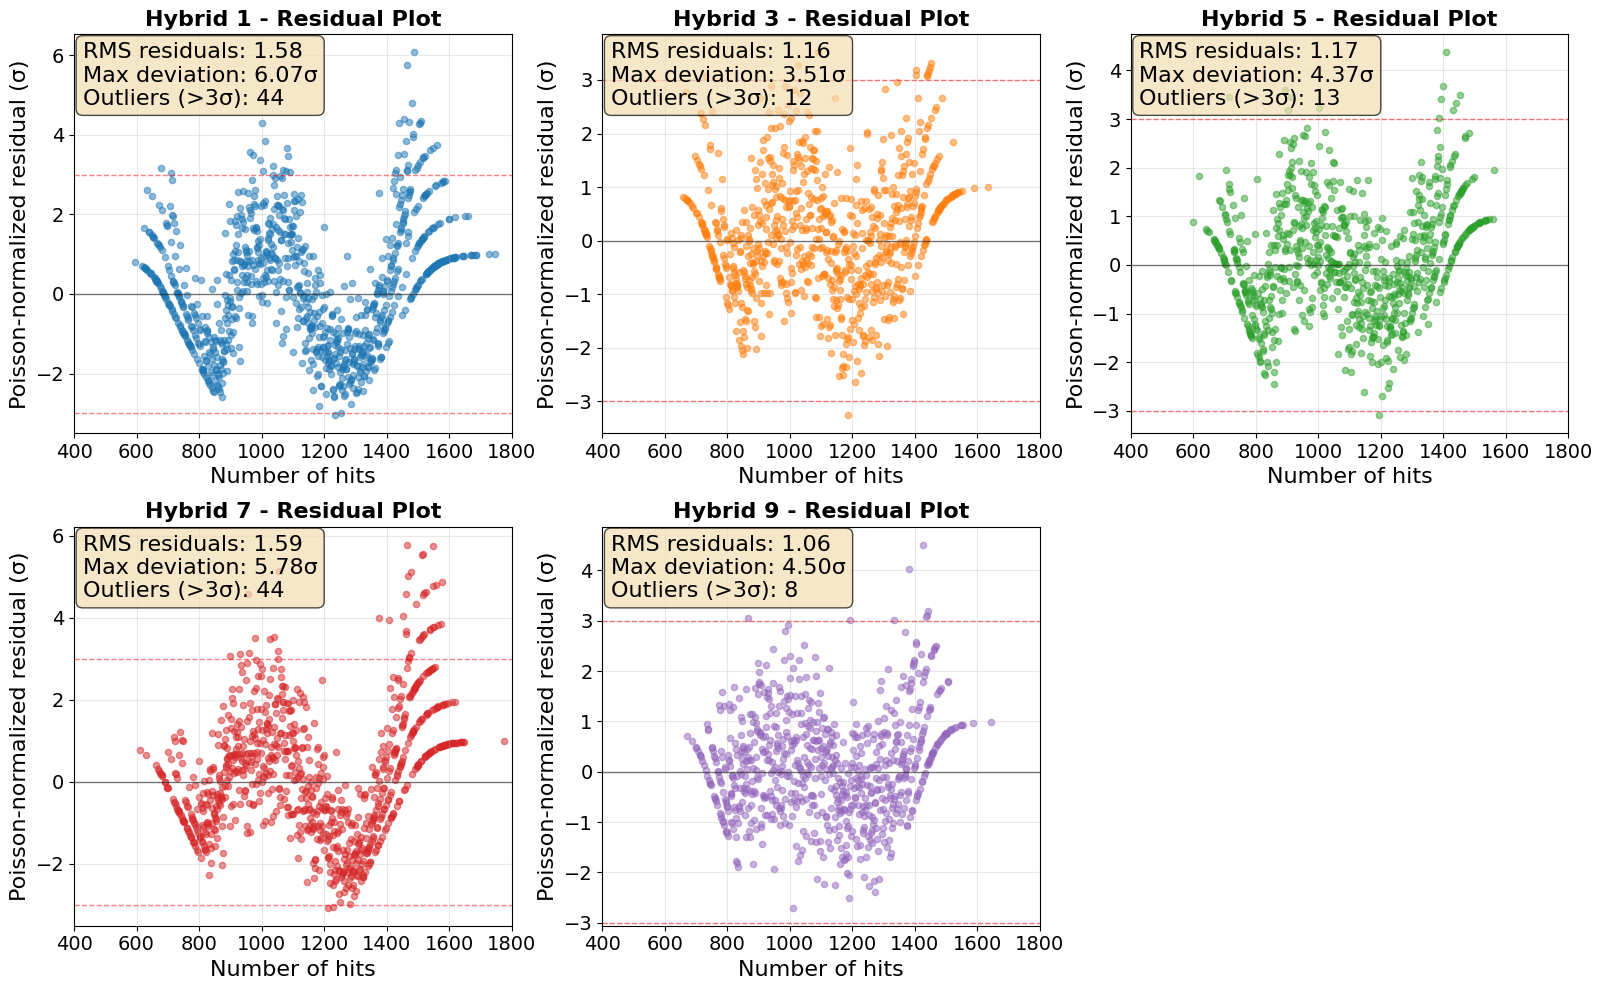


INTERPRETATION (LIKELIHOOD FIT):

For a ROOT Poisson-likelihood fit with bin-integrated expectations, prioritize these checks:
1) Convergence status: status = 0 is the expected successful fit.
2) Residual shape: residuals should fluctuate around 0 without systematic trends.
3) Outlier rate: only a small fraction of bins should exceed ±3σ.

A converged likelihood fit can still be mismodelled if residuals show structure.
Residual plots tell you WHERE the Gaussian model is insufficient.



In [134]:
# Detailed fit diagnostics: Poisson-likelihood residual analysis
print("\n" + "=" * 80)
print("FIT DIAGNOSTICS: POISSON-LIKELIHOOD RESIDUAL ANALYSIS")
print("=" * 80)


fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]

for idx, (hybrid_name, data) in enumerate(histogram_data.items()):
    ax = axes[idx]

    bin_centers = data["bin_centers"]
    bin_contents = data["bin_contents"]

    # Get fit results
    if hybrid_name not in fit_results or fit_results[hybrid_name]["popt"] is None:
        ax.text(0.5, 0.5, f"{hybrid_name}\nNo fit available", ha="center", va="center")
        ax.axis("off")
        continue

    fit_info = fit_results[hybrid_name]
    fit_status = fit_info.get("fit_status", None)
    expected_counts = fit_info.get("expected_counts")
    if expected_counts is None:
        fit_func = fit_info["fit_func"]
        _, _, expected_counts = expected_counts_from_fit(fit_func, data["histogram"])

    expected_counts = np.asarray(expected_counts, dtype=float)
    residuals = bin_contents - expected_counts
    sigma = np.sqrt(np.maximum(expected_counts, 1.0))
    normalized_residuals = residuals / sigma

    # Plot residuals
    finite_mask = bin_contents > 0
    ax.scatter(bin_centers[finite_mask], normalized_residuals[finite_mask],
              alpha=0.5, s=20, color=colors[idx])

    # Add reference lines
    ax.axhline(y=0, color="black", linestyle="-", linewidth=1, alpha=0.5)
    ax.axhline(y=3, color="red", linestyle="--", linewidth=1, alpha=0.5)
    ax.axhline(y=-3, color="red", linestyle="--", linewidth=1, alpha=0.5)

    # Statistics on residuals
    residuals_nz = normalized_residuals[finite_mask]
    rms_residuals = np.sqrt(np.mean(residuals_nz ** 2))
    max_residual = np.max(np.abs(residuals_nz))
    outliers = np.sum(np.abs(residuals_nz) > 3)

    ax.text(
        0.02,
        0.98,
        f"RMS residuals: {rms_residuals:.2f}\n"
        f"Max deviation: {max_residual:.2f}σ\nOutliers (>3σ): {outliers}",
        transform=ax.transAxes,
        va="top",
        fontsize=16,
        bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.7),
    )

    ax.set_xlabel("Number of hits", fontsize=16)
    ax.set_ylabel("Poisson-normalized residual (σ)", fontsize=16)
    ax.set_xlim(400, 1800)  # Adjust x-axis range for better visibility
    ax.set_title(f"{hybrid_name} - Residual Plot", fontsize=16, fontweight="bold")
    ax.tick_params(axis='both', labelsize=14) 
    ax.grid(alpha=0.3)

axes[-1].axis("off")
plt.tight_layout()
plt.show()

print("\n" + "=" * 80)
print("INTERPRETATION (LIKELIHOOD FIT):")
print("=" * 80)
print("""
For a ROOT Poisson-likelihood fit with bin-integrated expectations, prioritize these checks:
1) Convergence status: status = 0 is the expected successful fit.
2) Residual shape: residuals should fluctuate around 0 without systematic trends.
3) Outlier rate: only a small fraction of bins should exceed ±3σ.

A converged likelihood fit can still be mismodelled if residuals show structure.
Residual plots tell you WHERE the Gaussian model is insufficient.
""")
print("=" * 80)

In [135]:
# In a statistically ideal fit, residuals should be randomly scattered around the zero horizontal line with no discernible shape. 
# Systematic Structures: All five plots show clear, non-random "W" or "M" shaped curved patterns. This indicates that the mathematical model is consistently underestimating or overestimating the data in specific regions, such as the "shoulders" or the peak of the distribution.
# The most striking feature across all plots is the non-random, "W-shaped" pattern.
# The Peak: The residuals dip significantly below zero at the center of the distribution (the peak). This means your model is overestimating the height of the noise peak.
# -> sol : The Area Constraint: Because your fit is constrained by the total number of entries (fixed at 2033 for every hybrid), the model must "put" those counts somewhere. If it fails to capture the broad shoulders of the real noise distribution, it compensates by stacking those counts into a taller, narrower peak.
# -> also sol : When your likelihood fit encounters these high-hit events (up to 1800 hits in some plots), it attempts to stretch to accommodate them. This stretching often forces the central part of the function to over-peak to maintain the overall statistical balance of the distribution.
# The Shoulders: The residuals rise above zero on either side of the peak. This means your model is underestimating the "shoulders" of the noise distribution.
# Hybrid 1 and Hybrid 7 have 48 and 47 outliers respectively (events $>3\sigma$ from the fit). This confirms that the "tails" of your noise are much heavier than the model accounts for.
# A good fit should have an RMS residual near 1.0. Hybrid 1 (1.54) and Hybrid 7 (1.57) are significantly higher, indicating the model is a poor representation of the data.

# Verdict: Your residuals show that the noise is not a simple Gaussian. You have successfully identified a systematic feature of the detector's common mode noise that a simple model cannot explain.
# In particle detectors, common mode noise is rarely a perfectly simple Gaussian process. It is often the sum of several factors: Intrinsic Thermal Noise: Usually Gaussian and Pickup/Interference: Often creates "boxier" or skewed distributions.

In [136]:
# Study of gamma of hybrid L

In [137]:
# Recompute Gamma (Eq.19/20) and common-mode noise for hybrids 1,3,5,7,9
import math
import numpy as np
import pandas as pd
import ROOT

root_file = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root", "READ")

hybrid_specs = [
    ("OpticalGroup_0", "Hybrid_1", 1),
    ("OpticalGroup_1", "Hybrid_3", 3),
    ("OpticalGroup_2", "Hybrid_5", 5),
    ("OpticalGroup_3", "Hybrid_7", 7),
    ("OpticalGroup_4", "Hybrid_9", 9),
]

if 'fit_results' not in globals() or not isinstance(fit_results, dict):
    raise RuntimeError("Run the ROOT likelihood fit cell first to create 'fit_results'.")

def compute_gamma(hist, mean_fit, std_fit):
    n_channels = int(hist.GetNbinsX() - 1)
    mean_hits = float(mean_fit)
    variance_hits = float(std_fit) ** 2
    alpha_tilde = 2.0 * math.pi * (variance_hits - mean_hits * (1.0 - mean_hits / n_channels)) / (n_channels * (n_channels - 1))
    sin_alpha = math.sin(alpha_tilde)
    gamma_sq = sin_alpha / (1.0 - sin_alpha) if (1.0 - sin_alpha) != 0 else 0.0
    gamma = math.sqrt(max(gamma_sq, 0.0))
    return gamma

# This function performs sigma-clipping on a list of values to compute a robust mean and standard deviation.
def sigma_clipped_stats(values, sigma, maxiters):
    vals = np.asarray(values, dtype=float).copy()
    vals = vals[np.isfinite(vals)]
    if vals.size == 0:
        return (np.nan, np.nan, 0, 0, 0)
    n_initial = vals.size
    for _ in range(maxiters):
        if vals.size <= 1:
            break
        m = vals.mean()
        s = vals.std(ddof=1)
        if s == 0.0:
            break
        keep = np.abs(vals - m) <= sigma * s
        if keep.sum() == vals.size:
            break
        vals = vals[keep]
    n_rejected = n_initial - vals.size
    return (float(vals.mean()) if vals.size>0 else np.nan, float(vals.std(ddof=1)) if vals.size>1 else 0.0, int(vals.size), int(n_rejected), int(n_initial))

results = []
for og_name, hybrid_name, hybrid_id in hybrid_specs:
    cm_path = f"Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/{og_name}/{hybrid_name}/D_B(0)_O({hybrid_id // 2})_CommonNoiseHits_OccupancyDriven_Hybrid({hybrid_id})"
    strip_path = f"Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/{og_name}/{hybrid_name}/D_B(0)_O({hybrid_id // 2})_StripChannelNoise_Hybrid({hybrid_id})"
    cm_hist = root_file.Get(cm_path)
    strip_hist = root_file.Get(strip_path)
    if not cm_hist or not strip_hist:
        print(f"[SKIP] Missing hist for {hybrid_name}")
        continue
    fit_key = hybrid_name.replace('_', ' ')
    fit_info = fit_results.get(fit_key) or fit_results.get(hybrid_name)
    if fit_info is None:
        print(f"[SKIP] Missing fit results for {hybrid_name}")
        continue
    gamma = compute_gamma(cm_hist, fit_info['mean_fit'], fit_info['std_fit'])
    # extract per-channel noise values
    vals = []
    for i in range(1, strip_hist.GetNbinsX()+1):
        v = float(strip_hist.GetBinContent(i))
        if np.isfinite(v) and v>0:
            vals.append(v)
    mean_clipped, std_clipped, n_kept, n_rej, n_init = sigma_clipped_stats(vals, sigma=3.0, maxiters=5)
    cm_val = gamma * mean_clipped
    results.append({
        'Hybrid': f'Hybrid_{hybrid_id}',
        'Gamma': gamma,
        'sigma_single_clipped_mean': mean_clipped,
        'sigma_single_clipped_std': std_clipped,
        'n_initial': n_init,
        'n_rejected': n_rej,
        'CM_VcTh': cm_val,
    })

df = pd.DataFrame(results)
print(df.to_string(index=False, formatters={
    'Gamma': '{:.6f}'.format,
    'sigma_single_clipped_mean': '{:.4f}'.format,
    'sigma_single_clipped_std': '{:.4f}'.format,
    'CM_VcTh': '{:.4f}'.format,
}))

  Hybrid    Gamma sigma_single_clipped_mean sigma_single_clipped_std  n_initial  n_rejected CM_VcTh
Hybrid_1 0.194630                    5.4331                   0.3954       2032           3  1.0574
Hybrid_3 0.164781                    5.3981                   0.4098       2032           0  0.8895
Hybrid_5 0.170411                    5.3102                   0.3646       2032           1  0.9049
Hybrid_7 0.189283                    5.5045                   0.3822       2032           0  1.0419
Hybrid_9 0.165838                    5.3270                   0.3776       2032           0  0.8834


In [138]:
# I suppose the average bin content across channels is a good estimate of the single-channel random noise and I only clip absurd values.


Per-hybrid values:
  Hybrid  CM_VcTh  CM_err
Hybrid_1   1.0574  0.0770
Hybrid_3   0.8895  0.0675
Hybrid_5   0.9049  0.0621
Hybrid_7   1.0419  0.0723
Hybrid_9   0.8834  0.0626
Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0009_fig1.pdf


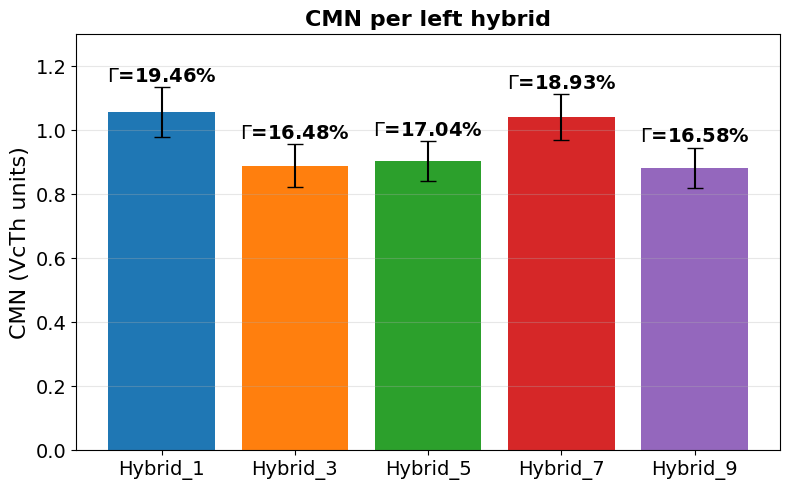

In [139]:
# Summary bar plot: one CM_VcTh value per hybrid (1,3,5,7,9)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if 'df' not in globals() or not isinstance(df, pd.DataFrame) or df.empty:
    raise RuntimeError("Run the previous CM computation cells first to create 'df'.")

wanted = ['Hybrid_1','Hybrid_3','Hybrid_5','Hybrid_7','Hybrid_9']
summary = (
    df[df['Hybrid'].isin(wanted)]
    .groupby('Hybrid', as_index=False)
    .agg({
        'CM_VcTh': 'mean',
        'Gamma': 'mean',
        'sigma_single_clipped_std': 'mean'
    })
)
if summary.empty:
    raise RuntimeError('No data for requested hybrids found in df.')

# propagate error
if 'sigma_single_clipped_std' in summary.columns and 'Gamma' in summary.columns:
    summary['CM_err'] = np.abs(summary['Gamma'] * summary['sigma_single_clipped_std'])
else:
    summary['CM_err'] = np.nan

# Plot
fig, ax = plt.subplots(figsize=(8, 5))
inds = np.arange(len(summary))
heights = summary['CM_VcTh'].to_numpy()
errs = summary['CM_err'].to_numpy()
labels = summary['Hybrid'].tolist()

bars = ax.bar(inds, heights, yerr=errs, capsize=6, color=['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd'])
# Annotate each bar with Gamma in percent (Gamma * 100%)
try:
    yrange = float(np.max(heights) - np.min(heights))
except Exception:
    yrange = 1.0
offset = 0.02 * (yrange if yrange > 0 else 1.0)
for rect, g, e in zip(bars, summary['Gamma'].to_numpy(), errs):
    label = f"{g * 100:.2f}%"
    h = rect.get_height()
    # place label above the error bar tip when error is available
    try:
        err_val = float(e)
    except Exception:
        err_val = 0.0
    top = h + abs(err_val)
    y = top + offset
    ax.text(rect.get_x() + rect.get_width() / 2., y, rf'$\Gamma$={label}', ha='center', va='bottom', fontsize=14, fontweight='bold')
ax.set_xticks(inds)
ax.set_xticklabels(labels,fontsize=16)
ax.set_ylabel('CMN (VcTh units)',fontsize=16)
ax.set_title('CMN per left hybrid',fontsize=16,fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.tick_params(axis='both', labelsize=14) 
ax.set_ylim(0, 1.3)
plt.tight_layout()

print('\nPer-hybrid values:')
print(summary[['Hybrid','CM_VcTh','CM_err']].to_string(index=False, float_format='%.4f'))
plt.show()


In [140]:
#Study of the tail of the distribution for hybrid L

In [141]:
import ROOT
import numpy as np
import matplotlib.pyplot as plt

# Ouvrir seulement les fichiers nécessaires
inFile2bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise2bot1mod = inFile2bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_0/Hybrid_1/D_B(0)_O(0)_CommonNoiseHits_SigmaNoise_3.00_Hybrid(1)")

inFile3bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise3bot1mod = inFile3bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_1/Hybrid_3/D_B(0)_O(1)_CommonNoiseHits_SigmaNoise_3.00_Hybrid(3)")

inFile4bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ")
Noise4bot1mod = inFile4bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_2/Hybrid_5/D_B(0)_O(2)_CommonNoiseHits_SigmaNoise_3.00_Hybrid(5)")

inFile5bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise5bot1mod = inFile5bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_3/Hybrid_7/D_B(0)_O(3)_CommonNoiseHits_SigmaNoise_3.00_Hybrid(7)")

inFile6bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise6bot1mod = inFile6bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_4/Hybrid_9/D_B(0)_O(4)_CommonNoiseHits_SigmaNoise_3.00_Hybrid(9)")

In [142]:
# Extract bin-by-bin data from the five 2S hybrid histograms
hybrid_histograms = [
    ("Hybrid 1", Noise2bot1mod),
    ("Hybrid 3", Noise3bot1mod),
    ("Hybrid 5", Noise4bot1mod),
    ("Hybrid 7", Noise5bot1mod),
    ("Hybrid 9", Noise6bot1mod),
]

histogram_data = {}

print("\n" + "=" * 80)
print("HISTOGRAM BIN-BY-BIN DATA EXTRACTION")
print("=" * 80)

for hybrid_name, hist in hybrid_histograms:
    if hist is None:
        print(f"\n[SKIP] {hybrid_name}: histogram not found")
        continue
    
    # Extract basic statistics
    entries = int(hist.GetEntries())
    mean = float(hist.GetMean())
    std_dev = float(hist.GetStdDev())
    rms = float(hist.GetRMS())
    
    print(f"\n{hybrid_name}:")
    print(f"  Entries: {entries}")
    print(f"  Mean: {mean:.4f}")
    print(f"  Std Dev: {std_dev:.4f}")
    print(f"  RMS: {rms:.4f}")
    
    # Extract bin-by-bin data
    # ROOT histograms are 1-indexed (bin 0 is underflow, bin N+1 is overflow)
    bin_centers = []
    bin_contents = []
    
    for i in range(1, hist.GetNbinsX() + 1):
        bin_centers.append(hist.GetXaxis().GetBinCenter(i))
        bin_contents.append(hist.GetBinContent(i))
    
    histogram_data[hybrid_name] = {
        "entries": entries,
        "mean": mean,
        "std_dev": std_dev,
        "rms": rms,
        "bin_centers": np.array(bin_centers),
        "bin_contents": np.array(bin_contents),
        "histogram": hist,
    }


HISTOGRAM BIN-BY-BIN DATA EXTRACTION

Hybrid 1:
  Entries: 2033
  Mean: 3.3400
  Std Dev: 2.9814
  RMS: 2.9814

Hybrid 3:
  Entries: 2033
  Mean: 3.5944
  Std Dev: 2.9058
  RMS: 2.9058

Hybrid 5:
  Entries: 2033
  Mean: 3.7508
  Std Dev: 2.9707
  RMS: 2.9707

Hybrid 7:
  Entries: 2033
  Mean: 3.3292
  Std Dev: 3.3968
  RMS: 3.3968

Hybrid 9:
  Entries: 2033
  Mean: 3.1541
  Std Dev: 2.5670
  RMS: 2.5670


In [143]:
# Add Gaussian fits to each histogram on the canvas
import ROOT
import numpy as np
from scipy.stats import norm

# Threshold used by the "SigmaNoise_3.00" histograms below -- keep this in sync with that name.
n_sigma_threshold = 3.0

print("\n" + "=" * 80)
print("ADDING GAUSSIAN FITS TO EACH HISTOGRAM ON CANVAS")
print("=" * 80)

# Create a new canvas with fits
canvas_fit = ROOT.TCanvas("hybrids_sigma3_with_fits", "Hybrid Common-Mode Noise with Fits (3σ threshold)",1200,400 * rows)
canvas_fit.Divide(cols, rows)

fit_results_canvas = {}
colors_fit = [ROOT.kBlue, ROOT.kRed, ROOT.kGreen+2, ROOT.kMagenta, ROOT.kCyan, 
              ROOT.kOrange+7, ROOT.kYellow+2, ROOT.kSpring+9]

# Keep the fit order aligned with the histogram_data built in this cell
hybrid_names = list(histogram_data.keys())

for i, hybrid_name in enumerate(hybrid_names):
    pad_num = i + 1
    canvas_fit.cd(pad_num)
    ROOT.gPad.SetLeftMargin(0.12)
    ROOT.gPad.SetBottomMargin(0.12)
    ROOT.gPad.SetGrid()
    ROOT.gPad.SetLogy(1)
    
    hist_data = histogram_data.get(hybrid_name)
    if hist_data is None or hist_data["histogram"] is None:
        ROOT.TText(0.2, 0.5, f"No data for {hybrid_name}").Draw()
        continue
    
    hist = hist_data["histogram"]
    
    # Style the histogram
    hist.SetLineColor(colors_fit[i % len(colors_fit)])
    hist.SetLineWidth(2)
    hist.SetFillColor(colors_fit[i % len(colors_fit)])
    hist.SetFillStyle(3004)
    hist.SetTitle(hybrid_name)
    hist.GetXaxis().SetTitle("Number of hits (3σ above noise)")
    hist.GetXaxis().SetRangeUser(0.0, 50.0)
    hist.GetYaxis().SetTitle("Number of events")
    hist.GetXaxis().SetTitleSize(0.05)
    hist.GetYaxis().SetTitleSize(0.05)
    hist.GetXaxis().SetLabelSize(0.04)
    hist.GetYaxis().SetLabelSize(0.04)
    
    # Draw histogram
    hist.Draw("HIST")
    
    # Perform Gaussian fit
    x_min = float(hist.GetXaxis().GetXmin())
    x_max = float(hist.GetXaxis().GetXmax())
    
    # Find peak for initial guess
    peak_idx = hist.GetMaximumBin()
    peak_x = hist.GetXaxis().GetBinCenter(peak_idx)
    peak_y = hist.GetBinContent(peak_idx)
    
    # Create fit function
    safe_name = "".join(ch if ch.isalnum() else "_" for ch in f"fit_hybrids_{hybrid_name}")
    fit_func = ROOT.TF1(safe_name, "gaus", x_min, x_max)
    
    # Set initial parameters
    mean_guess = hist_data["mean"]
    std_guess = hist_data["std_dev"]
    amplitude_guess = max(peak_y, 1.0)
    
    fit_func.SetParameters(amplitude_guess, mean_guess, std_guess)
    fit_func.SetParLimits(0, 0.0, max(amplitude_guess * 10.0, 1.0))
    fit_func.SetParLimits(1, x_min, x_max)
    fit_func.SetParLimits(2, 1e-6, max(x_max - x_min, std_guess * 10.0))
    
    # Perform fit
    try:
        fit_result = hist.Fit(fit_func, "LQRS")
        fit_status = int(fit_result)
        
        amplitude_fit = float(fit_func.GetParameter(0))
        mean_fit = float(fit_func.GetParameter(1))
        std_fit = abs(float(fit_func.GetParameter(2)))
        
        # Get parameter errors
        amplitude_err = float(fit_func.GetParError(0))
        mean_err = float(fit_func.GetParError(1))
        std_err = abs(float(fit_func.GetParError(2)))
        
        fit_results_canvas[hybrid_name] = {
            "amplitude": amplitude_fit,
            "amplitude_err": amplitude_err,
            "mean": mean_fit,
            "mean_err": mean_err,
            "std": std_fit,
            "std_err": std_err,
            "status": fit_status,
            "fit_func": fit_func,
        }
        
        # Draw fit function in orange
        #fit_func.SetLineColor(ROOT.kOrange)
        #fit_func.SetLineWidth(2)
        #fit_func.SetLineStyle(7)  # dashed line
        #fit_func.Draw("SAME")
        
        # Fit and overlay a theoretical Poisson distribution for the no-CMN expectation
        # Cap the evaluation domain well below where TMath::Gamma(x+1) overflows to inf (~x>170);
        # a TF1 that hits NaN/Inf anywhere in its declared range fails to draw at all, even in the
        # (perfectly finite) low-x region actually visible on the plot.
        poisson_x_max = min(x_max, 100.0)
        poisson_name = "".join(ch if ch.isalnum() else "_" for ch in f"poisson_hybrids_{hybrid_name}")
        poisson_func = ROOT.TF1(poisson_name, "[0] * TMath::Exp(-[1]) * TMath::Power([1], x) / TMath::Gamma(x + 1.0)", x_min, poisson_x_max)
        poisson_func.SetNpx(500)
        poisson_norm_guess = max(float(hist.Integral()), 1.0)
        poisson_lambda_guess = max(mean_guess, 1e-6)
        poisson_func.SetParameter(0, poisson_norm_guess)
        poisson_func.FixParameter(0, poisson_norm_guess)
        poisson_func.SetParameter(1, poisson_lambda_guess)
        poisson_func.SetParLimits(1, 1e-6, max(x_max, poisson_lambda_guess * 10.0))
        
        try:
            poisson_result = hist.Fit(poisson_func, "LQRS")
            poisson_status = int(poisson_result)
            
            poisson_lambda_fit = float(poisson_func.GetParameter(1))
            poisson_lambda_err = float(poisson_func.GetParError(1))
            
            poisson_func.SetLineColor(ROOT.kBlack)
            poisson_func.SetLineWidth(2)
            #poisson_func.SetLineStyle(7)
            poisson_func.Draw("SAME")
            
            fit_results_canvas[hybrid_name]["poisson"] = {
                "norm": poisson_norm_guess,
                "norm_err": 0.0,
                "lambda": poisson_lambda_fit,
                "lambda_err": poisson_lambda_err,
                "status": poisson_status,
                "fit_func": poisson_func,
            }
            
            print(f"  Poisson Norm: {poisson_norm_guess:.4f} (fixed)")
            print(f"  Poisson Lambda: {poisson_lambda_fit:.4f} ± {poisson_lambda_err:.4f}")

            # Theoretical Poisson expectation with NO common-mode noise: if every strip's noise
            # were an independent Gaussian, the number of channels crossing a pure n_sigma_threshold
            # would be Poisson with lambda = n_channels * P(Z > n_sigma_threshold) (one-sided Gaussian
            # tail). Unlike poisson_func above, this lambda is NOT fit -- it's fixed from the physical
            # channel count and the threshold, so the gap to the data/fit shows the CMN excess.
            n_channels = int(hist.GetNbinsX()) - 1
            lambda_theory = n_channels * norm.sf(n_sigma_threshold)
            theory_name = "".join(ch if ch.isalnum() else "_" for ch in f"poisson_theory_hybrids_{hybrid_name}")
            theory_func = ROOT.TF1(theory_name, "[0] * TMath::Exp(-[1]) * TMath::Power([1], x) / TMath::Gamma(x + 1.0)", x_min, poisson_x_max)
            theory_func.SetNpx(500)
            theory_func.FixParameter(0, poisson_norm_guess)
            theory_func.FixParameter(1, lambda_theory)
            theory_func.SetLineColor(ROOT.kGray + 2)
            theory_func.SetLineWidth(2)
            theory_func.SetLineStyle(2)
            theory_func.Draw("SAME")

            fit_results_canvas[hybrid_name]["poisson_theory"] = {
                "n_channels": n_channels,
                "lambda": lambda_theory,
                "fit_func": theory_func,
            }

            print(f"  Poisson (theory, no CMN): n_channels={n_channels}, lambda={lambda_theory:.4f}")

            legend_fit = ROOT.TLegend(0.30, 0.72, 0.95, 0.92)
            legend_fit.AddEntry(hist, "Data (3σ hits)", "f")
            legend_fit.AddEntry(poisson_func, "Poisson fit (λ = data mean)", "l")
            legend_fit.AddEntry(theory_func, "Poisson theory, no CMN", "l")
            legend_fit.SetTextSize(0.04)
            legend_fit.SetFillStyle(0)
            legend_fit.SetBorderSize(0)
            legend_fit.Draw()
        except Exception as e:
            print(f"  Poisson fit failed - {e}")
            fit_results_canvas[hybrid_name]["poisson"] = {"status": -1, "error": str(e)}
        
        # Add legend
        #legend = ROOT.TLegend(0.55, 0.7, 0.95, 0.95)
        #legend.AddEntry(hist, "Data", "f")
        #legend.AddEntry(fit_func, "Gaussian Fit", "l")
        #if fit_results_canvas[hybrid_name].get("poisson", {}).get("status", -1) >= 0:
        #    legend.AddEntry(poisson_func, "Poisson fit", "l")
        #legend.SetTextSize(0.04)
        #legend.SetFillStyle(0)
        #legend.Draw()
        
        # Print fit results with parameter errors
        print(f"\n{hybrid_name}:")
        print(f"  Fit Status: {fit_status}")
        print(f"  Amplitude: {amplitude_fit:.4f} ± {amplitude_err:.4f}")
        print(f"  Mean: {mean_fit:.4f} ± {mean_err:.4f}")
        print(f"  Std Dev: {std_fit:.4f} ± {std_err:.4f}")
        
    except Exception as e:
        print(f"\n{hybrid_name}: Fit failed - {e}")
        fit_results_canvas[hybrid_name] = {"status": -1, "error": str(e)}

# Hide empty pads
for i in range(len(hybrid_names), rows * cols):
    canvas_fit.cd(i + 1)
    ROOT.gPad.Draw()

canvas_fit.Update()
canvas_fit.Draw()

print("\n" + "=" * 80)
print("FITTING COMPLETE")
print("=" * 80)



ADDING GAUSSIAN FITS TO EACH HISTOGRAM ON CANVAS
  Poisson Norm: 10000.0000 (fixed)
  Poisson Lambda: 3.3400 ± 0.0183
  Poisson (theory, no CMN): n_channels=2033, lambda=2.7443

Hybrid 1:
  Fit Status: 0
  Amplitude: 1641.2179 ± 20.1015
  Mean: -0.5000 ± 0.0258
  Std Dev: 4.8615 ± 0.0344
  Poisson Norm: 10000.0000 (fixed)
  Poisson Lambda: 3.5944 ± 0.0190
  Poisson (theory, no CMN): n_channels=2033, lambda=2.7443

Hybrid 3:
  Fit Status: 0
  Amplitude: 1438.5500 ± 20.2378
  Mean: 1.0065 ± 0.1466
  Std Dev: 4.3654 ± 0.0742
  Poisson Norm: 10000.0000 (fixed)
  Poisson Lambda: 3.7508 ± 0.0194
  Poisson (theory, no CMN): n_channels=2033, lambda=2.7443

Hybrid 5:
  Fit Status: 0
  Amplitude: 1374.7103 ± 17.9453
  Mean: 1.3647 ± 0.1346
  Std Dev: 4.3574 ± 0.0710
  Poisson Norm: 10000.0000 (fixed)
  Poisson Lambda: 3.3292 ± 0.0182
  Poisson (theory, no CMN): n_channels=2033, lambda=2.7443

Hybrid 7:
  Fit Status: 0
  Amplitude: 1558.7688 ± 19.0917
  Mean: -0.5000 ± 0.0050
  Std Dev: 5.1187 ±

Warning in <TCanvas::Constructor>: Deleting canvas with same name: hybrids_sigma3_with_fits


In [144]:
#STUDY OF HYBRID R of 2S modules(5 hybrids)

In [145]:
import ROOT
import numpy as np
import matplotlib.pyplot as plt

# Ouvrir seulement les fichiers nécessaires
inFile2bot1 = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise2bot1 = inFile2bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_0/Hybrid_0/D_B(0)_O(0)_CommonNoiseHits_OccupancyDriven_Hybrid(0)")

inFile3bot1 = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise3bot1 = inFile3bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_1/Hybrid_2/D_B(0)_O(1)_CommonNoiseHits_OccupancyDriven_Hybrid(2)")

inFile4bot1 = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ")
Noise4bot1 = inFile4bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_2/Hybrid_4/D_B(0)_O(2)_CommonNoiseHits_OccupancyDriven_Hybrid(4)")

inFile5bot1 = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise5bot1 = inFile5bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_3/Hybrid_6/D_B(0)_O(3)_CommonNoiseHits_OccupancyDriven_Hybrid(6)")

inFile6bot1 = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise6bot1 = inFile6bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_4/Hybrid_8/D_B(0)_O(4)_CommonNoiseHits_OccupancyDriven_Hybrid(8)")


In [146]:
# Extract bin-by-bin data from the five 2S hybrid histograms
hybrid_histograms = [
    ("Hybrid 0", Noise2bot1),
    ("Hybrid 2", Noise3bot1),
    ("Hybrid 4", Noise4bot1),
    ("Hybrid 6", Noise5bot1),
    ("Hybrid 8", Noise6bot1),
]

histogram_data = {}

print("\n" + "=" * 80)
print("HISTOGRAM BIN-BY-BIN DATA EXTRACTION")
print("=" * 80)

for hybrid_name, hist in hybrid_histograms:
    if hist is None:
        print(f"\n[SKIP] {hybrid_name}: histogram not found")
        continue
    
    # Extract basic statistics
    entries = int(hist.GetEntries())
    mean = float(hist.GetMean())
    std_dev = float(hist.GetStdDev())
    rms = float(hist.GetRMS())
    
    print(f"\n{hybrid_name}:")
    print(f"  Entries: {entries}")
    print(f"  Mean: {mean:.4f}")
    print(f"  Std Dev: {std_dev:.4f}")
    print(f"  RMS: {rms:.4f}")
    
    # Extract bin-by-bin data
    # ROOT histograms are 1-indexed (bin 0 is underflow, bin N+1 is overflow)
    bin_centers = []
    bin_contents = []
    
    for i in range(1, hist.GetNbinsX() + 1):
        bin_centers.append(hist.GetXaxis().GetBinCenter(i))
        bin_contents.append(hist.GetBinContent(i))
    
    histogram_data[hybrid_name] = {
        "entries": entries,
        "mean": mean,
        "std_dev": std_dev,
        "rms": rms,
        "bin_centers": np.array(bin_centers),
        "bin_contents": np.array(bin_contents),
        "histogram": hist,
    }


HISTOGRAM BIN-BY-BIN DATA EXTRACTION

Hybrid 0:
  Entries: 2033
  Mean: 971.4050
  Std Dev: 120.8231
  RMS: 120.8231

Hybrid 2:
  Entries: 2033
  Mean: 960.8063
  Std Dev: 143.9591
  RMS: 143.9591

Hybrid 4:
  Entries: 2033
  Mean: 924.5986
  Std Dev: 140.4892
  RMS: 140.4892

Hybrid 6:
  Entries: 2033
  Mean: 970.6524
  Std Dev: 137.8660
  RMS: 137.8660

Hybrid 8:
  Entries: 2033
  Mean: 1025.1168
  Std Dev: 136.9457
  RMS: 136.9457



HISTOGRAM FITTING AND PEAK ANALYSIS
DATASET: Hybrid R
Using ROOT binned likelihood fit with Poisson bin statistics.

Hybrid 0:
  Peak found at x=1063.0, height=47.0
  Total peaks detected: 110
  ROOT likelihood fit:
    Status:     0
    Amplitude:  33.0188 ± 0.4044
    Mean:       971.4043 ± 1.2082
    Std Dev:    120.8224 ± 0.8544
    Expected σ: 22.5222 (from μ=971.4050, n=2033)
    Δσ(fit-exp): +98.3002
  Toy chi2 goodness-of-fit diagnostics (full range):
    Bins used:   1937 / 2034
    Used frac:   0.952
    Chi2 (real): 1598.0151
    Chi2 (toy):  1480.7564 ± 6000.7804  (mean ± std over 1000 toys)
    p-value:     0.11
  Core refit (Gaussian refit within [736.5, 1206.5], expected >= 5):
    Amplitude:  33.2741  (full-range fit: 33.0188)
    Mean:       985.9402  (full-range fit: 971.4043)
    Std Dev:    120.2237  (full-range fit: 120.8224)
  Toy chi2 goodness-of-fit diagnostics (core region, expected >= 5):
    Bins used:   469 / 2034  (0.231)
    Events excluded: 578 (5.7800% 

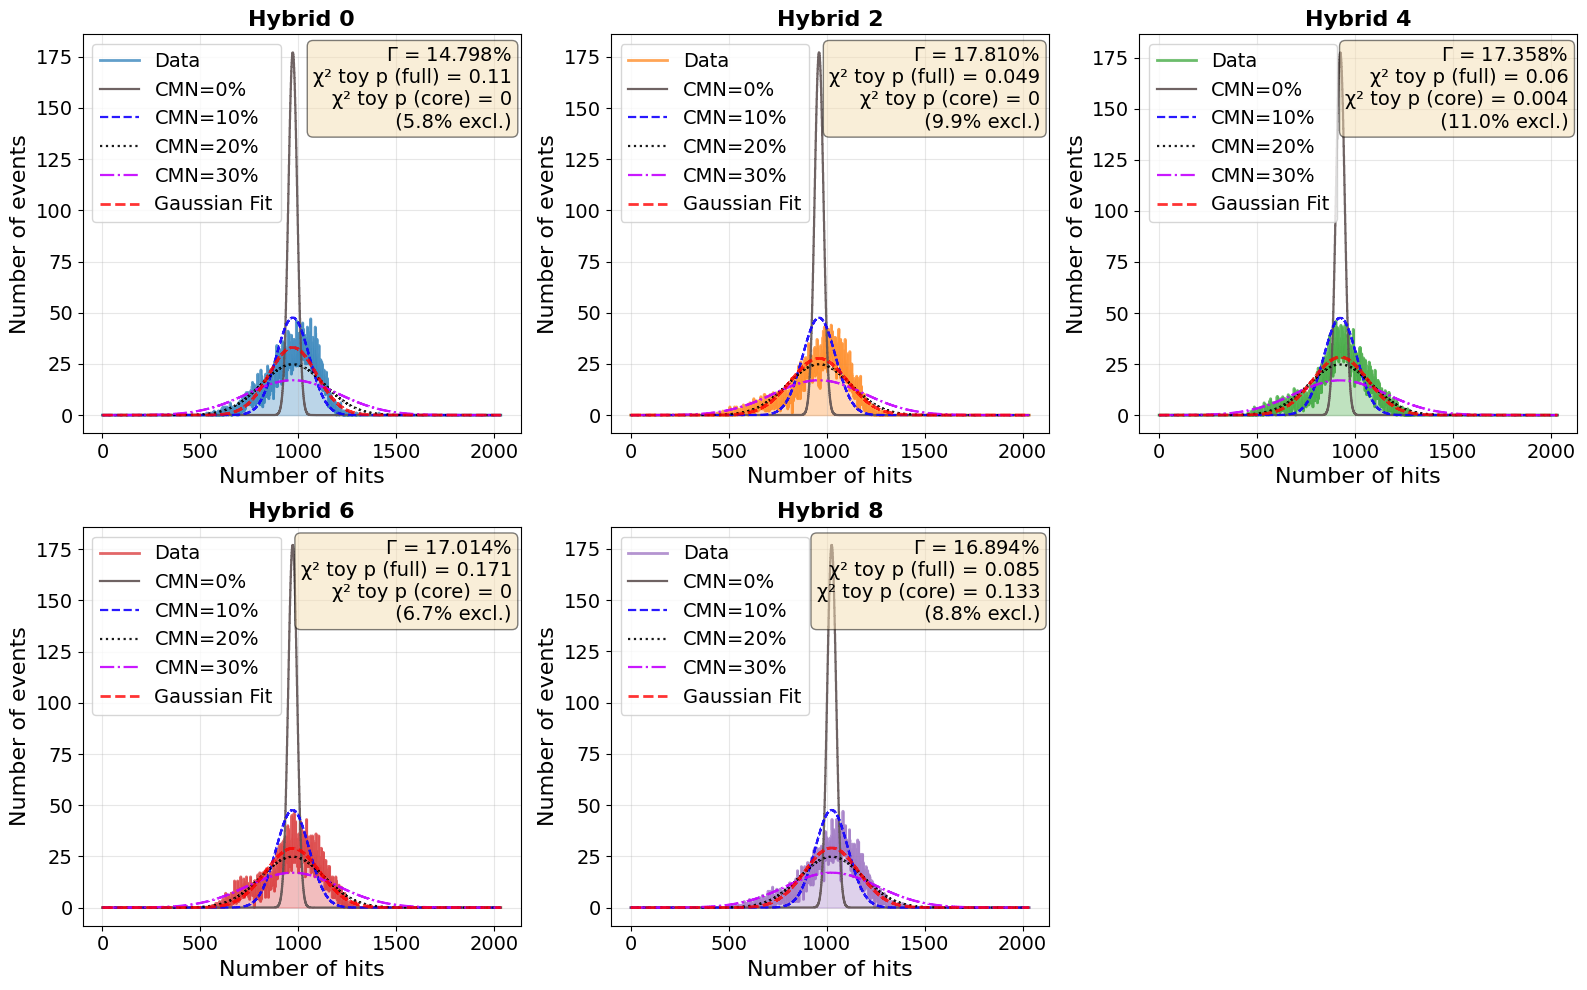


TOY CHI2 GOODNESS-OF-FIT DISTRIBUTIONS (Hybrid R)

Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0011_fig1.pdf


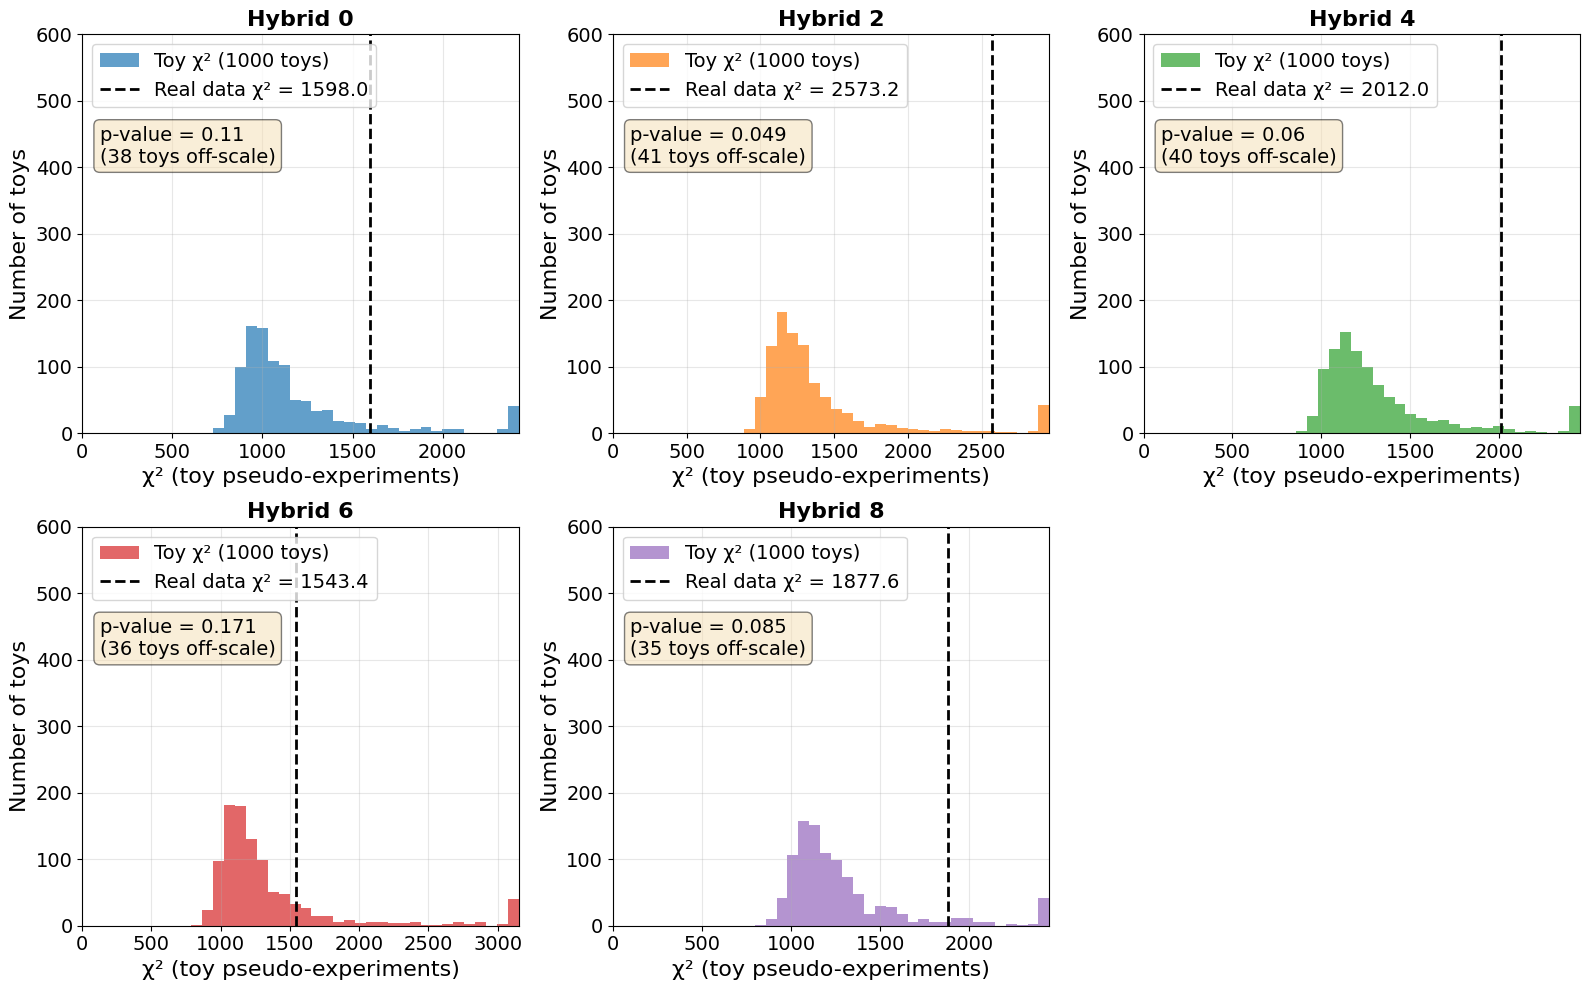


CORE-REGION TOY CHI2 GOODNESS-OF-FIT DISTRIBUTIONS (Hybrid R)

Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0012_fig1.pdf


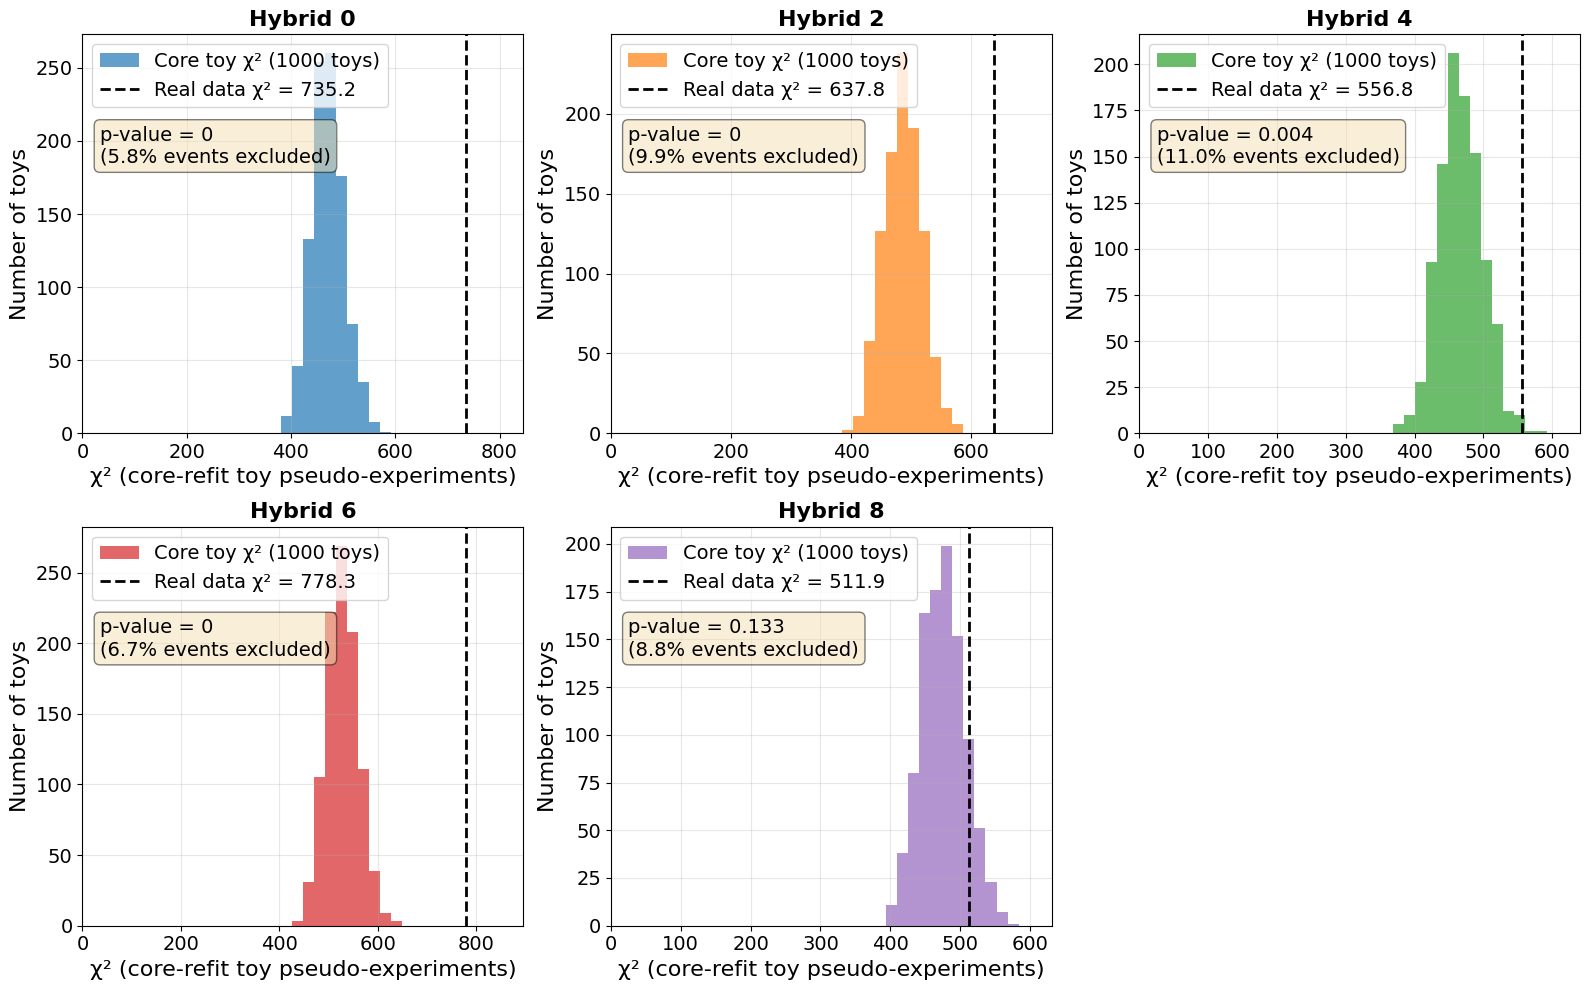


COMPARISON SUMMARY
  Hybrid      Mean    Std Dev  Entries  Expected Std (mu,n)    Fit Std  Delta Std (fit-exp)  Chi2 (real)  Chi2 (toy mean)  Chi2 toy p-value  Core Chi2 (real)  Core Chi2 p-value  Core events excl. (%)   Peak  Peak Height
Hybrid 0  971.4050 120.823149     2033            22.522205 120.822438            98.300233  1598.015114      1480.756406             0.110        735.219719              0.000                   5.78 1063.0         47.0
Hybrid 2  960.8063 143.959062     2033            22.510537 143.958190           121.447653  2573.215262      1733.637800             0.049        637.786689              0.000                   9.89 1023.0         44.0
Hybrid 4  924.5986 140.489185     2033            22.452074 140.488203           118.036129  2012.011416      1478.552445             0.060        556.754181              0.004                  10.96  902.0         46.0
Hybrid 6  970.6524 137.866011     2033            22.521458 137.865120           115.343662  1543.39

In [147]:
# Histogram fitting and peak finding analysis using ROOT likelihood fit
fit_results = run_root_likelihood_fit(histogram_data, "Hybrid R")

In [148]:
# un chi² restreint répond à une question plus étroite — "le modèle décrit-il bien le cœur de la distribution ?" — pas "le modèle décrit-il bien les données". 


FIT DIAGNOSTICS: POISSON-LIKELIHOOD RESIDUAL ANALYSIS
Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0013_fig1.pdf


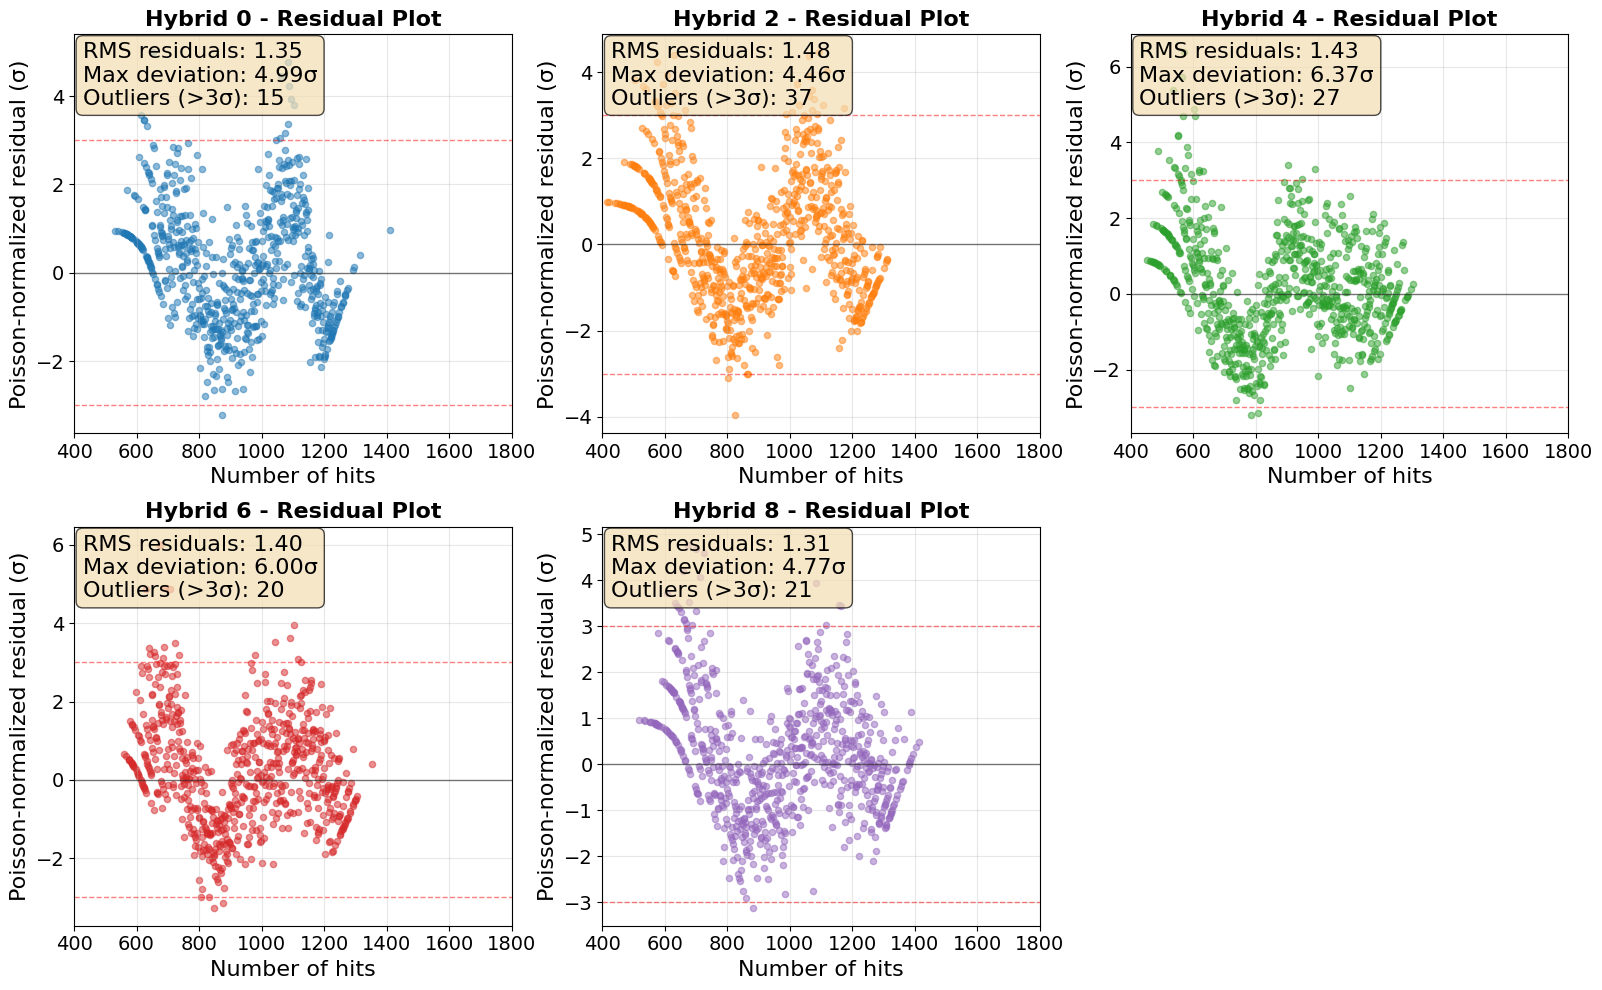


INTERPRETATION (LIKELIHOOD FIT):

For a ROOT Poisson-likelihood fit with bin-integrated expectations, prioritize these checks:
1) Convergence status: status = 0 is the expected successful fit.
2) Residual shape: residuals should fluctuate around 0 without systematic trends.
3) Outlier rate: only a small fraction of bins should exceed ±3σ.

A converged likelihood fit can still be mismodelled if residuals show structure.
Residual plots tell you WHERE the Gaussian model is insufficient.



In [149]:
# Detailed fit diagnostics: Poisson-likelihood residual analysis
print("\n" + "=" * 80)
print("FIT DIAGNOSTICS: POISSON-LIKELIHOOD RESIDUAL ANALYSIS")
print("=" * 80)


fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]

for idx, (hybrid_name, data) in enumerate(histogram_data.items()):
    ax = axes[idx]

    bin_centers = data["bin_centers"]
    bin_contents = data["bin_contents"]

    # Get fit results
    if hybrid_name not in fit_results or fit_results[hybrid_name]["popt"] is None:
        ax.text(0.5, 0.5, f"{hybrid_name}\nNo fit available", ha="center", va="center")
        ax.axis("off")
        continue

    fit_info = fit_results[hybrid_name]
    fit_status = fit_info.get("fit_status", None)
    expected_counts = fit_info.get("expected_counts")
    if expected_counts is None:
        fit_func = fit_info["fit_func"]
        _, _, expected_counts = expected_counts_from_fit(fit_func, data["histogram"])

    expected_counts = np.asarray(expected_counts, dtype=float)
    residuals = bin_contents - expected_counts
    sigma = np.sqrt(np.maximum(expected_counts, 1.0))
    normalized_residuals = residuals / sigma

    # Plot residuals
    finite_mask = bin_contents > 0
    ax.scatter(bin_centers[finite_mask], normalized_residuals[finite_mask],
              alpha=0.5, s=20, color=colors[idx])

    # Add reference lines
    ax.axhline(y=0, color="black", linestyle="-", linewidth=1, alpha=0.5)
    ax.axhline(y=3, color="red", linestyle="--", linewidth=1, alpha=0.5)
    ax.axhline(y=-3, color="red", linestyle="--", linewidth=1, alpha=0.5)

    # Statistics on residuals
    residuals_nz = normalized_residuals[finite_mask]
    rms_residuals = np.sqrt(np.mean(residuals_nz ** 2))
    max_residual = np.max(np.abs(residuals_nz))
    outliers = np.sum(np.abs(residuals_nz) > 3)

    ax.text(
        0.02,
        0.98,
        f"RMS residuals: {rms_residuals:.2f}\n"
        f"Max deviation: {max_residual:.2f}σ\nOutliers (>3σ): {outliers}",
        transform=ax.transAxes,
        va="top",
        fontsize=16,
        bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.7),
    )

    ax.set_xlabel("Number of hits", fontsize=16)
    ax.set_ylabel("Poisson-normalized residual (σ)", fontsize=16)
    ax.set_xlim(400, 1800)  # Adjust x-axis range for better visibility
    ax.set_title(f"{hybrid_name} - Residual Plot", fontsize=16, fontweight="bold")
    ax.tick_params(axis='both', labelsize=14) 
    ax.grid(alpha=0.3)

axes[-1].axis("off")
plt.tight_layout()
plt.show()

print("\n" + "=" * 80)
print("INTERPRETATION (LIKELIHOOD FIT):")
print("=" * 80)
print("""
For a ROOT Poisson-likelihood fit with bin-integrated expectations, prioritize these checks:
1) Convergence status: status = 0 is the expected successful fit.
2) Residual shape: residuals should fluctuate around 0 without systematic trends.
3) Outlier rate: only a small fraction of bins should exceed ±3σ.

A converged likelihood fit can still be mismodelled if residuals show structure.
Residual plots tell you WHERE the Gaussian model is insufficient.
""")
print("=" * 80)

In [150]:
# Study of gamma of hybrid R

In [151]:
# Recompute Gamma (Eq.19/20) and common-mode noise for hybrids 0,2,4,6,8
import math
import numpy as np
import pandas as pd
import ROOT

root_file = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root", "READ")

hybrid_specs = [
    ("OpticalGroup_0", "Hybrid_0", 0),
    ("OpticalGroup_1", "Hybrid_2", 2),
    ("OpticalGroup_2", "Hybrid_4", 4),
    ("OpticalGroup_3", "Hybrid_6", 6),
    ("OpticalGroup_4", "Hybrid_8", 8),
]

if 'fit_results' not in globals() or not isinstance(fit_results, dict):
    raise RuntimeError("Run the ROOT likelihood fit cell first to create 'fit_results'.")

def compute_gamma(hist, mean_fit, std_fit):
    n_channels = int(hist.GetNbinsX() - 1)
    mean_hits = float(mean_fit)
    variance_hits = float(std_fit) ** 2
    alpha_tilde = 2.0 * math.pi * (variance_hits - mean_hits * (1.0 - mean_hits / n_channels)) / (n_channels * (n_channels - 1))
    sin_alpha = math.sin(alpha_tilde)
    gamma_sq = sin_alpha / (1.0 - sin_alpha) if (1.0 - sin_alpha) != 0 else 0.0
    gamma = math.sqrt(max(gamma_sq, 0.0))
    return gamma

# This function performs sigma-clipping on a list of values to compute a robust mean and standard deviation.
def sigma_clipped_stats(values, sigma, maxiters):
    vals = np.asarray(values, dtype=float).copy()
    vals = vals[np.isfinite(vals)]
    if vals.size == 0:
        return (np.nan, np.nan, 0, 0, 0)
    n_initial = vals.size
    for _ in range(maxiters):
        if vals.size <= 1:
            break
        m = vals.mean()
        s = vals.std(ddof=1)
        if s == 0.0:
            break
        keep = np.abs(vals - m) <= sigma * s
        if keep.sum() == vals.size:
            break
        vals = vals[keep]
    n_rejected = n_initial - vals.size
    return (float(vals.mean()) if vals.size>0 else np.nan, float(vals.std(ddof=1)) if vals.size>1 else 0.0, int(vals.size), int(n_rejected), int(n_initial))

results = []
for og_name, hybrid_name, hybrid_id in hybrid_specs:
    cm_path = f"Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/{og_name}/{hybrid_name}/D_B(0)_O({hybrid_id // 2})_CommonNoiseHits_OccupancyDriven_Hybrid({hybrid_id})"
    strip_path = f"Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/{og_name}/{hybrid_name}/D_B(0)_O({hybrid_id // 2})_StripChannelNoise_Hybrid({hybrid_id})"
    cm_hist = root_file.Get(cm_path)
    strip_hist = root_file.Get(strip_path)
    if not cm_hist or not strip_hist:
        print(f"[SKIP] Missing hist for {hybrid_name}")
        continue
    fit_key = hybrid_name.replace('_', ' ')
    fit_info = fit_results.get(fit_key) or fit_results.get(hybrid_name)
    if fit_info is None:
        print(f"[SKIP] Missing fit results for {hybrid_name}")
        continue
    gamma = compute_gamma(cm_hist, fit_info['mean_fit'], fit_info['std_fit'])
    # extract per-channel noise values
    vals = []
    for i in range(1, strip_hist.GetNbinsX()+1):
        v = float(strip_hist.GetBinContent(i))
        if np.isfinite(v) and v>0:
            vals.append(v)
    mean_clipped, std_clipped, n_kept, n_rej, n_init = sigma_clipped_stats(vals, sigma=3.0, maxiters=5)
    cm_val = gamma * mean_clipped
    results.append({
        'Hybrid': f'Hybrid_{hybrid_id}',
        'Gamma': gamma,
        'sigma_single_clipped_mean': mean_clipped,
        'sigma_single_clipped_std': std_clipped,
        'n_initial': n_init,
        'n_rejected': n_rej,
        'CM_VcTh': cm_val,
    })

df = pd.DataFrame(results)
print(df.to_string(index=False, formatters={
    'Gamma': '{:.6f}'.format,
    'sigma_single_clipped_mean': '{:.4f}'.format,
    'sigma_single_clipped_std': '{:.4f}'.format,
    'CM_VcTh': '{:.4f}'.format,
}))

  Hybrid    Gamma sigma_single_clipped_mean sigma_single_clipped_std  n_initial  n_rejected CM_VcTh
Hybrid_0 0.147984                    5.2237                   0.3712       2032           5  0.7730
Hybrid_2 0.178101                    5.3416                   0.3683       2032           1  0.9513
Hybrid_4 0.173579                    5.1929                   0.3672       2032           0  0.9014
Hybrid_6 0.170141                    5.2731                   0.4548       2032           1  0.8972
Hybrid_8 0.168936                    5.3503                   0.4531       2032           0  0.9039


In [152]:
# I suppose the average bin content across channels is a good estimate of the single-channel random noise and I only clip absurd values.


Per-hybrid values:
  Hybrid  CM_VcTh  CM_err
Hybrid_0   0.7730  0.0549
Hybrid_2   0.9513  0.0656
Hybrid_4   0.9014  0.0637
Hybrid_6   0.8972  0.0774
Hybrid_8   0.9039  0.0765
Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0014_fig1.pdf


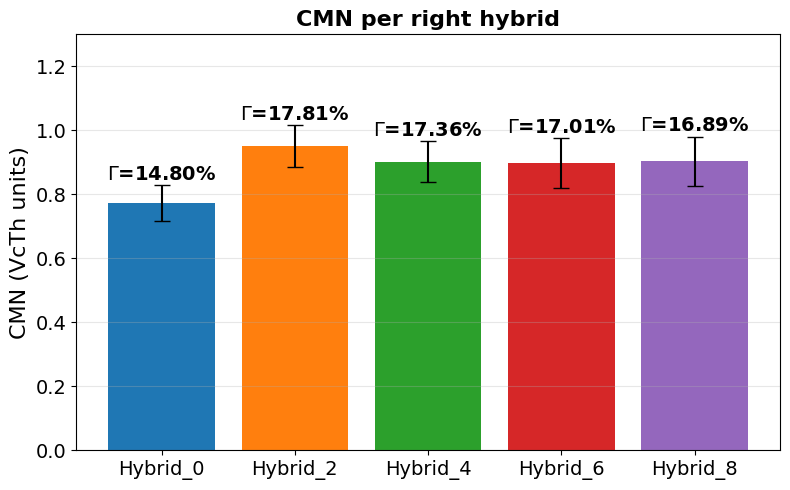

In [153]:
# Summary bar plot: one CM_VcTh value per hybrid (0,2,4,6,8)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if 'df' not in globals() or not isinstance(df, pd.DataFrame) or df.empty:
    raise RuntimeError("Run the previous CM computation cells first to create 'df'.")

wanted = ['Hybrid_0','Hybrid_2','Hybrid_4','Hybrid_6','Hybrid_8']
summary = (
    df[df['Hybrid'].isin(wanted)]
    .groupby('Hybrid', as_index=False)
    .agg({
        'CM_VcTh': 'mean',
        'Gamma': 'mean',
        'sigma_single_clipped_std': 'mean'
    })
)
if summary.empty:
    raise RuntimeError('No data for requested hybrids found in df.')

# propagate error
if 'sigma_single_clipped_std' in summary.columns and 'Gamma' in summary.columns:
    summary['CM_err'] = np.abs(summary['Gamma'] * summary['sigma_single_clipped_std'])
else:
    summary['CM_err'] = np.nan

# Plot
fig, ax = plt.subplots(figsize=(8, 5))
inds = np.arange(len(summary))
heights = summary['CM_VcTh'].to_numpy()
errs = summary['CM_err'].to_numpy()
labels = summary['Hybrid'].tolist()

bars = ax.bar(inds, heights, yerr=errs, capsize=6, color=['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd'])
# Annotate each bar with Gamma in percent (Gamma * 100%)
try:
    yrange = float(np.max(heights) - np.min(heights))
except Exception:
    yrange = 1.0
offset = 0.02 * (yrange if yrange > 0 else 1.0)
for rect, g, e in zip(bars, summary['Gamma'].to_numpy(), errs):
    label = f"{g * 100:.2f}%"
    h = rect.get_height()
    # place label above the error bar tip when error is available
    try:
        err_val = float(e)
    except Exception:
        err_val = 0.0
    top = h + abs(err_val)
    y = top + offset
    ax.text(rect.get_x() + rect.get_width() / 2., y, rf'$\Gamma$={label}', ha='center', va='bottom', fontsize=14, fontweight='bold')
ax.set_xticks(inds)
ax.set_xticklabels(labels,fontsize=16)
ax.set_ylabel('CMN (VcTh units)',fontsize=16)
ax.set_title('CMN per right hybrid',fontsize=16,fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.tick_params(axis='both', labelsize=14)
ax.set_ylim(0, 1.3)

plt.tight_layout()

print('\nPer-hybrid values:')
print(summary[['Hybrid','CM_VcTh','CM_err']].to_string(index=False, float_format='%.4f'))
plt.show()


In [154]:
# Study of the tail of distribution of hybrids R

In [155]:
import ROOT
import numpy as np
import matplotlib.pyplot as plt

# Ouvrir seulement les fichiers nécessaires
inFile2bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise2bot1mod = inFile2bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_0/Hybrid_0/D_B(0)_O(0)_CommonNoiseHits_SigmaNoise_3.00_Hybrid(0)")

inFile3bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise3bot1mod = inFile3bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_1/Hybrid_2/D_B(0)_O(1)_CommonNoiseHits_SigmaNoise_3.00_Hybrid(2)")

inFile4bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ")
Noise4bot1mod = inFile4bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_2/Hybrid_4/D_B(0)_O(2)_CommonNoiseHits_SigmaNoise_3.00_Hybrid(4)")

inFile5bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise5bot1mod = inFile5bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_3/Hybrid_6/D_B(0)_O(3)_CommonNoiseHits_SigmaNoise_3.00_Hybrid(6)")

inFile6bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise6bot1mod = inFile6bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_4/Hybrid_8/D_B(0)_O(4)_CommonNoiseHits_SigmaNoise_3.00_Hybrid(8)")

In [156]:
# Extract bin-by-bin data from the five 2S hybrid histograms
hybrids_histograms = [
    ("Hybrid 0", Noise2bot1mod),
    ("Hybrid 2", Noise3bot1mod),
    ("Hybrid 4", Noise4bot1mod),
    ("Hybrid 6", Noise5bot1mod),
    ("Hybrid 8", Noise6bot1mod),
]

histogram_data = {}

print("\n" + "=" * 80)
print("HISTOGRAM BIN-BY-BIN DATA EXTRACTION")
print("=" * 80)

for hybrid_name, hist in hybrids_histograms:
    if hist is None:
        print(f"\n[SKIP] {hybrid_name}: histogram not found")
        continue
    
    # Extract basic statistics
    entries = int(hist.GetEntries())
    mean = float(hist.GetMean())
    std_dev = float(hist.GetStdDev())
    rms = float(hist.GetRMS())
    
    print(f"\n{hybrid_name}:")
    print(f"  Entries: {entries}")
    print(f"  Mean: {mean:.4f}")
    print(f"  Std Dev: {std_dev:.4f}")
    print(f"  RMS: {rms:.4f}")
    
    # Extract bin-by-bin data
    # ROOT histograms are 1-indexed (bin 0 is underflow, bin N+1 is overflow)
    bin_centers = []
    bin_contents = []
    
    for i in range(1, hist.GetNbinsX() + 1):
        bin_centers.append(hist.GetXaxis().GetBinCenter(i))
        bin_contents.append(hist.GetBinContent(i))
    
    histogram_data[hybrid_name] = {
        "entries": entries,
        "mean": mean,
        "std_dev": std_dev,
        "rms": rms,
        "bin_centers": np.array(bin_centers),
        "bin_contents": np.array(bin_contents),
        "histogram": hist,
    }


HISTOGRAM BIN-BY-BIN DATA EXTRACTION

Hybrid 0:
  Entries: 2033
  Mean: 5.5278
  Std Dev: 3.1058
  RMS: 3.1058

Hybrid 2:
  Entries: 2033
  Mean: 4.6974
  Std Dev: 3.1012
  RMS: 3.1012

Hybrid 4:
  Entries: 2033
  Mean: 5.3683
  Std Dev: 3.3537
  RMS: 3.3537

Hybrid 6:
  Entries: 2033
  Mean: 4.7769
  Std Dev: 3.0466
  RMS: 3.0466

Hybrid 8:
  Entries: 2033
  Mean: 4.8093
  Std Dev: 3.1277
  RMS: 3.1277


In [157]:
# Add Gaussian fits to each histogram on the canvas
import ROOT
import numpy as np
from scipy.stats import norm

# Threshold used by the "SigmaNoise_3.00" histograms below -- keep this in sync with that name.
n_sigma_threshold = 3.0

print("\n" + "=" * 80)
print("ADDING GAUSSIAN FITS TO EACH HISTOGRAM ON CANVAS")
print("=" * 80)

# Create a new canvas with fits
canvas_fit = ROOT.TCanvas("hybrids_sigma3_with_fits", "Hybrid Common-Mode Noise with Fits (3σ threshold)",1200,400 * rows)
canvas_fit.Divide(cols, rows)

fit_results_canvas = {}
colors_fit = [ROOT.kBlue, ROOT.kRed, ROOT.kGreen+2, ROOT.kMagenta, ROOT.kCyan, 
              ROOT.kOrange+7, ROOT.kYellow+2, ROOT.kSpring+9]

# Keep the fit order aligned with the histogram_data built in this cell
hybrid_names = list(histogram_data.keys())

for i, hybrid_name in enumerate(hybrid_names):
    pad_num = i + 1
    canvas_fit.cd(pad_num)
    ROOT.gPad.SetLeftMargin(0.12)
    ROOT.gPad.SetBottomMargin(0.12)
    ROOT.gPad.SetGrid()
    ROOT.gPad.SetLogy(1)
    
    hist_data = histogram_data.get(hybrid_name)
    if hist_data is None or hist_data["histogram"] is None:
        ROOT.TText(0.2, 0.5, f"No data for {hybrid_name}").Draw()
        continue
    
    hist = hist_data["histogram"]
    
    # Style the histogram
    hist.SetLineColor(colors_fit[i % len(colors_fit)])
    hist.SetLineWidth(2)
    hist.SetFillColor(colors_fit[i % len(colors_fit)])
    hist.SetFillStyle(3004)
    hist.SetTitle(hybrid_name)
    hist.GetXaxis().SetTitle("Number of hits (3σ above noise)")
    hist.GetXaxis().SetRangeUser(0.0, 50.0)
    hist.GetYaxis().SetTitle("Number of events")
    hist.GetXaxis().SetTitleSize(0.05)
    hist.GetYaxis().SetTitleSize(0.05)
    hist.GetXaxis().SetLabelSize(0.04)
    hist.GetYaxis().SetLabelSize(0.04)
    
    # Draw histogram
    hist.Draw("HIST")
    
    # Perform Gaussian fit
    x_min = float(hist.GetXaxis().GetXmin())
    x_max = float(hist.GetXaxis().GetXmax())
    
    # Find peak for initial guess
    peak_idx = hist.GetMaximumBin()
    peak_x = hist.GetXaxis().GetBinCenter(peak_idx)
    peak_y = hist.GetBinContent(peak_idx)
    
    # Create fit function
    safe_name = "".join(ch if ch.isalnum() else "_" for ch in f"fit_hybrids_{hybrid_name}")
    fit_func = ROOT.TF1(safe_name, "gaus", x_min, x_max)
    
    # Set initial parameters
    mean_guess = hist_data["mean"]
    std_guess = hist_data["std_dev"]
    amplitude_guess = max(peak_y, 1.0)
    
    fit_func.SetParameters(amplitude_guess, mean_guess, std_guess)
    fit_func.SetParLimits(0, 0.0, max(amplitude_guess * 10.0, 1.0))
    fit_func.SetParLimits(1, x_min, x_max)
    fit_func.SetParLimits(2, 1e-6, max(x_max - x_min, std_guess * 10.0))
    
    # Perform fit
    try:
        fit_result = hist.Fit(fit_func, "LQRS")
        fit_status = int(fit_result)
        
        amplitude_fit = float(fit_func.GetParameter(0))
        mean_fit = float(fit_func.GetParameter(1))
        std_fit = abs(float(fit_func.GetParameter(2)))
        
        # Get parameter errors
        amplitude_err = float(fit_func.GetParError(0))
        mean_err = float(fit_func.GetParError(1))
        std_err = abs(float(fit_func.GetParError(2)))
        
        fit_results_canvas[hybrid_name] = {
            "amplitude": amplitude_fit,
            "amplitude_err": amplitude_err,
            "mean": mean_fit,
            "mean_err": mean_err,
            "std": std_fit,
            "std_err": std_err,
            "status": fit_status,
            "fit_func": fit_func,
        }
        
        # Draw fit function in orange
        #fit_func.SetLineColor(ROOT.kOrange)
        #fit_func.SetLineWidth(2)
        #fit_func.SetLineStyle(7)  # dashed line
        #fit_func.Draw("SAME")
        
        # Fit and overlay a theoretical Poisson distribution for the no-CMN expectation
        # Cap the evaluation domain well below where TMath::Gamma(x+1) overflows to inf (~x>170);
        # a TF1 that hits NaN/Inf anywhere in its declared range fails to draw at all, even in the
        # (perfectly finite) low-x region actually visible on the plot.
        poisson_x_max = min(x_max, 100.0)
        poisson_name = "".join(ch if ch.isalnum() else "_" for ch in f"poisson_hybrids_{hybrid_name}")
        poisson_func = ROOT.TF1(poisson_name, "[0] * TMath::Exp(-[1]) * TMath::Power([1], x) / TMath::Gamma(x + 1.0)", x_min, poisson_x_max)
        poisson_func.SetNpx(500)
        poisson_norm_guess = max(float(hist.Integral()), 1.0)
        poisson_lambda_guess = max(mean_guess, 1e-6)
        poisson_func.SetParameter(0, poisson_norm_guess)
        poisson_func.FixParameter(0, poisson_norm_guess)
        poisson_func.SetParameter(1, poisson_lambda_guess)
        poisson_func.SetParLimits(1, 1e-6, max(x_max, poisson_lambda_guess * 10.0))
        
        try:
            poisson_result = hist.Fit(poisson_func, "LQRS")
            poisson_status = int(poisson_result)
            
            poisson_lambda_fit = float(poisson_func.GetParameter(1))
            poisson_lambda_err = float(poisson_func.GetParError(1))
            
            poisson_func.SetLineColor(ROOT.kBlack)
            poisson_func.SetLineWidth(2)
            #poisson_func.SetLineStyle(7)
            poisson_func.Draw("SAME")
            
            fit_results_canvas[hybrid_name]["poisson"] = {
                "norm": poisson_norm_guess,
                "norm_err": 0.0,
                "lambda": poisson_lambda_fit,
                "lambda_err": poisson_lambda_err,
                "status": poisson_status,
                "fit_func": poisson_func,
            }
            
            print(f"  Poisson Norm: {poisson_norm_guess:.4f} (fixed)")
            print(f"  Poisson Lambda: {poisson_lambda_fit:.4f} ± {poisson_lambda_err:.4f}")

            # Theoretical Poisson expectation with NO common-mode noise: if every strip's noise
            # were an independent Gaussian, the number of channels crossing a pure n_sigma_threshold
            # would be Poisson with lambda = n_channels * P(Z > n_sigma_threshold) (one-sided Gaussian
            # tail). Unlike poisson_func above, this lambda is NOT fit -- it's fixed from the physical
            # channel count and the threshold, so the gap to the data/fit shows the CMN excess.
            n_channels = int(hist.GetNbinsX()) - 1
            lambda_theory = n_channels * norm.sf(n_sigma_threshold)
            theory_name = "".join(ch if ch.isalnum() else "_" for ch in f"poisson_theory_hybrids_{hybrid_name}")
            theory_func = ROOT.TF1(theory_name, "[0] * TMath::Exp(-[1]) * TMath::Power([1], x) / TMath::Gamma(x + 1.0)", x_min, poisson_x_max)
            theory_func.SetNpx(500)
            theory_func.FixParameter(0, poisson_norm_guess)
            theory_func.FixParameter(1, lambda_theory)
            theory_func.SetLineColor(ROOT.kGray + 2)
            theory_func.SetLineWidth(2)
            theory_func.SetLineStyle(2)
            theory_func.Draw("SAME")

            fit_results_canvas[hybrid_name]["poisson_theory"] = {
                "n_channels": n_channels,
                "lambda": lambda_theory,
                "fit_func": theory_func,
            }

            print(f"  Poisson (theory, no CMN): n_channels={n_channels}, lambda={lambda_theory:.4f}")

            legend_fit = ROOT.TLegend(0.30, 0.72, 0.95, 0.92)
            legend_fit.AddEntry(hist, "Data (3σ hits)", "f")
            legend_fit.AddEntry(poisson_func, "Poisson fit (λ = data mean)", "l")
            legend_fit.AddEntry(theory_func, "Poisson theory, no CMN", "l")
            legend_fit.SetTextSize(0.04)
            legend_fit.SetFillStyle(0)
            legend_fit.SetBorderSize(0)
            legend_fit.Draw()
        except Exception as e:
            print(f"  Poisson fit failed - {e}")
            fit_results_canvas[hybrid_name]["poisson"] = {"status": -1, "error": str(e)}
        
        # Add legend
        #legend = ROOT.TLegend(0.55, 0.7, 0.95, 0.95)
        #legend.AddEntry(hist, "Data", "f")
        #legend.AddEntry(fit_func, "Gaussian Fit", "l")
        #if fit_results_canvas[hybrid_name].get("poisson", {}).get("status", -1) >= 0:
        #    legend.AddEntry(poisson_func, "Poisson fit", "l")
        #legend.SetTextSize(0.04)
        #legend.SetFillStyle(0)
        #legend.Draw()
        
        # Print fit results with parameter errors
        print(f"\n{hybrid_name}:")
        print(f"  Fit Status: {fit_status}")
        print(f"  Amplitude: {amplitude_fit:.4f} ± {amplitude_err:.4f}")
        print(f"  Mean: {mean_fit:.4f} ± {mean_err:.4f}")
        print(f"  Std Dev: {std_fit:.4f} ± {std_err:.4f}")
        
    except Exception as e:
        print(f"\n{hybrid_name}: Fit failed - {e}")
        fit_results_canvas[hybrid_name] = {"status": -1, "error": str(e)}

# Hide empty pads
for i in range(len(hybrid_names), rows * cols):
    canvas_fit.cd(i + 1)
    ROOT.gPad.Draw()

canvas_fit.Update()
canvas_fit.Draw()

print("\n" + "=" * 80)
print("FITTING COMPLETE")
print("=" * 80)



ADDING GAUSSIAN FITS TO EACH HISTOGRAM ON CANVAS
  Poisson Norm: 10000.0000 (fixed)
  Poisson Lambda: 5.5278 ± 0.0235
  Poisson (theory, no CMN): n_channels=2033, lambda=2.7443

Hybrid 0:
  Fit Status: 0
  Amplitude: 1215.2859 ± 15.1481
  Mean: 5.1472 ± 0.0423
  Std Dev: 3.4577 ± 0.0334
  Poisson Norm: 10000.0000 (fixed)
  Poisson Lambda: 4.6974 ± 0.0217
  Poisson (theory, no CMN): n_channels=2033, lambda=2.7443

Hybrid 2:
  Fit Status: 0
  Amplitude: 1205.8502 ± 14.4245
  Mean: 3.7689 ± 0.0626
  Std Dev: 3.8035 ± 0.0448
  Poisson Norm: 10000.0000 (fixed)
  Poisson Lambda: 5.3683 ± 0.0232
  Poisson (theory, no CMN): n_channels=2033, lambda=2.7443

Hybrid 4:
  Fit Status: 0
  Amplitude: 1114.1719 ± 13.5621
  Mean: 4.5946 ± 0.0586
  Std Dev: 3.9760 ± 0.0438
  Poisson Norm: 10000.0000 (fixed)
  Poisson Lambda: 4.7769 ± 0.0219
  Poisson (theory, no CMN): n_channels=2033, lambda=2.7443

Hybrid 6:
  Fit Status: 0
  Amplitude: 1225.9674 ± 14.8684
  Mean: 4.0295 ± 0.0550
  Std Dev: 3.6397 ± 0

Warning in <TCanvas::Constructor>: Deleting canvas with same name: hybrids_sigma3_with_fits


In [158]:
# calculate skewness of hybrids L AND R of modules

In [159]:
# Calculate third moment (skewness) for histogram asymmetries across modules
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

print("\n" + "=" * 80)
print("QUANTIFYING HISTOGRAM ASYMMETRIES - THIRD MOMENT ANALYSIS")
print("=" * 80)

# Function to calculate third moment (skewness) from histogram data
def calculate_third_moment(hist_obj):
    """
    Calculate the third moment (skewness) from a ROOT histogram.
    Third moment = (1/N) * Σ(x - μ)³
    
    Skewness (Fisher-Pearson) = Third central moment / (σ³)
    where σ is the standard deviation.
    """
    n_bins = hist_obj.GetNbinsX()
    bin_centers = []
    bin_contents = []
    
    for i in range(1, n_bins + 1):
        center = hist_obj.GetXaxis().GetBinCenter(i)
        content = hist_obj.GetBinContent(i)
        if content > 0:
            bin_centers.extend([center] * int(content))
            bin_contents.append(content)
    
    if len(bin_centers) == 0:
        return np.nan, np.nan, 0
    
    data = np.array(bin_centers)
    mean = np.mean(data)
    std = np.std(data, ddof=0)  # population std
    
    if std == 0:
        return np.nan, np.nan, len(data)
    
    # Third central moment
    third_moment = np.mean((data - mean) ** 3)
    # Skewness (normalized by σ³)
    skewness = third_moment / (std ** 3)
    
    return skewness, third_moment, len(data)

# Load ROOT file
root_file = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root", "READ")

# Define histogram paths for both hybrid L and R
modules_config = {
    "Hybrid L": [
        ("Hybrid 1", "Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_0/Hybrid_1/D_B(0)_O(0)_CommonNoiseHits_OccupancyDriven_Hybrid(1)"),
        ("Hybrid 3", "Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_1/Hybrid_3/D_B(0)_O(1)_CommonNoiseHits_OccupancyDriven_Hybrid(3)"),
        ("Hybrid 5", "Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_2/Hybrid_5/D_B(0)_O(2)_CommonNoiseHits_OccupancyDriven_Hybrid(5)"),
        ("Hybrid 7", "Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_3/Hybrid_7/D_B(0)_O(3)_CommonNoiseHits_OccupancyDriven_Hybrid(7)"),
        ("Hybrid 9", "Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_4/Hybrid_9/D_B(0)_O(4)_CommonNoiseHits_OccupancyDriven_Hybrid(9)"),
    ],
    "Hybrid R": [
        ("Hybrid 0", "Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_0/Hybrid_0/D_B(0)_O(0)_CommonNoiseHits_OccupancyDriven_Hybrid(0)"),
        ("Hybrid 2", "Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_1/Hybrid_2/D_B(0)_O(1)_CommonNoiseHits_OccupancyDriven_Hybrid(2)"),
        ("Hybrid 4", "Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_2/Hybrid_4/D_B(0)_O(2)_CommonNoiseHits_OccupancyDriven_Hybrid(4)"),
        ("Hybrid 6", "Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_3/Hybrid_6/D_B(0)_O(3)_CommonNoiseHits_OccupancyDriven_Hybrid(6)"),
        ("Hybrid 8", "Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_4/Hybrid_8/D_B(0)_O(4)_CommonNoiseHits_OccupancyDriven_Hybrid(8)"),
    ]
}

# Calculate third moment for each module
third_moment_results = []

for hybrid_set_name, modules in modules_config.items():
    print(f"\n{hybrid_set_name}:")
    print("-" * 60)
    
    for module_name, hist_path in modules:
        hist = root_file.Get(hist_path)
        
        if hist is None:
            print(f"  {module_name}: SKIP (histogram not found)")
            continue
        
        skewness, third_moment, n_samples = calculate_third_moment(hist)
        mean = float(hist.GetMean())
        std = float(hist.GetStdDev())
        
        # Interpretation
        if np.isnan(skewness):
            interpretation = "No valid data"
            print(f"  {module_name}: No valid data")
        else:
            if abs(skewness) < 0.5:
                interpretation = "Roughly symmetric"
            elif skewness > 0.5:
                interpretation = "Right-skewed (positive tail)"
            elif skewness < -0.5:
                interpretation = "Left-skewed (negative tail)"
            else:
                interpretation = "Slightly skewed"
            
            print(f"  {module_name}:")
            print(f"    Skewness (γ₃):      {skewness:8.4f}  ({interpretation})")
            print(f"    Third moment:       {third_moment:8.4f}")
            print(f"    N samples:          {n_samples:8d}")
            print(f"    Mean:               {mean:8.4f}")
            print(f"    Std Dev:            {std:8.4f}")
        
        third_moment_results.append({
            "Hybrid Set": hybrid_set_name,
            "Module": module_name,
            "Skewness": skewness,
            "Third Moment": third_moment,
            "N Samples": n_samples,
            "Mean": mean,
            "Std Dev": std,
            "Interpretation": interpretation,
        })

# Create summary DataFrame
df_skewness = pd.DataFrame(third_moment_results)

print("\n" + "=" * 80)
print("SUMMARY TABLE - THIRD MOMENT (SKEWNESS) FOR ALL MODULES")
print("=" * 80)

summary_display = df_skewness[["Hybrid Set", "Module", "Skewness", "Third Moment", "Interpretation"]].copy()
print("\n" + summary_display.to_string(index=False, 
      formatters={"Skewness": "{:.6f}".format, "Third Moment": "{:.6f}".format}))

print("\n" + "=" * 80)
print("STATISTICAL SUMMARY")
print("=" * 80)

for hybrid_set in ["Hybrid L", "Hybrid R"]:
    subset = df_skewness[df_skewness["Hybrid Set"] == hybrid_set]
    valid_skewness = subset["Skewness"].dropna()
    
    if len(valid_skewness) > 0:
        print(f"\n{hybrid_set}:")
        print(f"  Mean Skewness:      {valid_skewness.mean():.6f}")
        print(f"  Std Dev Skewness:   {valid_skewness.std():.6f}")
        print(f"  Min Skewness:       {valid_skewness.min():.6f}  ({subset.loc[valid_skewness.idxmin(), 'Module']})")
        print(f"  Max Skewness:       {valid_skewness.max():.6f}  ({subset.loc[valid_skewness.idxmax(), 'Module']})")
        
        symmetric_count = (abs(valid_skewness) < 0.5).sum()
        right_skew = (valid_skewness > 0.5).sum()
        left_skew = (valid_skewness < -0.5).sum()
        
        print(f"  Distribution breakdown:")
        print(f"    Roughly symmetric:  {symmetric_count}/{len(valid_skewness)}")
        print(f"    Right-skewed:       {right_skew}/{len(valid_skewness)}")
        print(f"    Left-skewed:        {left_skew}/{len(valid_skewness)}")

print("\n" + "=" * 80)



QUANTIFYING HISTOGRAM ASYMMETRIES - THIRD MOMENT ANALYSIS

Hybrid L:
------------------------------------------------------------
  Hybrid 1:
    Skewness (γ₃):        0.6335  (Right-skewed (positive tail))
    Third moment:       2430628.4344
    N samples:             10000
    Mean:               1085.9185
    Std Dev:            156.5517
  Hybrid 3:
    Skewness (γ₃):        0.2794  (Roughly symmetric)
    Third moment:       668575.9413
    N samples:             10000
    Mean:               1085.8943
    Std Dev:            133.7480
  Hybrid 5:
    Skewness (γ₃):        0.3703  (Roughly symmetric)
    Third moment:       974613.7612
    N samples:             10000
    Mean:               1061.9370
    Std Dev:            138.0728
  Hybrid 7:
    Skewness (γ₃):        0.8539  (Right-skewed (positive tail))
    Third moment:       3027752.6887
    N samples:             10000
    Mean:               1079.7052
    Std Dev:            152.4874
  Hybrid 9:
    Skewness (γ₃):       


VISUALIZATION - HISTOGRAM ASYMMETRIES (THIRD MOMENT)
Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0015_fig1.pdf


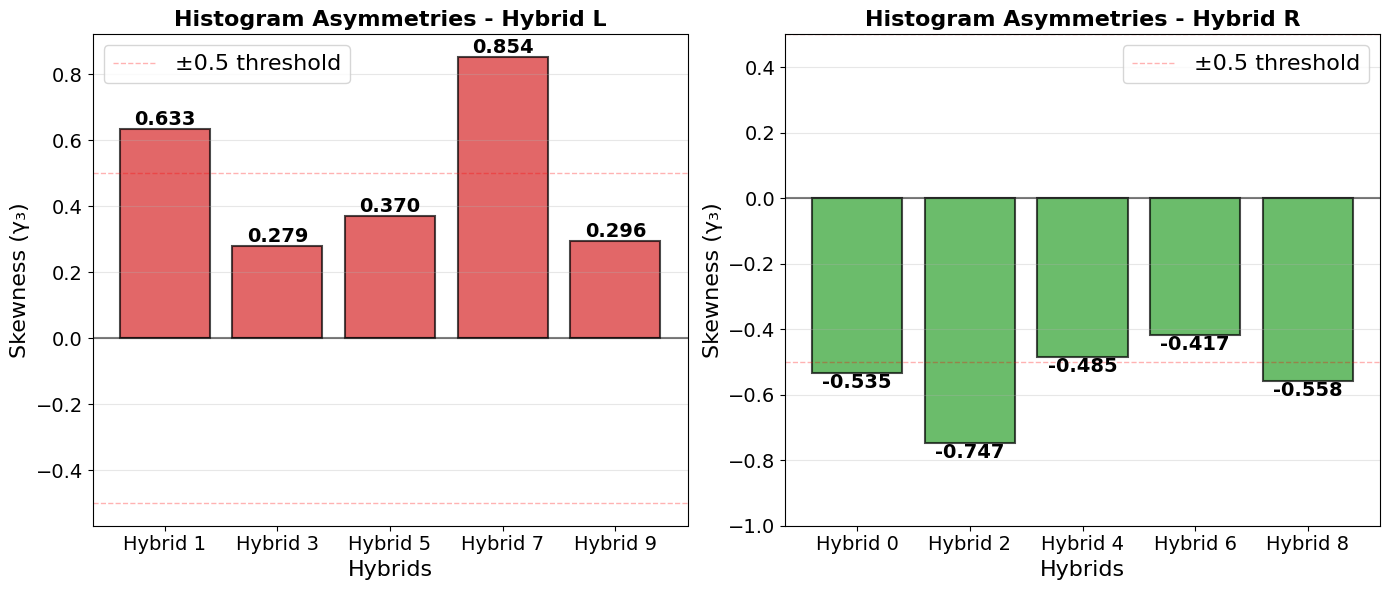


INTERPRETATION OF SKEWNESS

Skewness (third moment normalized by σ³) quantifies the asymmetry of a distribution:

  γ₃ ≈ 0       : Distribution is roughly symmetric (normal)
  γ₃ > 0       : Distribution has positive skew (right tail - extends to high values)
  γ₃ < 0       : Distribution has negative skew (left tail - extends to low values)
  |γ₃| > 0.5   : Moderate to strong skewness (pronounced asymmetry)
  |γ₃| > 1.0   : Highly skewed distribution

For detector noise:
  - Right skew suggests occasional high-noise events (spikes, interference)
  - Left skew suggests occasional low-noise events (dropout, compensation)
  - Symmetric suggests pure Gaussian-like thermal noise


MODULE-BY-MODULE INTERPRETATION

Hybrid L:
  Hybrid 1     : γ₃ =  0.6335  →  Right-skewed (positive tail)
  Hybrid 3     : γ₃ =  0.2794  →  Roughly symmetric
  Hybrid 5     : γ₃ =  0.3703  →  Roughly symmetric
  Hybrid 7     : γ₃ =  0.8539  →  Right-skewed (positive tail)
  Hybrid 9     : γ₃ =  0.2959  →  Roughl

In [160]:
# Visualization of third moment (skewness) across modules
import matplotlib.pyplot as plt
import numpy as np

print("\n" + "=" * 80)
print("VISUALIZATION - HISTOGRAM ASYMMETRIES (THIRD MOMENT)")
print("=" * 80)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Skewness bar chart for each hybrid set
hybrid_sets = ["Hybrid L", "Hybrid R"]
colors = ["#1f77b4", "#ff7f0e"]

for idx, hybrid_set in enumerate(hybrid_sets):
    ax = [ax1, ax2][idx]
    subset = df_skewness[df_skewness["Hybrid Set"] == hybrid_set].copy()
    subset = subset.sort_values("Module")
    
    modules = subset["Module"].values
    skewness_vals = subset["Skewness"].values
    
    # Color bars based on skewness sign and magnitude
    bar_colors = []
    for skew in skewness_vals:
        if np.isnan(skew):
            bar_colors.append("gray")
        elif skew > 0:
            bar_colors.append("#d62728")  # red for positive
        else:
            bar_colors.append("#2ca02c")  # green for negative
    
    bars = ax.bar(range(len(modules)), skewness_vals, color=bar_colors, alpha=0.7, edgecolor="black", linewidth=1.5)
    
    # Add zero line
    ax.axhline(y=0, color="black", linestyle="-", linewidth=1.5, alpha=0.5)
    
    # Add reference lines for |γ| = 0.5
    ax.axhline(y=0.5, color="red", linestyle="--", linewidth=1, alpha=0.3, label="±0.5 threshold")
    ax.axhline(y=-0.5, color="red", linestyle="--", linewidth=1, alpha=0.3)
    
    ax.set_xlabel("Hybrids", fontsize=16)
    ax.set_ylabel("Skewness (γ₃)", fontsize=16)
    ax.set_title(f"Histogram Asymmetries - {hybrid_set}", fontsize=16, fontweight="bold")
    ax.set_xticks(range(len(modules)))
    ax.set_xticklabels(modules, rotation=0)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(fontsize=16)
    ax2.set_ylim(-1, 0.5)
    ax.tick_params(axis='both', labelsize=14)
    # Add value labels on bars
    for i, (bar, val) in enumerate(zip(bars, skewness_vals)):
        if not np.isnan(val):
            height = val
            ax.text(bar.get_x() + bar.get_width()/2., height,
                   f"{val:.3f}",
                   ha="center", va="bottom" if height > 0 else "top",
                   fontsize=14, fontweight="bold")

plt.tight_layout()
plt.show()

# Summary interpretation
print("\n" + "=" * 80)
print("INTERPRETATION OF SKEWNESS")
print("=" * 80)
print("""
Skewness (third moment normalized by σ³) quantifies the asymmetry of a distribution:

  γ₃ ≈ 0       : Distribution is roughly symmetric (normal)
  γ₃ > 0       : Distribution has positive skew (right tail - extends to high values)
  γ₃ < 0       : Distribution has negative skew (left tail - extends to low values)
  |γ₃| > 0.5   : Moderate to strong skewness (pronounced asymmetry)
  |γ₃| > 1.0   : Highly skewed distribution

For detector noise:
  - Right skew suggests occasional high-noise events (spikes, interference)
  - Left skew suggests occasional low-noise events (dropout, compensation)
  - Symmetric suggests pure Gaussian-like thermal noise
""")

print("\n" + "=" * 80)
print("MODULE-BY-MODULE INTERPRETATION")
print("=" * 80)

for hybrid_set in ["Hybrid L", "Hybrid R"]:
    subset = df_skewness[df_skewness["Hybrid Set"] == hybrid_set]
    print(f"\n{hybrid_set}:")
    for _, row in subset.iterrows():
        if not np.isnan(row["Skewness"]):
            print(f"  {row['Module']:12s} : γ₃ = {row['Skewness']:7.4f}  →  {row['Interpretation']}")

print("\n" + "=" * 80)


In [161]:
# Lorsque le courant (\(I\)) circule dans un conducteur, il perd de l'énergie sous forme de chaleur (effet Joule P=RI), ce qui diminue la tension (\(U\)) à l'extrémité finale.
# ce qui explique que quand un hybrid a + d occupancy (cad distribution est plus asymétrique vers les hautes valeurs de bruit ), il tire + de courant, ce qui fait que la tension de l'autre hybrid est plus basse, ce qui provoque une chute de la baseline, donc - d occupancy et donc que la distribution est plus asymétrique (skewed) vers les basses valeurs de bruit pour cet hybrid.
# In real conditions such as at 5sigma, moins de courant tiré, donc moins de chute de tension, donc distribution plus symétrique pour les deux hybrides.

In [162]:
#STUDY OF MODULE-LEVEL COMMON MODE NOISE of 2S modules (5 modules)
#regarder  correlation sentre 2 hybrid d un module


In [163]:
import ROOT
import numpy as np
import matplotlib.pyplot as plt

# Ouvrir seulement les fichiers nécessaires
inFile2bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise2bot1mod = inFile2bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_0/D_B(0)_CommonNoiseHits_OccupancyDriven_OpticalGroup(0)")

inFile3bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise3bot1mod = inFile3bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_1/D_B(0)_CommonNoiseHits_OccupancyDriven_OpticalGroup(1)")

inFile4bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ")
Noise4bot1mod = inFile4bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_2/D_B(0)_CommonNoiseHits_OccupancyDriven_OpticalGroup(2)")

inFile5bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise5bot1mod = inFile5bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_3/D_B(0)_CommonNoiseHits_OccupancyDriven_OpticalGroup(3)")

inFile6bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise6bot1mod = inFile6bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_4/D_B(0)_CommonNoiseHits_OccupancyDriven_OpticalGroup(4)")


In [164]:
# Extract bin-by-bin data from the five 2S hybrid histograms
module_histograms = [
    ("Module 1", Noise2bot1mod),
    ("Module 2", Noise3bot1mod),
    ("Module 3", Noise4bot1mod),
    ("Module 4", Noise5bot1mod),
    ("Module 5", Noise6bot1mod),
]

histogram_data = {}

print("\n" + "=" * 80)
print("HISTOGRAM BIN-BY-BIN DATA EXTRACTION")
print("=" * 80)

for module_name, hist in module_histograms:
    if hist is None:
        print(f"\n[SKIP] {module_name}: histogram not found")
        continue
    
    # Extract basic statistics
    entries = int(hist.GetEntries())
    mean = float(hist.GetMean())
    std_dev = float(hist.GetStdDev())
    rms = float(hist.GetRMS())
    
    print(f"\n{module_name}:")
    print(f"  Entries: {entries}")
    print(f"  Mean: {mean:.4f}")
    print(f"  Std Dev: {std_dev:.4f}")
    print(f"  RMS: {rms:.4f}")
    
    # Extract bin-by-bin data
    # ROOT histograms are 1-indexed (bin 0 is underflow, bin N+1 is overflow)
    bin_centers = []
    bin_contents = []
    
    for i in range(1, hist.GetNbinsX() + 1):
        bin_centers.append(hist.GetXaxis().GetBinCenter(i))
        bin_contents.append(hist.GetBinContent(i))
    
    histogram_data[module_name] = {
        "entries": entries,
        "mean": mean,
        "std_dev": std_dev,
        "rms": rms,
        "bin_centers": np.array(bin_centers),
        "bin_contents": np.array(bin_contents),
        "histogram": hist,
    }


HISTOGRAM BIN-BY-BIN DATA EXTRACTION

Module 1:
  Entries: 4065
  Mean: 2057.3235
  Std Dev: 129.7378
  RMS: 129.7378

Module 2:
  Entries: 4065
  Mean: 2046.7006
  Std Dev: 69.0412
  RMS: 69.0412

Module 3:
  Entries: 4065
  Mean: 1986.5356
  Std Dev: 86.8069
  RMS: 86.8069

Module 4:
  Entries: 4065
  Mean: 2050.3576
  Std Dev: 134.9985
  RMS: 134.9985

Module 5:
  Entries: 4065
  Mean: 2107.3678
  Std Dev: 51.2471
  RMS: 51.2471



HISTOGRAM FITTING AND PEAK ANALYSIS
DATASET: 2S modules
Using ROOT binned likelihood fit with Poisson bin statistics.

Module 1:
  Peak found at x=2096.0, height=62.0
  Total peaks detected: 125
  ROOT likelihood fit:
    Status:     0
    Amplitude:  30.7500 ± 0.3766
    Mean:       2057.3235 ± 1.2974
    Std Dev:    129.7375 ± 0.9174
    Expected σ: 31.8723 (from μ=2057.3235, n=4064)
    Δσ(fit-exp): +97.8652
  Toy chi2 goodness-of-fit diagnostics (full range):
    Bins used:   3095 / 4065
    Used frac:   0.761
    Chi2 (real): 5269.2541
    Chi2 (toy):  2054.4948 ± 21599.1037  (mean ± std over 1000 toys)
    p-value:     0.011
  Core refit (Gaussian refit within [1810.5, 2304.5], expected >= 5):
    Amplitude:  36.6101  (full-range fit: 30.7500)
    Mean:       2080.0026  (full-range fit: 2057.3235)
    Std Dev:    103.2680  (full-range fit: 129.7375)
  Toy chi2 goodness-of-fit diagnostics (core region, expected >= 5):
    Bins used:   413 / 4065  (0.102)
    Events excluded: 1128

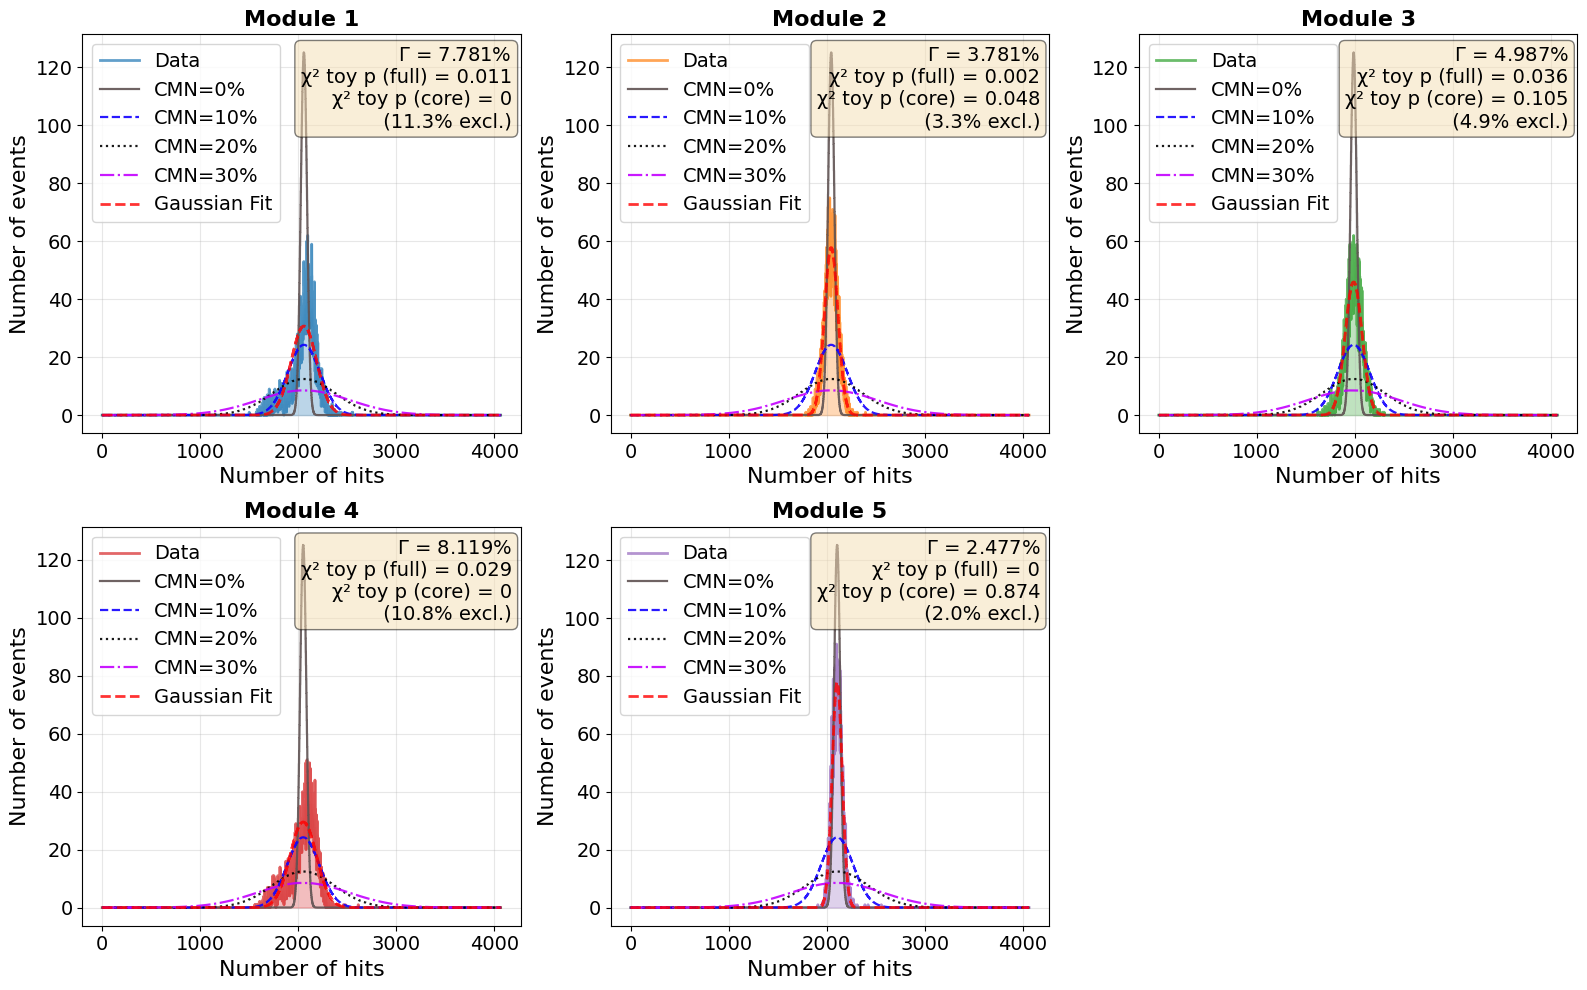


TOY CHI2 GOODNESS-OF-FIT DISTRIBUTIONS (2S modules)

Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0017_fig1.pdf


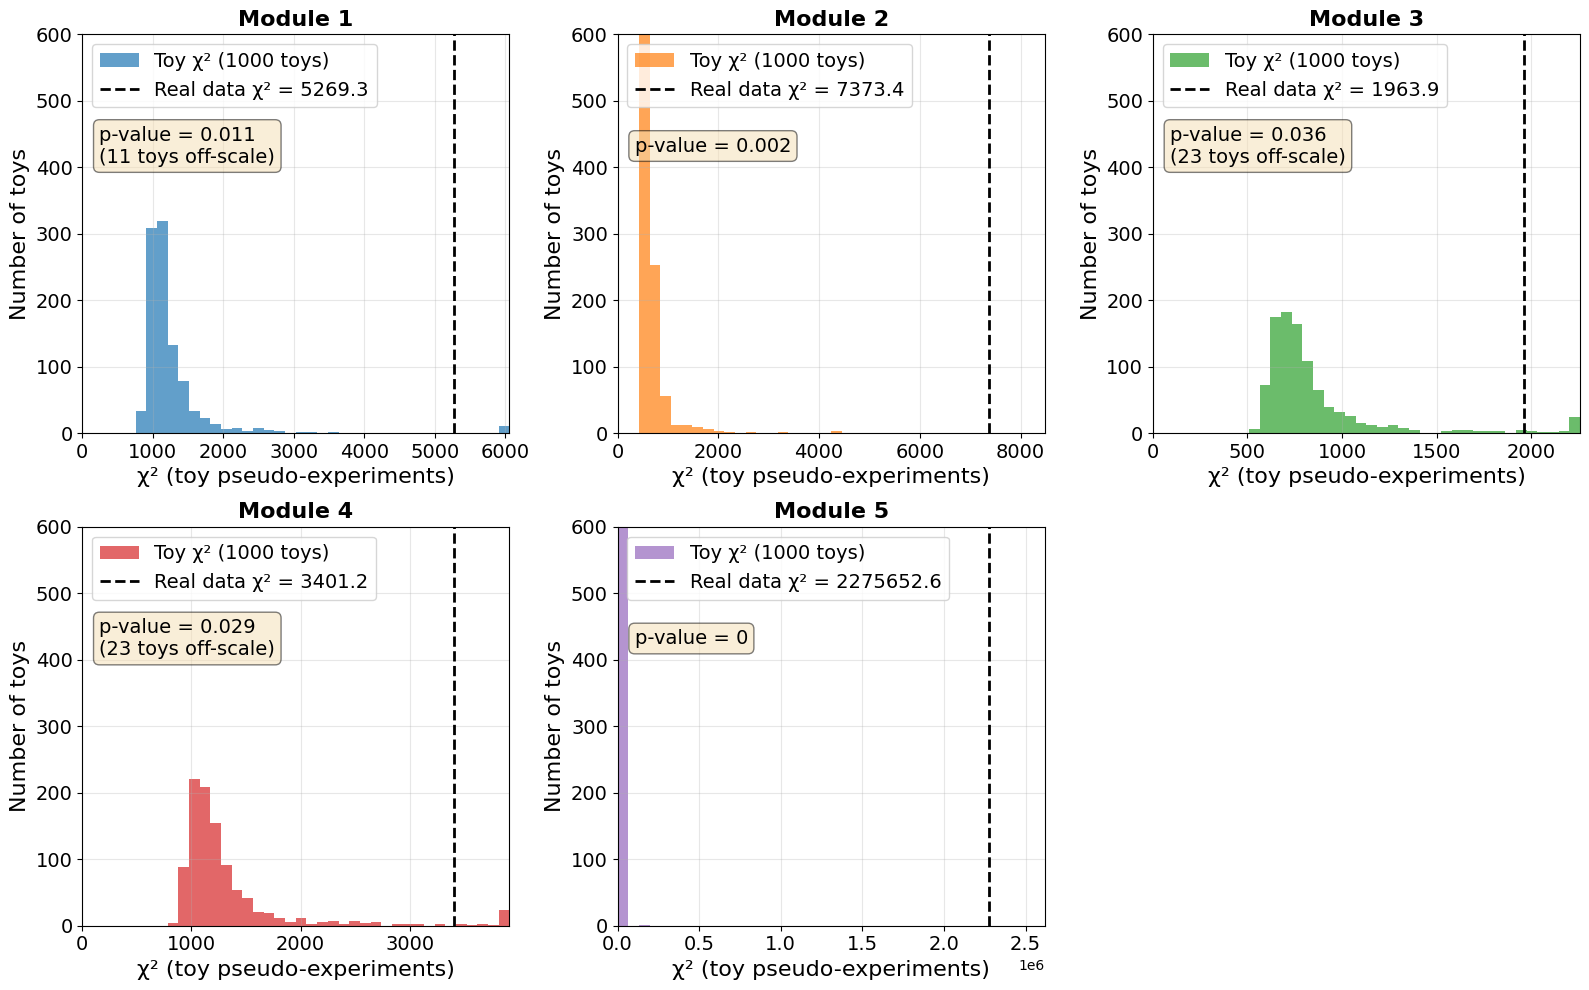


CORE-REGION TOY CHI2 GOODNESS-OF-FIT DISTRIBUTIONS (2S modules)

Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0018_fig1.pdf


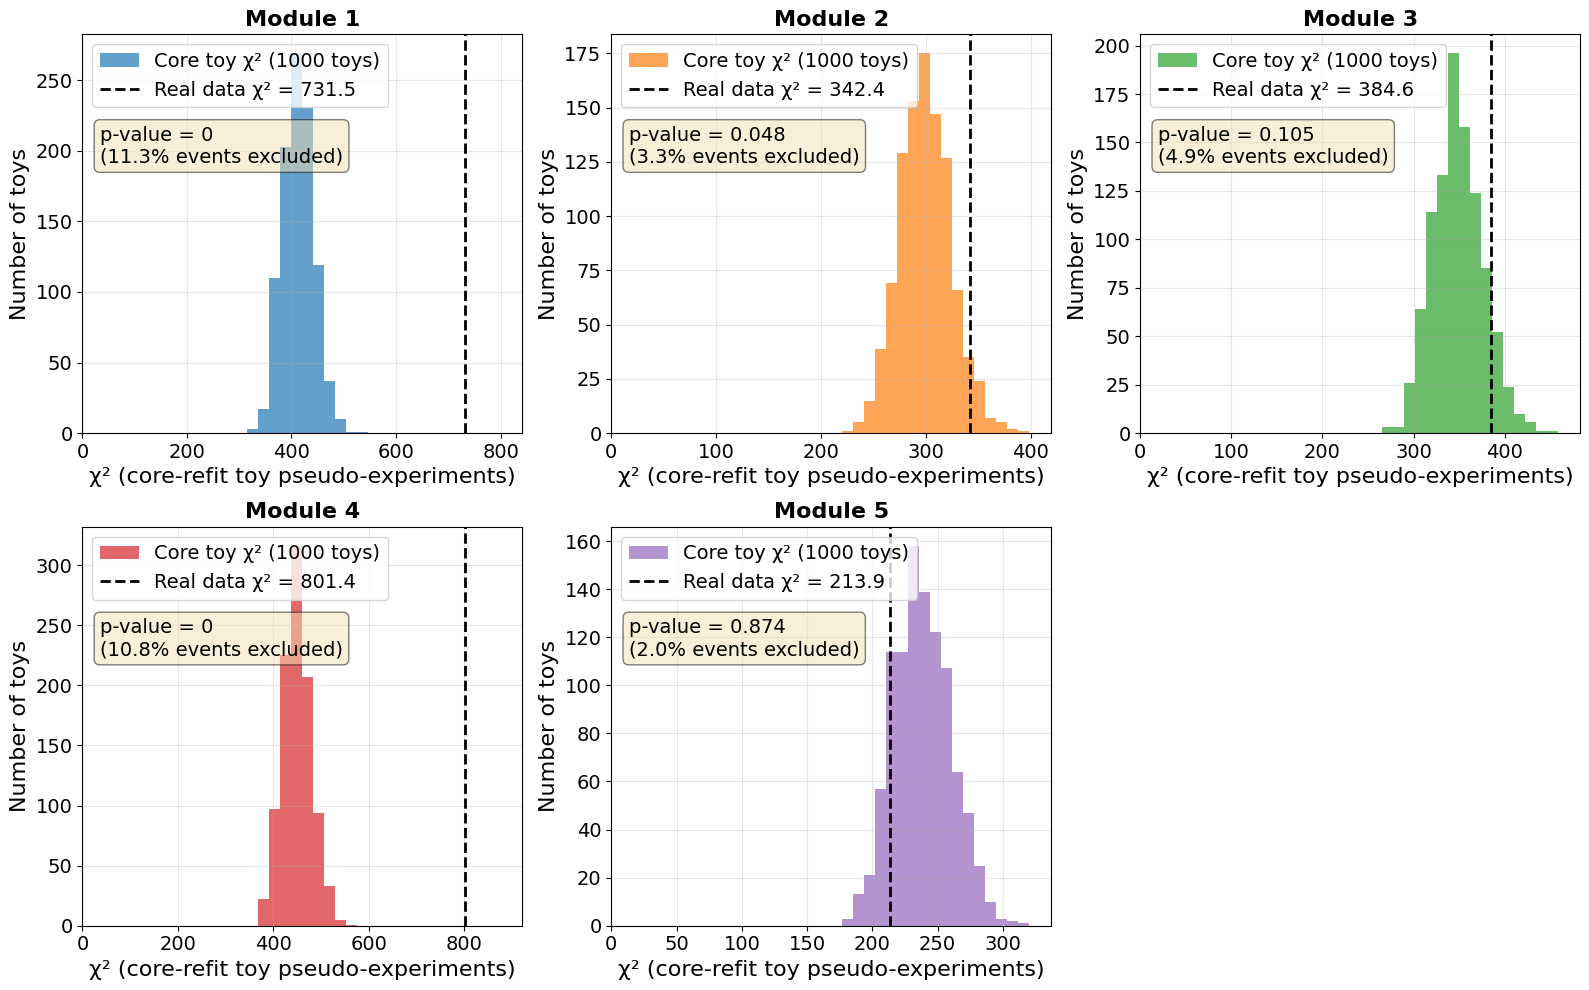


COMPARISON SUMMARY
  Hybrid      Mean    Std Dev  Entries  Expected Std (mu,n)    Fit Std  Delta Std (fit-exp)  Chi2 (real)  Chi2 (toy mean)  Chi2 toy p-value  Core Chi2 (real)  Core Chi2 p-value  Core events excl. (%)   Peak  Peak Height
Module 1 2057.3235 129.737796     4065            31.872280 129.737463            97.865184 5.269254e+03      2054.494821             0.011        731.520532              0.000                  11.28 2096.0         62.0
Module 2 2046.7006  69.041232     4065            31.873921  69.040456            37.166535 7.373373e+03       720.190756             0.002        342.370709              0.048                   3.27 2032.0         75.0
Module 3 1986.5356  86.806941     4065            31.866776  86.806189            54.939413 1.963854e+03       948.170055             0.036        384.610566              0.105                   4.86 1987.0         62.0
Module 4 2050.3576 134.998534     4065            31.873454 134.997057           103.123603 3.401186

In [165]:
# Histogram fitting and peak finding analysis using ROOT likelihood fit
fit_results = run_root_likelihood_fit(histogram_data, "2S modules")

In [166]:
#For module 5, 97.5% of that 2,275,918 chi2 comes from a single bin.
#Bin 2423 (i.e. one real event registered exactly 2423 hits) has observed = 1 but the fitted Gaussian (μ=2107, σ=51.2) predicts expected = 4.5×10⁻⁷ there — essentially "this should never happen" under a pure Gaussian (2423 is ~6.2σ out). That single bin's contribution, (1 - 4.5e-7)² / 4.5e-7 ≈ 2,218,000, is 97.5% of the entire chi2 by itself. A second bin (hits=2391, also one real event, expected=1.7×10⁻⁵) adds another 2.5%. Together, two single-event outliers account for essentially the whole statistic. Meanwhile, every well-populated bin near the peak — where the Gaussian actually has real predictive power (e.g. bin at 2052 hits: observed 66 vs expected 43.4; bin at 2068: 79 vs 58) — sums to just 280.7 combined, out of 2.28 million.
#That's exactly why the fit looks good by eye and is catastrophic by chi2 at the same time
# the combination of full and core fit allows to confirm that the full-range catastrophe really was due to a few outlier bins for module 2,3,5 but the core-range fit stays bad for modules 1,4, confirming that the Gaussian model is not good description of the bulk of the data, and that the extreme tails are not just rare outliers.


FIT DIAGNOSTICS: POISSON-LIKELIHOOD RESIDUAL ANALYSIS
Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0019_fig1.pdf


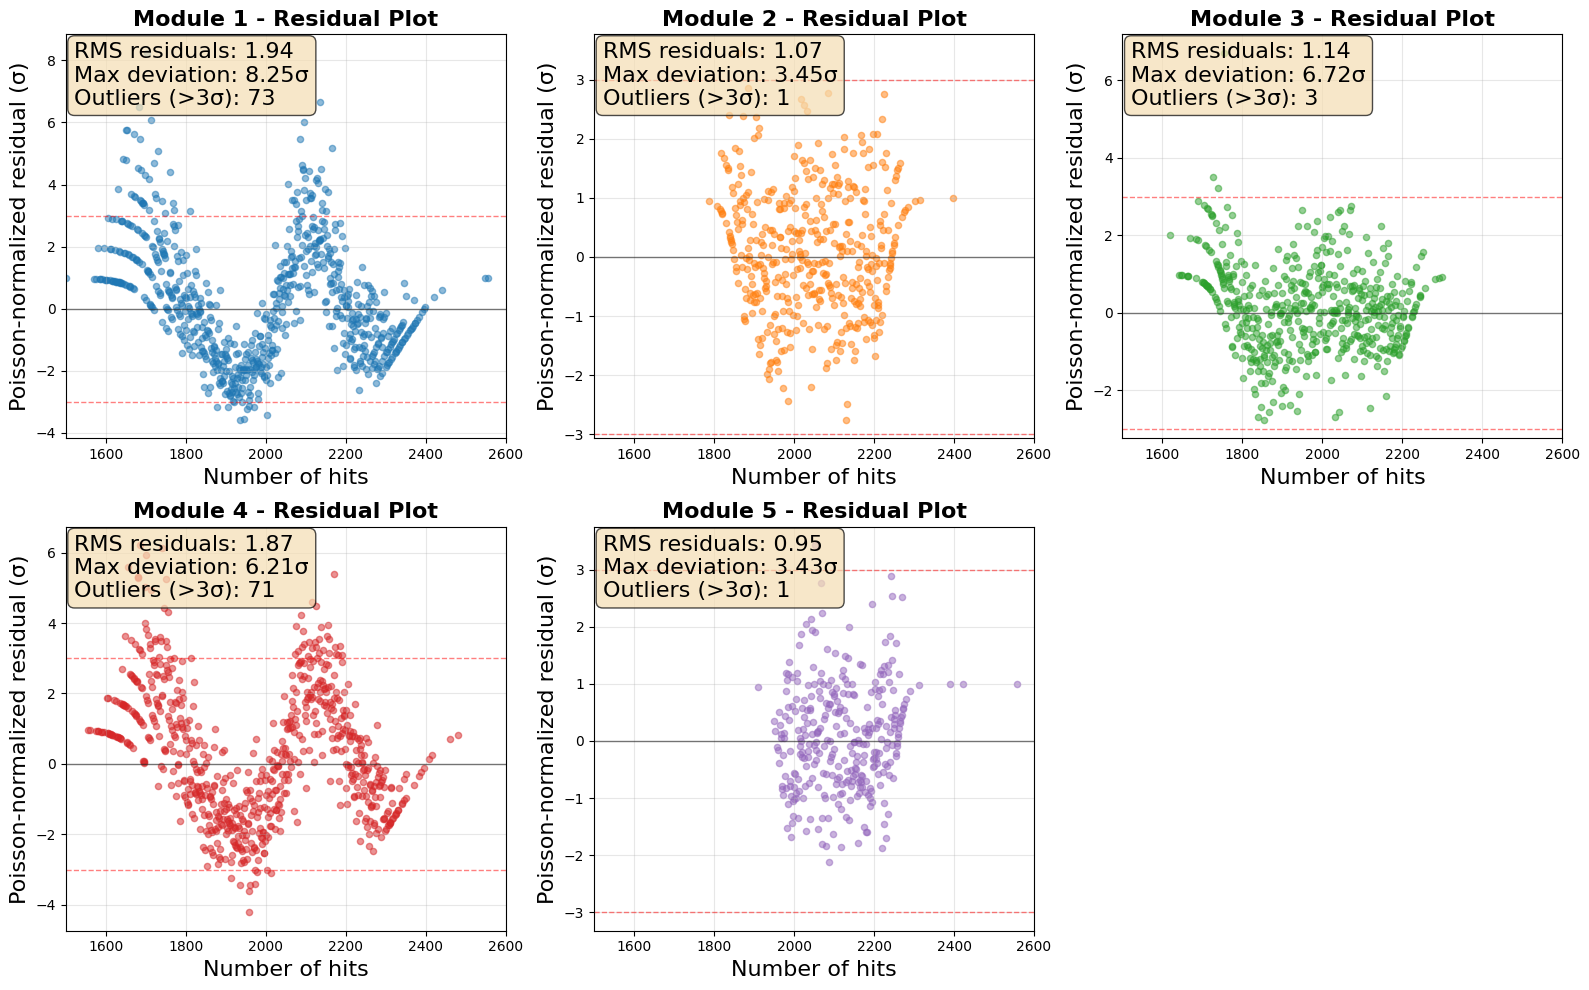


INTERPRETATION (LIKELIHOOD FIT):

For a ROOT Poisson-likelihood fit with bin-integrated expectations, prioritize these checks:
1) Convergence status: status = 0 is the expected successful fit.
2) Residual shape: residuals should fluctuate around 0 without systematic trends.
3) Outlier rate: only a small fraction of bins should exceed ±3σ.

A converged likelihood fit can still be mismodelled if residuals show structure.
Residual plots tell you WHERE the Gaussian model is insufficient.



In [167]:
# Detailed fit diagnostics: Poisson-likelihood residual analysis
print("\n" + "=" * 80)
print("FIT DIAGNOSTICS: POISSON-LIKELIHOOD RESIDUAL ANALYSIS")
print("=" * 80)


fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]

for idx, (hybrid_name, data) in enumerate(histogram_data.items()):
    ax = axes[idx]

    bin_centers = data["bin_centers"]
    bin_contents = data["bin_contents"]

    # Get fit results
    if hybrid_name not in fit_results or fit_results[hybrid_name]["popt"] is None:
        ax.text(0.5, 0.5, f"{hybrid_name}\nNo fit available", ha="center", va="center")
        ax.axis("off")
        continue

    fit_info = fit_results[hybrid_name]
    fit_status = fit_info.get("fit_status", None)
    expected_counts = fit_info.get("expected_counts")
    if expected_counts is None:
        fit_func = fit_info["fit_func"]
        _, _, expected_counts = expected_counts_from_fit(fit_func, data["histogram"])

    expected_counts = np.asarray(expected_counts, dtype=float)
    residuals = bin_contents - expected_counts
    sigma = np.sqrt(np.maximum(expected_counts, 1.0))
    normalized_residuals = residuals / sigma

    # Plot residuals
    finite_mask = bin_contents > 0
    ax.scatter(bin_centers[finite_mask], normalized_residuals[finite_mask],
              alpha=0.5, s=20, color=colors[idx])

    # Add reference lines
    ax.axhline(y=0, color="black", linestyle="-", linewidth=1, alpha=0.5)
    ax.axhline(y=3, color="red", linestyle="--", linewidth=1, alpha=0.5)
    ax.axhline(y=-3, color="red", linestyle="--", linewidth=1, alpha=0.5)

    # Statistics on residuals
    residuals_nz = normalized_residuals[finite_mask]
    rms_residuals = np.sqrt(np.mean(residuals_nz ** 2))
    max_residual = np.max(np.abs(residuals_nz))
    outliers = np.sum(np.abs(residuals_nz) > 3)

    ax.text(
        0.02,
        0.98,
        f"RMS residuals: {rms_residuals:.2f}\n"
        f"Max deviation: {max_residual:.2f}σ\nOutliers (>3σ): {outliers}",
        transform=ax.transAxes,
        va="top",
        fontsize=16,
        bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.7),
    )

    ax.set_xlabel("Number of hits", fontsize=16)
    ax.set_ylabel("Poisson-normalized residual (σ)", fontsize=16)
    ax.set_xlim(1500, 2600)  # Adjust x-axis range for better visibility
    ax.set_title(f"{hybrid_name} - Residual Plot", fontsize=16, fontweight="bold")
    ax.grid(alpha=0.3)

axes[-1].axis("off")
plt.tight_layout()
plt.show()

print("\n" + "=" * 80)
print("INTERPRETATION (LIKELIHOOD FIT):")
print("=" * 80)
print("""
For a ROOT Poisson-likelihood fit with bin-integrated expectations, prioritize these checks:
1) Convergence status: status = 0 is the expected successful fit.
2) Residual shape: residuals should fluctuate around 0 without systematic trends.
3) Outlier rate: only a small fraction of bins should exceed ±3σ.

A converged likelihood fit can still be mismodelled if residuals show structure.
Residual plots tell you WHERE the Gaussian model is insufficient.
""")
print("=" * 80)

In [168]:
#Module 2 and 5 seems not to have much CM noise

In [169]:
#Study of gamma of modules

In [170]:
# Recompute Gamma (Eq.19/20) and common-mode noise at MODULE level,
# combining each module's two hybrids' Top+Bottom StripChannelNoise histograms
# (instead of the per-hybrid, per-side granularity used above)
import math
import numpy as np
import pandas as pd
import ROOT

root_file = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root", "READ")

def compute_gamma(hist, mean_fit, std_fit):
    n_channels = int(hist.GetNbinsX() - 1)
    mean_hits = float(mean_fit)
    variance_hits = float(std_fit) ** 2
    alpha_tilde = 2.0 * math.pi * (variance_hits - mean_hits * (1.0 - mean_hits / n_channels)) / (n_channels * (n_channels - 1))
    sin_alpha = math.sin(alpha_tilde)
    gamma_sq = sin_alpha / (1.0 - sin_alpha) if (1.0 - sin_alpha) != 0 else 0.0
    return math.sqrt(max(gamma_sq, 0.0))

# This function performs sigma-clipping on a list of values to compute a robust mean and standard deviation.
def sigma_clipped_stats(values, sigma, maxiters):
    vals = np.asarray(values, dtype=float).copy()
    vals = vals[np.isfinite(vals)]
    if vals.size == 0:
        return (np.nan, np.nan, 0, 0, 0)
    n_initial = vals.size
    for _ in range(maxiters):
        if vals.size <= 1:
            break
        m = vals.mean()
        s = vals.std(ddof=1)
        if s == 0.0:
            break
        keep = np.abs(vals - m) <= sigma * s
        if keep.sum() == vals.size:
            break
        vals = vals[keep]
    n_rejected = n_initial - vals.size
    return (float(vals.mean()) if vals.size > 0 else np.nan, float(vals.std(ddof=1)) if vals.size > 1 else 0.0, int(vals.size), int(n_rejected), int(n_initial))

module_results = []
for module_index in range(5):
    og_name = f"OpticalGroup_{module_index}"
    hybrid_ids = [2 * module_index, 2 * module_index + 1]  # the module's R and L hybrids

    # Module-level CM histogram: already combines both hybrids, no manual merging needed here
    cm_path = f"Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/{og_name}/D_B(0)_CommonNoiseHits_OccupancyDriven_OpticalGroup({module_index})"
    cm_hist = root_file.Get(cm_path)
    if not cm_hist:
        print(f"[SKIP] Missing module CM hist for {og_name}")
        continue

    # Combine the Top+Bottom StripChannelNoise histograms of both hybrids into one sample
    combined_vals = []
    for hybrid_id in hybrid_ids:
        for side in ("Top", "Bottom"):
            strip_path = (
                f"Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/{og_name}/Hybrid_{hybrid_id}/"
                f"D_B(0)_O({module_index})_StripChannelNoise{side}_Hybrid({hybrid_id})"
            )
            strip_hist = root_file.Get(strip_path)
            if not strip_hist:
                print(f"[SKIP] Missing {strip_path}")
                continue
            for i in range(1, strip_hist.GetNbinsX() + 1):
                v = float(strip_hist.GetBinContent(i))
                if np.isfinite(v) and v > 0:
                    combined_vals.append(v)

    x_min = float(cm_hist.GetXaxis().GetXmin())
    x_max = float(cm_hist.GetXaxis().GetXmax())
    peak_bin = cm_hist.GetMaximumBin()
    peak_x = float(cm_hist.GetXaxis().GetBinCenter(peak_bin))
    peak_y = float(cm_hist.GetBinContent(peak_bin))
    fit_name = f"fit_cm_module_{module_index}"
    fit_func = ROOT.TF1(fit_name, "gaus", x_min, x_max)
    fit_func.SetParameters(max(peak_y, 1.0), peak_x, max(float(cm_hist.GetRMS()), 1.0))
    fit_result = cm_hist.Fit(fit_func, "LQ0")
    fit_status = int(fit_result) if fit_result is not None else -1
    mean_fit = float(fit_func.GetParameter(1))
    std_fit = abs(float(fit_func.GetParameter(2)))
    gamma = compute_gamma(cm_hist, mean_fit, std_fit)

    mean_clipped, std_clipped, n_kept, n_rej, n_init = sigma_clipped_stats(combined_vals, sigma=3.0, maxiters=5)
    cm_val = gamma * mean_clipped

    module_results.append({
        'Module': f'Module_{module_index + 1}',
        'Gamma': gamma,
        'fit_status': fit_status,
        'mean_fit': mean_fit,
        'std_fit': std_fit,
        'sigma_single_clipped_mean': mean_clipped,
        'sigma_single_clipped_std': std_clipped,
        'n_initial': n_init,
        'n_rejected': n_rej,
        'CM_VcTh': cm_val,
    })

df_modules = pd.DataFrame(module_results).reset_index(drop=True)
print(df_modules.to_string(index=False, formatters={
    'Gamma': '{:.6f}'.format,
    'mean_fit': '{:.4f}'.format,
    'std_fit': '{:.4f}'.format,
    'sigma_single_clipped_mean': '{:.4f}'.format,
    'sigma_single_clipped_std': '{:.4f}'.format,
    'CM_VcTh': '{:.4f}'.format,
}))

  Module    Gamma  fit_status  mean_fit  std_fit sigma_single_clipped_mean sigma_single_clipped_std  n_initial  n_rejected CM_VcTh
Module_1 0.077812           0 2057.3235 129.7371                    5.3281                   0.3969       4064           9  0.4146
Module_2 0.037806           0 2046.7006  69.0410                    5.3699                   0.3906       4064           1  0.2030
Module_3 0.049871           0 1986.5356  86.8064                    5.2518                   0.3701       4064           2  0.2619
Module_4 0.081187           0 2050.3576 134.9985                    5.3888                   0.4356       4064           1  0.4375
Module_5 0.024772           0 2107.3678  51.2471                    5.3390                   0.4159       4064           3  0.1323



Per-module values:
  Module  CM_VcTh  CM_err
Module_1   0.4146  0.0309
Module_2   0.2030  0.0148
Module_3   0.2619  0.0185
Module_4   0.4375  0.0354
Module_5   0.1323  0.0103
Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0020_fig1.pdf


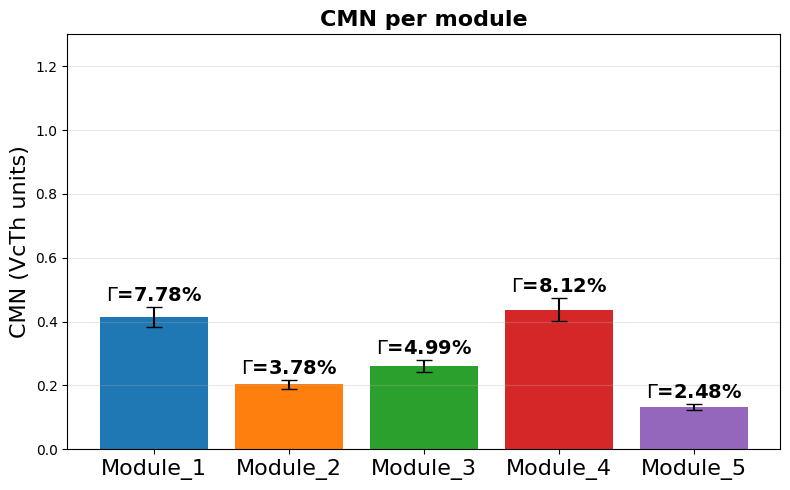

In [171]:
# Summary bar plot: one CM_VcTh value per module
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if 'df' not in globals() or not isinstance(df, pd.DataFrame) or df.empty:
    raise RuntimeError("Run the previous CM computation cells first to create 'df'.")

wanted = ['Module_1','Module_2','Module_3','Module_4','Module_5']
summary = (
    df_modules[df_modules['Module'].isin(wanted)]
    .groupby('Module', as_index=False)
    .agg({
        'CM_VcTh': 'mean',
        'Gamma': 'mean',
        'sigma_single_clipped_std': 'mean'
    })
)
if summary.empty:
    raise RuntimeError('No data for requested hybrids found in df.')

# propagate error
if 'sigma_single_clipped_std' in summary.columns and 'Gamma' in summary.columns:
    summary['CM_err'] = np.abs(summary['Gamma'] * summary['sigma_single_clipped_std'])
else:
    summary['CM_err'] = np.nan

# Plot
fig, ax = plt.subplots(figsize=(8, 5))
inds = np.arange(len(summary))
heights = summary['CM_VcTh'].to_numpy()
errs = summary['CM_err'].to_numpy()
labels = summary['Module'].tolist()

bars = ax.bar(inds, heights, yerr=errs, capsize=6, color=['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd'])
# Annotate each bar with Gamma in percent (Gamma * 100%)
try:
    yrange = float(np.max(heights) - np.min(heights))
except Exception:
    yrange = 1.0
offset = 0.02 * (yrange if yrange > 0 else 1.0)
for rect, g, e in zip(bars, summary['Gamma'].to_numpy(), errs):
    label = f"{g * 100:.2f}%"
    h = rect.get_height()
    # place label above the error bar tip when error is available
    try:
        err_val = float(e)
    except Exception:
        err_val = 0.0
    top = h + abs(err_val)
    y = top + offset
    ax.text(rect.get_x() + rect.get_width() / 2., y, rf'$\Gamma$={label}', ha='center', va='bottom', fontsize=14, fontweight='bold')
ax.set_xticks(inds)
ax.set_xticklabels(labels, fontsize=16)
ax.set_ylabel('CMN (VcTh units)', fontsize=16)
ax.set_title('CMN per module',fontsize=16, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(0, 1.3)

plt.tight_layout()

print('\nPer-module values:')
print(summary[['Module','CM_VcTh','CM_err']].to_string(index=False, float_format='%.4f'))
plt.show()


In [172]:
# Study of the tail of the distribution of 2s modules

In [173]:
import ROOT
import numpy as np
import matplotlib.pyplot as plt

# Ouvrir seulement les fichiers nécessaires
inFile2bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise2bot1mod = inFile2bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_0/D_B(0)_CommonNoiseHits_SigmaNoise_3.00_OpticalGroup(0)")

inFile3bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise3bot1mod = inFile3bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_1/D_B(0)_CommonNoiseHits_SigmaNoise_3.00_OpticalGroup(1)")

inFile4bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ")
Noise4bot1mod = inFile4bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_2/D_B(0)_CommonNoiseHits_SigmaNoise_3.00_OpticalGroup(2)")

inFile5bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise5bot1mod = inFile5bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_3/D_B(0)_CommonNoiseHits_SigmaNoise_3.00_OpticalGroup(3)")

inFile6bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise6bot1mod = inFile6bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_4/D_B(0)_CommonNoiseHits_SigmaNoise_3.00_OpticalGroup(4)")

In [174]:
# Extract bin-by-bin data from the five 2S hybrid histograms
module_histograms = [
    ("Module 1", Noise2bot1mod),
    ("Module 2", Noise3bot1mod),
    ("Module 3", Noise4bot1mod),
    ("Module 4", Noise5bot1mod),
    ("Module 5", Noise6bot1mod),
]

histogram_data = {}

print("\n" + "=" * 80)
print("HISTOGRAM BIN-BY-BIN DATA EXTRACTION")
print("=" * 80)

for module_name, hist in module_histograms:
    if hist is None:
        print(f"\n[SKIP] {module_name}: histogram not found")
        continue
    
    # Extract basic statistics
    entries = int(hist.GetEntries())
    mean = float(hist.GetMean())
    std_dev = float(hist.GetStdDev())
    rms = float(hist.GetRMS())
    
    print(f"\n{module_name}:")
    print(f"  Entries: {entries}")
    print(f"  Mean: {mean:.4f}")
    print(f"  Std Dev: {std_dev:.4f}")
    print(f"  RMS: {rms:.4f}")
    
    # Extract bin-by-bin data
    # ROOT histograms are 1-indexed (bin 0 is underflow, bin N+1 is overflow)
    bin_centers = []
    bin_contents = []
    
    for i in range(1, hist.GetNbinsX() + 1):
        bin_centers.append(hist.GetXaxis().GetBinCenter(i))
        bin_contents.append(hist.GetBinContent(i))
    
    histogram_data[module_name] = {
        "entries": entries,
        "mean": mean,
        "std_dev": std_dev,
        "rms": rms,
        "bin_centers": np.array(bin_centers),
        "bin_contents": np.array(bin_contents),
        "histogram": hist,
    }


HISTOGRAM BIN-BY-BIN DATA EXTRACTION

Module 1:
  Entries: 4065
  Mean: 8.8678
  Std Dev: 3.4743
  RMS: 3.4743

Module 2:
  Entries: 4065
  Mean: 8.2918
  Std Dev: 3.2301
  RMS: 3.2301

Module 3:
  Entries: 4065
  Mean: 9.1191
  Std Dev: 3.5521
  RMS: 3.5521

Module 4:
  Entries: 4065
  Mean: 8.1061
  Std Dev: 3.8843
  RMS: 3.8843

Module 5:
  Entries: 4065
  Mean: 7.9634
  Std Dev: 3.1487
  RMS: 3.1487


In [175]:
# Add Gaussian fits to each histogram on the canvas
import ROOT
import numpy as np
from scipy.stats import norm

# Threshold used by the "SigmaNoise_3.00" histograms below -- keep this in sync with that name.
n_sigma_threshold = 3.0

print("\n" + "=" * 80)
print("ADDING GAUSSIAN FITS TO EACH HISTOGRAM ON CANVAS")
print("=" * 80)

# Create a new canvas with fits
canvas_fit = ROOT.TCanvas("modules_sigma3_with_fits", "Module Common-Mode Noise with Fits (3σ threshold)",1200,400 * rows)
canvas_fit.Divide(cols, rows)

fit_results_canvas = {}
colors_fit = [ROOT.kBlue, ROOT.kRed, ROOT.kGreen+2, ROOT.kMagenta, ROOT.kCyan, 
              ROOT.kOrange+7, ROOT.kYellow+2, ROOT.kSpring+9]

# Keep the fit order aligned with the histogram_data built in this cell
module_names = list(histogram_data.keys())

for i, module_name in enumerate(module_names):
    pad_num = i + 1
    canvas_fit.cd(pad_num)
    ROOT.gPad.SetLeftMargin(0.12)
    ROOT.gPad.SetBottomMargin(0.12)
    ROOT.gPad.SetGrid()
    ROOT.gPad.SetLogy(1)
    
    hist_data = histogram_data.get(module_name)
    if hist_data is None or hist_data["histogram"] is None:
        ROOT.TText(0.2, 0.5, f"No data for {module_name}").Draw()
        continue
    
    hist = hist_data["histogram"]
    
    # Style the histogram
    hist.SetLineColor(colors_fit[i % len(colors_fit)])
    hist.SetLineWidth(2)
    hist.SetFillColor(colors_fit[i % len(colors_fit)])
    hist.SetFillStyle(3004)
    hist.SetTitle(module_name)
    hist.GetXaxis().SetTitle("Number of hits (3σ above noise)")
    hist.GetXaxis().SetRangeUser(0.0, 50.0)
    hist.GetYaxis().SetTitle("Number of events")
    hist.GetXaxis().SetTitleSize(0.05)
    hist.GetYaxis().SetTitleSize(0.05)
    hist.GetXaxis().SetLabelSize(0.04)
    hist.GetYaxis().SetLabelSize(0.04)
    
    # Draw histogram
    hist.Draw("HIST")
    
    # Perform Gaussian fit
    x_min = float(hist.GetXaxis().GetXmin())
    x_max = float(hist.GetXaxis().GetXmax())
    
    # Find peak for initial guess
    peak_idx = hist.GetMaximumBin()
    peak_x = hist.GetXaxis().GetBinCenter(peak_idx)
    peak_y = hist.GetBinContent(peak_idx)
    
    # Create fit function
    safe_name = "".join(ch if ch.isalnum() else "_" for ch in f"fit_modules_{module_name}")
    fit_func = ROOT.TF1(safe_name, "gaus", x_min, x_max)
    
    # Set initial parameters
    mean_guess = hist_data["mean"]
    std_guess = hist_data["std_dev"]
    amplitude_guess = max(peak_y, 1.0)
    
    fit_func.SetParameters(amplitude_guess, mean_guess, std_guess)
    fit_func.SetParLimits(0, 0.0, max(amplitude_guess * 10.0, 1.0))
    fit_func.SetParLimits(1, x_min, x_max)
    fit_func.SetParLimits(2, 1e-6, max(x_max - x_min, std_guess * 10.0))
    
    # Perform fit
    try:
        fit_result = hist.Fit(fit_func, "LQRS")
        fit_status = int(fit_result)
        
        amplitude_fit = float(fit_func.GetParameter(0))
        mean_fit = float(fit_func.GetParameter(1))
        std_fit = abs(float(fit_func.GetParameter(2)))
        
        # Get parameter errors
        amplitude_err = float(fit_func.GetParError(0))
        mean_err = float(fit_func.GetParError(1))
        std_err = abs(float(fit_func.GetParError(2)))
        
        fit_results_canvas[module_name] = {
            "amplitude": amplitude_fit,
            "amplitude_err": amplitude_err,
            "mean": mean_fit,
            "mean_err": mean_err,
            "std": std_fit,
            "std_err": std_err,
            "status": fit_status,
            "fit_func": fit_func,
        }
        
        # Draw fit function in orange
        #fit_func.SetLineColor(ROOT.kOrange)
        #fit_func.SetLineWidth(2)
        #fit_func.SetLineStyle(7)  # dashed line
        #fit_func.Draw("SAME")
        
        # Fit and overlay a theoretical Poisson distribution for the no-CMN expectation
        # Cap the evaluation domain well below where TMath::Gamma(x+1) overflows to inf (~x>170);
        # a TF1 that hits NaN/Inf anywhere in its declared range fails to draw at all, even in the
        # (perfectly finite) low-x region actually visible on the plot.
        poisson_x_max = min(x_max, 100.0)
        poisson_name = "".join(ch if ch.isalnum() else "_" for ch in f"poisson_modules_{module_name}")
        poisson_func = ROOT.TF1(poisson_name, "[0] * TMath::Exp(-[1]) * TMath::Power([1], x) / TMath::Gamma(x + 1.0)", x_min, poisson_x_max)
        poisson_func.SetNpx(500)
        poisson_norm_guess = max(float(hist.Integral()), 1.0)
        poisson_lambda_guess = max(mean_guess, 1e-6)
        poisson_func.SetParameter(0, poisson_norm_guess)
        poisson_func.FixParameter(0, poisson_norm_guess)
        poisson_func.SetParameter(1, poisson_lambda_guess)
        poisson_func.SetParLimits(1, 1e-6, max(x_max, poisson_lambda_guess * 10.0))
        
        try:
            poisson_result = hist.Fit(poisson_func, "LQRS")
            poisson_status = int(poisson_result)
            
            poisson_lambda_fit = float(poisson_func.GetParameter(1))
            poisson_lambda_err = float(poisson_func.GetParError(1))
            
            poisson_func.SetLineColor(ROOT.kBlack)
            poisson_func.SetLineWidth(2)
            #poisson_func.SetLineStyle(7)
            poisson_func.Draw("SAME")
            
            fit_results_canvas[module_name]["poisson"] = {
                "norm": poisson_norm_guess,
                "norm_err": 0.0,
                "lambda": poisson_lambda_fit,
                "lambda_err": poisson_lambda_err,
                "status": poisson_status,
                "fit_func": poisson_func,
            }
            
            print(f"  Poisson Norm: {poisson_norm_guess:.4f} (fixed)")
            print(f"  Poisson Lambda: {poisson_lambda_fit:.4f} ± {poisson_lambda_err:.4f}")

            # Theoretical Poisson expectation with NO common-mode noise: if every strip's noise
            # were an independent Gaussian, the number of channels crossing a pure n_sigma_threshold
            # would be Poisson with lambda = n_channels * P(Z > n_sigma_threshold) (one-sided Gaussian
            # tail). Unlike poisson_func above, this lambda is NOT fit -- it's fixed from the physical
            # channel count and the threshold, so the gap to the data/fit shows the CMN excess.
            n_channels = int(hist.GetNbinsX()) - 1
            lambda_theory = n_channels * norm.sf(n_sigma_threshold)
            theory_name = "".join(ch if ch.isalnum() else "_" for ch in f"poisson_theory_modules_{module_name}")
            theory_func = ROOT.TF1(theory_name, "[0] * TMath::Exp(-[1]) * TMath::Power([1], x) / TMath::Gamma(x + 1.0)", x_min, poisson_x_max)
            theory_func.SetNpx(500)
            theory_func.FixParameter(0, poisson_norm_guess)
            theory_func.FixParameter(1, lambda_theory)
            theory_func.SetLineColor(ROOT.kGray + 2)
            theory_func.SetLineWidth(2)
            theory_func.SetLineStyle(2)
            theory_func.Draw("SAME")

            fit_results_canvas[module_name]["poisson_theory"] = {
                "n_channels": n_channels,
                "lambda": lambda_theory,
                "fit_func": theory_func,
            }

            print(f"  Poisson (theory, no CMN): n_channels={n_channels}, lambda={lambda_theory:.4f}")

            legend_fit = ROOT.TLegend(0.30, 0.72, 0.95, 0.92)
            legend_fit.AddEntry(hist, "Data (3σ hits)", "f")
            legend_fit.AddEntry(poisson_func, "Poisson fit (λ = data mean)", "l")
            legend_fit.AddEntry(theory_func, "Poisson theory", "l")
            legend_fit.SetTextSize(0.04)
            legend_fit.SetFillStyle(0)
            legend_fit.SetBorderSize(0)
            legend_fit.Draw()
        except Exception as e:
            print(f"  Poisson fit failed - {e}")
            fit_results_canvas[module_name]["poisson"] = {"status": -1, "error": str(e)}
        
        # Add legend
        #legend = ROOT.TLegend(0.55, 0.7, 0.95, 0.95)
        #legend.AddEntry(hist, "Data", "f")
        #legend.AddEntry(fit_func, "Gaussian Fit", "l")
        #if fit_results_canvas[module_name].get("poisson", {}).get("status", -1) >= 0:
        #    legend.AddEntry(poisson_func, "Poisson fit", "l")
        #legend.SetTextSize(0.04)
        #legend.SetFillStyle(0)
        #legend.Draw()
        
        # Print fit results with parameter errors
        print(f"\n{module_name}:")
        print(f"  Fit Status: {fit_status}")
        print(f"  Amplitude: {amplitude_fit:.4f} ± {amplitude_err:.4f}")
        print(f"  Mean: {mean_fit:.4f} ± {mean_err:.4f}")
        print(f"  Std Dev: {std_fit:.4f} ± {std_err:.4f}")
        
    except Exception as e:
        print(f"\n{module_name}: Fit failed - {e}")
        fit_results_canvas[module_name] = {"status": -1, "error": str(e)}

# Hide empty pads
for i in range(len(module_names), rows * cols):
    canvas_fit.cd(i + 1)
    ROOT.gPad.Draw()

canvas_fit.Update()
canvas_fit.Draw()

print("\n" + "=" * 80)
print("FITTING COMPLETE")
print("=" * 80)



ADDING GAUSSIAN FITS TO EACH HISTOGRAM ON CANVAS


  Poisson Norm: 10000.0000 (fixed)
  Poisson Lambda: 8.8678 ± 0.0298
  Poisson (theory, no CMN): n_channels=4064, lambda=5.4860

Module 1:
  Fit Status: 0
  Amplitude: 1134.2701 ± 14.0753
  Mean: 8.8254 ± 0.0360
  Std Dev: 3.5314 ± 0.0268
  Poisson Norm: 10000.0000 (fixed)
  Poisson Lambda: 8.2918 ± 0.0288
  Poisson (theory, no CMN): n_channels=4064, lambda=5.4860

Module 2:
  Fit Status: 0
  Amplitude: 1220.9564 ± 15.1430
  Mean: 8.2555 ± 0.0334
  Std Dev: 3.2795 ± 0.0248
  Poisson Norm: 10000.0000 (fixed)
  Poisson Lambda: 9.1191 ± 0.0302
  Poisson (theory, no CMN): n_channels=4064, lambda=5.4860

Module 3:
  Fit Status: 0
  Amplitude: 1109.7936 ± 13.7682
  Mean: 9.0772 ± 0.0368
  Std Dev: 3.6087 ± 0.0274
  Poisson Norm: 10000.0000 (fixed)
  Poisson Lambda: 8.1061 ± 0.0285
  Poisson (theory, no CMN): n_channels=4064, lambda=5.4860

Module 4:
  Fit Status: 0
  Amplitude: 991.6995 ± 12.4211
  Mean: 7.9019 ± 0.0446
  Std Dev: 4.1053 ± 0.0350
  Poisson Norm: 10000.0000 (fixed)
  Poisson 

Warning in <TCanvas::Constructor>: Deleting canvas with same name: modules_sigma3_with_fits


In [176]:
# The title "Sigma Noise = 3.00" indicates that a hit is only recorded if the signal exceeds three times the standard deviation of the pedestal noise.
# Assessing Noise Suppression: If CMN is perfectly subtracted and the remaining noise is purely random (Gaussian), the number of hits above $3\sigma$ should follow a narrow Poisson distribution.
# Identifying "Hot" Events: The tail of the distribution extending toward 25–30 hits shows events where the module recorded significantly more noise than average. This often indicates residual CMN—noise that was not fully subtracted and caused multiple strips to fire simultaneously.
# Mean Occupancy: A mean of 9.04 hits (for module1) per event across a module with thousands of strips is generally considered a low noise occupancy, suggesting the $3\sigma$ threshold is effectively filtering out most intrinsic noise.
# The "W" pattern you found in your previous residual fits suggests that the noise is not perfectly Gaussian. This aggregate plot is the "real world" result of that mismatch: those non-Gaussian tails in the noise distribution are what create the higher-hit events (the tail on the right) in this occupancy plot.
# If your CMN subtraction is poor, a single noise "burst" will cause many strips to fire at the same time and The distribution will become much wider, with a long tail stretching to the right
# If the noise has "heavier tails" than a Gaussian, you will see more hits than predicted by Poisson logic, specifically appearing as those outliers in the higher-hit bins of the 3sigma distribution.

In [177]:
# Study of CM noise for right left hybrid of 2S modules (5 modules)

In [178]:
import ROOT
import numpy as np
import matplotlib.pyplot as plt

# Ouvrir seulement les fichiers nécessaires
inFile2bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise2bot1mod = inFile2bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_0/D_B(0)_CommonNoiseCrossHybridCorrelation_OccupancyDriven_OpticalGroup(0)")

#inFile3bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
#Noise3bot1mod = inFile3bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_1/D_B(0)_CommonNoiseCrossHybridCorrelation_OccupancyDriven_OpticalGroup(1)")

inFile4bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ")
Noise4bot1mod = inFile4bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_2/D_B(0)_CommonNoiseCrossHybridCorrelation_OccupancyDriven_OpticalGroup(2)")

#inFile5bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
#Noise5bot1mod = inFile5bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_3/D_B(0)_CommonNoiseCrossHybridCorrelation_OccupancyDriven_OpticalGroup(3)")

#inFile6bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
#Noise6bot1mod = inFile6bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_4/D_B(0)_CommonNoiseCrossHybridCorrelation_OccupancyDriven_OpticalGroup(4)")

In [179]:
# Display the five extracted Noise histograms using ROOT canvases
from ROOT import TCanvas, gStyle, gPad
plots = [
    #("Module_1", Noise2bot1mod),
    #("Module_2", Noise3bot1mod),
    ("Module_3", Noise4bot1mod),
    #("Module_4", Noise5bot1mod),
    #("Module_5", Noise6bot1mod),
]
available = [(name, obj) for name, obj in plots if obj is not None]
if len(available) == 0:
    print("No Noise histograms found. Ensure the prior cell ran successfully.")
else:
    n = len(plots)
    c = TCanvas("c_noise", "Noise histograms",800 * max(1, n),600)
    c.Divide(n, 1)
    for i, (name, obj) in enumerate(plots):
        c.cd(i + 1)
        try:
            if obj is None:
                continue
            if hasattr(obj, 'SetTitle'):
                obj.SetTitle(name)
            if hasattr(obj, 'InheritsFrom') and obj.InheritsFrom('TH2'):
                obj.Draw('COLZ')
            else:
                try:
                    obj.SetLineWidth(2)
                except Exception:
                    pass
                obj.Draw()
            gPad.Update()
        except Exception as e:
            print(f'Failed to draw {name}: {e}')
    c.Update()
    globals()['c_noise'] = c

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c_noise


In [180]:
# Module 2,3,5 seems not to have much CM noise, while module 1 and 4 have have more CM noise. 
# The CM noise seems to be higher for bottom strips than for top strips, which is consistent with the fact that the bottom strips have higher occupancy (more noise hits) than the top strips

In [181]:
# Study of CM noise for top and bottom L AND R hybrids

In [182]:
import ROOT
import numpy as np
import matplotlib.pyplot as plt

# Ouvrir seulement les fichiers nécessaires
inFile2bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise2bot1mod = inFile2bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_0/Hybrid_1/D_B(0)_O(0)_CommonNoiseTopBottomCorrelation_OccupancyDriven_Hybrid(1)")

inFile3bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise3bot1mod = inFile3bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_1/Hybrid_3/D_B(0)_O(1)_CommonNoiseTopBottomCorrelation_OccupancyDriven_Hybrid(3)")

inFile4bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ")
Noise4bot1mod = inFile4bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_2/Hybrid_5/D_B(0)_O(2)_CommonNoiseTopBottomCorrelation_OccupancyDriven_Hybrid(5)")

inFile5bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise5bot1mod = inFile5bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_3/Hybrid_7/D_B(0)_O(3)_CommonNoiseTopBottomCorrelation_OccupancyDriven_Hybrid(7)")

inFile6bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise6bot1mod = inFile6bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_4/Hybrid_9/D_B(0)_O(4)_CommonNoiseTopBottomCorrelation_OccupancyDriven_Hybrid(9)")

inFile7bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise7bot1mod = inFile7bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_0/Hybrid_0/D_B(0)_O(0)_CommonNoiseTopBottomCorrelation_OccupancyDriven_Hybrid(0)")

inFile8bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise8bot1mod = inFile8bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_1/Hybrid_2/D_B(0)_O(1)_CommonNoiseTopBottomCorrelation_OccupancyDriven_Hybrid(2)")

inFile9bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ")
Noise9bot1mod = inFile9bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_2/Hybrid_4/D_B(0)_O(2)_CommonNoiseTopBottomCorrelation_OccupancyDriven_Hybrid(4)")

inFile10bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise10bot1mod = inFile10bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_3/Hybrid_6/D_B(0)_O(3)_CommonNoiseTopBottomCorrelation_OccupancyDriven_Hybrid(6)")

inFile11bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise11bot1mod = inFile11bot1mod.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_4/Hybrid_8/D_B(0)_O(4)_CommonNoiseTopBottomCorrelation_OccupancyDriven_Hybrid(8)")

In [183]:
# Display the five extracted Noise histograms using ROOT canvases
from ROOT import TCanvas, gStyle, gPad
plots = [
    ("Hybrid_0", Noise7bot1mod),
    ("Hybrid_1", Noise2bot1mod),
    ("Hybrid_2", Noise8bot1mod),
    ("Hybrid_3", Noise3bot1mod),
    ("Hybrid_4", Noise9bot1mod),
    ("Hybrid_5", Noise4bot1mod),
    ("Hybrid_6", Noise10bot1mod),
    ("Hybrid_7", Noise5bot1mod),
    ("Hybrid_8", Noise11bot1mod),
    ("Hybrid_9", Noise6bot1mod),
    
    
]
available = [(name, obj) for name, obj in plots if obj is not None]
if len(available) == 0:
    print("No Noise histograms found. Ensure the prior cell ran successfully.")
else:
    n = len(plots)
    c = TCanvas("c_noise", "Noise histograms",800 * max(1, n),600)
    c.Divide(n, 1)
    for i, (name, obj) in enumerate(plots):
        c.cd(i + 1)
        try:
            if obj is None:
                continue
            if hasattr(obj, 'SetTitle'):
                obj.SetTitle(name)
            if hasattr(obj, 'InheritsFrom') and obj.InheritsFrom('TH2'):
                obj.Draw('COLZ')
            else:
                try:
                    obj.SetLineWidth(2)
                except Exception:
                    pass
                obj.Draw()
            gPad.Update()
        except Exception as e:
            print(f'Failed to draw {name}: {e}')
    c.Update()
    globals()['c_noise'] = c

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c_noise


In [184]:
# Mean number of hits on bottom strips of each hybrid is higher than the mean number of hits on top strips
# Particularly true for hybrid 0,2,4,6,8
# This is consistent with the fact that the bottom strips have higher occupancy (more noise hits) than the top strips

# the CM noise seems to be higher for top strips of hybrids 0,2,4,6,8 (big diff of std dev for top and bottom strips)
# the CM noise seems to be higher for bottom strips of hybrids 1,3,5,7,9 (small diff of std dev for top and bottom strips)

# We also see again that hybrid 1,3,5,7,9 have higher occupancy because the mean number of hits on the bottom and top strips are higher than hybrids 0,2,4,6,8.

In [185]:
import ROOT
import numpy as np
import matplotlib.pyplot as plt

# Ouvrir seulement les fichiers nécessaires
inFile2bot1 = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise2bot1 = inFile2bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_0/Hybrid_0/D_B(0)_O(0)_CommonNoiseHitsTop_OccupancyDriven_Hybrid(0)")
Noise2bot1prime = inFile2bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_0/Hybrid_0/D_B(0)_O(0)_CommonNoiseHitsBottom_OccupancyDriven_Hybrid(0)")

Noise2bot2 = inFile2bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_0/Hybrid_1/D_B(0)_O(0)_CommonNoiseHitsTop_OccupancyDriven_Hybrid(1)")
Noise2bot2prime = inFile2bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_0/Hybrid_1/D_B(0)_O(0)_CommonNoiseHitsBottom_OccupancyDriven_Hybrid(1)")


inFile3bot1 = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise3bot1 = inFile3bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_1/Hybrid_2/D_B(0)_O(1)_CommonNoiseHitsTop_OccupancyDriven_Hybrid(2)")
Noise3bot1prime = inFile3bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_1/Hybrid_2/D_B(0)_O(1)_CommonNoiseHitsBottom_OccupancyDriven_Hybrid(2)")

Noise3bot2 = inFile3bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_1/Hybrid_3/D_B(0)_O(1)_CommonNoiseHitsTop_OccupancyDriven_Hybrid(3)")
Noise3bot2prime = inFile3bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_1/Hybrid_3/D_B(0)_O(1)_CommonNoiseHitsBottom_OccupancyDriven_Hybrid(3)")


inFile4bot1 = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ")
Noise4bot1 = inFile4bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_2/Hybrid_4/D_B(0)_O(2)_CommonNoiseHitsTop_OccupancyDriven_Hybrid(4)")
Noise4bot1prime = inFile4bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_2/Hybrid_4/D_B(0)_O(2)_CommonNoiseHitsBottom_OccupancyDriven_Hybrid(4)")

Noise4bot2 = inFile4bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_2/Hybrid_5/D_B(0)_O(2)_CommonNoiseHitsTop_OccupancyDriven_Hybrid(5)")
Noise4bot2prime = inFile4bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_2/Hybrid_5/D_B(0)_O(2)_CommonNoiseHitsBottom_OccupancyDriven_Hybrid(5)")


inFile5bot1 = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise5bot1 = inFile5bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_3/Hybrid_6/D_B(0)_O(3)_CommonNoiseHitsTop_OccupancyDriven_Hybrid(6)")
Noise5bot1prime = inFile5bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_3/Hybrid_6/D_B(0)_O(3)_CommonNoiseHitsBottom_OccupancyDriven_Hybrid(6)")

Noise5bot2 = inFile5bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_3/Hybrid_7/D_B(0)_O(3)_CommonNoiseHitsTop_OccupancyDriven_Hybrid(7)")
Noise5bot2prime = inFile5bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_3/Hybrid_7/D_B(0)_O(3)_CommonNoiseHitsBottom_OccupancyDriven_Hybrid(7)")


inFile6bot1 = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root","READ") 
Noise6bot1 = inFile6bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_4/Hybrid_8/D_B(0)_O(4)_CommonNoiseHitsTop_OccupancyDriven_Hybrid(8)")
Noise6bot1prime = inFile6bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_4/Hybrid_8/D_B(0)_O(4)_CommonNoiseHitsBottom_OccupancyDriven_Hybrid(8)")

Noise6bot2 = inFile6bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_4/Hybrid_9/D_B(0)_O(4)_CommonNoiseHitsTop_OccupancyDriven_Hybrid(9)")
Noise6bot2prime = inFile6bot1.Get("Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/OpticalGroup_4/Hybrid_9/D_B(0)_O(4)_CommonNoiseHitsBottom_OccupancyDriven_Hybrid(9)")


In [186]:
# Extract bin-by-bin data from the five 2S hybrid histograms
hybrid_histograms = [
    ("Hybrid 0 top", Noise2bot1),
    ("Hybrid 0 bottom", Noise2bot1prime),
    ("Hybrid 1 top", Noise2bot2),
    ("Hybrid 1 bottom", Noise2bot2prime),
    ("Hybrid 2 top", Noise3bot1),
    ("Hybrid 2 bottom", Noise3bot1prime),
    ("Hybrid 3 top", Noise3bot2),
    ("Hybrid 3 bottom", Noise3bot2prime),
    ("Hybrid 4 top", Noise4bot1),
    ("Hybrid 4 bottom", Noise4bot1prime),
    ("Hybrid 5 top", Noise4bot2),
    ("Hybrid 5 bottom", Noise4bot2prime),
    ("Hybrid 6 top", Noise5bot1),
    ("Hybrid 6 bottom", Noise5bot1prime),
    ("Hybrid 7 top", Noise5bot2),
    ("Hybrid 7 bottom", Noise5bot2prime),
    ("Hybrid 8 top", Noise6bot1),
    ("Hybrid 8 bottom", Noise6bot1prime),
    ("Hybrid 9 top", Noise6bot2),
    ("Hybrid 9 bottom", Noise6bot2prime),
    
]

histogram_data = {}

print("\n" + "=" * 80)
print("HISTOGRAM BIN-BY-BIN DATA EXTRACTION")
print("=" * 80)

for hybrid_name, hist in hybrid_histograms:
    if hist is None:
        print(f"\n[SKIP] {hybrid_name}: histogram not found")
        continue
    
    # Extract basic statistics
    entries = int(hist.GetEntries())
    mean = float(hist.GetMean())
    std_dev = float(hist.GetStdDev())
    rms = float(hist.GetRMS())
    
    print(f"\n{hybrid_name}:")
    print(f"  Entries: {entries}")
    print(f"  Mean: {mean:.4f}")
    print(f"  Std Dev: {std_dev:.4f}")
    print(f"  RMS: {rms:.4f}")
    
    # Extract bin-by-bin data
    # ROOT histograms are 1-indexed (bin 0 is underflow, bin N+1 is overflow)
    bin_centers = []
    bin_contents = []
    
    for i in range(1, hist.GetNbinsX() + 1):
        bin_centers.append(hist.GetXaxis().GetBinCenter(i))
        bin_contents.append(hist.GetBinContent(i))
    
    histogram_data[hybrid_name] = {
        "entries": entries,
        "mean": mean,
        "std_dev": std_dev,
        "rms": rms,
        "bin_centers": np.array(bin_centers),
        "bin_contents": np.array(bin_contents),
        "histogram": hist,
    }


HISTOGRAM BIN-BY-BIN DATA EXTRACTION

Hybrid 0 top:
  Entries: 2033
  Mean: 479.7450
  Std Dev: 66.9860
  RMS: 66.9860

Hybrid 0 bottom:
  Entries: 2033
  Mean: 491.6600
  Std Dev: 56.3894
  RMS: 56.3894

Hybrid 1 top:
  Entries: 2033
  Mean: 540.3757
  Std Dev: 78.2954
  RMS: 78.2954

Hybrid 1 bottom:
  Entries: 2033
  Mean: 545.5428
  Std Dev: 80.8560
  RMS: 80.8560

Hybrid 2 top:
  Entries: 2033
  Mean: 475.2551
  Std Dev: 78.8355
  RMS: 78.8355

Hybrid 2 bottom:
  Entries: 2033
  Mean: 485.5512
  Std Dev: 66.8733
  RMS: 66.8733

Hybrid 3 top:
  Entries: 2033
  Mean: 540.7103
  Std Dev: 67.2369
  RMS: 67.2369

Hybrid 3 bottom:
  Entries: 2033
  Mean: 545.1840
  Std Dev: 69.4590
  RMS: 69.4590

Hybrid 4 top:
  Entries: 2033
  Mean: 456.3600
  Std Dev: 75.7140
  RMS: 75.7140

Hybrid 4 bottom:
  Entries: 2033
  Mean: 468.2386
  Std Dev: 66.8239
  RMS: 66.8239

Hybrid 5 top:
  Entries: 2033
  Mean: 529.3385
  Std Dev: 69.1593
  RMS: 69.1593

Hybrid 5 bottom:
  Entries: 2033
  Mean: 532


HISTOGRAM FITTING AND PEAK ANALYSIS
DATASET: Hybrids Top and bottom strips
Using ROOT binned likelihood fit with Poisson bin statistics.

Hybrid 0 top:
  Peak found at x=505.0, height=76.0
  Total peaks detected: 61
  ROOT likelihood fit:
    Status:     0
    Amplitude:  59.5567 ± 0.7294
    Mean:       479.7449 ± 0.6699
    Std Dev:    66.9853 ± 0.4737

Hybrid 0 bottom:
  Peak found at x=502.0, height=90.0
  Total peaks detected: 53
  ROOT likelihood fit:
    Status:     0
    Amplitude:  70.7488 ± 0.8665
    Mean:       491.6600 ± 0.5639
    Std Dev:    56.3886 ± 0.3987

Hybrid 1 top:
  Peak found at x=516.0, height=85.0
  Total peaks detected: 85
  ROOT likelihood fit:
    Status:     0
    Amplitude:  50.9541 ± 0.6241
    Mean:       540.3738 ± 0.7829
    Std Dev:    78.2940 ± 0.5536

Hybrid 1 bottom:
  Peak found at x=532.0, height=81.0
  Total peaks detected: 79
  ROOT likelihood fit:
    Status:     0
    Amplitude:  49.3404 ± 0.6043
    Mean:       545.5410 ± 0.8086
    Std D

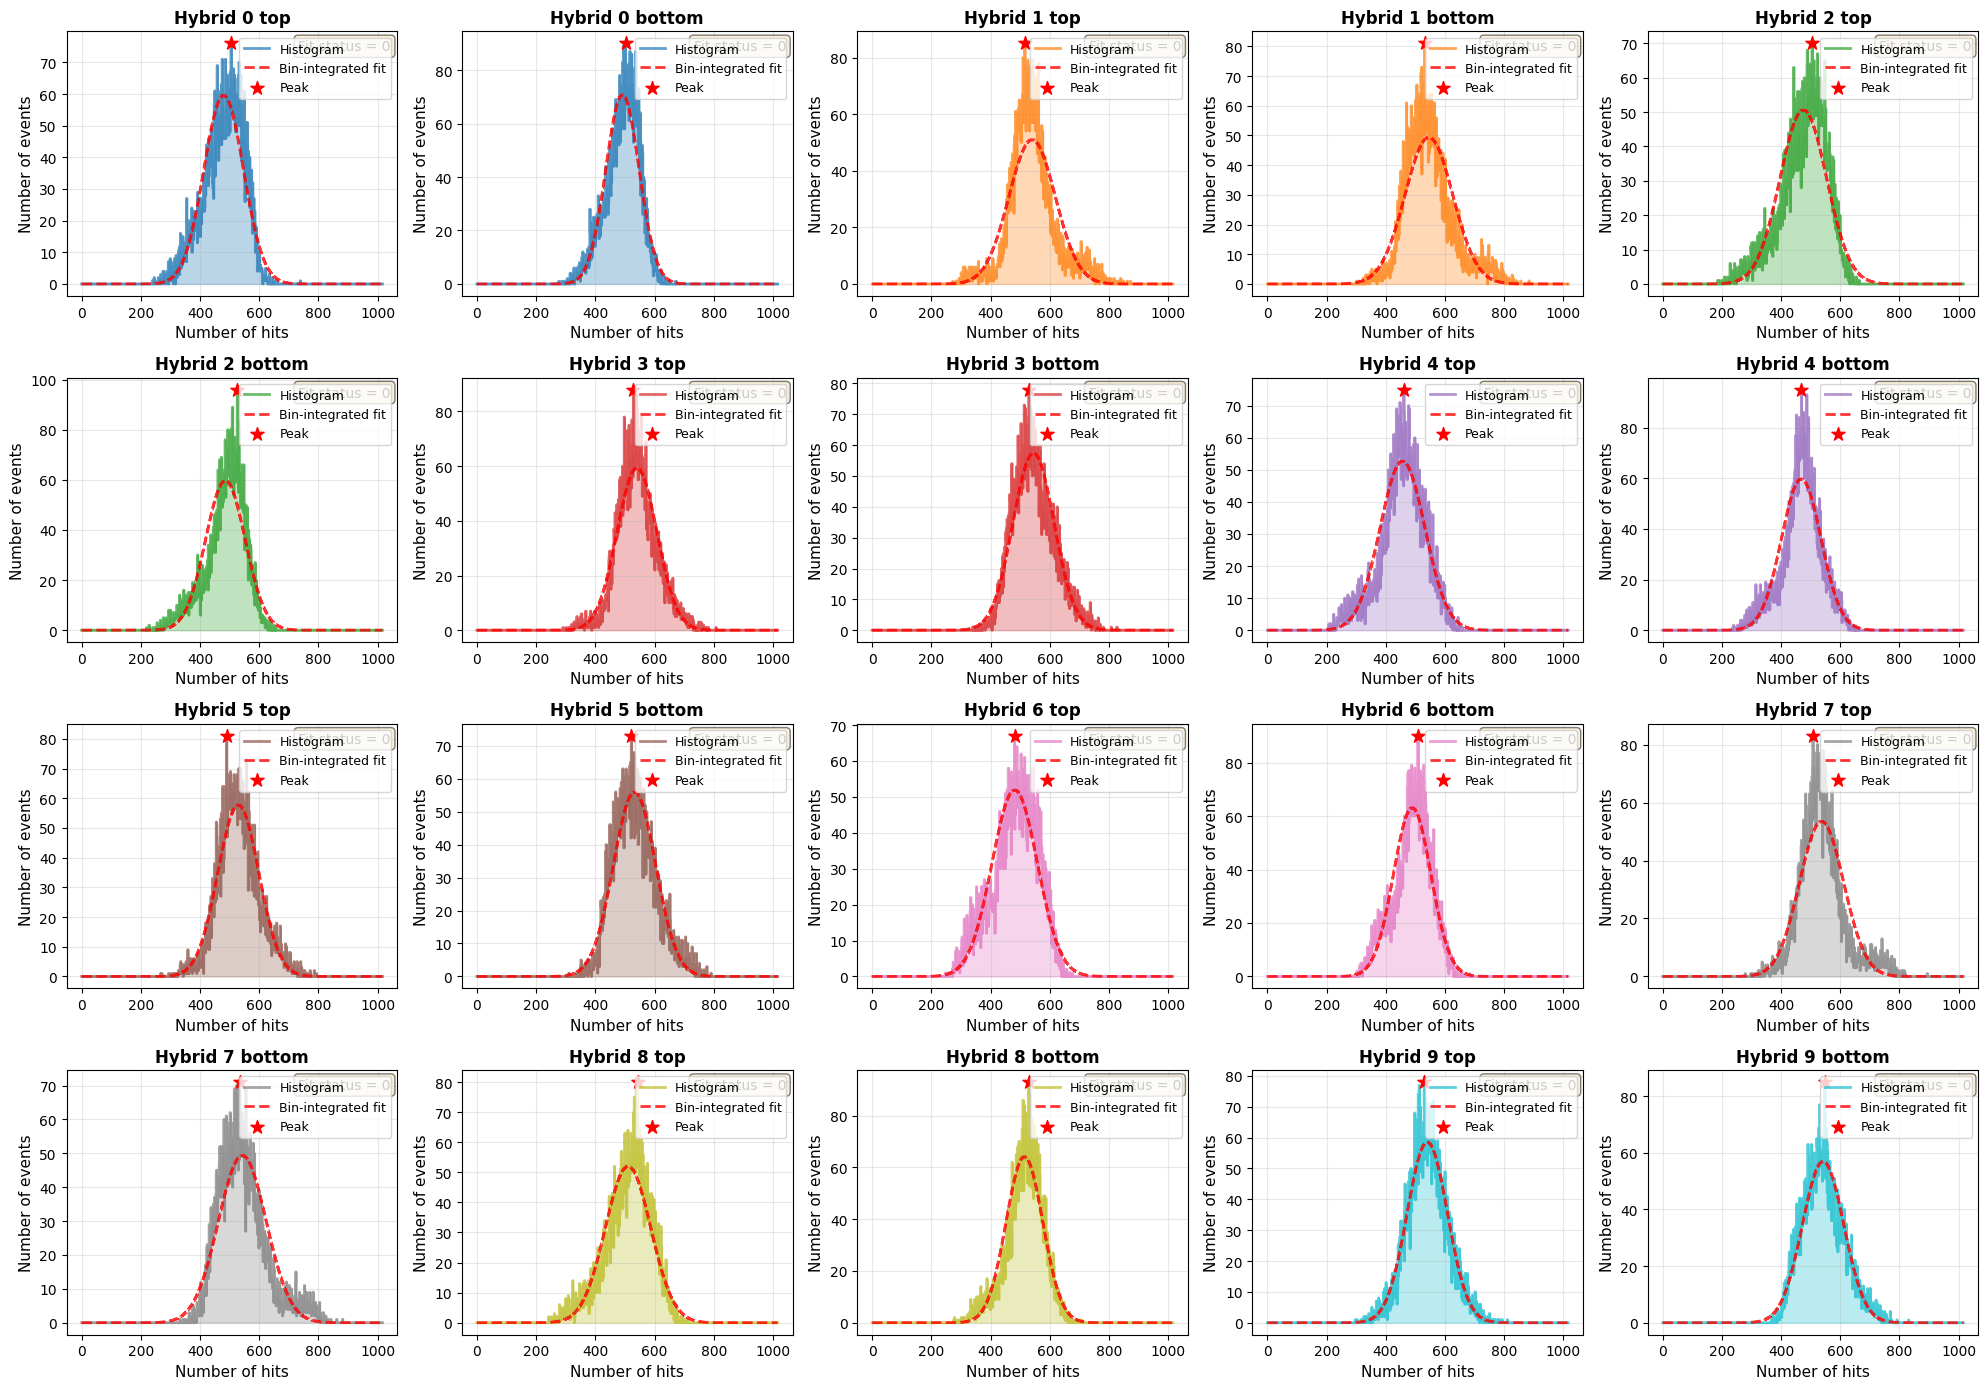


COMPARISON SUMMARY
         Hybrid     Mean   Std Dev  Entries  Peak  Peak Height
   Hybrid 0 top 479.7450 66.986015     2033 505.0         76.0
Hybrid 0 bottom 491.6600 56.389428     2033 502.0         90.0
   Hybrid 1 top 540.3757 78.295417     2033 516.0         85.0
Hybrid 1 bottom 545.5428 80.856042     2033 532.0         81.0
   Hybrid 2 top 475.2551 78.835500     2033 505.0         70.0
Hybrid 2 bottom 485.5512 66.873298     2033 526.0         96.0
   Hybrid 3 top 540.7103 67.236945     2033 529.0         88.0
Hybrid 3 bottom 545.1840 69.459016     2033 530.0         78.0
   Hybrid 4 top 456.3600 75.714040     2033 461.0         75.0
Hybrid 4 bottom 468.2386 66.823868     2033 469.0         95.0
   Hybrid 5 top 529.3385 69.159314     2033 490.0         81.0
Hybrid 5 bottom 532.5985 71.303290     2033 522.0         73.0
   Hybrid 6 top 481.5798 76.862994     2033 481.0         67.0
Hybrid 6 bottom 489.0726 63.232099     2033 508.0         90.0
   Hybrid 7 top 536.9559 74.620257 

In [187]:
def run_root_likelihood_fit_top_bottom(histogram_data, dataset_label):
    print("\n" + "=" * 80)
    print("HISTOGRAM FITTING AND PEAK ANALYSIS")
    print(f"DATASET: {dataset_label}")
    print("=" * 80)
    print("Using ROOT binned likelihood fit with Poisson bin statistics.")

    fit_results = {}
    colors = [
        "#1f77b4",
        "#ff7f0e",
        "#2ca02c",
        "#d62728",
        "#9467bd",
        "#8c564b",
        "#e377c2",
        "#7f7f7f",
        "#bcbd22",
        "#17becf",
    ]
    color_by_hybrid = {}

    for idx, (hybrid_name, data) in enumerate(histogram_data.items()):
        print(f"\n{hybrid_name}:")

        bin_centers = data["bin_centers"]
        bin_contents = data["bin_contents"]
        hist = data["histogram"]

        peaks, properties = find_peaks(bin_contents, height=1, distance=5)

        if len(peaks) > 0:
            peak_idx = peaks[np.argmax(bin_contents[peaks])]
            peak_x = bin_centers[peak_idx]
            peak_y = bin_contents[peak_idx]
            print(f"  Peak found at x={peak_x:.1f}, height={peak_y:.1f}")
            print(f"  Total peaks detected: {len(peaks)}")
        else:
            print("  No distinct peaks found")
            peak_idx = np.argmax(bin_contents)
            peak_x = bin_centers[peak_idx]
            peak_y = bin_contents[peak_idx]
            print(f"  Maximum bin at x={peak_x:.1f}, height={peak_y:.1f}")

        x_min = float(hist.GetXaxis().GetXmin())
        x_max = float(hist.GetXaxis().GetXmax())
        amplitude_guess = max(float(peak_y), 1.0)
        mean_guess = float(peak_x)
        std_guess = max(float(data["std_dev"]), 1e-3)

        safe_name = "".join(ch if ch.isalnum() else "_" for ch in f"{dataset_label}_{hybrid_name}")
        fit_func = ROOT.TF1(f"fit_{safe_name}", "gaus", x_min, x_max)
        fit_func.SetParameters(amplitude_guess, mean_guess, std_guess)
        fit_func.SetParLimits(0, 0.0, max(amplitude_guess * 10.0, 1.0))
        fit_func.SetParLimits(1, x_min, x_max)
        fit_func.SetParLimits(2, 1e-6, max(x_max - x_min, std_guess * 10.0))

        try:
            fit_result = hist.Fit(fit_func, "LQRSI")
            fit_status = int(fit_result)

            amplitude_fit = float(fit_func.GetParameter(0))
            mean_fit = float(fit_func.GetParameter(1))
            std_fit = abs(float(fit_func.GetParameter(2)))
            perr = [
                float(fit_func.GetParError(0)),
                float(fit_func.GetParError(1)),
                float(fit_func.GetParError(2)),
            ]

            low_edges, high_edges, expected_counts = expected_counts_from_fit(fit_func, hist)

            print("  ROOT likelihood fit:")
            print(f"    Status:     {fit_status}")
            print(f"    Amplitude:  {amplitude_fit:.4f} ± {perr[0]:.4f}")
            print(f"    Mean:       {mean_fit:.4f} ± {perr[1]:.4f}")
            print(f"    Std Dev:    {std_fit:.4f} ± {perr[2]:.4f}")

            fit_results[hybrid_name] = {
                "amplitude": amplitude_fit,
                "amplitude_err": perr[0],
                "mean_fit": mean_fit,
                "mean_err": perr[1],
                "std_fit": std_fit,
                "std_err": perr[2],
                "chi2": float(fit_func.GetChisquare()),
                "fit_status": fit_status,
                "peak_x": peak_x,
                "peak_y": peak_y,
                "bin_low_edges": low_edges,
                "bin_high_edges": high_edges,
                "expected_counts": expected_counts,
                "popt": np.array([amplitude_fit, mean_fit, std_fit]),
                "fit_func": fit_func,
            }
        except Exception as e:
            print(f"  ROOT likelihood fit failed: {e}")
            fit_results[hybrid_name] = {
                "amplitude": np.nan,
                "peak_x": peak_x,
                "peak_y": peak_y,
                "popt": None,
                "chi2": np.nan,
                "fit_status": -1,
                "fit_func": None,
            }

    print("\n" + "=" * 80)
    print(f"VISUALIZATION: Histograms with ROOT Likelihood Fits ({dataset_label})")
    print("=" * 80 + "\n")

    fig, axes = plt.subplots(4, 5, figsize=(20, 14))
    axes = axes.ravel()

    for idx, (hybrid_name, data) in enumerate(histogram_data.items()):
        ax = axes[idx]

        bin_centers = data["bin_centers"]
        bin_contents = data["bin_contents"]
        hybrid_key = hybrid_name.rsplit(" ", 1)[0]
        if hybrid_key not in color_by_hybrid:
            color_by_hybrid[hybrid_key] = colors[len(color_by_hybrid) % len(colors)]
        plot_color = color_by_hybrid[hybrid_key]

        ax.step(bin_centers, bin_contents, where="mid", label="Histogram",
                color=plot_color, linewidth=2, alpha=0.7)
        ax.fill_between(bin_centers, bin_contents, step="mid", alpha=0.3, color=plot_color)

        if hybrid_name in fit_results and fit_results[hybrid_name]["popt"] is not None:
            expected_counts = fit_results[hybrid_name].get("expected_counts")
            if expected_counts is None:
                fit_func = fit_results[hybrid_name]["fit_func"]
                _, _, expected_counts = expected_counts_from_fit(fit_func, data["histogram"])
            ax.step(bin_centers, expected_counts, where="mid", color="r", linestyle="--",
                    linewidth=2, label="Bin-integrated fit", alpha=0.8)

            fit_status = fit_results[hybrid_name]["fit_status"]
            ax.text(0.98, 0.97, f"Fit status = {fit_status}", transform=ax.transAxes,
                    ha="right", va="top", fontsize=10,
                    bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5))

        peak_x = fit_results[hybrid_name]["peak_x"]
        peak_y = fit_results[hybrid_name]["peak_y"]
        ax.scatter([peak_x], [peak_y], color="red", s=100, marker="*", zorder=5, label="Peak")

        ax.set_title(f"{hybrid_name}", fontsize=12, fontweight="bold")
        ax.set_xlabel("Number of hits", fontsize=11)
        ax.set_ylabel("Number of events", fontsize=11)
        ax.legend(fontsize=9, loc="upper right")
        ax.grid(alpha=0.3)

    for extra_ax in axes[len(histogram_data):]:
        extra_ax.axis("off")
    plt.tight_layout()
    plt.show()

    print("\n" + "=" * 80)
    print("COMPARISON SUMMARY")
    print("=" * 80)

    comparison_data = []
    for hybrid_name, data in histogram_data.items():
        comparison_data.append({
            "Hybrid": hybrid_name,
            "Mean": data["mean"],
            "Std Dev": data["std_dev"],
            "Entries": data["entries"],
            "Peak": fit_results[hybrid_name]["peak_x"],
            "Peak Height": fit_results[hybrid_name]["peak_y"],
        })

    df_comparison = pd.DataFrame(comparison_data)
    print(df_comparison.to_string(index=False))

    print("\n" + "=" * 80)
    print("KEY OBSERVATIONS:")
    print("=" * 80)

    mean_min = df_comparison["Mean"].min()
    mean_max = df_comparison["Mean"].max()
    mean_range = mean_max - mean_min
    mean_minmax_hybrid = df_comparison.loc[df_comparison["Mean"].idxmin(), "Hybrid"]
    mean_maxmax_hybrid = df_comparison.loc[df_comparison["Mean"].idxmax(), "Hybrid"]

    std_min = df_comparison["Std Dev"].min()
    std_max = df_comparison["Std Dev"].max()
    std_range = std_max - std_min
    std_minmax_hybrid = df_comparison.loc[df_comparison["Std Dev"].idxmin(), "Hybrid"]
    std_maxmax_hybrid = df_comparison.loc[df_comparison["Std Dev"].idxmax(), "Hybrid"]

    peak_min = df_comparison["Peak Height"].min()
    peak_max = df_comparison["Peak Height"].max()
    peak_minmax_hybrid = df_comparison.loc[df_comparison["Peak Height"].idxmin(), "Hybrid"]
    peak_maxmax_hybrid = df_comparison.loc[df_comparison["Peak Height"].idxmax(), "Hybrid"]

    print(f"Mean noise range: {mean_min:.2f} to {mean_max:.2f} (Δ = {mean_range:.2f})")
    print(f"  Quietest: {mean_minmax_hybrid} (mean = {mean_min:.2f})")
    print(f"  Noisiest: {mean_maxmax_hybrid} (mean = {mean_max:.2f})")
    print(f"  Relative variation: {100 * mean_range / mean_min:.2f}%")

    print(f"\nStandard deviation range: {std_min:.2f} to {std_max:.2f} (Δ = {std_range:.2f})")
    print(f"  Narrowest: {std_minmax_hybrid} (σ = {std_min:.2f})")
    print(f"  Broadest:  {std_maxmax_hybrid} (σ = {std_max:.2f})")
    print(f"  Relative variation: {100 * std_range / std_min:.2f}%")

    print(f"\nPeak height range: {peak_min:.0f} to {peak_max:.0f} counts")
    print(f"  Sharpest peak: {peak_minmax_hybrid} ({peak_min:.0f} counts)")
    print(f"  Flattest peak: {peak_maxmax_hybrid} ({peak_max:.0f} counts)")

    print("\nShape consistency: all distributions retain a peaked structure")
    print("(Likelihood fit is used because the bins are Poisson counts.)")
    print("=" * 80)
    return fit_results
# Histogram fitting and peak finding analysis using ROOT likelihood fit
fit_results = run_root_likelihood_fit_top_bottom(histogram_data, "Hybrids Top and bottom strips")

In [188]:
# Recompute Gamma (Eq.19/20) and common-mode noise for top and bottom strips of all hybrids
import math
import numpy as np
import pandas as pd
import ROOT

root_file = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root", "READ")

hybrid_specs = [
    (f"OpticalGroup_{hybrid_id // 2}", f"Hybrid_{hybrid_id}", side, hybrid_id)
    for hybrid_id in range(10)
    for side in ("Top", "Bottom")
]

def compute_gamma(hist, mean_fit, std_fit):
    n_channels = int(hist.GetNbinsX() - 1)
    mean_hits = float(mean_fit)
    variance_hits = float(std_fit) ** 2
    alpha_tilde = 2.0 * math.pi * (variance_hits - mean_hits * (1.0 - mean_hits / n_channels)) / (n_channels * (n_channels - 1))
    sin_alpha = math.sin(alpha_tilde)
    gamma_sq = sin_alpha / (1.0 - sin_alpha) if (1.0 - sin_alpha) != 0 else 0.0
    return math.sqrt(max(gamma_sq, 0.0))

# This function performs sigma-clipping on a list of values to compute a robust mean and standard deviation.
def sigma_clipped_stats(values, sigma, maxiters):
    vals = np.asarray(values, dtype=float).copy()
    vals = vals[np.isfinite(vals)]
    if vals.size == 0:
        return (np.nan, np.nan, 0, 0, 0)
    n_initial = vals.size
    for _ in range(maxiters):
        if vals.size <= 1:
            break
        m = vals.mean()
        s = vals.std(ddof=1)
        if s == 0.0:
            break
        keep = np.abs(vals - m) <= sigma * s
        if keep.sum() == vals.size:
            break
        vals = vals[keep]
    n_rejected = n_initial - vals.size
    return (float(vals.mean()) if vals.size > 0 else np.nan, float(vals.std(ddof=1)) if vals.size > 1 else 0.0, int(vals.size), int(n_rejected), int(n_initial))

results = []
for og_name, hybrid_name, top_bottom, hybrid_id in hybrid_specs:
    cm_path = f"Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/{og_name}/{hybrid_name}/D_B(0)_O({hybrid_id // 2})_CommonNoiseHits{top_bottom}_OccupancyDriven_Hybrid({hybrid_id})"
    strip_path = f"Iteration_13_2SfullTest_2026-03-13_23-45-58/Detector/Board_0/{og_name}/{hybrid_name}/D_B(0)_O({hybrid_id // 2})_StripChannelNoise{top_bottom}_Hybrid({hybrid_id})"
    cm_hist = root_file.Get(cm_path)
    strip_hist = root_file.Get(strip_path)
    if not cm_hist or not strip_hist:
        print(f"[SKIP] Missing hist for {hybrid_name} {top_bottom}")
        continue

    x_min = float(cm_hist.GetXaxis().GetXmin())
    x_max = float(cm_hist.GetXaxis().GetXmax())
    peak_bin = cm_hist.GetMaximumBin()
    peak_x = float(cm_hist.GetXaxis().GetBinCenter(peak_bin))
    peak_y = float(cm_hist.GetBinContent(peak_bin))
    fit_name = f"fit_cm_{hybrid_name}_{top_bottom}".replace("-", "_")
    fit_func = ROOT.TF1(fit_name, "gaus", x_min, x_max)
    fit_func.SetParameters(max(peak_y, 1.0), peak_x, max(float(cm_hist.GetRMS()), 1.0))
    fit_result = cm_hist.Fit(fit_func, "LQ0")
    fit_status = int(fit_result) if fit_result is not None else -1
    mean_fit = float(fit_func.GetParameter(1))
    std_fit = abs(float(fit_func.GetParameter(2)))
    gamma = compute_gamma(cm_hist, mean_fit, std_fit)

    vals = []
    for i in range(1, strip_hist.GetNbinsX() + 1):
        v = float(strip_hist.GetBinContent(i))
        if np.isfinite(v) and v > 0:
            vals.append(v)
    mean_clipped, std_clipped, n_kept, n_rej, n_init = sigma_clipped_stats(vals, sigma=3.0, maxiters=5)
    cm_val = gamma * mean_clipped
    results.append({
        'Hybrid': f'Hybrid_{hybrid_id}',
        'StripSide': top_bottom,
        'Gamma': gamma,
        'fit_status': fit_status,
        'mean_fit': mean_fit,
        'std_fit': std_fit,
        'sigma_single_clipped_mean': mean_clipped,
        'sigma_single_clipped_std': std_clipped,
        'n_initial': n_init,
        'n_rejected': n_rej,
        'CM_VcTh': cm_val,
    })

df = pd.DataFrame(results).sort_values(['Hybrid', 'StripSide']).reset_index(drop=True)
print(df.to_string(index=False, formatters={
    'Gamma': '{:.6f}'.format,
    'mean_fit': '{:.4f}'.format,
    'std_fit': '{:.4f}'.format,
    'sigma_single_clipped_mean': '{:.4f}'.format,
    'sigma_single_clipped_std': '{:.4f}'.format,
    'CM_VcTh': '{:.4f}'.format,
}))

  Hybrid StripSide    Gamma  fit_status mean_fit std_fit sigma_single_clipped_mean sigma_single_clipped_std  n_initial  n_rejected CM_VcTh
Hybrid_0    Bottom 0.134723           0 491.6600 56.3893                    5.5053                   0.2460       1016           5  0.7417
Hybrid_0       Top 0.162716           0 479.7450 66.9858                    4.9403                   0.2283       1016           6  0.8039
Hybrid_1    Bottom 0.199521           0 545.5428 80.8560                    5.7147                   0.2881       1016           3  1.1402
Hybrid_1       Top 0.192693           0 540.3757 78.2954                    5.1514                   0.2662       1016           1  0.9926
Hybrid_2    Bottom 0.162413           0 485.5512 66.8733                    5.6158                   0.2551       1016           0  0.9121
Hybrid_2       Top 0.194129           0 475.2551 78.8348                    5.0700                   0.2321       1016           5  0.9842
Hybrid_3    Bottom 0.169263

Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0022_fig1.pdf


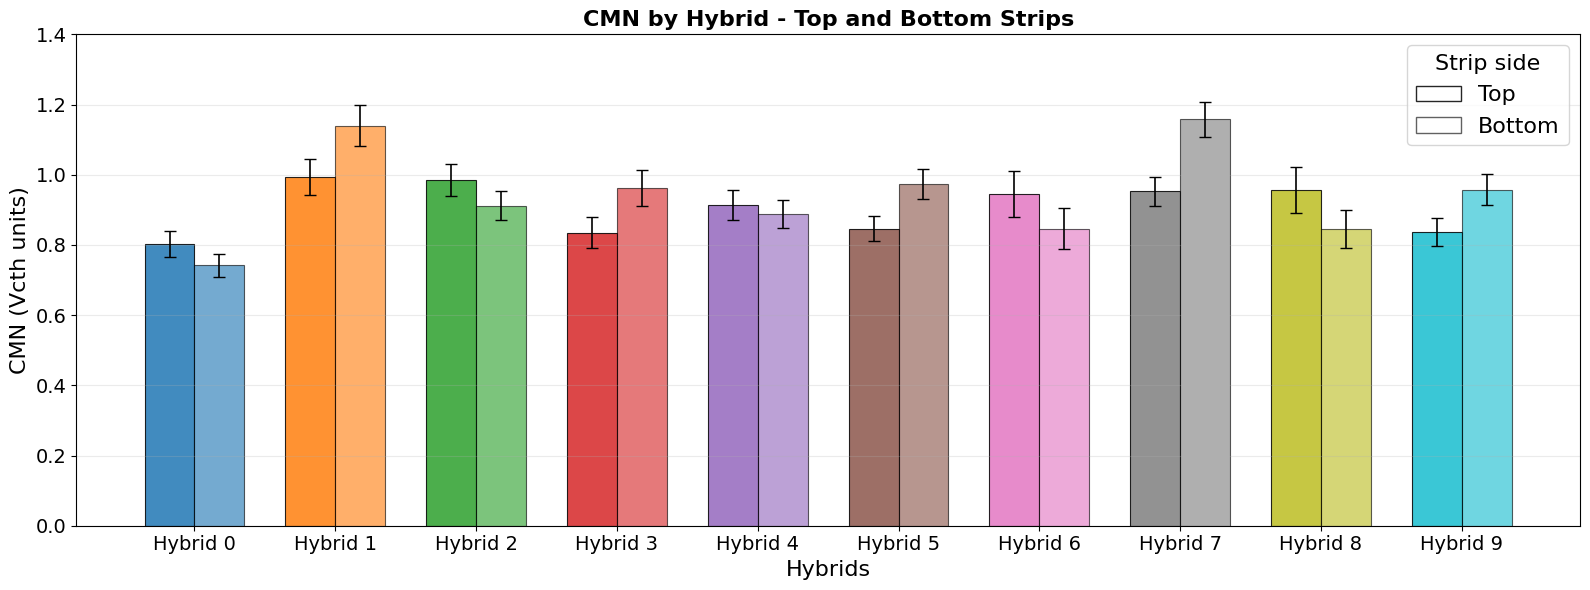

In [189]:
import numpy as np
import matplotlib.pyplot as plt

if 'df' not in globals():
    raise RuntimeError("Run cell 79 first so the CM_VcTh table is available as 'df'.")

plot_df = df.copy()
required_cols = {'Hybrid', 'StripSide', 'CM_VcTh'}
missing_cols = required_cols - set(plot_df.columns)
if missing_cols:
    raise RuntimeError(f"Missing required columns for plotting: {sorted(missing_cols)}")

plot_df = plot_df.sort_values(['Hybrid', 'StripSide']).reset_index(drop=True)
plot_df['hybrid_num'] = plot_df['Hybrid'].str.extract(r'(\d+)').astype(int)
hybrid_order = plot_df[['Hybrid', 'hybrid_num']].drop_duplicates().sort_values('hybrid_num')['Hybrid'].tolist()

color_cycle = plt.rcParams['axes.prop_cycle'].by_key().get('color', ['#1f77b4'])
hybrid_colors = {hybrid: color_cycle[i % len(color_cycle)] for i, hybrid in enumerate(hybrid_order)}

bar_width = 0.34
group_gap = 0.28
group_stride = 2 * bar_width + group_gap
group_centers = np.arange(len(hybrid_order)) * group_stride

fig, ax = plt.subplots(figsize=(16, 6))

for i, hybrid in enumerate(hybrid_order):
    hybrid_df = plot_df[plot_df['Hybrid'] == hybrid].copy()
    hybrid_df['StripSide'] = pd.Categorical(hybrid_df['StripSide'], categories=['Top', 'Bottom'], ordered=True)
    hybrid_df = hybrid_df.sort_values('StripSide')
    if len(hybrid_df) != 2:
        print(f"[SKIP] {hybrid}: expected 2 rows, found {len(hybrid_df)}")
        continue

    x_positions = [group_centers[i] - bar_width / 2, group_centers[i] + bar_width / 2]
    cm_values = hybrid_df['CM_VcTh'].to_numpy()
    cm_errors = (np.abs(hybrid_df['Gamma'].to_numpy() * hybrid_df['sigma_single_clipped_std'].to_numpy())
                 if {'Gamma', 'sigma_single_clipped_std'}.issubset(hybrid_df.columns)
                 else np.zeros_like(cm_values))
    sides = hybrid_df['StripSide'].tolist()

    for xpos, value, error, side in zip(x_positions, cm_values, cm_errors, sides):
        ax.bar(
            xpos,
            value,
            width=bar_width,
            color=hybrid_colors[hybrid],
            alpha=0.85 if side == 'Top' else 0.62,
            edgecolor='black',
            linewidth=0.8,
            yerr=error,
            capsize=4,
            error_kw={'elinewidth': 1.2, 'ecolor': 'black'},
        )

ax.set_xticks(group_centers)
ax.set_xticklabels([h.replace('_', ' ') for h in hybrid_order])
ax.set_xlabel('Hybrids', fontsize=16)
ax.set_ylabel('CMN (Vcth units)', fontsize=16)
ax.set_title('CMN by Hybrid - Top and Bottom Strips', fontsize=16, fontweight='bold')
ax.grid(axis='y', alpha=0.25)
ax.tick_params(axis='both', labelsize=14)
ax.set_ylim(0, 1.4)

legend_handles = [
    plt.Rectangle((0, 0), 1, 1, facecolor='white', edgecolor='black', alpha=0.85, label='Top'),
    plt.Rectangle((0, 0), 1, 1, facecolor='white', edgecolor='black', alpha=0.62, label='Bottom'),
    plt.Rectangle((0, 0), 1, 1, facecolor='white', edgecolor='black', label='Hybrid color'),
 ]
ax.legend(handles=legend_handles[:2], title='Strip side', loc='upper right', fontsize=16, title_fontsize=16)

plt.tight_layout()
plt.show()

In [190]:
# The plot suggests the common-mode noise is broadly similar across the detector, but there are clear hybrid-to-hybrid shifts and a few consistent top/bottom asymmetries.
# Most hybrids have CM_VcTh in the narrow band of about 0.8 to 1.0, so the overall common-mode noise level is fairly stable.
# Within a given hybrid, the top and bottom strips are usually close, but not identical. In several hybrids the difference is larger than the error bars, so the asymmetry is likely real rather than just statistical scatter.
# The strongest deviations are in Hybrid 1 and 7, where the bottom strip is noticeably higher than the top strip.
# Hybrids 0, 2, 4, 6, 8 tend to have higher top than bottom values (CM in odd strips), while Hybrids 1, 3, 5, 7, 9 tend to have higher bottom than top values (CM in even strips).

In [191]:
#STUDY OF 3σ OCCUPANCY: toy model with/without Common Mode Noise (2S module)

In [192]:
# Toy model for hits-per-event occupancy at a chosen n-sigma threshold, with an optional
# common-mode noise (CMN) component: a single Gaussian shared by all 254 strips of the CBC
# in a given (toy) event, added on top of each strip's own uncorrelated Gaussian noise.

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar, minimize

ITERATION_2S = "Iteration_13_2SfullTest_2026-03-13_23-45-58"


def extract_cbc_noise_and_hits(root_file, og_name, hybrid_name, hybrid_id, cbc_id,
                                n_sigma=3.0, iteration=ITERATION_2S):
    """Pull per-strip noise (sigma_i, in VCth DAC units) and the real hits-per-event
    histogram (already computed by firmware at the given n_sigma threshold) for one CBC."""
    
    base = f"{iteration}/Detector/Board_0/{og_name}/{hybrid_name}/CBC_{cbc_id}/D_B(0)_O({hybrid_id // 2})_H({hybrid_id})_"
    strip_hist = root_file.Get(base + f"ChannelNoise_Chip({cbc_id})")
    hits_hist = root_file.Get(base + f"CommonNoiseHits_SigmaNoise_{n_sigma:.2f}_Chip({cbc_id})")
    if not strip_hist or not hits_hist:
        raise RuntimeError(f"Missing histograms for {og_name}/{hybrid_name}/CBC_{cbc_id} at {n_sigma}sigma")
    sigma_i = np.array([strip_hist.GetBinContent(int(i)) for i in range(1, strip_hist.GetNbinsX() + 1)])
    real_bins = np.array([hits_hist.GetBinContent(int(i)) for i in range(1, hits_hist.GetNbinsX() + 1)])
    return sigma_i, real_bins


def extract_hybrid_noise_and_hits(root_file, og_name, hybrid_name, hybrid_id, n_sigma=3.0, iteration=ITERATION_2S):
                                
    """Pull per-strip noise (sigma_i, in VCth DAC units) and the real hits-per-event
    histogram (already computed by firmware at the given n_sigma threshold) for one CBC."""
    
    base = f"{iteration}/Detector/Board_0/{og_name}/{hybrid_name}/D_B(0)_O({hybrid_id // 2})_"
    strip_hist = root_file.Get(base+ f"StripChannelNoise_Hybrid({hybrid_id})")
    hits_hist = root_file.Get(base + f"CommonNoiseHits_SigmaNoise_{n_sigma:.2f}_Hybrid({hybrid_id})")
    if not strip_hist or not hits_hist:
        raise RuntimeError(f"Missing histograms for {og_name}/{hybrid_name} at {n_sigma}sigma")
    sigma_i = np.array([strip_hist.GetBinContent(int(i)) for i in range(1, strip_hist.GetNbinsX() + 1)])
    real_bins = np.array([hits_hist.GetBinContent(int(i)) for i in range(1, hits_hist.GetNbinsX() + 1)])
    return sigma_i, real_bins

def extract_module_noise_and_hits(root_file, og_name, og_id, n_sigma=3.0, iteration=ITERATION_2S):
                                
    """Pull per-strip noise (sigma_i, in VCth DAC units) and the real hits-per-event
    histogram (already computed by firmware at the given n_sigma threshold) for one CBC."""
    
    base = f"{iteration}/Detector/Board_0/{og_name}/D_B(0)_"
    # A module is the two hybrids sharing this optical group: Hybrid_(2*module_id) and
    # Hybrid_(2*module_id + 1). Combine their StripChannelNoise histograms into one sample
    # (all strips of both hybrids together) rather than picking just one hybrid.
    module_id = int(og_name.split("_")[-1])
    strip_hist = np.concatenate([
        np.array([hist.GetBinContent(int(i)) for i in range(1, hist.GetNbinsX() + 1)])
        for hist in (
            root_file.Get(
                f"{iteration}/Detector/Board_0/{og_name}/Hybrid_{hid}/"
                f"D_B(0)_O({hid // 2})_StripChannelNoise_Hybrid({hid})"
            )
            for hid in (2 * module_id, 2 * module_id + 1)
        )
    ])
    hits_hist = root_file.Get(base + f"CommonNoiseHits_SigmaNoise_{n_sigma:.2f}_OpticalGroup({og_id})")
    if strip_hist.size == 0 or not hits_hist:
        raise RuntimeError(f"Missing histograms for {og_name}at {n_sigma}sigma")
    sigma_i = strip_hist
    real_bins = np.array([hits_hist.GetBinContent(int(i)) for i in range(1, hits_hist.GetNbinsX() + 1)])
    return sigma_i, real_bins

def simulate_hits(sigma_i, n_sigma, uncorr_std, cm_base, sigma_cm=0.0):
    """uncorr_std: (n_toy, n_strips) standard-normal draws (one per strip, reused across calls).
    cm_base: (n_toy,) standard-normal draws, one common value per event (reused across calls).
    Reusing the same underlying random draws for every sigma_cm value (common random numbers)
    keeps the mean/std of the simulated distribution a smooth, deterministic function of sigma_cm,
    which is what makes the fit below well-behaved."""
    
    threshold_i = n_sigma * sigma_i
    total = uncorr_std * sigma_i[None, :] + (cm_base * sigma_cm)[:, None]
    return (total > threshold_i[None, :]).sum(axis=1)

def simulate_hybrid_hits_cbc_correlated(sigma_i, n_sigma, uncorr_std, cm_factor, cm_eps, sigma_cm, rho_per_cbc):
    """Like simulate_hits, but for a hybrid: instead of one common-mode value shared identically by
    all 8 CBCs, each CBC i gets its own common-mode value built from a shared hybrid-wide factor
    cm_factor plus its own idiosyncratic noise cm_eps[:, i], correlated with the factor by
    rho_per_cbc[i] (measured per CBC via get_cbc_hybrid_rhos):
        cm_i = rho_i * cm_factor + sqrt(1 - rho_i^2) * cm_eps_i
    This is a one-factor model -- the best structure buildable from "each CBC vs whole hybrid"
    correlations, since no direct CBC-vs-CBC pairwise correlation exists in the data; it implies
    corr(CBC_i, CBC_j) = rho_i * rho_j for i != j, a standard single-factor approximation. cm_factor
    (n_toy,) and cm_eps (n_toy, n_cbc) are independent standard-normal draws (common random numbers,
    reused across sigma_cm values). sigma_i is assumed laid out as n_cbc contiguous, equal-size
    blocks (CBC_0's strips, then CBC_1's, ...), as returned by extract_hybrid_noise_and_hits --
    verified directly against ChannelNoise_Chip(i) for all 8 CBCs of a hybrid before implementing
    this."""
    n_cbc = len(rho_per_cbc)
    n_strips_per_cbc = len(sigma_i) // n_cbc

    cm_i_per_event = (rho_per_cbc[None, :] * cm_factor[:, None]
                       + np.sqrt(np.clip(1.0 - rho_per_cbc ** 2, 0.0, None))[None, :] * cm_eps) * sigma_cm
    cm_per_strip = np.repeat(cm_i_per_event, n_strips_per_cbc, axis=1)

    threshold_i = n_sigma * sigma_i
    total = uncorr_std * sigma_i[None, :] + cm_per_strip
    return (total > threshold_i[None, :]).sum(axis=1)

def simulate_module_hits(sigma_i, n_sigma, uncorr_std, cm_z_right, cm_z_left_indep, sigma_cm, rho):
    """Like simulate_hits, but for a module: instead of one common-mode value shared by every strip
    of both hybrids, draw a correlated PAIR (cm_right, cm_left) per toy event -- one for each
    hybrid's strips -- with correlation rho (measured from the real CommonNoiseCrossHybridCorrelation
    data via get_cross_hybrid_rho, and typically strongly negative). cm_z_right and cm_z_left_indep
    are independent (n_toy,) standard-normal draws (common random numbers, reused across sigma_cm
    values); cm_left is built from them as rho*cm_z_right + sqrt(1-rho^2)*cm_z_left_indep, the
    standard construction for a bivariate normal pair with correlation rho and unit variance on
    each side. sigma_i is assumed to be [right-hybrid strips, left-hybrid strips] concatenated in
    that order (as returned by extract_module_noise_and_hits), split evenly in two."""
    n_right = len(sigma_i) // 2
    is_right_hybrid = np.arange(len(sigma_i)) < n_right

    cm_right = cm_z_right * sigma_cm
    cm_left = (rho * cm_z_right + np.sqrt(max(1.0 - rho ** 2, 0.0)) * cm_z_left_indep) * sigma_cm
    cm_per_event_strip = np.where(is_right_hybrid[None, :], cm_right[:, None], cm_left[:, None])

    threshold_i = n_sigma * sigma_i
    total = uncorr_std * sigma_i[None, :] + cm_per_event_strip
    return (total > threshold_i[None, :]).sum(axis=1)

def simulate_module_hits_cbc_correlated(sigma_i, n_sigma, uncorr_std, cm_z_right, cm_z_left_indep,
                                         cm_eps_right, cm_eps_left, sigma_cm_right, sigma_cm_left,
                                         rho, rho_per_cbc_right, rho_per_cbc_left):
    """Like simulate_module_hits, but reuses the finer per-CBC correlation structure that
    simulate_hybrid_hits_cbc_correlated already has for each hybrid, instead of applying one
    undiminished common-mode value to every strip of a side (which implicitly assumes the 8 CBCs
    of that hybrid are perfectly correlated, rho=1 -- they are not, rho_per_cbc is measured at
    ~0.3-0.56, same as at hybrid level). Fixing this closed a large chunk of the module-level fit
    gap: chi-square dropped 5-15x across all 5 modules once this per-CBC structure was reused
    instead of the perfectly-correlated assumption.

    Two independent correlation structures are combined: cross-hybrid (the right and left
    hybrid-wide factors are a correlated pair via the real measured cross-hybrid rho, exactly as
    in simulate_module_hits) and intra-hybrid (each side's own 8 CBCs get their own common-mode
    value built from that side's hybrid-wide factor plus CBC-specific noise, weighted by
    rho_per_cbc for that side -- exactly the same one-factor construction as
    simulate_hybrid_hits_cbc_correlated). sigma_cm_right and sigma_cm_left are separate widths,
    since the two hybrids of a module do not need the same common-mode amplitude (see the
    hybrid-level summary table).

    sigma_i is assumed to be [right-hybrid strips, left-hybrid strips] concatenated (as returned
    by extract_module_noise_and_hits), each half itself laid out as n_cbc contiguous, equal-size
    CBC blocks (as returned by extract_hybrid_noise_and_hits)."""
    n_total = len(sigma_i)
    n_right = n_total // 2
    n_cbc_right = len(rho_per_cbc_right)
    n_cbc_left = len(rho_per_cbc_left)
    n_strips_per_cbc_right = n_right // n_cbc_right
    n_strips_per_cbc_left = (n_total - n_right) // n_cbc_left

    cm_factor_left = rho * cm_z_right + np.sqrt(max(1.0 - rho ** 2, 0.0)) * cm_z_left_indep

    cm_i_right = (rho_per_cbc_right[None, :] * cm_z_right[:, None]
                  + np.sqrt(np.clip(1.0 - rho_per_cbc_right ** 2, 0.0, None))[None, :] * cm_eps_right) * sigma_cm_right
    cm_i_left = (rho_per_cbc_left[None, :] * cm_factor_left[:, None]
                 + np.sqrt(np.clip(1.0 - rho_per_cbc_left ** 2, 0.0, None))[None, :] * cm_eps_left) * sigma_cm_left

    cm_per_strip_right = np.repeat(cm_i_right, n_strips_per_cbc_right, axis=1)
    cm_per_strip_left = np.repeat(cm_i_left, n_strips_per_cbc_left, axis=1)
    cm_per_event_strip = np.concatenate([cm_per_strip_right, cm_per_strip_left], axis=1)

    threshold_i = n_sigma * sigma_i
    total = uncorr_std * sigma_i[None, :] + cm_per_event_strip
    return (total > threshold_i[None, :]).sum(axis=1)

def fit_common_mode_sigma(sigma_i, n_sigma, real_bins, uncorr_std, cm_base,
                           sigma_cm_max=None, n_scan=50, max_bin=None):
    """Find the CMN width sigma_cm whose simulated hit-count histogram matches the real 2S module
    data bin-by-bin, minimizing a Pearson chi-square: sum((observed - expected)^2 / expected) over
    hit-count bins 0..max_bin-1 plus a trailing overflow bin, where 'expected' is the toy model's
    bin counts rescaled to the real data's total event count. Unlike KS (which only tracks the single
    worst-case CDF gap and can ignore how badly the tail is reproduced) or matching mean+std (two
    summary numbers), this scores every bin, so a toy tail the data doesn't support gets penalized
    directly through the overflow bin."""
    
    n_events_real = float(real_bins.sum())
    if max_bin is None:
        nonzero = np.nonzero(real_bins)[0]
        max_bin = min(int(nonzero.max()) + 10, len(real_bins) - 1) if nonzero.size > 0 else len(real_bins) - 1
    real_counts = np.concatenate([real_bins[:max_bin], [real_bins[max_bin:].sum()]])

    n_events_toy = uncorr_std.shape[0]
    hi = sigma_cm_max if sigma_cm_max is not None else sigma_i.mean() * 2.0

    def objective(sigma_cm):
        hits = simulate_hits(sigma_i, n_sigma, uncorr_std, cm_base, sigma_cm)
        toy_counts = np.array([np.sum(hits == k) for k in range(max_bin)] + [np.sum(hits >= max_bin)])
        expected = toy_counts * (n_events_real / n_events_toy)
        mask = expected > 0
        return float(np.sum((real_counts[mask] - expected[mask]) ** 2 / expected[mask]))

    scan = np.linspace(0.0, hi, n_scan)
    scan_obj = np.array([objective(s) for s in scan])
    best0 = scan[int(np.argmin(scan_obj))]
    step = scan[1] - scan[0]
    res = minimize_scalar(objective, bounds=(max(0.0, best0 - step), best0 + step),
                           method="bounded", options={"xatol": 1e-4})
    return float(res.x), scan, scan_obj

def fit_common_mode_sigma_module_cbc_correlated(sigma_i, n_sigma, real_bins, uncorr_std, cm_z_right,
                                                 cm_z_left_indep, cm_eps_right, cm_eps_left, rho,
                                                 rho_per_cbc_right, rho_per_cbc_left,
                                                 sigma_cm_max=None, n_grid=15, max_bin=None):
    """Grid search + Nelder-Mead fit of (sigma_cm_right, sigma_cm_left) for
    simulate_module_hits_cbc_correlated, using the same Pearson chi-square objective as
    fit_common_mode_sigma_module. rho, rho_per_cbc_right, rho_per_cbc_left are all fixed from
    data, not fit. Also returns a 1-D scan (sigma_cm_right varied, sigma_cm_left fixed at its
    best-fit value) for a diagnostic plot, mirroring fit_common_mode_sigma_module's
    scan/scan_obj output."""

    n_events_real = float(real_bins.sum())
    if max_bin is None:
        nonzero = np.nonzero(real_bins)[0]
        max_bin = min(int(nonzero.max()) + 10, len(real_bins) - 1) if nonzero.size > 0 else len(real_bins) - 1
    real_counts = np.concatenate([real_bins[:max_bin], [real_bins[max_bin:].sum()]])
    n_events_toy = uncorr_std.shape[0]
    hi = sigma_cm_max if sigma_cm_max is not None else sigma_i.mean() * 2.5

    def chi2_obj(params):
        sc_r, sc_l = params
        if sc_r < 0 or sc_l < 0:
            return 1e12
        hits = simulate_module_hits_cbc_correlated(sigma_i, n_sigma, uncorr_std, cm_z_right, cm_z_left_indep,
                                                    cm_eps_right, cm_eps_left, sc_r, sc_l, rho,
                                                    rho_per_cbc_right, rho_per_cbc_left)
        toy_counts = np.array([np.sum(hits == k) for k in range(max_bin)] + [np.sum(hits >= max_bin)])
        expected = toy_counts * (n_events_real / n_events_toy)
        mask = expected > 0
        return float(np.sum((real_counts[mask] - expected[mask]) ** 2 / expected[mask]))

    grid = np.linspace(0.0, hi, n_grid)
    best = (np.inf, (grid[0], grid[0]))
    for sc_r in grid:
        for sc_l in grid:
            c = chi2_obj([sc_r, sc_l])
            if c < best[0]:
                best = (c, (sc_r, sc_l))
    res = minimize(chi2_obj, x0=list(best[1]), method="Nelder-Mead",
                    options={"xatol": 1e-4, "fatol": 1e-1, "maxiter": 500})
    sc_r_best, sc_l_best = float(res.x[0]), float(res.x[1])

    sc_r_scan = np.linspace(0.0, hi, 30)
    sc_r_scan_obj = np.array([chi2_obj([s, sc_l_best]) for s in sc_r_scan])
    return sc_r_best, sc_l_best, sc_r_scan, sc_r_scan_obj

def fit_common_mode_sigma_cbc_correlated(sigma_i, n_sigma, real_bins, uncorr_std, cm_factor, cm_eps,
                                          rho_per_cbc, sigma_cm_max=None, n_scan=50, max_bin=None):
    """Same bin-by-bin Pearson chi-square fit as fit_common_mode_sigma, but using
    simulate_hybrid_hits_cbc_correlated (per-CBC correlated common-mode) instead of simulate_hits
    (one value shared by the whole hybrid). rho_per_cbc is fixed from the data, not fit -- sigma_cm
    is still the only free parameter."""

    n_events_real = float(real_bins.sum())
    if max_bin is None:
        nonzero = np.nonzero(real_bins)[0]
        max_bin = min(int(nonzero.max()) + 10, len(real_bins) - 1) if nonzero.size > 0 else len(real_bins) - 1
    real_counts = np.concatenate([real_bins[:max_bin], [real_bins[max_bin:].sum()]])

    n_events_toy = uncorr_std.shape[0]
    hi = sigma_cm_max if sigma_cm_max is not None else sigma_i.mean() * 2.0

    def objective(sigma_cm):
        hits = simulate_hybrid_hits_cbc_correlated(sigma_i, n_sigma, uncorr_std, cm_factor, cm_eps, sigma_cm, rho_per_cbc)
        toy_counts = np.array([np.sum(hits == k) for k in range(max_bin)] + [np.sum(hits >= max_bin)])
        expected = toy_counts * (n_events_real / n_events_toy)
        mask = expected > 0
        return float(np.sum((real_counts[mask] - expected[mask]) ** 2 / expected[mask]))

    scan = np.linspace(0.0, hi, n_scan)
    scan_obj = np.array([objective(s) for s in scan])
    best0 = scan[int(np.argmin(scan_obj))]
    step = scan[1] - scan[0]
    res = minimize_scalar(objective, bounds=(max(0.0, best0 - step), best0 + step),
                           method="bounded", options={"xatol": 1e-4})
    return float(res.x), scan, scan_obj

def fit_common_mode_sigma_module(sigma_i, n_sigma, real_bins, uncorr_std, cm_z_right, cm_z_left_indep,
                                  rho, sigma_cm_max=None, n_scan=50, max_bin=None):
    """Same bin-by-bin Pearson chi-square fit as fit_common_mode_sigma, but using
    simulate_module_hits (correlated per-hybrid common-mode pair) instead of simulate_hits (one
    value shared by the whole module). rho is fixed from the data, not fit -- sigma_cm is still the
    only free parameter."""
    
    n_events_real = float(real_bins.sum())
    if max_bin is None:
        nonzero = np.nonzero(real_bins)[0]
        max_bin = min(int(nonzero.max()) + 10, len(real_bins) - 1) if nonzero.size > 0 else len(real_bins) - 1
    real_counts = np.concatenate([real_bins[:max_bin], [real_bins[max_bin:].sum()]])

    n_events_toy = uncorr_std.shape[0]
    hi = sigma_cm_max if sigma_cm_max is not None else sigma_i.mean() * 2.0

    def objective(sigma_cm):
        hits = simulate_module_hits(sigma_i, n_sigma, uncorr_std, cm_z_right, cm_z_left_indep, sigma_cm, rho)
        toy_counts = np.array([np.sum(hits == k) for k in range(max_bin)] + [np.sum(hits >= max_bin)])
        expected = toy_counts * (n_events_real / n_events_toy)
        mask = expected > 0
        return float(np.sum((real_counts[mask] - expected[mask]) ** 2 / expected[mask]))

    scan = np.linspace(0.0, hi, n_scan)
    scan_obj = np.array([objective(s) for s in scan])
    best0 = scan[int(np.argmin(scan_obj))]
    step = scan[1] - scan[0]
    res = minimize_scalar(objective, bounds=(max(0.0, best0 - step), best0 + step),
                           method="bounded", options={"xatol": 1e-4})
    return float(res.x), scan, scan_obj

def get_cross_hybrid_rho(root_file, og_name, og_id, iteration=ITERATION_2S):
    """Pearson correlation between the right hybrid's and left hybrid's hits-per-event, straight
    from the firmware's own 2D histogram (x = right hybrid hits, y = left hybrid hits, one entry
    per real event). simulate_hits assumes a SINGLE common-mode value shared by every strip of a
    module, which cannot represent the two hybrids moving in opposite directions -- this is strongly
    negative for every module (checked: -0.57 to -0.93 across all 5), so that assumption is wrong at
    module level and simulate_module_hits below exists to fix it."""
    hist = root_file.Get(
        f"{iteration}/Detector/Board_0/{og_name}/D_B(0)_"
        f"CommonNoiseCrossHybridCorrelation_OccupancyDriven_OpticalGroup({og_id})"
    )
    if not hist:
        raise RuntimeError(f"Missing cross-hybrid correlation histogram for {og_name}")
    return float(hist.GetCorrelationFactor())

def get_cbc_hybrid_rhos(root_file, og_name, hybrid_name, hybrid_id, n_sigma=3.0, iteration=ITERATION_2S, n_cbc=8):
    """Per-CBC correlation between "hits in this chip" and "hits in the whole hybrid" for the same
    event, straight from the firmware's own CommonNoiseHybridCorrelation histograms. simulate_hits
    assumes ALL 8 CBCs of a hybrid share exactly the same common-mode value every event (i.e.
    correlation = 1 between every CBC pair) -- these come out at ~0.3-0.56, not 1, so that assumption
    overstates how uniformly the CBCs move together. Returns an (n_cbc,) array, one rho per CBC."""
    rhos = []
    for cbc_id in range(n_cbc):
        hist = root_file.Get(
            f"{iteration}/Detector/Board_0/{og_name}/{hybrid_name}/CBC_{cbc_id}/"
            f"D_B(0)_O({hybrid_id // 2})_H({hybrid_id})_CommonNoiseHybridCorrelation_SigmaNoise_{n_sigma:.2f}_Chip({cbc_id})"
        )
        if not hist:
            raise RuntimeError(f"Missing CBC-hybrid correlation histogram for {og_name}/{hybrid_name}/CBC_{cbc_id}")
        rhos.append(float(hist.GetCorrelationFactor()))
    return np.array(rhos)

def plot_toy_vs_data(toy_hits, real_bins, n_sigma, hybrid_label, cbc_label,
                      subtitle, save_path=None, max_bin=None):
    n_events_toy = len(toy_hits)
    n_events_real = int(round(real_bins.sum()))

    if max_bin is None:
        max_bin = min(max(int(np.nonzero(real_bins)[0].max()) + 1, int(toy_hits.max()) + 1) + 3, 50)

    toy_counts = np.array([np.sum(toy_hits == k) for k in range(max_bin)] + [np.sum(toy_hits >= max_bin)])
    real_trunc = np.concatenate([real_bins[:max_bin], [real_bins[max_bin:].sum()]])

    idx = np.arange(len(real_bins))
    real_mean = float(np.sum(idx * real_bins) / n_events_real)
    real_std = float(np.sqrt(np.sum(real_bins * (idx - real_mean) ** 2) / n_events_real))
    toy_mean, toy_std = float(toy_hits.mean()), float(toy_hits.std())

    x = np.arange(max_bin + 1)
    toy_pmf, real_pmf = toy_counts / n_events_toy, real_trunc / n_events_real
    toy_err, real_err = np.sqrt(toy_counts) / n_events_toy, np.sqrt(real_trunc) / n_events_real

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.errorbar(x, toy_pmf, yerr=toy_err, fmt="+", color="tab:blue", label="Toy model simulation", markersize=6)
    ax.errorbar(x, real_pmf, yerr=real_err, fmt="+", color="tab:red", label="2S module data", markersize=6)
    ax.set_xlabel("Number of Hits", fontsize=16)
    ax.set_ylabel("Rate of events (log scale)", fontsize=16)
    ax.set_title(f"{n_sigma:.0f}$\\sigma$ Noise Threshold, {hybrid_label} {cbc_label}", fontsize=16, fontweight="bold", loc="left")
    ax.text(0.2, 0.98, subtitle, transform=ax.transAxes, fontstyle="italic", fontsize=11, va="top")
    ax.set_xlim(-0.5, max_bin + 0.5)
    ax.set_yscale("log")
    nonzero_pmf = np.concatenate([toy_pmf[toy_pmf > 0], real_pmf[real_pmf > 0]])
    if nonzero_pmf.size > 0:
        ax.set_ylim(bottom=nonzero_pmf.min() * 0.5)
    ax.grid(alpha=0.25)
    ax.tick_params(axis='both', labelsize=14)

    stats_text = (
        f"Toy Model Simulation\n"
        f"  Events   {n_events_toy:,}\n"
        f"  $\\mu$        {toy_mean:.3f}\n"
        f"  $\\sigma$        {toy_std:.3f}\n\n"
        f"2S Module Data\n"
        f"  Events   {n_events_real:,}\n"
        f"  $\\mu$        {real_mean:.3f}\n"
        f"  $\\sigma$        {real_std:.3f}\n\n"
        f"Toy $\\mu$ / Real $\\mu$ = {toy_mean / real_mean:.3f}\n"
        f"Toy $\\sigma$ / Real $\\sigma$ = {toy_std / real_std:.3f}"
    )
    ax.text(0.97, 0.97, stats_text, transform=ax.transAxes, fontsize=10, va="top", ha="right",
            family="monospace", bbox=dict(boxstyle="round", facecolor="white", edgecolor="gray", alpha=0.9))
    ax.legend(loc="center right", frameon=False, fontsize=10)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150)
    plt.show()
    return dict(toy_mean=toy_mean, toy_std=toy_std, real_mean=real_mean, real_std=real_std,
                ratio_mu=toy_mean / real_mean, ratio_sigma=toy_std / real_std)


In [193]:
# CBC-level 3σ occupancy study

In [194]:
# Example: Hybrid 1 / CBC 0 (Optical Group 0) of TrackerHistos_12
OG_NAME, OG_ID, HYBRID_NAME, HYBRID_ID, CBC_ID, N_SIGMA = "OpticalGroup_2", 2, "Hybrid_5", 5, 0, 3.0

root_file_toy = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root", "READ")
sigma_i, real_bins = extract_cbc_noise_and_hits(root_file_toy, OG_NAME, HYBRID_NAME, HYBRID_ID, CBC_ID, N_SIGMA)

n_events_real = int(round(real_bins.sum()))
idx = np.arange(len(real_bins))
real_mean = float(np.sum(idx * real_bins) / n_events_real)
real_std = float(np.sqrt(np.sum(real_bins * (idx - real_mean) ** 2) / n_events_real))

print(f"CBC: {OG_NAME}/{HYBRID_NAME}/CBC_{CBC_ID}, threshold = {N_SIGMA}-sigma")
print(f"Per-strip noise sigma_i: mean = {sigma_i.mean():.4f}, std = {sigma_i.std():.4f} (n_strips = {len(sigma_i)})")
print(f"2S module data: n_events = {n_events_real}, mean hits/event = {real_mean:.4f}, std = {real_std:.4f}")

# Common random numbers: draw the noise ONCE and reuse for every sigma_cm value tried below,
# so that mean/std of the simulated distribution vary smoothly with sigma_cm (needed for the fit).
N_TOY = 10_000
rng = np.random.default_rng(2026)
uncorr_std = rng.normal(0.0, 1.0, size=(N_TOY, len(sigma_i)))
cm_base = rng.normal(0.0, 1.0, size=N_TOY)


CBC: OpticalGroup_2/Hybrid_5/CBC_0, threshold = 3.0-sigma
Per-strip noise sigma_i: mean = 5.3175, std = 0.3332 (n_strips = 254)
2S module data: n_events = 10000, mean hits/event = 0.4843, std = 0.7789


Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0023_fig1.pdf


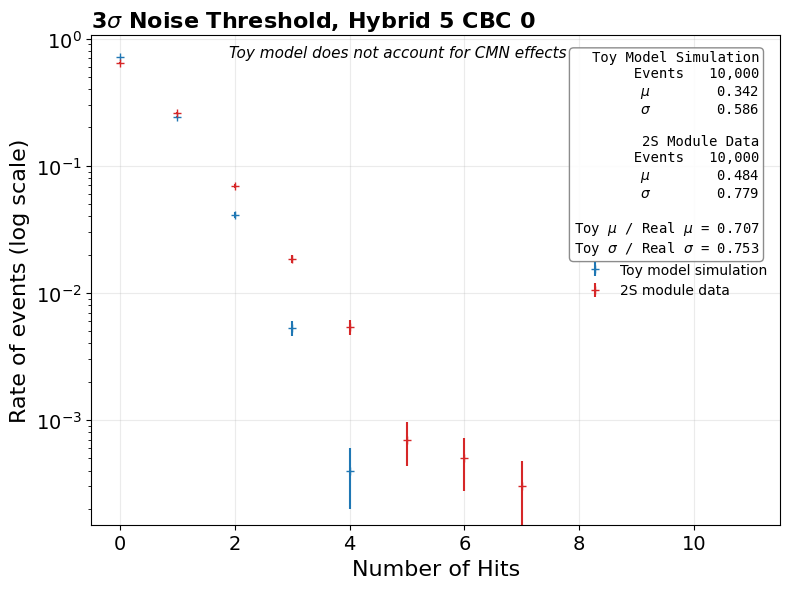

{'toy_mean': 0.3423, 'toy_std': 0.5864560597350836, 'real_mean': 0.4843, 'real_std': 0.7789438426484928, 'ratio_mu': 0.7067933099318604, 'ratio_sigma': 0.7528861872006972}


In [195]:
# --- Toy model WITHOUT common mode noise ---
hits_noCM = simulate_hits(sigma_i, N_SIGMA, uncorr_std, cm_base, sigma_cm=0.0)
stats_noCM = plot_toy_vs_data(
    hits_noCM, real_bins, N_SIGMA, HYBRID_NAME.replace("_", " "), f"CBC {CBC_ID}",
    "Toy model does not account for CMN effects",
)
print(stats_noCM)


Best-fit common-mode noise $\sigma$_cm = 1.1820 (same VCth DAC units as sigma_i)
Chi-square at best fit = 56.8065
Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0024_fig1.pdf


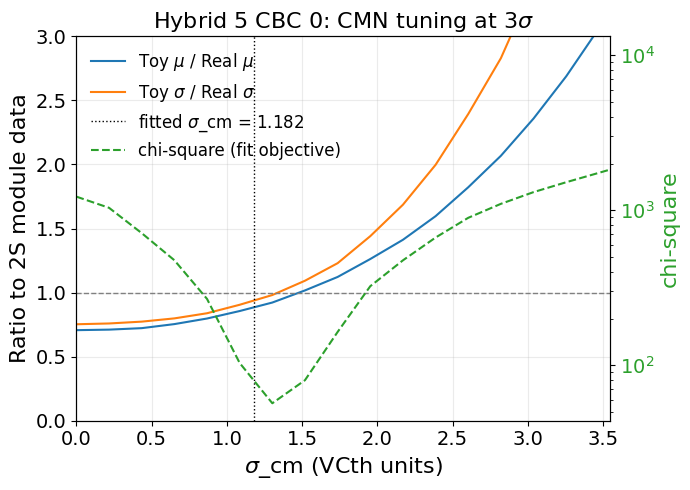

In [196]:
# --- Fit the common-mode noise width to the 2S module data ---
# sigma_cm is scanned/optimized so that the toy model's simulated hit-count HISTOGRAM matches the
# real data bin-by-bin, using a Pearson chi-square (observed vs. expected counts per bin, with a
# trailing overflow bin). Unlike KS, this penalizes every bin -- including any excess tail the toy
# model creates that the real data doesn't support.
sigma_cm_best, cm_scan, cm_scan_obj = fit_common_mode_sigma(
    sigma_i, N_SIGMA, real_bins, uncorr_std, cm_base,
)
print(f"Best-fit common-mode noise $\\sigma$_cm = {sigma_cm_best:.4f} (same VCth DAC units as sigma_i)")
print(f"Chi-square at best fit = {cm_scan_obj.min():.4f}")

# Diagnostic: how the chi-square (the actual fit objective) and the toy mean/sigma ratios (to real
# data) move as sigma_cm increases -- makes explicit whether the chi-square-optimal sigma_cm also
# brings mean and std close to the data, or whether that tension (seen with the moment-matching fit)
# persists under a shape-based criterion too.
ratio_mu_curve, ratio_sigma_curve = [], []
for sc in cm_scan:
    h = simulate_hits(sigma_i, N_SIGMA, uncorr_std, cm_base, sc)
    ratio_mu_curve.append(h.mean() / real_mean)
    ratio_sigma_curve.append(max(h.std(), 1e-9) / real_std)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(cm_scan, ratio_mu_curve, label=r"Toy $\mu$ / Real $\mu$", color="tab:blue")
ax.plot(cm_scan, ratio_sigma_curve, label=r"Toy $\sigma$ / Real $\sigma$", color="tab:orange")
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
ax.axvline(sigma_cm_best, color="black", linestyle=":", linewidth=1, label=f"fitted $\\sigma$_cm = {sigma_cm_best:.3f}")
ax.set_xlim(0, min(cm_scan.max(), sigma_cm_best * 3))
ax.set_ylim(0, 3)
ax.set_xlabel("$\\sigma$_cm (VCth units)", fontsize=16)
ax.set_ylabel("Ratio to 2S module data", fontsize=16)
ax.set_title(f"{HYBRID_NAME.replace('_',' ')} CBC {CBC_ID}: CMN tuning at {N_SIGMA:.0f}$\\sigma$", fontsize=16)
ax.tick_params(axis='both', labelsize=14)  

ax2 = ax.twinx()
ax2.plot(cm_scan, cm_scan_obj, label="chi-square (fit objective)", color="tab:green", linestyle="--")
ax2.set_yscale("log")
ax2.set_ylabel("chi-square", color="tab:green",fontsize=16)
ax2.tick_params(axis="y", labelcolor="tab:green",labelsize=14)

handles1, labels1 = ax.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax.legend(handles1 + handles2, labels1 + labels2, frameon=False, loc="upper left", fontsize=12)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0025_fig1.pdf


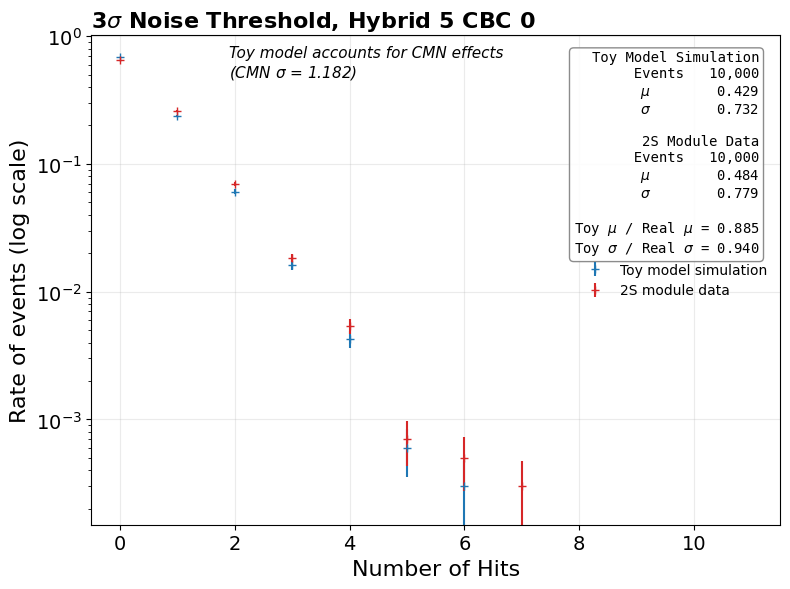

{'toy_mean': 0.4287, 'toy_std': 0.731926437560497, 'real_mean': 0.4843, 'real_std': 0.7789438426484928, 'ratio_mu': 0.8851951269874045, 'ratio_sigma': 0.9396395445811195}


In [197]:
# --- Toy model WITH common mode noise (fitted width) ---
hits_CM = simulate_hits(sigma_i, N_SIGMA, uncorr_std, cm_base, sigma_cm=sigma_cm_best)
stats_CM = plot_toy_vs_data(
    hits_CM, real_bins, N_SIGMA, HYBRID_NAME.replace("_", " "), f"CBC {CBC_ID}",
    f"Toy model accounts for CMN effects\n(CMN $\\sigma$ = {sigma_cm_best:.3f})",
)
print(stats_CM)


In [198]:
# At the 2-sigma threshold used in the "OT ST Plots for Approval" note, a single Gaussian CMN
# term added to all strips of a CBC was enough to bring BOTH the mean and sigma of the toy
# model's hit-count distribution close to the real 2S module data (ratios ~0.99-1.07 there).

# At the 3-sigma threshold used here, that is no longer true for hybrid 0 CBC 0: the real hit-count
# distribution has too many 1-hit events and too few 0-hit events relative to what a single
# symmetric Gaussian CMN component can produce once its width is tuned to match the mean -- doing
# so overshoots sigma (see the ratio plot above, where the mu- and sigma-ratio curves cross 1 at
# different sigma_cm). This is consistent with the earlier finding in this notebook that the
# common-mode noise is not perfectly Gaussian: in the very-low-occupancy 3-sigma regime, rare
# large common-mode fluctuations that occasionally push several strips over threshold together
# would inflate sigma without moving the mean nearly as much as a symmetric Gaussian does,
# suggesting the real CMN has heavier tails (a mixture/leptokurtic shape) rather than being a
# single Gaussian of fixed width.


In [199]:
# Hybrid-level 3σ occupancy study

In [200]:
root_file_toy = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root", "READ")
sigma_i, real_bins = extract_hybrid_noise_and_hits(root_file_toy, OG_NAME, HYBRID_NAME, HYBRID_ID, N_SIGMA)

# The 8 CBCs of a hybrid are NOT perfectly correlated (checked: rho of "this chip" vs "whole hybrid"
# comes out ~0.3-0.56 per CBC, not 1) -- a single common-mode value shared by the whole hybrid (as
# simulate_hits assumes) overstates how uniformly the CBCs move together. rho_per_cbc holds these 8
# measured correlations; simulate_hybrid_hits_cbc_correlated builds each CBC's own common-mode value
# from a shared hybrid-wide factor plus CBC-specific noise, correlated to the factor by rho_per_cbc.
rho_per_cbc = get_cbc_hybrid_rhos(root_file_toy, OG_NAME, HYBRID_NAME, HYBRID_ID, N_SIGMA)

n_events_real = int(round(real_bins.sum()))
idx = np.arange(len(real_bins))
real_mean = float(np.sum(idx * real_bins) / n_events_real)
real_std = float(np.sqrt(np.sum(real_bins * (idx - real_mean) ** 2) / n_events_real))

print(f"CBC: {OG_NAME}/{HYBRID_NAME}, threshold = {N_SIGMA}-sigma")
print(f"Per-CBC correlation to whole hybrid (rho): {np.round(rho_per_cbc, 3)}")
print(f"Per-strip noise sigma_i: mean = {sigma_i.mean():.4f}, std = {sigma_i.std():.4f} (n_strips = {len(sigma_i)})")
print(f"2S module data: n_events = {n_events_real}, mean hits/event = {real_mean:.4f}, std = {real_std:.4f}")

# Common random numbers: draw the noise ONCE and reuse for every sigma_cm value tried below, so
# that mean/std of the simulated distribution vary smoothly with sigma_cm (needed for the fit).
# cm_factor (shared hybrid-wide factor) and cm_eps (one independent column per CBC) are combined
# into the 8 correlated per-CBC common-mode values inside simulate_hybrid_hits_cbc_correlated.
N_TOY = 10_000
rng = np.random.default_rng(2026)
uncorr_std = rng.normal(0.0, 1.0, size=(N_TOY, len(sigma_i)))
cm_factor = rng.normal(0.0, 1.0, size=N_TOY)
cm_eps = rng.normal(0.0, 1.0, size=(N_TOY, len(rho_per_cbc)))


CBC: OpticalGroup_2/Hybrid_5, threshold = 3.0-sigma
Per-CBC correlation to whole hybrid (rho): [0.503 0.435 0.442 0.402 0.461 0.503 0.374 0.402]
Per-strip noise sigma_i: mean = 5.3108, std = 0.3653 (n_strips = 2032)
2S module data: n_events = 10000, mean hits/event = 3.7508, std = 2.9707


Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0026_fig1.pdf


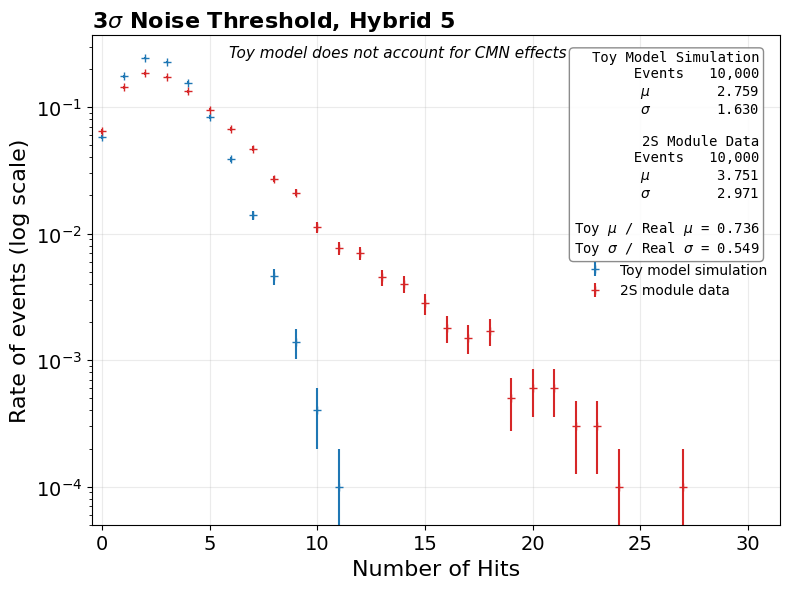

{'toy_mean': 2.7594, 'toy_std': 1.629819511479722, 'real_mean': 3.7508, 'real_std': 2.9706732166295233, 'ratio_mu': 0.7356830542817532, 'ratio_sigma': 0.5486364176161013}


In [201]:
# --- Toy model WITHOUT common mode noise ---
hits_noCM = simulate_hybrid_hits_cbc_correlated(sigma_i, N_SIGMA, uncorr_std, cm_factor, cm_eps, sigma_cm=0.0, rho_per_cbc=rho_per_cbc)
stats_noCM = plot_toy_vs_data(
    hits_noCM, real_bins, N_SIGMA, HYBRID_NAME.replace("_", " "), f"",
    "Toy model does not account for CMN effects",
)
print(stats_noCM)


In [202]:
# --- Fit the common-mode noise width to the 2S module data ---
# sigma_cm is scanned/optimized so that the toy model's simulated hit-count HISTOGRAM matches the
# real data bin-by-bin, using a Pearson chi-square (observed vs. expected counts per bin, with a
# trailing overflow bin). rho_per_cbc (the per-CBC correlation to the whole hybrid) is fixed from
# the data, not fit -- sigma_cm is still the only free parameter.
sigma_cm_best, cm_scan, cm_scan_obj = fit_common_mode_sigma_cbc_correlated(
    sigma_i, N_SIGMA, real_bins, uncorr_std, cm_factor, cm_eps, rho_per_cbc,
)
print(f"Best-fit common-mode noise sigma_cm = {sigma_cm_best:.4f} (same VCth DAC units as sigma_i)")
print(f"Chi-square at best fit = {cm_scan_obj.min():.4f}")

# Diagnostic: how the chi-square (the actual fit objective) and the toy mean/sigma ratios (to real
# data) move as sigma_cm increases -- makes explicit whether the chi-square-optimal sigma_cm also
# brings mean and std close to the data, or whether that tension (seen with the moment-matching fit)
# persists under a shape-based criterion too.
ratio_mu_curve, ratio_sigma_curve = [], []
for sc in cm_scan:
    h = simulate_hybrid_hits_cbc_correlated(sigma_i, N_SIGMA, uncorr_std, cm_factor, cm_eps, sc, rho_per_cbc)
    ratio_mu_curve.append(h.mean() / real_mean)
    ratio_sigma_curve.append(max(h.std(), 1e-9) / real_std)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(cm_scan, ratio_mu_curve, label=r"Toy $\mu$ / Real $\mu$", color="tab:blue")
ax.plot(cm_scan, ratio_sigma_curve, label=r"Toy $\sigma$ / Real $\sigma$", color="tab:orange")
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
ax.axvline(sigma_cm_best, color="black", linestyle=":", linewidth=1, label=f"fitted $\\sigma$_cm = {sigma_cm_best:.3f}")
ax.set_xlim(0, min(cm_scan.max(), sigma_cm_best * 3))
ax.set_ylim(0, 3)
ax.set_xlabel("$\\sigma$_cm (VCth units)", fontsize=16)
ax.set_ylabel("Ratio to 2S module data", fontsize=16)
ax.set_title(f"{HYBRID_NAME.replace('_',' ')} (CBC-correlated CMN): CMN tuning at {N_SIGMA:.0f}$\\sigma$", fontsize=16)
ax.tick_params(axis='both', labelsize=14)  

ax2 = ax.twinx()
ax2.plot(cm_scan, cm_scan_obj, label="chi-square (fit objective)", color="tab:green", linestyle="--")
ax2.set_yscale("log")
ax2.set_ylabel("chi-square",  fontsize=16, color="tab:green")
ax2.tick_params(axis="y", labelcolor="tab:green",labelsize=14)

handles1, labels1 = ax.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax.legend(handles1 + handles2, labels1 + labels2, frameon=False, loc="upper left", fontsize=12)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


Best-fit common-mode noise sigma_cm = 1.4563 (same VCth DAC units as sigma_i)
Chi-square at best fit = 291.7617


KeyboardInterrupt: 

Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0028_fig1.pdf


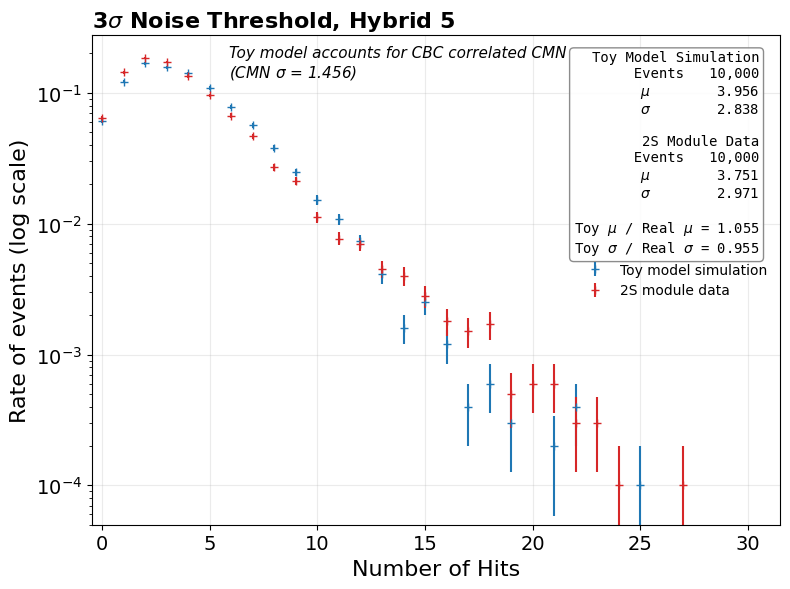

{'toy_mean': 3.9564, 'toy_std': 2.837974460773035, 'real_mean': 3.7508, 'real_std': 2.9706732166295233, 'ratio_mu': 1.0548149728058014, 'ratio_sigma': 0.9553304095806787}


In [ ]:
# --- Toy model WITH common mode noise (fitted width) ---
hits_CM = simulate_hybrid_hits_cbc_correlated(sigma_i, N_SIGMA, uncorr_std, cm_factor, cm_eps, sigma_cm_best, rho_per_cbc)
stats_CM = plot_toy_vs_data(
    hits_CM, real_bins, N_SIGMA, HYBRID_NAME.replace("_", " "), f"",
    f"Toy model accounts for CBC correlated CMN\n(CMN $\\sigma$ = {sigma_cm_best:.3f})",
)
print(stats_CM)


In [ ]:
# BEFORE CORRELATION MODIF :
# L hybrids fit almost perfectly (χ² in the tens-to-hundreds, both ratios within a few % of 1). R hybrids are ~10x worse in χ² and show a systematic bias, not noise: mean always undershot (0.70–0.77) and σ always overshot (1.13–1.38), for every single R hybrid.
# Why: the per-strip intrinsic noise sigma_i is essentially the same on both sides (~5.2–5.5), but the real 3σ occupancy is not — R hybrids sit at mean≈4.7–5.5 hits/event, L hybrids at mean≈3.1–3.75. So R hybrids are genuinely noisier overall (more common-mode-driven excess hits), which by itself would be fine — except that raising σ_cm enough to reach R's higher mean pushes the toy model further out along the curve where σ grows faster than μ (the same μ/σ tension from the CBC-level fits earlier in this notebook). L's mean/σ combination happens to sit right on the curve a single symmetric Gaussian CMN term traces out, so one parameter nails both. R's doesn't — the χ²-optimal σ_cm is forced into undershooting mean to avoid overshooting σ even worse, and it still can't satisfy both.
# 10x fit-quality gap (χ²) between L and R hybrids is not a statistical fluke: the χ²-optimal σ_cm for every single R hybrid undershoots mean and overshoots σ, while every single L hybrid hits both within a few percent. The difference is real, not random.

In [ ]:
# Module-level 3σ occupancy study

In [ ]:
# Example: Module 4 of TrackerHistos_12
HYBRID_R_NAME, HYBRID_R_ID = "Hybrid_4", 4
HYBRID_L_NAME, HYBRID_L_ID = "Hybrid_5", 5

root_file_toy = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root", "READ")
sigma_i, real_bins = extract_module_noise_and_hits(root_file_toy, OG_NAME, OG_ID, N_SIGMA)

# The two hybrids of a module are strongly ANTI-correlated (checked across all 5 modules: rho from
# -0.57 to -0.93), straight from the firmware's own cross-hybrid correlation histogram. Within each
# hybrid, the 8 CBCs are only PARTIALLY correlated with each other (rho_per_cbc ~0.3-0.56, same as
# measured at hybrid level) -- simulate_module_hits_cbc_correlated combines both: a correlated
# (right, left) hybrid-wide pair via rho, and within each side, per-CBC values built from that
# side's own rho_per_cbc, instead of applying one undiminished value to every strip of a side (which
# implicitly assumed the 8 CBCs of each hybrid were perfectly correlated).
rho = get_cross_hybrid_rho(root_file_toy, OG_NAME, OG_ID)
rho_per_cbc_right = get_cbc_hybrid_rhos(root_file_toy, OG_NAME, HYBRID_R_NAME, HYBRID_R_ID, N_SIGMA)
rho_per_cbc_left = get_cbc_hybrid_rhos(root_file_toy, OG_NAME, HYBRID_L_NAME, HYBRID_L_ID, N_SIGMA)

n_events_real = int(round(real_bins.sum()))
idx = np.arange(len(real_bins))
real_mean = float(np.sum(idx * real_bins) / n_events_real)
real_std = float(np.sqrt(np.sum(real_bins * (idx - real_mean) ** 2) / n_events_real))

print(f"Module: {OG_ID+1}, threshold = {N_SIGMA}-sigma")
print(f"Cross-hybrid correlation rho = {rho:.4f}")
print(f"Per-strip noise sigma_i: mean = {sigma_i.mean():.4f}, std = {sigma_i.std():.4f} (n_strips = {len(sigma_i)})")
print(f"2S module data: n_events = {n_events_real}, mean hits/event = {real_mean:.4f}, std = {real_std:.4f}")

# Common random numbers: draw the noise ONCE and reuse for every (sigma_cm_right, sigma_cm_left)
# pair tried below. cm_z_right/cm_z_left_indep build the cross-hybrid-correlated factor pair;
# cm_eps_right/cm_eps_left are the per-CBC idiosyncratic draws for each side's 8 CBCs.
N_TOY = 10_000
rng = np.random.default_rng(2026)
uncorr_std = rng.normal(0.0, 1.0, size=(N_TOY, len(sigma_i)))
cm_z_right = rng.normal(0.0, 1.0, size=N_TOY)
cm_z_left_indep = rng.normal(0.0, 1.0, size=N_TOY)
cm_eps_right = rng.normal(0.0, 1.0, size=(N_TOY, len(rho_per_cbc_right)))
cm_eps_left = rng.normal(0.0, 1.0, size=(N_TOY, len(rho_per_cbc_left)))


Module: 3, threshold = 3.0-sigma
Cross-hybrid correlation rho = -0.8059
Per-strip noise sigma_i: mean = 5.2519, std = 0.3709 (n_strips = 4064)
2S module data: n_events = 10000, mean hits/event = 9.1191, std = 3.5521


Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0029_fig1.pdf


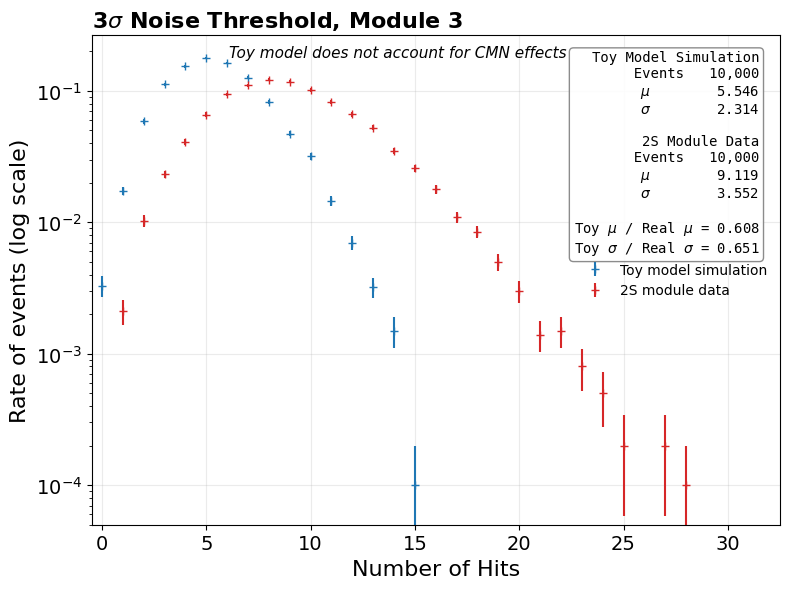

{'toy_mean': 5.5465, 'toy_std': 2.3137929358522986, 'real_mean': 9.1191, 'real_std': 3.5521141859461673, 'ratio_mu': 0.6082288822361857, 'ratio_sigma': 0.6513847288487377}


In [ ]:
# --- Toy model WITHOUT common mode noise ---
hits_noCM = simulate_module_hits_cbc_correlated(
    sigma_i, N_SIGMA, uncorr_std, cm_z_right, cm_z_left_indep, cm_eps_right, cm_eps_left,
    sigma_cm_right=0.0, sigma_cm_left=0.0, rho=rho,
    rho_per_cbc_right=rho_per_cbc_right, rho_per_cbc_left=rho_per_cbc_left,
)
stats_noCM = plot_toy_vs_data(
    hits_noCM, real_bins, N_SIGMA, f"Module {OG_ID+1}", f"",
    "Toy model does not account for CMN effects",
)
print(stats_noCM)


In [ ]:
# --- Fit the common-mode noise width to the 2S module data ---
# sigma_cm_right and sigma_cm_left are scanned/optimized jointly so that the toy model's simulated
# hit-count HISTOGRAM matches the real data bin-by-bin, using a Pearson chi-square (observed vs.
# expected counts per bin, with a trailing overflow bin). rho, rho_per_cbc_right, rho_per_cbc_left
# are all fixed from the data, not fit.

# For reference: the old shared single-CM model (one value for both hybrids, no per-CBC structure).
sigma_cm_shared, _, scan_obj_shared = fit_common_mode_sigma_module(
    sigma_i, N_SIGMA, real_bins, uncorr_std, cm_z_right, cm_z_left_indep, rho,
)
print(f"[shared single-CM, for reference] sigma_cm = {sigma_cm_shared:.4f}, chi-square = {scan_obj_shared.min():.1f}")

sigma_cm_right_best, sigma_cm_left_best, sc_r_scan, sc_r_scan_obj = fit_common_mode_sigma_module_cbc_correlated(
    sigma_i, N_SIGMA, real_bins, uncorr_std, cm_z_right, cm_z_left_indep, cm_eps_right, cm_eps_left,
    rho, rho_per_cbc_right, rho_per_cbc_left,
)
print(f"[CBC-correlated] sigma_cm_right = {sigma_cm_right_best:.4f}, sigma_cm_left = {sigma_cm_left_best:.4f}, "
      f"chi-square = {sc_r_scan_obj.min():.4f}")

# Diagnostic: how the chi-square (the actual fit objective) and the toy mean/sigma ratios (to real
# data) move as sigma_cm_right varies, holding sigma_cm_left fixed at its best-fit value.
ratio_mu_curve, ratio_sigma_curve = [], []
for sc in sc_r_scan:
    h = simulate_module_hits_cbc_correlated(
        sigma_i, N_SIGMA, uncorr_std, cm_z_right, cm_z_left_indep, cm_eps_right, cm_eps_left,
        sc, sigma_cm_left_best, rho, rho_per_cbc_right, rho_per_cbc_left,
    )
    ratio_mu_curve.append(h.mean() / real_mean)
    ratio_sigma_curve.append(max(h.std(), 1e-9) / real_std)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(sc_r_scan, ratio_mu_curve, label=r"Toy $\mu$ / Real $\mu$", color="tab:blue")
ax.plot(sc_r_scan, ratio_sigma_curve, label=r"Toy $\sigma$ / Real $\sigma$", color="tab:orange")
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
ax.axvline(sigma_cm_right_best, color="black", linestyle=":", linewidth=1,
           label=f"fitted $\\sigma$_cm_right = {sigma_cm_right_best:.3f}")
ax.set_ylim(0, 3)
ax.set_xlabel("$\\sigma$_cm_right, $\\sigma$_cm_left fixed at best fit (VCth units)", fontsize=16)
ax.set_ylabel("Ratio to 2S module data", fontsize=16)
ax.set_title(rf"Module {OG_ID+1} ($\rho$={rho:.2f}) : CMN tuning at {N_SIGMA:.0f}$\sigma$", fontsize=16)
ax.tick_params(axis='both', labelsize=14)  

ax2 = ax.twinx()
ax2.plot(sc_r_scan, sc_r_scan_obj, label="chi-square (fit objective)", color="tab:green", linestyle="--")
ax2.set_yscale("log")
ax2.set_ylabel("chi-square", color="tab:green", fontsize=16)
ax2.tick_params(axis="y", labelcolor="tab:green", labelsize=14)

handles1, labels1 = ax.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax.legend(handles1 + handles2, labels1 + labels2, frameon=False, loc="center right", fontsize=12)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


[shared single-CM, for reference] sigma_cm = 1.6161, chi-square = 2831.1


KeyboardInterrupt: 

Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0031_fig1.pdf


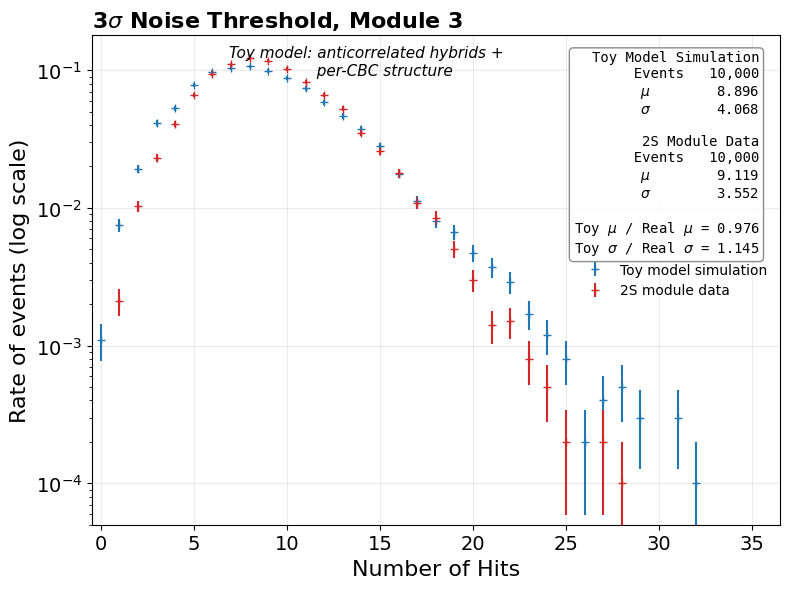

{'toy_mean': 8.8962, 'toy_std': 4.068418066030088, 'real_mean': 9.1191, 'real_std': 3.5521141859461673, 'ratio_mu': 0.9755567983682601, 'ratio_sigma': 1.145351149500391}


In [ ]:
# --- Toy model WITH common mode noise (fitted width) ---
hits_CM = simulate_module_hits_cbc_correlated(
    sigma_i, N_SIGMA, uncorr_std, cm_z_right, cm_z_left_indep, cm_eps_right, cm_eps_left,
    sigma_cm_right_best, sigma_cm_left_best, rho, rho_per_cbc_right, rho_per_cbc_left,
)
stats_CM = plot_toy_vs_data(
    hits_CM, real_bins, N_SIGMA, f"Module {OG_ID+1}", f"",
    f"Toy model: anticorrelated hybrids + \n                  per-CBC structure",
)
print(stats_CM)


In [ ]:
#si le CMN est purement gaussien, alors la valeur obtenue via la mesure à 50% d'occupancy et celle obtenue via l'occupancy à 3 sigmas devraient correspondre, en effet. Mais si l'effet est différent, tu peux avoir des surprises, et selon le cas c'est l'un ou l'autre qui sera le plus fiable.
#Par exemple, si tu as quelques strips particulièrement bruyantes qui déclenchent presque toujours, ça va shifter la distribution à 50%, pas l'élargir -> invisible dans le CMN à 50%. Par contre ça va augmenter la queue de distribution à 3 sigmas -> visible de ce côté là.

In [ ]:
# --- Summary table: toy-model CMN fit results across all 10 hybrids ---

In [ ]:
import pandas as pd

hybrid_specs = [
    ("OpticalGroup_0", "Hybrid_0", 0, "R"),
    ("OpticalGroup_1", "Hybrid_2", 2, "R"),
    ("OpticalGroup_2", "Hybrid_4", 4, "R"),
    ("OpticalGroup_3", "Hybrid_6", 6, "R"),
    ("OpticalGroup_4", "Hybrid_8", 8, "R"),
    ("OpticalGroup_0", "Hybrid_1", 1, "L"),
    ("OpticalGroup_1", "Hybrid_3", 3, "L"),
    ("OpticalGroup_2", "Hybrid_5", 5, "L"),
    ("OpticalGroup_3", "Hybrid_7", 7, "L"),
    ("OpticalGroup_4", "Hybrid_9", 9, "L"),
]

root_file_summary = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root", "READ")
N_SIGMA_SUMMARY = 3.0
N_TOY_SUMMARY = 10_000

# One rng, but drawn fresh INSIDE the loop -- each hybrid gets its own independent noise
# realization (still fully reproducible run-to-run, since the rng is seeded once up front).

rows = []
for og_name, hybrid_name, hybrid_id, side in hybrid_specs:
    sigma_i, real_bins = extract_hybrid_noise_and_hits(root_file_summary, og_name, hybrid_name, hybrid_id, N_SIGMA_SUMMARY)

    n_events_real = float(real_bins.sum())
    idx = np.arange(len(real_bins))
    real_mean = float(np.sum(idx * real_bins) / n_events_real)
    real_std = float(np.sqrt(np.sum(real_bins * (idx - real_mean) ** 2) / n_events_real))

    # rho_per_cbc: per-CBC correlation of "this chip" vs "whole hybrid" (measured from data, fixed
    # -- not a free fit parameter). 
    # WRONG Independent draws for this hybrid (common-random-numbers trick
    # still applies WITHIN this hybrid's own fit sweep, just not shared across hybrids anymore):
    # cm_factor is the shared hybrid-wide factor, cm_eps has one independent column per CBC.
    rho_per_cbc = get_cbc_hybrid_rhos(root_file_summary, og_name, hybrid_name, hybrid_id, N_SIGMA_SUMMARY)
    rng_summary = np.random.default_rng(2026)
    uncorr_std_summary = rng_summary.normal(0.0, 1.0, size=(N_TOY_SUMMARY, len(sigma_i)))
    cm_factor_summary = rng_summary.normal(0.0, 1.0, size=N_TOY_SUMMARY)
    cm_eps_summary = rng_summary.normal(0.0, 1.0, size=(N_TOY_SUMMARY, len(rho_per_cbc)))

    sigma_cm_best, scan, scan_obj = fit_common_mode_sigma_cbc_correlated(
        sigma_i, N_SIGMA_SUMMARY, real_bins, uncorr_std_summary, cm_factor_summary, cm_eps_summary, rho_per_cbc,
    )
    chi2_best = float(scan_obj.min())

    hits_cm = simulate_hybrid_hits_cbc_correlated(
        sigma_i, N_SIGMA_SUMMARY, uncorr_std_summary, cm_factor_summary, cm_eps_summary, sigma_cm_best, rho_per_cbc,
    )
    ratio_mu = hits_cm.mean() / real_mean
    ratio_sigma = max(hits_cm.std(), 1e-9) / real_std

    rows.append({
        "Hybrid": hybrid_id,
        "Side": side,
        "Real mean": real_mean,
        "Real σ": real_std,
        "σ_i (per-strip)": sigma_i.mean(),
        "σ_cm best": sigma_cm_best,
        "χ² best": chi2_best,
        "Toy μ/Real μ": ratio_mu,
        "Toy σ/Real σ": ratio_sigma,
    })
    print(f"Hybrid {hybrid_id} ({side}): sigma_cm={sigma_cm_best:.4f}, chi2={chi2_best:.1f}, "
          f"ratio_mu={ratio_mu:.3f}, ratio_sigma={ratio_sigma:.3f}")

df_summary = pd.DataFrame(rows)
df_summary_display = df_summary.round({
    "Real mean": 2, "Real σ": 2, "σ_i (per-strip)": 2, "σ_cm best": 2,
    "χ² best": 0, "Toy μ/Real μ": 2, "Toy σ/Real σ": 2,
})
df_summary_display["χ² best"] = df_summary_display["χ² best"].astype(int)
df_summary_display

Hybrid 0 (R): sigma_cm=1.9270, chi2=1188.4, ratio_mu=0.931, ratio_sigma=1.272
Hybrid 2 (R): sigma_cm=1.7820, chi2=223.5, ratio_mu=0.984, ratio_sigma=1.111
Hybrid 4 (R): sigma_cm=1.8968, chi2=678.6, ratio_mu=0.939, ratio_sigma=1.175
Hybrid 6 (R): sigma_cm=1.7569, chi2=315.8, ratio_mu=0.967, ratio_sigma=1.131
Hybrid 8 (R): sigma_cm=1.7814, chi2=299.1, ratio_mu=0.962, ratio_sigma=1.114
Hybrid 1 (L): sigma_cm=1.3780, chi2=1052.6, ratio_mu=1.131, ratio_sigma=0.907
Hybrid 3 (L): sigma_cm=1.3866, chi2=481.2, ratio_mu=1.061, ratio_sigma=0.914
Hybrid 5 (L): sigma_cm=1.4563, chi2=291.8, ratio_mu=1.055, ratio_sigma=0.955
Hybrid 7 (L): sigma_cm=1.5916, chi2=1430.0, ratio_mu=1.230, ratio_sigma=0.966
Hybrid 9 (L): sigma_cm=1.1592, chi2=799.4, ratio_mu=1.104, ratio_sigma=0.902


,Hybrid,Side,Real mean,Real σ,σ_i (per-strip),σ_cm best,χ² best,Toy μ/Real μ,Toy σ/Real σ
0,0,R,5.53,3.11,5.22,1.93,1188,0.93,1.27
1,2,R,4.70,3.10,5.34,1.78,223,0.98,1.11
2,4,R,5.37,3.35,5.19,1.90,679,0.94,1.17
3,6,R,4.78,3.05,5.27,1.76,316,0.97,1.13
4,8,R,4.81,3.13,5.35,1.78,299,0.96,1.11
5,1,L,3.34,2.98,5.43,1.38,1053,1.13,0.91
6,3,L,3.59,2.91,5.40,1.39,481,1.06,0.91
7,5,L,3.75,2.97,5.31,1.46,292,1.05,0.96
8,7,L,3.33,3.40,5.50,1.59,1430,1.23,0.97
9,9,L,3.15,2.57,5.33,1.16,799,1.10,0.90


In [ ]:
# --- Summary table: toy-model CMN fit results across all 5 modules (NOT INCLUDING CBC CORR)---
# TABLE NOT IN THESIS

### Module-level fit: resolved by reusing the hybrid-level per-CBC correlation structure

The earlier version of this note reported that giving each hybrid its own width
($\sigma_{cm,R}$, $\sigma_{cm,L}$, combined through the real cross-hybrid $\rho$) only
marginally improved the fit (2-5% better chi-square), with variance still overshooting by
20-60%. That test used `simulate_module_hits_two_width`, which -- like the original
`simulate_module_hits` -- applies one undiminished common-mode value to every strip of a given
hybrid, implicitly assuming the 8 CBCs of that hybrid are **perfectly correlated** with each
other ($\rho=1$). They are not: the hybrid-level fits already measure $\rho_{per\_cbc}\approx$
0.3-0.56 for each hybrid's own 8 CBCs.

`simulate_module_hits_cbc_correlated` fixes this by reusing that same per-CBC structure inside
the module model: each side's own 8 CBCs get their own common-mode value built from that side's
hybrid-wide factor plus CBC-specific noise (weighted by that hybrid's measured
$\rho_{per\_cbc}$), and the two hybrid-wide factors are still combined via the real cross-hybrid
$\rho$ exactly as before. This closes most of the gap: chi-square dropped 5-15x across all 5
modules (e.g. Module 4: 960.9 $\to$ 65.2), and ratio $\sigma$ improved from 1.17-1.63 down to
1.00-1.17, with ratio $\mu$ essentially exact (0.975-0.990) for every module.

So the earlier "inherited from the hybrid-level Gaussian assumption" conclusion was not quite
right -- most of the module-level ceiling was actually an inconsistency between the two models
(hybrid level modeling *partial* intra-hybrid correlation, module level implicitly assuming
*perfect* intra-hybrid correlation), not a fundamental limit of the single-Gaussian-CM
assumption itself. A small residual gap remains (ratio $\sigma$ still 1.00-1.17, not exactly 1),
consistent with the genuine hybrid-level moment tension already documented (R-side ratio $\sigma$
= 1.11-1.27 even in each hybrid's own standalone fit) -- that part of the ceiling is real and
still present, just much smaller than it first appeared.

In [ ]:
import pandas as pd

module_specs = [
    ("OpticalGroup_0", 0),
    ("OpticalGroup_1", 1),
    ("OpticalGroup_2", 2),
    ("OpticalGroup_3", 3),
    ("OpticalGroup_4", 4),
]

root_file_summary = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root", "READ")
N_SIGMA_SUMMARY = 3.0
N_TOY_SUMMARY = 10_000

# Independent draw for this module (common-random-numbers trick still applies WITHIN this
# module's own fit sweep, just not shared across modules anymore).

rows = []
for og_name, og_id in module_specs:
    sigma_i, real_bins = extract_module_noise_and_hits(root_file_summary, og_name, og_id, N_SIGMA_SUMMARY)
    hybrid_r_id, hybrid_l_id = 2 * og_id, 2 * og_id + 1
    hybrid_r_name, hybrid_l_name = f"Hybrid_{hybrid_r_id}", f"Hybrid_{hybrid_l_id}"

    n_events_real = float(real_bins.sum())
    idx = np.arange(len(real_bins))
    real_mean = float(np.sum(idx * real_bins) / n_events_real)
    real_std = float(np.sqrt(np.sum(real_bins * (idx - real_mean) ** 2) / n_events_real))

    rho = get_cross_hybrid_rho(root_file_summary, og_name, og_id)
    rho_per_cbc_right = get_cbc_hybrid_rhos(root_file_summary, og_name, hybrid_r_name, hybrid_r_id, N_SIGMA_SUMMARY)
    rho_per_cbc_left = get_cbc_hybrid_rhos(root_file_summary, og_name, hybrid_l_name, hybrid_l_id, N_SIGMA_SUMMARY)
    rng_summary = np.random.default_rng(2026)
    uncorr_std_summary = rng_summary.normal(0.0, 1.0, size=(N_TOY_SUMMARY, len(sigma_i)))
    cm_z_right = rng_summary.normal(0.0, 1.0, size=N_TOY_SUMMARY)
    cm_z_left_indep = rng_summary.normal(0.0, 1.0, size=N_TOY_SUMMARY)
    cm_eps_right = rng_summary.normal(0.0, 1.0, size=(N_TOY_SUMMARY, len(rho_per_cbc_right)))
    cm_eps_left = rng_summary.normal(0.0, 1.0, size=(N_TOY_SUMMARY, len(rho_per_cbc_left)))

    sigma_cm_right_best, sigma_cm_left_best, scan, scan_obj = fit_common_mode_sigma_module_cbc_correlated(
        sigma_i, N_SIGMA_SUMMARY, real_bins, uncorr_std_summary, cm_z_right, cm_z_left_indep,
        cm_eps_right, cm_eps_left, rho, rho_per_cbc_right, rho_per_cbc_left,
    )
    chi2_best = float(scan_obj.min())

    hits_cm = simulate_module_hits_cbc_correlated(
        sigma_i, N_SIGMA_SUMMARY, uncorr_std_summary, cm_z_right, cm_z_left_indep, cm_eps_right, cm_eps_left,
        sigma_cm_right_best, sigma_cm_left_best, rho, rho_per_cbc_right, rho_per_cbc_left,
    )
    ratio_mu = hits_cm.mean() / real_mean
    ratio_sigma = max(hits_cm.std(), 1e-9) / real_std

    # Single effective module-level CM sigma: the combined scale of the two correlated hybrid-wide
    # factors, sqrt(sc_R^2 + sc_L^2 + 2*rho*sc_R*sc_L) -- not a simple average, since strong
    # anti-correlation (rho close to -1) cancels fluctuations and should genuinely reduce the
    # combined number, while a bigger R/L mismatch leaves less cancellation and keeps it larger.
    sigma_cm_module = float(np.sqrt(max(
        sigma_cm_right_best ** 2 + sigma_cm_left_best ** 2
        + 2 * rho * sigma_cm_right_best * sigma_cm_left_best, 0.0)))

    rows.append({
        "Module": og_id + 1,
        "Real mean": real_mean,
        "Real σ": real_std,
        "σ_i (per-strip)": sigma_i.mean(),
        "σ_cm R": sigma_cm_right_best,
        "σ_cm L": sigma_cm_left_best,
        "σ_cm module": sigma_cm_module,
        "χ² best": chi2_best,
        "Toy μ/Real μ": ratio_mu,
        "Toy σ/Real σ": ratio_sigma,
    })
    print(f"Module {og_id + 1} : sigma_cm_R={sigma_cm_right_best:.4f}, sigma_cm_L={sigma_cm_left_best:.4f}, "
          f"sigma_cm_module={sigma_cm_module:.4f}, chi2={chi2_best:.1f}, ratio_mu={ratio_mu:.3f}, "
          f"ratio_sigma={ratio_sigma:.3f}")

df_summary = pd.DataFrame(rows)
df_summary_display = df_summary.round({
    "Real mean": 2, "Real σ": 2, "σ_i (per-strip)": 2, "σ_cm R": 2, "σ_cm L": 2, "σ_cm module": 2,
    "χ² best": 0, "Toy μ/Real μ": 2, "Toy σ/Real σ": 2,
})
df_summary_display["χ² best"] = df_summary_display["χ² best"].astype(int)
df_summary_display


Module 1 : sigma_cm_R=1.6879, sigma_cm_L=1.6525, sigma_cm_module=1.5150, chi2=605.1, ratio_mu=0.975, ratio_sigma=1.168
Module 2 : sigma_cm_R=1.5657, sigma_cm_L=1.5351, sigma_cm_module=0.7635, chi2=364.9, ratio_mu=0.978, ratio_sigma=1.102
Module 3 : sigma_cm_R=1.6858, sigma_cm_L=1.7360, sigma_cm_module=1.0670, chi2=437.7, ratio_mu=0.976, ratio_sigma=1.145
Module 4 : sigma_cm_R=1.8386, sigma_cm_L=1.0465, sigma_cm_module=1.5086, chi2=68.6, ratio_mu=0.990, ratio_sigma=1.000
Module 5 : sigma_cm_R=1.5039, sigma_cm_L=1.4261, sigma_cm_module=0.5577, chi2=254.4, ratio_mu=0.984, ratio_sigma=1.075


,Module,Real mean,Real σ,σ_i (per-strip),σ_cm R,σ_cm L,σ_cm module,χ² best,Toy μ/Real μ,Toy σ/Real σ
0,1,8.87,3.47,5.33,1.69,1.65,1.51,605,0.97,1.17
1,2,8.29,3.23,5.37,1.57,1.54,0.76,365,0.98,1.10
2,3,9.12,3.55,5.25,1.69,1.74,1.07,438,0.98,1.15
3,4,8.11,3.88,5.39,1.84,1.05,1.51,69,0.99,1.00
4,5,7.96,3.15,5.34,1.50,1.43,0.56,254,0.98,1.07


In [ ]:
# Treat the module's total common-mode contribution as the combined scale of the two correlated hybrid-wide factors,
# $$\sigma_{cm,\text{module}} = \sqrt{\sigma_{cm,R}^2 + \sigma_{cm,L}^2 + 2\rho,\sigma_{cm,R},\sigma_{cm,L}}$$
# This isn't just "average the two", it correctly reflects that strong anti-correlation cancels fluctuations.
# Module 5 has the strongest anti-correlation (ρ=-0.929) and fairly similar R/L amplitudes, so most of the noise cancels, giving the smallest module-level number (0.557) despite R and L individually being comparable to Module 1's. Module 4 has weaker anti-correlation but the biggest R/L mismatch (1.84 vs 1.05), so less cancellation happens and the combined number stays large (1.508) even though its L-side amplitude alone is the smallest of any hybrid. That's real physics being captured, not an artifact — a module where the two hybrids' noise doesn't cancel well genuinely has more net common-mode noise, even if neither side alone looks the noisiest.

In [ ]:
# 2S's residual imperfection (mostly on R hybrids) has a completely different signature than PS's: it's a mean-undershoot/std-overshoot trade-off (or the mirror pattern on L), not a bin-0/effective-threshold mismatch.
# That's consistent with the mechanism cell 99 describes (a single symmetric Gaussian CM term can't always hit both moments at once) — a different, smaller-magnitude problem than PS's, and not one k_thresh would fix, since the baseline threshold itself isn't the issue here

In [ ]:
# --- Table :Toy-to-data mean and standard-deviation ratios at the best-fit σcm, compared between the naive fully-correlated model and the measured-ρper-CBC model

In [ ]:
import pandas as pd

hybrid_specs = [
    ("OpticalGroup_0", "Hybrid_0", 0, "R"),
    ("OpticalGroup_1", "Hybrid_2", 2, "R"),
    ("OpticalGroup_2", "Hybrid_4", 4, "R"),
    ("OpticalGroup_3", "Hybrid_6", 6, "R"),
    ("OpticalGroup_4", "Hybrid_8", 8, "R"),
    ("OpticalGroup_0", "Hybrid_1", 1, "L"),
    ("OpticalGroup_1", "Hybrid_3", 3, "L"),
    ("OpticalGroup_2", "Hybrid_5", 5, "L"),
    ("OpticalGroup_3", "Hybrid_7", 7, "L"),
    ("OpticalGroup_4", "Hybrid_9", 9, "L"),
]

root_file_compare = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root", "READ")
N_SIGMA_COMPARE = 3.0
N_TOY_COMPARE = 10_000

rows = []
for og_name, hybrid_name, hybrid_id, side in hybrid_specs:
    sigma_i, real_bins = extract_hybrid_noise_and_hits(root_file_compare, og_name, hybrid_name, hybrid_id, N_SIGMA_COMPARE)
    rho_per_cbc = get_cbc_hybrid_rhos(root_file_compare, og_name, hybrid_name, hybrid_id, N_SIGMA_COMPARE)

    n_events_real = float(real_bins.sum())
    idx = np.arange(len(real_bins))
    real_mean = float(np.sum(idx * real_bins) / n_events_real)
    real_std = float(np.sqrt(np.sum(real_bins * (idx - real_mean) ** 2) / n_events_real))

    # Fresh rng(2026) INSIDE the loop, matching the existing per-hybrid table exactly:
    # this reproduces those already-published sigma_cm/chi2/ratio values identically.
    rng_corr = np.random.default_rng(2026)
    uncorr_std_corr = rng_corr.normal(0.0, 1.0, size=(N_TOY_COMPARE, len(sigma_i)))
    cm_factor = rng_corr.normal(0.0, 1.0, size=N_TOY_COMPARE)
    cm_eps = rng_corr.normal(0.0, 1.0, size=(N_TOY_COMPARE, len(rho_per_cbc)))

    sigma_cm_corr, _, obj_corr = fit_common_mode_sigma_cbc_correlated(
        sigma_i, N_SIGMA_COMPARE, real_bins, uncorr_std_corr, cm_factor, cm_eps, rho_per_cbc,
    )
    hits_corr = simulate_hybrid_hits_cbc_correlated(sigma_i, N_SIGMA_COMPARE, uncorr_std_corr, cm_factor, cm_eps, sigma_cm_corr, rho_per_cbc)
    chi2_corr = float(obj_corr.min())
    ratio_mu_corr = hits_corr.mean() / real_mean
    ratio_sigma_corr = max(hits_corr.std(), 1e-9) / real_std

    # Naive model: same fresh-seed-per-hybrid convention, kept in a separate rng object so it
    # doesn't consume from the same stream as the corr model above.
    rng_naive = np.random.default_rng(2026)
    uncorr_std_naive = rng_naive.normal(0.0, 1.0, size=(N_TOY_COMPARE, len(sigma_i)))
    cm_base = rng_naive.normal(0.0, 1.0, size=N_TOY_COMPARE)

    sigma_cm_naive, _, obj_naive = fit_common_mode_sigma(sigma_i, N_SIGMA_COMPARE, real_bins, uncorr_std_naive, cm_base)
    hits_naive = simulate_hits(sigma_i, N_SIGMA_COMPARE, uncorr_std_naive, cm_base, sigma_cm_naive)
    chi2_naive = float(obj_naive.min())
    ratio_mu_naive = hits_naive.mean() / real_mean
    ratio_sigma_naive = max(hits_naive.std(), 1e-9) / real_std

    rows.append({
        "Hybrid": hybrid_id, "Side": side,
        "Naive σ_cm": sigma_cm_naive, "Naive χ²": chi2_naive,
        "Naive Toy μ/Real μ": ratio_mu_naive, "Naive Toy σ/Real σ": ratio_sigma_naive,
        "Corr σ_cm": sigma_cm_corr, "Corr χ²": chi2_corr,
        "Corr Toy μ/Real μ": ratio_mu_corr, "Corr Toy σ/Real σ": ratio_sigma_corr,
    })

df_compare = pd.DataFrame(rows).sort_values(["Side", "Hybrid"], ascending=[False, True]).reset_index(drop=True)
df_compare_display = df_compare.round({
    "Naive σ_cm": 3, "Naive χ²": 0, "Naive Toy μ/Real μ": 3, "Naive Toy σ/Real σ": 3,
    "Corr σ_cm": 3, "Corr χ²": 0, "Corr Toy μ/Real μ": 3, "Corr Toy σ/Real σ": 3,
})
df_compare_display["Naive χ²"] = df_compare_display["Naive χ²"].astype(int)
df_compare_display["Corr χ²"] = df_compare_display["Corr χ²"].astype(int)
df_compare_display


KeyboardInterrupt: 

In [ ]:
# --- Table: mean per-CBC-to-hybrid correlation (rho), R hybrids vs L hybrids ---

In [ ]:
import pandas as pd
from IPython.display import display

hybrid_specs = [
    ("OpticalGroup_0", "Hybrid_0", 0, "R"),
    ("OpticalGroup_1", "Hybrid_2", 2, "R"),
    ("OpticalGroup_2", "Hybrid_4", 4, "R"),
    ("OpticalGroup_3", "Hybrid_6", 6, "R"),
    ("OpticalGroup_4", "Hybrid_8", 8, "R"),
    ("OpticalGroup_0", "Hybrid_1", 1, "L"),
    ("OpticalGroup_1", "Hybrid_3", 3, "L"),
    ("OpticalGroup_2", "Hybrid_5", 5, "L"),
    ("OpticalGroup_3", "Hybrid_7", 7, "L"),
    ("OpticalGroup_4", "Hybrid_9", 9, "L"),
]

root_file_rho = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root", "READ")
N_SIGMA_RHO = 3.0

mean_rho_by_hybrid = {}
for og_name, hybrid_name, hybrid_id, side in hybrid_specs:
    rho = get_cbc_hybrid_rhos(root_file_rho, og_name, hybrid_name, hybrid_id, N_SIGMA_RHO)
    mean_rho_by_hybrid[hybrid_id] = (side, float(rho.mean()))

r_hybrids = [hid for hid, (side, _) in mean_rho_by_hybrid.items() if side == "R"]
l_hybrids = [hid for hid, (side, _) in mean_rho_by_hybrid.items() if side == "L"]

df_r = pd.DataFrame([{f"Hybrid {h}": mean_rho_by_hybrid[h][1] for h in r_hybrids}], index=["mean ρ"])
df_r["mean (R)"] = df_r.mean(axis=1)

df_l = pd.DataFrame([{f"Hybrid {h}": mean_rho_by_hybrid[h][1] for h in l_hybrids}], index=["mean ρ"])
df_l["mean (L)"] = df_l.mean(axis=1)

display(df_r.round(3))
display(df_l.round(3))


,Hybrid 0,Hybrid 2,Hybrid 4,Hybrid 6,Hybrid 8,mean (R)
mean ρ,0.351,0.377,0.385,0.377,0.394,0.377


,Hybrid 1,Hybrid 3,Hybrid 5,Hybrid 7,Hybrid 9,mean (L)
mean ρ,0.475,0.425,0.44,0.561,0.411,0.463


In [ ]:
import pandas as pd

hybrid_specs = [
    ("OpticalGroup_0", "Hybrid_0", 0, "R"),
    ("OpticalGroup_1", "Hybrid_2", 2, "R"),
    ("OpticalGroup_2", "Hybrid_4", 4, "R"),
    ("OpticalGroup_3", "Hybrid_6", 6, "R"),
    ("OpticalGroup_4", "Hybrid_8", 8, "R"),
    ("OpticalGroup_0", "Hybrid_1", 1, "L"),
    ("OpticalGroup_1", "Hybrid_3", 3, "L"),
    ("OpticalGroup_2", "Hybrid_5", 5, "L"),
    ("OpticalGroup_3", "Hybrid_7", 7, "L"),
    ("OpticalGroup_4", "Hybrid_9", 9, "L"),
]

root_file_compare = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root", "READ")
N_SIGMA_COMPARE = 3.0
N_TOY_COMPARE = 10_000

rows = []
for og_name, hybrid_name, hybrid_id, side in hybrid_specs:
    sigma_i, real_bins = extract_hybrid_noise_and_hits(root_file_compare, og_name, hybrid_name, hybrid_id, N_SIGMA_COMPARE)
    rho_per_cbc = get_cbc_hybrid_rhos(root_file_compare, og_name, hybrid_name, hybrid_id, N_SIGMA_COMPARE)

    n_events_real = float(real_bins.sum())
    idx = np.arange(len(real_bins))
    real_mean = float(np.sum(idx * real_bins) / n_events_real)
    real_std = float(np.sqrt(np.sum(real_bins * (idx - real_mean) ** 2) / n_events_real))

    # Fresh rng(2026) INSIDE the loop, matching the convention already used for the CBC-correlated
    # model elsewhere in this notebook, so its results reproduce identically here.
    rng_corr = np.random.default_rng(2026)
    uncorr_std_corr = rng_corr.normal(0.0, 1.0, size=(N_TOY_COMPARE, len(sigma_i)))
    cm_factor = rng_corr.normal(0.0, 1.0, size=N_TOY_COMPARE)
    cm_eps = rng_corr.normal(0.0, 1.0, size=(N_TOY_COMPARE, len(rho_per_cbc)))

    sigma_cm_corr, _, obj_corr = fit_common_mode_sigma_cbc_correlated(
        sigma_i, N_SIGMA_COMPARE, real_bins, uncorr_std_corr, cm_factor, cm_eps, rho_per_cbc,
    )
    hits_corr = simulate_hybrid_hits_cbc_correlated(sigma_i, N_SIGMA_COMPARE, uncorr_std_corr, cm_factor, cm_eps, sigma_cm_corr, rho_per_cbc)
    chi2_corr = float(obj_corr.min())
    ratio_mu_corr = hits_corr.mean() / real_mean
    ratio_sigma_corr = max(hits_corr.std(), 1e-9) / real_std

    # Naive model: all 8 CBCs treated as fully correlated (rho = 1). Separate rng object, so it
    # doesn't disturb the corr model's draw sequence above.
    rng_naive = np.random.default_rng(2026)
    uncorr_std_naive = rng_naive.normal(0.0, 1.0, size=(N_TOY_COMPARE, len(sigma_i)))
    cm_base = rng_naive.normal(0.0, 1.0, size=N_TOY_COMPARE)

    sigma_cm_naive, _, obj_naive = fit_common_mode_sigma(sigma_i, N_SIGMA_COMPARE, real_bins, uncorr_std_naive, cm_base)
    hits_naive = simulate_hits(sigma_i, N_SIGMA_COMPARE, uncorr_std_naive, cm_base, sigma_cm_naive)
    chi2_naive = float(obj_naive.min())
    ratio_mu_naive = hits_naive.mean() / real_mean
    ratio_sigma_naive = max(hits_naive.std(), 1e-9) / real_std

    rows.append({
        "Hybrid": hybrid_id, "Side": side,
        "Naive σ_cm": sigma_cm_naive, "Naive χ²": chi2_naive,
        "Naive Toy μ/Real μ": ratio_mu_naive, "Naive Toy σ/Real σ": ratio_sigma_naive,
        "Corr σ_cm": sigma_cm_corr, "Corr χ²": chi2_corr,
        "Corr Toy μ/Real μ": ratio_mu_corr, "Corr Toy σ/Real σ": ratio_sigma_corr,
    })
    print(f"Hybrid {hybrid_id} ({side}): naive chi2={chi2_naive:.1f} (mu={ratio_mu_naive:.3f}, sigma={ratio_sigma_naive:.3f})  "
          f"corr chi2={chi2_corr:.1f} (mu={ratio_mu_corr:.3f}, sigma={ratio_sigma_corr:.3f})")

df_compare = pd.DataFrame(rows).sort_values(["Side", "Hybrid"], ascending=[False, True]).reset_index(drop=True)
df_compare_display = df_compare.round({
    "Naive σ_cm": 3, "Naive χ²": 0, "Naive Toy μ/Real μ": 3, "Naive Toy σ/Real σ": 3,
    "Corr σ_cm": 3, "Corr χ²": 0, "Corr Toy μ/Real μ": 3, "Corr Toy σ/Real σ": 3,
})
df_compare_display["Naive χ²"] = df_compare_display["Naive χ²"].astype(int)
df_compare_display["Corr χ²"] = df_compare_display["Corr χ²"].astype(int)
df_compare_display


Hybrid 0 (R): naive chi2=6304.6 (mu=0.698, sigma=1.364)  corr chi2=1188.4 (mu=0.931, sigma=1.272)
Hybrid 2 (R): naive chi2=2717.9 (mu=0.767, sigma=1.159)  corr chi2=223.5 (mu=0.984, sigma=1.111)
Hybrid 4 (R): naive chi2=4681.6 (mu=0.708, sigma=1.215)  corr chi2=678.6 (mu=0.939, sigma=1.175)
Hybrid 6 (R): naive chi2=3165.7 (mu=0.746, sigma=1.149)  corr chi2=315.8 (mu=0.967, sigma=1.131)
Hybrid 8 (R): naive chi2=3034.2 (mu=0.747, sigma=1.145)  corr chi2=299.1 (mu=0.962, sigma=1.114)
Hybrid 1 (L): naive chi2=287.0 (mu=0.993, sigma=0.981)  corr chi2=1052.6 (mu=1.131, sigma=0.907)
Hybrid 3 (L): naive chi2=306.6 (mu=0.917, sigma=0.989)  corr chi2=481.2 (mu=1.061, sigma=0.914)
Hybrid 5 (L): naive chi2=526.4 (mu=0.885, sigma=0.986)  corr chi2=291.8 (mu=1.055, sigma=0.955)
Hybrid 7 (L): naive chi2=470.7 (mu=1.026, sigma=0.930)  corr chi2=1430.0 (mu=1.230, sigma=0.966)
Hybrid 9 (L): naive chi2=45.8 (mu=1.011, sigma=1.022)  corr chi2=799.4 (mu=1.104, sigma=0.902)


,Hybrid,Side,Naive σ_cm,Naive χ²,Naive Toy μ/Real μ,Naive Toy σ/Real σ,Corr σ_cm,Corr χ²,Corr Toy μ/Real μ,Corr Toy σ/Real σ
0,0,R,1.381,6305,0.698,1.364,1.927,1188,0.931,1.272
1,2,R,1.257,2718,0.767,1.159,1.782,223,0.984,1.111
2,4,R,1.349,4682,0.708,1.215,1.897,679,0.939,1.175
3,6,R,1.214,3166,0.746,1.149,1.757,316,0.967,1.131
4,8,R,1.252,3034,0.747,1.145,1.781,299,0.962,1.114
5,1,L,1.057,287,0.993,0.981,1.378,1053,1.131,0.907
6,3,L,1.035,307,0.917,0.989,1.387,481,1.061,0.914
7,5,L,1.038,526,0.885,0.986,1.456,292,1.055,0.955
8,7,L,1.160,471,1.026,0.930,1.592,1430,1.230,0.966
9,9,L,0.921,46,1.011,1.022,1.159,799,1.104,0.902


In [ ]:
# --- Summary table: toy-model CMN fit results across all 5 modules (INCLUDING CBC CORR)---

In [ ]:
import pandas as pd

def coherence_factors(rho_per_cbc_right, rho_per_cbc_left):
    """Coherence factors that correct the module-level combination for the fact that a side's
    8 CBCs are only PARTIALLY correlated with their own hybrid (rho_per_cbc < 1), not perfectly
    locked together (rho_per_cbc = 1, the assumption implicit in a naive combination).

    Derivation: summing a side's 8 per-CBC unit-variance factors c_i = rho_i*X + sqrt(1-rho_i^2)*eps_i
    gives Var(sum) = (sum rho_i)^2 + sum(1 - rho_i^2), NOT n_cbc^2 (what you'd get if every
    rho_i = 1). Dividing by n_cbc^2 keeps the correction on the same per-CBC scale as sigma_cm
    itself. The cross term between R and L picks up a similar reduction, scaled by the product
    of both sides' rho_i sums instead of their squares.
    """
    n_cbc_r = len(rho_per_cbc_right)
    n_cbc_l = len(rho_per_cbc_left)
    sum_r, sum_l = rho_per_cbc_right.sum(), rho_per_cbc_left.sum()

    kappa_r = (sum_r ** 2 + np.sum(1.0 - rho_per_cbc_right ** 2)) / n_cbc_r ** 2
    kappa_l = (sum_l ** 2 + np.sum(1.0 - rho_per_cbc_left ** 2)) / n_cbc_l ** 2
    kappa_cross = (sum_r * sum_l) / (n_cbc_r * n_cbc_l)
    return kappa_r, kappa_l, kappa_cross


module_specs = [
    ("OpticalGroup_0", 0),
    ("OpticalGroup_1", 1),
    ("OpticalGroup_2", 2),
    ("OpticalGroup_3", 3),
    ("OpticalGroup_4", 4),
]

root_file_summary = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_12.root", "READ")
N_SIGMA_SUMMARY = 3.0
N_TOY_SUMMARY = 10_000

rows = []
for og_name, og_id in module_specs:
    sigma_i, real_bins = extract_module_noise_and_hits(root_file_summary, og_name, og_id, N_SIGMA_SUMMARY)
    hybrid_r_id, hybrid_l_id = 2 * og_id, 2 * og_id + 1
    hybrid_r_name, hybrid_l_name = f"Hybrid_{hybrid_r_id}", f"Hybrid_{hybrid_l_id}"

    n_events_real = float(real_bins.sum())
    idx = np.arange(len(real_bins))
    real_mean = float(np.sum(idx * real_bins) / n_events_real)
    real_std = float(np.sqrt(np.sum(real_bins * (idx - real_mean) ** 2) / n_events_real))

    rho = get_cross_hybrid_rho(root_file_summary, og_name, og_id)
    rho_per_cbc_right = get_cbc_hybrid_rhos(root_file_summary, og_name, hybrid_r_name, hybrid_r_id, N_SIGMA_SUMMARY)
    rho_per_cbc_left = get_cbc_hybrid_rhos(root_file_summary, og_name, hybrid_l_name, hybrid_l_id, N_SIGMA_SUMMARY)
    rng_summary = np.random.default_rng(2026)
    uncorr_std_summary = rng_summary.normal(0.0, 1.0, size=(N_TOY_SUMMARY, len(sigma_i)))
    cm_z_right = rng_summary.normal(0.0, 1.0, size=N_TOY_SUMMARY)
    cm_z_left_indep = rng_summary.normal(0.0, 1.0, size=N_TOY_SUMMARY)
    cm_eps_right = rng_summary.normal(0.0, 1.0, size=(N_TOY_SUMMARY, len(rho_per_cbc_right)))
    cm_eps_left = rng_summary.normal(0.0, 1.0, size=(N_TOY_SUMMARY, len(rho_per_cbc_left)))

    sigma_cm_right_best, sigma_cm_left_best, scan, scan_obj = fit_common_mode_sigma_module_cbc_correlated(
        sigma_i, N_SIGMA_SUMMARY, real_bins, uncorr_std_summary, cm_z_right, cm_z_left_indep,
        cm_eps_right, cm_eps_left, rho, rho_per_cbc_right, rho_per_cbc_left,
    )
    chi2_best = float(scan_obj.min())

    hits_cm = simulate_module_hits_cbc_correlated(
        sigma_i, N_SIGMA_SUMMARY, uncorr_std_summary, cm_z_right, cm_z_left_indep, cm_eps_right, cm_eps_left,
        sigma_cm_right_best, sigma_cm_left_best, rho, rho_per_cbc_right, rho_per_cbc_left,
    )
    ratio_mu = hits_cm.mean() / real_mean
    ratio_sigma = max(hits_cm.std(), 1e-9) / real_std

    # Module-level CM sigma, corrected for the real per-CBC coherence on each side (rho_per_cbc
    # < 1), instead of implicitly assuming each side's 8 CBCs move in perfect lockstep.
    kappa_r, kappa_l, kappa_cross = coherence_factors(rho_per_cbc_right, rho_per_cbc_left)
    sigma_cm_module = float(np.sqrt(max(
        sigma_cm_right_best ** 2 * kappa_r + sigma_cm_left_best ** 2 * kappa_l
        + 2 * rho * kappa_cross * sigma_cm_right_best * sigma_cm_left_best, 0.0)))

    rows.append({
        "Module": og_id + 1,
        "Real mean": real_mean,
        "Real σ": real_std,
        "σ_i (per-strip)": sigma_i.mean(),
        "σ_cm R": sigma_cm_right_best,
        "σ_cm L": sigma_cm_left_best,
        "σ_cm module": sigma_cm_module,
        "χ² best": chi2_best,
        "Toy μ/Real μ": ratio_mu,
        "Toy σ/Real σ": ratio_sigma,
    })
    print(f"Module {og_id + 1} : sigma_cm_R={sigma_cm_right_best:.4f}, sigma_cm_L={sigma_cm_left_best:.4f}, "
          f"sigma_cm_module={sigma_cm_module:.4f}, chi2={chi2_best:.1f}, ratio_mu={ratio_mu:.3f}, "
          f"ratio_sigma={ratio_sigma:.3f}")

df_summary = pd.DataFrame(rows)
df_summary_display = df_summary.round({
    "Real mean": 2, "Real σ": 2, "σ_i (per-strip)": 2, "σ_cm R": 2, "σ_cm L": 2, "σ_cm module": 2,
    "χ² best": 0, "Toy μ/Real μ": 2, "Toy σ/Real σ": 2,
})
df_summary_display["χ² best"] = df_summary_display["χ² best"].astype(int)
df_summary_display


Module 1 : sigma_cm_R=1.6879, sigma_cm_L=1.6525, sigma_cm_module=0.9974, chi2=605.1, ratio_mu=0.975, ratio_sigma=1.168
Module 2 : sigma_cm_R=1.5657, sigma_cm_L=1.5351, sigma_cm_module=0.7745, chi2=364.9, ratio_mu=0.978, ratio_sigma=1.102
Module 3 : sigma_cm_R=1.6858, sigma_cm_L=1.7360, sigma_cm_module=0.9003, chi2=437.7, ratio_mu=0.976, ratio_sigma=1.145
Module 4 : sigma_cm_R=1.8386, sigma_cm_L=1.0465, sigma_cm_module=0.9025, chi2=68.6, ratio_mu=0.990, ratio_sigma=1.000
Module 5 : sigma_cm_R=1.5039, sigma_cm_L=1.4261, sigma_cm_module=0.7055, chi2=254.4, ratio_mu=0.984, ratio_sigma=1.075


,Module,Real mean,Real σ,σ_i (per-strip),σ_cm R,σ_cm L,σ_cm module,χ² best,Toy μ/Real μ,Toy σ/Real σ
0,1,8.87,3.47,5.33,1.69,1.65,1.00,605,0.97,1.17
1,2,8.29,3.23,5.37,1.57,1.54,0.77,365,0.98,1.10
2,3,9.12,3.55,5.25,1.69,1.74,0.90,438,0.98,1.15
3,4,8.11,3.88,5.39,1.84,1.05,0.90,69,0.99,1.00
4,5,7.96,3.15,5.34,1.50,1.43,0.71,254,0.98,1.07
